<a id="h001"></a>
# Formula 1 Podium Prediction — Part 1: Data cleaning & auditing (brief objective 1)

**Goal of this part:** turn the raw Kaggle F1 CSVs into trustworthy, correctly typed tables in which `(raceId, driverId)` identifies exactly one row, so that every row can later be one prediction: *"will this driver finish on the podium (positionOrder <= 3) in this race?"*

**Rules we follow:** raw tables are never modified (all cleaning happens on `cleaned_tables`, a dictionary of copies); every decision is backed by code and a plot, not by manual inspection.

**Structure**
1. Initial EDA on the raw data (structure, missing values, target, grid, qualifying)
2. Cleaning: sentinels, semantic typing (numbers, dates, times, durations)
3. One row per driver per race: duplicate detection, rule, audit and sensitivity
4. Integrity: primary keys, foreign keys, domain checks
5. EDA after cleaning: measuring the impact of the cleaning
6. Summary, export, and open decisions

**Reading the notebook:** it runs from top to bottom. Each step states what it does, why, and what its output shows.

<a id="toc"></a>
## Table of Contents

The outline lists every heading in the notebook by level. Entries that introduce a code cell give its number and what it returns.

- [Formula 1 Podium Prediction — Part 1: Data cleaning & auditing (brief objective 1)](#h001)
  - [Contents of this notebook (milestone map)](#h900)
  - [0. Setup and data loading](#h002)
    - [Step 0.1: Kaggle environment template](#h003) (code cell 1: no output)
    - [Step 0.2: Imports and display options](#h004) (code cell 2: no output)
    - [Step 0.3: Locate the 14 source files](#h005) (code cell 3: text output)
    - [Step 0.4: Load every table as a raw DataFrame](#h006) (code cell 4: no output)
    - [Step 0.5: Dataset overview (rows x columns per table)](#h007) (code cell 5: 1 table)
  - [1. Initial EDA on the raw data](#h008)
    - [Step 1.1: Preview of the core tables](#h009) (code cell 6: text output)
    - [Step 1.1b: Data types before cleaning (baseline for semantic typing)](#h010) (code cell 7: text output)
    - [Step 1.2: Sentinel audit: where does \N appear?](#h011) (code cell 8: 1 table)
    - [Step 1.2b: What did read_csv already convert before we looked?](#h012) (code cell 9: 1 table, text output)
    - [Step 1.2c: Missing values in results, the table that defines the target](#h013) (code cell 10: 1 table)
    - [Step 1.2d: Visualisation of the missing values in results](#h014) (code cell 11: 1 figure)
    - [Step 1.2e: The three position columns, positionText letter codes and disqualifications](#h401) (code cell 12: 1 table, text output)
    - [Step 1.3: Summary statistics of results](#h015) (code cell 13: 1 table)
    - [Step 1.3a: Define the target and measure class balance (raw data)](#h016) (code cell 14: 1 table)
    - [Step 1.3b: Temporary EDA copy with the target flag](#h017) (code cell 15: no output)
    - [Step 1.3c: Plot: podium vs. non-podium counts](#h018) (code cell 16: 1 figure)
    - [Step 1.3d: Season coverage: races and circuits per season](#h019) (code cell 17: 1 table)
    - [Step 1.3e: Plot: number of Grands Prix per season](#h020) (code cell 18: 1 figure)
    - [Step 1.4: Starting-grid statistics](#h021) (code cell 19: no output)
    - [Step 1.4a: Histogram of grid positions](#h022) (code cell 20: 1 figure)
    - [Step 1.4b: How many rows have grid = 0?](#h023) (code cell 21: text output)
    - [Step 1.4c: Min / max of grid](#h024) (code cell 22: text output)
    - [Step 1.5: Finishing-position statistics (positionOrder)](#h025) (code cell 23: no output)
    - [Step 1.5a: Histogram of finishing positions](#h026) (code cell 24: 1 figure)
    - [Step 1.5b: Min / max of finishing position](#h027) (code cell 25: text output)
    - [Step 1.6: Attach readable status names to results](#h028) (code cell 26: 1 table)
    - [Step 1.6a: Most frequent race statuses](#h029) (code cell 27: 1 table)
    - [Step 1.6b: Plot: top-15 statuses](#h030) (code cell 28: 1 figure)
    - [Step 1.6c: Top-20 statuses (table)](#h031) (code cell 29: 1 table)
    - [Step 1.7: Attach the season (year) to each result](#h032) (code cell 30: 1 table)
    - [Step 1.7a: Driver participation per season](#h033) (code cell 31: 1 table)
    - [Step 1.7b: Plot: driver-race records per season](#h034) (code cell 32: 1 figure)
    - [Step 1.7c: Plot: unique drivers per season](#h035) (code cell 33: 1 figure)
    - [Step 1.7d: Podium base rate and field size per season, with the train / validation / test split](#h036) (code cell 34: 1 table, 1 figure)
    - [Step 1.8: Qualifying position statistics](#h037) (code cell 35: no output)
    - [Step 1.8a: Missing qualifying positions](#h038) (code cell 36: text output)
    - [Step 1.8b: Histogram of qualifying positions](#h039) (code cell 37: 1 figure)
    - [Step 1.8c: Min / max of qualifying position (1 and 28).](#h040) (code cell 38: text output)
    - [Step 1.8d: Counts per qualifying position](#h041) (code cell 39: no output)
    - [Step 1.8e: Qualifying coverage per season (explicitly required by the project brief: "historical qua...](#h042) (code cell 40: 1 figure, text output)
    - [Step 1.9: Prepare grid vs. podium analysis](#h043) (code cell 41: 1 table)
    - [Step 1.9a: Podium rate by starting grid position](#h044) (code cell 42: 1 table)
    - [Step 1.9b: Plot: podium rate by grid (all values)](#h045) (code cell 43: 1 figure)
    - [Step 1.9c: Plot: podium rate by grid, positions 1-20](#h046) (code cell 44: 1 figure)
    - [Step 1.9d: Did grid position become less decisive after DRS (2011)?](#h402) (code cell 45: 1 table, 1 figure, text output)
    - [Step 1.9e: What does grid = 0 actually mean? (the introduction says "verify in EDA")](#h047) (code cell 46: 2 tables, 1 figure, text output)
    - [Step 1.9f: Indianapolis 500 (1950-1960) quantified](#h048) (code cell 47: 1 table, text output)
    - [Step 1.10: Join qualifying with race results (EDA)](#h049) (code cell 48: 1 table)
    - [Step 1.10a: Add the podium flag to the joined table.](#h050) (code cell 49: no output)
    - [Step 1.10b: Podium rate by qualifying position](#h051) (code cell 50: 1 table)
    - [Step 1.10c: Plot: podium rate by qualifying position (1-20)](#h052) (code cell 51: 1 figure)
    - [Step 1.10d: Qualifying position vs. starting grid (they are not the same thing)](#h053) (code cell 52: 1 figure, text output)
    - [Step 1.11: Unified missing-value audit (all tables, all columns)](#h054) (code cell 53: 1 table)
    - [Step 1.11a: Only the columns that have missing values.](#h055) (code cell 54: 1 table)
    - [Step 1.11b: Missingness per table](#h056) (code cell 55: 1 table)
    - [Step 1.11c: Plot: top-25 columns by % missing](#h057) (code cell 56: 1 figure)
    - [Step 1.11d: Missingness of the key tables (results, qualifying, races, drivers, sprint_results).](#h058) (code cell 57: 1 table)
    - [Step 1.11e: Missingness detail: results](#h059) (code cell 58: 1 table)
    - [Step 1.11f: Missingness detail: qualifying](#h060) (code cell 59: 1 table)
    - [Step 1.11g: Missingness detail: races](#h061) (code cell 60: 1 table)
  - [2. Cleaning (on copies of the raw tables)](#h062)
    - [Step 2.1: Create cleaned copies of all tables](#h063) (code cell 61: text output)
    - [Step 2.2: Convert the \N sentinel to a real missing value](#h064) (code cell 62: text output)
    - [Step 2.2a: Verify that no \N remains](#h065) (code cell 63: text output)
    - [Step 2.3: Declare which columns must be numeric](#h066) (code cell 64: no output)
    - [Step 2.3a: Apply the numeric conversion](#h067) (code cell 65: text output)
    - [Step 2.3b: Convert race dates to datetime64](#h068) (code cell 66: text output)
    - [Step 2.3c: Convert driver date of birth to datetime64](#h069) (code cell 67: text output)
    - [Step 2.3d: Safety check on the type conversions (detects values destroyed by errors="coerce")](#h070) (code cell 68: 1 table, text output)
    - [Step 2.4: Convert lap-time / duration strings to numeric seconds (required by the brief)](#h071) (code cell 69: 2 tables, text output)
    - [Step 2.4a: Visual check of the converted durations](#h072) (code cell 70: 1 figure, text output)
    - [Step 2.5: Time-of-day columns and a combined race timestamp](#h073) (code cell 71: text output)
    - [Step 2.6: Resulting dtypes of results](#h074) (code cell 72: no output)
    - [Step 2.6a: Resulting dtypes of races](#h075) (code cell 73: no output)
  - [3. One row per driver per race](#h076)
    - [Step 3.1: Work on a copy of results](#h077) (code cell 74: no output)
    - [Step 3.2: Detect duplicated (raceId, driverId)](#h078) (code cell 75: text output)
    - [Step 3.2a: Inspect the duplicated rows](#h079) (code cell 76: 1 table)
    - [Step 3.2b: Summarise each duplicated pair](#h080) (code cell 77: 1 table)
    - [Step 3.2c: Same-constructor vs. different-constructor pairs (69 vs. 16)](#h081) (code cell 78: text output)
    - [Step 3.2d: Attach the season to the duplicated rows, count duplicated rows per season](#h082) (code cell 79: 1 table)
    - [Step 3.2e: Duplicated pairs per season](#h083) (code cell 80: 1 table)
    - [Step 3.3: Test candidate rules: "most laps" vs. "best position"](#h084) (code cell 81: 1 table)
    - [Step 3.3a: Result of the comparison](#h085) (code cell 82: text output)
    - [Step 3.3b: Ties on laps](#h086) (code cell 83: 1 table, text output)
    - [Step 3.3c: Are the duplicates exact copies?](#h087) (code cell 84: 1 table)
    - [Step 3.4: Define the rule by sorting](#h088) (code cell 85: no output)
    - [Step 3.5: Apply the rule](#h089) (code cell 86: text output)
    - [Step 3.5a: Audit trail of the rows removed by the duplicate rule](#h090) (code cell 87: 2 tables, text output)
    - [Step 3.5b: Verify no duplicated key remains (0).](#h091) (code cell 88: text output)
    - [Step 3.5c: Verify uniqueness a second way](#h092) (code cell 89: text output)
    - [Step 3.5d: Replace results in cleaned_tables](#h093) (code cell 90: text output)
    - [Step 3.5e: Duplicate-resolution impact table](#h094) (code cell 91: 1 table)
    - [Step 3.6: Sensitivity of the duplicate rule (does the choice matter?)](#h095) (code cell 92: 1 table)
    - [Step 3.7: Podium rows per race before vs. after de-duplication](#h096) (code cell 93: 2 tables, 1 figure, text output)
  - [4. Integrity: primary keys and foreign keys](#h097)
    - [Step 4.1: Declare primary keys of the main tables](#h098) (code cell 94: no output)
    - [Step 4.1a: Audit primary keys: not null and unique](#h099) (code cell 95: 1 table)
    - [Step 4.1b: Report invalid primary keys (none).](#h100) (code cell 96: text output)
    - [Step 4.1c: Explicit check of results.resultId](#h101) (code cell 97: text output)
    - [Step 4.2: Declare foreign-key relationships](#h102) (code cell 98: no output)
    - [Step 4.2a: Audit foreign keys](#h103) (code cell 99: 1 table)
    - [Step 4.2b: Report invalid foreign keys (none).](#h104) (code cell 100: text output)
    - [Step 4.2c: Foreign-key summary: 22 checked, 22 valid, 0 invalid.](#h105) (code cell 101: text output)
    - [Step 4.3: Extended key audit (composite keys, remaining tables, null FKs, orphans)](#h106) (code cell 102: 1 table, text output)
    - [Step 4.4: Domain / consistency validation](#h107) (code cell 103: 1 table, text output)
    - [Step 4.5: Re-check that no \N sentinel remains in any cleaned table (0).](#h108) (code cell 104: text output)
    - [Step 4.5a: Re-check the grain of the final results](#h109) (code cell 105: text output)
    - [Step 4.5b: Final primary-key audit after all cleaning steps (all valid).](#h110) (code cell 106: 1 table)
    - [Step 4.5c: Final foreign-key audit after all cleaning steps (0 invalid in every relationship).](#h111) (code cell 107: 1 table)
    - [Step 4.5d: Rows before vs. after per table](#h112) (code cell 108: 1 table)
    - [Step 4.5e: Cleaning report: one-line verification of the four required checks](#h113) (code cell 109: 1 table)
  - [5. EDA after cleaning: impact of the cleaning](#h114)
    - [Step 5.1: Before/after comparison of the target](#h115) (code cell 110: 1 table)
    - [Step 5.1a: Podium rate before vs. after](#h116) (code cell 111: 1 table)
    - [Step 5.1b: Plot: podium distribution before vs. after.](#h117) (code cell 112: 1 figure)
    - [Step 5.2: Attach status names to raw and cleaned results.](#h118) (code cell 113: no output)
    - [Step 5.2a: Race-status counts before vs. after](#h119) (code cell 114: 1 table)
    - [Step 5.2b: Plot: status distribution before vs. after.](#h120) (code cell 115: 1 figure)
    - [Step 5.2c: Only the statuses that changed.](#h121) (code cell 116: 1 table)
    - [Step 5.3: Grid distribution before vs. after](#h122) (code cell 117: 1 table)
    - [Step 5.3a: Plot: grid before vs. after.](#h123) (code cell 118: 1 figure)
    - [Step 5.3b: Grid summary statistics before vs. after](#h124) (code cell 119: 1 table)
    - [Step 5.3c: Which grid slots lost rows](#h125) (code cell 120: no output)
    - [Step 5.4: positionOrder distribution before vs. after](#h126) (code cell 121: 1 table)
    - [Step 5.4a: Plot: finishing position before vs. after.](#h127) (code cell 122: 1 figure)
    - [Step 5.4b: positionOrder summary before vs. after (mean 12.794 to 12.778).](#h128) (code cell 123: 1 table)
    - [Step 5.4c: Which finishing positions lost rows.](#h129) (code cell 124: no output)
    - [Step 5.5: Before/after statistics of the numeric columns](#h130) (code cell 125: 1 table)
    - [Step 5.5a: Percentage change of the means](#h131) (code cell 126: 1 table)
  - [6. Final summary](#h132)
    - [Step 6.1: Cleaning summary per table](#h133) (code cell 127: 1 table)
    - [Step 6.2: Final cleaning checklist](#h134) (code cell 128: text output)
    - [Step 6.3: Cleaning impact and documented rule](#h135) (code cell 129: text output)
    - [Step 6.4: Export the cleaned copies and prove the raw tables were not touched](#h136) (code cell 130: text output)
  - [Cleaning decisions log and decisions carried into Parts 3–5](#h137)
- [Part 2 — Data-engineering questions (brief objective 2)](#h138)
    - [Shared helper for Part 2: Wilson confidence interval](#h139) (code cell 131: text output)
    - [Q1.1: Build the Question 1 analysis table (multi-hop join)](#h140) (code cell 132: 1 table, text output)
    - [Q1.2: Grain check: one row per driver per race](#h141) (code cell 133: text output)
    - [Q1.2a: Missingness check on the joined columns](#h142) (code cell 134: text output)
    - [Q1.2b: Join audit and qualifying coverage (grain and missingness evidence for Question 1)](#h143) (code cell 135: 1 table, 1 figure, text output)
    - [Q1.3: Define the front row by qualifying position](#h144) (code cell 136: 1 table, text output)
    - [Q1.4: How often does grid differ from qualifying position?](#h145) (code cell 137: text output)
    - [Q1.4a: Inspect the front-row qualifiers whose grid changed](#h146) (code cell 138: 1 table)
    - [Q1.5: Create the podium flag](#h147) (code cell 139: no output)
    - [Q1.6: Define the two eras](#h148) (code cell 140: no output)
    - [Q1.6a: Preview the table with era and podium](#h149) (code cell 141: 1 table)
    - [Q1.6b: Qualifying position vs. grid: the second half of "distinguish qualifying from grid"](#h150) (code cell 142: 2 tables, 1 figure)
    - [Q1.7: Conversion rate per circuit and era](#h151) (code cell 143: 1 table)
    - [Q1.7a: How many front-row starts does each circuit have?](#h152) (code cell 144: 1 table)
    - [Q1.7b: Distribution of front-row starts per circuit](#h153) (code cell 145: no output)
    - [Q1.7c: Effect of different thresholds](#h154) (code cell 146: text output)
    - [Q1.8: Apply the minimum-sample rule (at least 10 front-row starts per era)](#h155) (code cell 147: 1 table)
    - [Q1.8a: Top 10 circuits in each era](#h156) (code cell 148: 2 tables, text output)
    - [Q1.8b: Plot: all circuits that pass the threshold, by era](#h157) (code cell 149: 1 figure)
    - [Q1.8c: Plot: top circuits of each era](#h158) (code cell 150: 1 figure)
    - [Q1.9: Circuits present in both eras](#h159) (code cell 151: 1 table, text output)
    - [Q1.9a: Change in conversion rate per circuit](#h160) (code cell 152: 1 table)
    - [Q1.9b: Prepare the top-10 lists for plotting](#h161) (code cell 153: no output)
    - [Q1.9c: Plot: top 10 circuits, pre-2014 vs 2014-2024](#h162) (code cell 154: 1 figure)
    - [Q1.9d: Rank comparison on the SAME set of circuits, with a correlation and sensitivity check](#h163) (code cell 155: 1 table, 1 figure, text output)
    - [Q1.10: Qualifying-based Q1 table (rounded)](#h164) (code cell 156: 1 table)
    - [Q1.10a: Circuit ranking with the GRID-based front row, compared with the qualifying-based ranking](#h165) (code cell 157: 4 tables, 1 figure, text output)
    - [Q1.11: Overall conversion by era](#h166) (code cell 158: 1 table)
    - [Q1.11a: Plot: overall conversion before and after 2014](#h167) (code cell 159: 1 figure)
    - [Q1.11b: Uncertainty: confidence intervals per circuit and a significance test of the era change](#h168) (code cell 160: 1 figure, text output)
    - [Q1.12: Final answer — front-row START (grid) as the primary definition](#h189) (code cell 161: 4 tables, 1 figure, text output)
    - [Q2.1: Inspect driver nationalities and circuit countries (why a mapping is needed)](#h169) (code cell 162: text output)
    - [Q2.1b: Nationality-to-country mapping](#h170) (code cell 163: text output)
    - [Q2.2: Preview the nationality mapping](#h171) (code cell 164: 1 table, text output)
    - [Q2.3: Build the Question 2 analysis table and the home flag (multi-hop join)](#h172) (code cell 165: 2 tables, text output)
    - [Q2.3b: Sanity checks on the home-race flag (grain, composition and the Indianapolis 500 problem)](#h173) (code cell 166: 2 tables, text output)
    - [Q2.4: Compare home and away starts within grid groups (the control)](#h174) (code cell 167: 1 table, text output)
    - [Q2.4b: Visualisation of the grid-controlled comparison (the brief requires a visual)](#h175) (code cell 168: 1 figure)
    - [Q2.5: Grid-adjusted home vs away podium rate (direct standardisation)](#h176) (code cell 169: text output)
    - [Q2.5b: Stronger control for starting position: exact-grid stratification with a confidence interval](#h177) (code cell 170: text output)
    - [Q2.5c: Cross-check with a logistic regression](#h178) (code cell 171: text output)
    - [Q2.5d: Sensitivity of the home-advantage estimate and a forest plot](#h179) (code cell 172: 1 table, 1 figure)
    - [Q2.6: Final Q2 table — the answer across specifications](#h190) (code cell 173: 1 table, text output)
    - [Q3.1: Build the Question 3 table and audit the statuses (multi-hop join)](#h180) (code cell 174: 1 table)
    - [Q3.2: List every status found in 2014-2024](#h181) (code cell 175: 1 table, text output)
    - [Q3.3: Classify statuses and compute the mechanical flag](#h182) (code cell 176: 3 tables, text output)
    - [Q3.4: Define a race start, join constructors and compute the rate per constructor and era](#h183) (code cell 177: 2 tables, text output)
    - [Q3.4b: Documented status classification and a strict / base / broad sensitivity](#h184) (code cell 178: 4 tables, text output)
    - [Q3.4c: Denominator audit (what counts as a "race start") and constructor lineages](#h185) (code cell 179: 4 tables, text output)
    - [Q3.5: Plot: top 10 mechanical-retirement rates in each era](#h186) (code cell 180: 1 figure)
    - [Q3.6: Era-level mechanical-retirement rate](#h187) (code cell 181: 1 table)
    - [Q3.6b: Era comparison on the same chart, with uncertainty and a significance test](#h188) (code cell 182: 1 figure, text output)
    - [Q3.7: Robustness audit — do the counted failures really end the race early, and does the answer surv...](#h191) (code cell 183: 2 tables, text output)
  - [Part 2 summary: answers, justification and caveats](#h192)
    - [Q1: Front row to podium by circuit](#h193)
    - [Q2: Home advantage](#h194)
    - [Q3: Mechanical retirements](#h195)
- [Parts 3–5 — Feature engineering, predictive modelling and experiments (brief objectives 3–5)](#h196)
    - [Lessons from attempt 1 and how Part B addresses them](#h197)
  - [Part A (attempt 1) — feature selection & engineering](#h198)
    - [A.3.1 Modelling table](#h199) (code cell 184: 2 tables, text output)
    - [A.3.2 Exploratory evidence - grid position vs podium](#h200) (code cell 185: 1 table, 1 figure)
    - [A.3.3 Exploratory evidence - qualifying position vs podium](#h201) (code cell 186: 1 table, 1 figure)
    - [A.3.4 Qualifying coverage by season and decade](#h202) (code cell 187: 2 tables)
    - [A.3.4b Qualifying coverage - every season, with the split boundaries](#h203) (code cell 188: 1 figure, text output)
    - [A.3.5 Chronological split](#h204) (code cell 189: 1 table, text output)
    - [A.3.5b Split justification](#h205) (code cell 190: 1 figure, text output)
    - [A.3.6 Candidate feature lists and missingness per split](#h206) (code cell 191: 3 tables, text output)
    - [A.3.7 Imports for preprocessing](#h207) (code cell 192: text output)
    - [A.3.8 Rebuild the splits](#h208) (code cell 193: text output)
    - [A.3.9 Numeric / categorical feature lists](#h209) (code cell 194: no output)
    - [A.3.9b Leakage / information-cutoff audit](#h210) (code cell 195: 1 table, text output)
    - [A.3.10 Preprocessing pipelines](#h211) (code cell 196: text output)
    - [A.3.11 Fit preprocessing on train only, transform validation/test](#h212) (code cell 197: text output)
    - [A.3.12 Preprocessing check table](#h213) (code cell 198: 1 table)
  - [Part A (attempt 1) — predictive modelling](#h214)
    - [A.4.1 Logistic regression: core vs core + qualifying](#h215) (code cell 199: 1 table, text output)
    - [A.4.2 Confusion matrix and report](#h216) (code cell 200: 1 table, text output)
    - [A.4.3 Threshold 0.5 vs tuned](#h217) (code cell 201: 1 table)
    - [A.4.4 Random forest and shallow MLP](#h218) (code cell 202: 1 table)
    - [A.4.5 Evaluation on the unseen test set](#h219) (code cell 203: 1 table)
    - [A.4.6 Summary table](#h220) (code cell 204: 1 table)
    - [A.4.7 Training-set metrics](#h221) (code cell 205: 1 table)
    - [A.4.8 Shape / target / feature-set sanity checks](#h222) (code cell 206: text output)
    - [A.4.9 Model object checks](#h223) (code cell 207: text output)
    - [A.4.10 Metrics on all splits](#h224) (code cell 208: 1 table)
    - [A.4.11 Split overlap and coverage checks](#h225) (code cell 209: text output)
  - [Part A (attempt 1) — feature-group ablation](#h226)
    - [A.5.1 Define the groups](#h227) (code cell 210: text output)
    - [A.5.2 Ablation (attempt 1) - RF without each group](#h228) (code cell 211: 1 table)
    - [A.5.3 Inspect the standings tables](#h229) (code cell 212: text output)
  - [Part B (final pipeline, v2) — features, models and experiments](#h230)
    - [B.1 Setup](#h231) (code cell 213: text output)
    - [B.2 Pre-race feature table (Step 3 - feature engineering)](#h232) (code cell 214: 1 table, text output)
    - [B.3 Scope decisions (the intro asks for each to be decided and documented) and the final split](#h233) (code cell 215: 1 table, text output)
    - [B.3b Decision 4 - podium label and races with an unusual number of podium rows](#h234) (code cell 216: 1 table, text output)
    - [B.4 No-look-ahead test](#h235) (code cell 217: 1 table, text output)
    - [B.5 Exploratory evidence for the feature choices (train split only)](#h236) (code cell 218: 1 table, 2 figures, text output)
    - [B.6 Shared modelling machinery](#h237) (code cell 219: text output)
    - [B.7 Step 3 experiments - training window, then optional feature groups](#h238) (code cell 220: 3 tables, text output)
    - [B.7b The models: how each works, and its limitations](#h239)
    - [B.8 Step 4 - hyper-parameter search](#h240) (code cell 221: 2 tables, text output)
    - [B.9 Step 4 - final models, baselines, metrics on train / validation / test](#h241) (code cell 222: 3 tables, text output)
    - [B.9b Extra - refit on train + validation](#h242) (code cell 223: 1 table, text output)
    - [B.10 Is the improvement over the baseline real?](#h243) (code cell 224: 1 table, text output)
    - [B.11 ROC / PR / calibration, race-level metric, stability by season](#h244) (code cell 225: 2 tables, 1 figure, text output)
    - [B.12 Attempt 1 vs final pipeline on the same test seasons](#h245) (code cell 226: 1 table, text output)
  - [Part B — Step 5: experiments (feature-group ablation)](#h246)
    - [B.13 Remove one group at a time, for every model](#h247) (code cell 227: 3 tables, 1 figure, text output)
    - [B.14 Permutation importance and the consolidated results table](#h248) (code cell 228: 2 tables, text output)
    - [B.15 Effect of preprocessing on the data (checklist: "effect of the step on distribution / range / v...](#h249) (code cell 229: 1 table, 1 figure, text output)
    - [B.16 Preprocessing-order and preprocessing-choice experiments (deliverable 5: at least two)](#h250) (code cell 230: 2 tables, text output)
    - [B.17 Deliverable 4 - comparison table with all five metrics, metric choice, confusion matrices, atte...](#h251) (code cell 231: 2 tables, 1 figure, text output)
- [Part 6 — Model explainability (XAI, brief objective 6)](#h252)
    - [6.1 XAI setup](#h253) (code cell 232: text output)
    - [6.2 Global explanation 1 - permutation importance](#h254) (code cell 233: 2 tables, 1 figure, text output)
    - [6.3 Global explanation 2 - SHAP](#h255) (code cell 234: 1 table, 3 figures, text output)
    - [6.4 Local explanation 1 - SHAP waterfall for single predictions](#h256) (code cell 235: 2 figures, text output)
    - [6.5 Local explanation 2 - LIME](#h257) (code cell 236: 3 tables, 2 figures, text output)
    - [6.6 Do the explanations agree? + the non-causal statement](#h258) (code cell 237: 1 table, text output)
- [Part 7 — Inference function (deliverable 7)](#h259)
    - [7.1 predict_podium(record) - complete and partially-missing records](#h260) (code cell 238: 2 tables, text output)
- [Part 8 — Report notes, deliverables and limitations](#h901)
  - [Write-up checklist (what to say in the report)](#h261)
  - [Deliverables and checklist - where everything is](#h262)
  - [Known limitations and design decisions](#h263)


<a id="h900"></a>
## Contents of this notebook (milestone map)

| Part | What it contains | Milestone item |
|---|---|---|
| **Part 1 (§0–6)** | Setup, raw EDA, cleaning on copies, one row per (raceId, driverId), PK/FK checks, EDA after cleaning | 1. Cleaning & auditing, EDA before/after |
| **Part 2** | Data-engineering questions Q1 (front-row start -> podium by circuit), Q2 (home-country effect), Q3 (mechanical retirements) | 2. Data-engineering questions |
| **Parts 3–5, Part A (attempt 1)** | First modelling attempt: feature table, split, preprocessing, LR/RF/MLP, ablation; kept as the documented *before* of the before/after comparison (B.12) | 3–5 (first attempt) |
| **Parts 3–5, Part B (final pipeline)** | Leakage-safe features, no-look-ahead test, evidence, trials, baselines, hyper-parameter search, 5 models, uncertainty, ablation, preprocessing experiments, metric choice | 3. Feature engineering · 4. Modelling · 5. Experiments |
| **Part 6** | Permutation importance, SHAP (global + local), LIME (local), agreement check, non-causal statement | 6. XAI |
| **Part 7** | `predict_podium(record)` demonstrated on a complete and a partially-missing record | Deliverable 7 |
| **Part 8** | Write-up notes for the report, where each deliverable lives, known limitations | Submission |

Run-all: the notebook runs top to bottom. The data folder is located once in Step 0.3 (`DATA_DIR`); the only network use is an optional `pip install` of `shap`/`lime` in Part 6 if they are missing.


<a id="h002"></a>
## 0. Setup and data loading


<a id="h003"></a>
### Step 0.1: Kaggle environment template
<a id="c001"></a>
*Code cell 1* | [Back to contents](#toc)
Default Kaggle starter cell: it prints the list of files under `/kaggle/input` (nothing outside Kaggle). It changes nothing.


In [1]:
# Kaggle starter cell: list the files that are attached to this notebook (prints nothing outside Kaggle)
import numpy as np  # linear algebra
import pandas as pd  # data processing, CSV file I/O
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))


<a id="h004"></a>
### Step 0.2: Imports and display options
<a id="c002"></a>
*Code cell 2* | [Back to contents](#toc)
`pandas`/`numpy` for the tables, `matplotlib`/`seaborn` for the visualisations the brief requires. The display options widen the output so wide tables (e.g. `races` with 18 columns) are not truncated.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

<a id="h005"></a>
### Step 0.3: Locate the 14 source files
<a id="c003"></a>
*Code cell 3* | [Back to contents](#toc)
Locates the folder with the 14 CSV tables **once** (`DATA_DIR`) and confirms that all 14 exist; every later cell reads from `DATA_DIR`, so the path is written in one place only. On Kaggle this is the dataset mount; elsewhere (e.g. a clone of the GitHub repository) set the environment variable `F1_DATA_DIR` or put the CSVs in `./data`. The input directory is read-only on Kaggle, which already guarantees the **raw files stay immutable**; we additionally never modify the DataFrames in `tables`.


In [3]:
import os, glob

# ONE place that defines where the 14 CSV files live.
# Kaggle mounts the dataset read-only under /kaggle/input (the exact sub-folder depends on how it was attached);
# elsewhere, set the environment variable F1_DATA_DIR or put the CSV files in ./data.
EXPECTED_TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
                   "driver_standings", "lap_times", "pit_stops", "qualifying", "races", "results",
                   "seasons", "sprint_results", "status"]
_candidates = [os.environ.get("F1_DATA_DIR", ""),
               "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020",
               "/kaggle/input/formula-1-world-championship-1950-2020",
               "./data"]
_candidates += sorted({os.path.dirname(p) for p in glob.glob("/kaggle/input/**/results.csv", recursive=True)})
DATA_DIR = next((d for d in _candidates if d and os.path.isfile(os.path.join(d, "results.csv"))), None)
assert DATA_DIR is not None, "F1 CSV files not found: set F1_DATA_DIR to the folder that contains results.csv"

missing_files = [t for t in EXPECTED_TABLES if not os.path.isfile(os.path.join(DATA_DIR, f"{t}.csv"))]
assert not missing_files, f"missing CSV files in {DATA_DIR}: {missing_files}"
print("DATA_DIR =", DATA_DIR)
for t in EXPECTED_TABLES:
    print(os.path.join(DATA_DIR, f"{t}.csv"))


DATA_DIR = ../userdata
../userdata/circuits.csv
../userdata/constructors.csv
../userdata/constructor_results.csv
../userdata/constructor_standings.csv
../userdata/drivers.csv
../userdata/driver_standings.csv
../userdata/lap_times.csv
../userdata/pit_stops.csv
../userdata/qualifying.csv
../userdata/races.csv
../userdata/results.csv
../userdata/seasons.csv
../userdata/sprint_results.csv
../userdata/status.csv


<a id="h006"></a>
### Step 0.4: Load every table as a raw DataFrame
<a id="c004"></a>
*Code cell 4* | [Back to contents](#toc)
One DataFrame per CSV, kept untouched as the "before" reference for the before/after comparisons. `read_csv` applies its default NA parsing here, so blank cells (and strings such as `NA`) become `NaN` *before* we handle the `\N` sentinel ourselves. See the check in Step 1.2b. A stricter load would be `dtype=str, keep_default_na=False`.


In [4]:
# Load all Formula 1 dataset tables

circuits = pd.read_csv(
    os.path.join(DATA_DIR, "circuits.csv")
)

constructors = pd.read_csv(
    os.path.join(DATA_DIR, "constructors.csv")
)

constructor_results = pd.read_csv(
    os.path.join(DATA_DIR, "constructor_results.csv")
)

constructor_standings = pd.read_csv(
    os.path.join(DATA_DIR, "constructor_standings.csv")
)

drivers = pd.read_csv(
    os.path.join(DATA_DIR, "drivers.csv")
)

driver_standings = pd.read_csv(
    os.path.join(DATA_DIR, "driver_standings.csv")
)

lap_times = pd.read_csv(
    os.path.join(DATA_DIR, "lap_times.csv")
)

pit_stops = pd.read_csv(
    os.path.join(DATA_DIR, "pit_stops.csv")
)

qualifying = pd.read_csv(
    os.path.join(DATA_DIR, "qualifying.csv")
)

races = pd.read_csv(
    os.path.join(DATA_DIR, "races.csv")
)

results = pd.read_csv(
    os.path.join(DATA_DIR, "results.csv")
)

seasons = pd.read_csv(
    os.path.join(DATA_DIR, "seasons.csv")
)

sprint_results = pd.read_csv(
    os.path.join(DATA_DIR, "sprint_results.csv")
)

status = pd.read_csv(
    os.path.join(DATA_DIR, "status.csv")
)

<a id="h007"></a>
### Step 0.5: Dataset overview (rows x columns per table)
<a id="c005"></a>
*Code cell 5* | [Back to contents](#toc)
Gives the scale of each table and hints at the grain: `lap_times` is the largest (589,081 rows), `results` has 26,759 rows (the candidate modeling grain, before de-duplication), `qualifying` has only 10,494 rows (about 39% of `results`, an early sign of coverage drift) and `sprint_results` only 360 rows.


In [5]:
# Dataset overview
tables = {
    "circuits": circuits,
    "constructors": constructors,
    "constructor_results": constructor_results,
    "constructor_standings": constructor_standings,
    "drivers": drivers,
    "driver_standings": driver_standings,
    "lap_times": lap_times,
    "pit_stops": pit_stops,
    "qualifying": qualifying,
    "races": races,
    "results": results,
    "seasons": seasons,
    "sprint_results": sprint_results,
    "status": status
}

dataset_summary = pd.DataFrame([
    {
        "Table": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1]
    }
    for name, df in tables.items()
])

dataset_summary

,Table,Rows,Columns
0,circuits,77,9
1,constructors,212,5
2,constructor_results,12625,5
3,constructor_standings,13391,7
4,drivers,861,9
5,driver_standings,34863,7
6,lap_times,589081,6
7,pit_stops,11371,7
8,qualifying,10494,9
9,races,1125,18


<a id="h008"></a>
## 1. Initial EDA on the raw data


<a id="h009"></a>
### Step 1.1: Preview of the core tables
<a id="c006"></a>
*Code cell 6* | [Back to contents](#toc)
Looks at the first rows of `races`, `drivers`, `constructors`, `results`, `qualifying` and `status` to see the schema and to spot the `\N` sentinel (e.g. all `fp*`, `quali_*` and `sprint_*` columns of the 2009 races). This is orientation only; every conclusion is checked programmatically in the next steps.


In [6]:
for name in ["races", "drivers", "constructors", "results", "qualifying", "status"]:
    print("=" * 80)
    print(name.upper())
    print("=" * 80)
    print(tables[name].head())
    print()

RACES
   raceId  year  round  circuitId                   name        date      time                                                url fp1_date fp1_time fp2_date fp2_time fp3_date fp3_time quali_date  \
0       1  2009      1          1  Australian Grand Prix  2009-03-29  06:00:00  http://en.wikipedia.org/wiki/2009_Australian_G...       \N       \N       \N       \N       \N       \N         \N   
1       2  2009      2          2   Malaysian Grand Prix  2009-04-05  09:00:00  http://en.wikipedia.org/wiki/2009_Malaysian_Gr...       \N       \N       \N       \N       \N       \N         \N   
2       3  2009      3         17     Chinese Grand Prix  2009-04-19  07:00:00  http://en.wikipedia.org/wiki/2009_Chinese_Gran...       \N       \N       \N       \N       \N       \N         \N   
3       4  2009      4          3     Bahrain Grand Prix  2009-04-26  12:00:00  http://en.wikipedia.org/wiki/2009_Bahrain_Gran...       \N       \N       \N       \N       \N       \N         \N   
4   

<a id="h010"></a>
### Step 1.1b: Data types before cleaning (baseline for semantic typing)
<a id="c007"></a>
*Code cell 7* | [Back to contents](#toc)
Dates are plain strings (`object`) and numeric columns that contain `\N` (e.g. `drivers.number`, `results.position`) were loaded as text. This is the "before" state that the typing in Section 2 must fix.


In [7]:
for name in ["races", "drivers", "constructors", "results", "qualifying"]:
    print("=" * 80)
    print(name.upper())
    print("=" * 80)
    print(tables[name].dtypes)
    print()

RACES
raceId          int64
year            int64
round           int64
circuitId       int64
name           object
date           object
time           object
url            object
fp1_date       object
fp1_time       object
fp2_date       object
fp2_time       object
fp3_date       object
fp3_time       object
quali_date     object
quali_time     object
sprint_date    object
sprint_time    object
dtype: object

DRIVERS
driverId        int64
driverRef      object
number         object
code           object
forename       object
surname        object
dob            object
nationality    object
url            object
dtype: object

CONSTRUCTORS
constructorId      int64
constructorRef    object
name              object
nationality       object
url               object
dtype: object

RESULTS
resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number              object
grid                 int64
position            object
positionText

<a id="h011"></a>
### Step 1.2: Sentinel audit: where does `\N` appear?
<a id="c008"></a>
*Code cell 8* | [Back to contents](#toc)
Counts the literal `\N` in every column of every table. **Reading the result:** most of it is *structural* missingness, not data errors: practice/qualifying/sprint dates only exist in recent seasons (92-99% missing), `results.time`/`milliseconds` exist only for cars that finished on the lead lap (71% missing), `fastestLap*` were only recorded from 2004 (69% missing), `results.position` is empty for unclassified cars (41%), and `qualifying.q2/q3` are empty for drivers knocked out earlier. Decision: convert to a real missing value, never impute at this stage.


In [8]:
sentinel_summary = []

for name, df in tables.items():
    for column in df.columns:
        count = (df[column].astype(str) == r"\N").sum()
        
        if count > 0:
            sentinel_summary.append({
                "Table": name,
                "Column": column,
                "Sentinel_Count": count,
                "Percentage": round(count / len(df) * 100, 2)
            })

sentinel_summary = pd.DataFrame(sentinel_summary)

sentinel_summary.sort_values(
    ["Table", "Sentinel_Count"],
    ascending=[True, False]
)

,Table,Column,Sentinel_Count,Percentage
0,constructor_results,status,12608,99.87
1,drivers,number,802,93.15
2,drivers,code,757,87.92
5,qualifying,q3,6819,64.98
4,qualifying,q2,4625,44.07
3,qualifying,q1,156,1.49
16,races,sprint_time,1110,98.67
15,races,sprint_date,1107,98.40
12,races,fp3_time,1072,95.29
8,races,fp1_time,1057,93.96


<a id="h012"></a>
### Step 1.2b: What did `read_csv` already convert before we looked?
<a id="c009"></a>
*Code cell 9* | [Back to contents](#toc)
**Why:** `pd.read_csv` silently turns blank cells (and strings such as `NA`) into `NaN` *before* our audit runs. Because `NaN.astype(str)` is `"nan"` (never `""`), the "no empty strings" check can never fire. This cell lists every column that already contains `NaN` right after loading, then re-reads `qualifying.csv` as raw text to count truly blank cells.
**Reading:** every column that `read_csv` already converted is listed with its count, so no conversion goes unlogged. (A fully explicit alternative is `pd.read_csv(..., dtype=str, keep_default_na=False)`.)


In [9]:
# NaN values that exist right after read_csv (i.e. blank cells / default-NA strings)
raw_nan = pd.DataFrame(
    [(n, c, int(df[c].isna().sum())) for n, df in tables.items() for c in df.columns if df[c].isna().sum() > 0],
    columns=["Table", "Column", "NaN_after_read_csv"]
)
display(raw_nan)

# Re-read qualifying as raw text: count blanks vs \N exactly as they appear in the file
q_raw = pd.read_csv(
    os.path.join(DATA_DIR, "qualifying.csv"),
    dtype=str, keep_default_na=False
)
print({c: {"blank": int((q_raw[c] == "").sum()), "\\N": int((q_raw[c] == r"\N").sum())} for c in ["q1", "q2", "q3"]})

,Table,Column,NaN_after_read_csv
0,qualifying,q2,22
1,qualifying,q3,46


{'q1': {'blank': 0, '\\N': 156}, 'q2': {'blank': 22, '\\N': 4625}, 'q3': {'blank': 46, '\\N': 6819}}


<a id="h013"></a>
### Step 1.2c: Missing values in `results`, the table that defines the target
<a id="c010"></a>
*Code cell 10* | [Back to contents](#toc)
Percentage of `\N` per column. `positionOrder` and `grid` have **0% missing**, which is why the brief uses `positionOrder` for the target and why the target can be built for every row. `position` (41% missing) must not be used for the target because it is empty for unclassified drivers.


In [10]:
results_missing = pd.DataFrame({
    "Missing": [
        (results[col].astype(str) == r"\N").sum()
        for col in results.columns
    ],
    "Percentage": [
        round((results[col].astype(str) == r"\N").sum() / len(results) * 100, 2)
        for col in results.columns
    ]
}, index=results.columns)

results_missing = results_missing.sort_values(
    "Percentage",
    ascending=False
)

results_missing

,Missing,Percentage
time,19079,71.30
milliseconds,19079,71.30
fastestLapSpeed,18507,69.16
fastestLap,18507,69.16
fastestLapTime,18507,69.16
rank,18249,68.20
position,10953,40.93
number,6,0.02
raceId,0,0.00
resultId,0,0.00


<a id="h014"></a>
### Step 1.2d: Visualisation of the missing values in `results`
<a id="c011"></a>
*Code cell 11* | [Back to contents](#toc)
Bar chart of the table above. It makes the three groups obvious: complete identifiers/outcome columns, columns missing by design (time, fastest lap, rank) and `position`. The title says "sentinel values", which is accurate: these are `\N` counts.


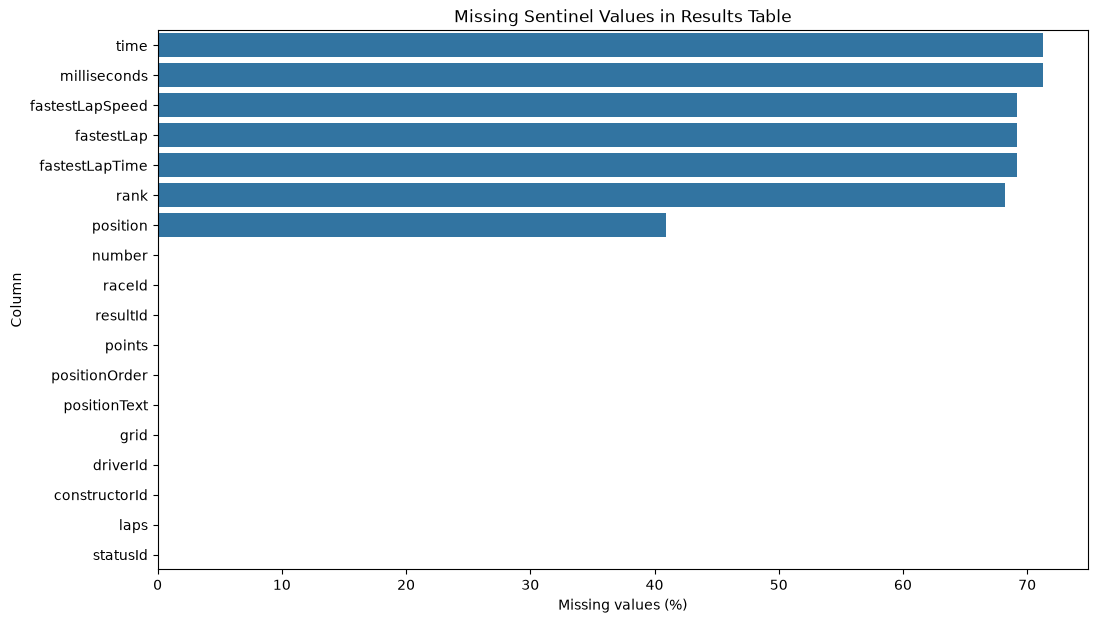

In [11]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=results_missing["Percentage"],
    y=results_missing.index
)

plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Missing Sentinel Values in Results Table")

plt.show()

<a id="h401"></a>
### Step 1.2e: The three position columns, `positionText` letter codes and disqualifications
<a id="c501"></a>
*Code cell 12* | [Back to contents](#toc)
**Why:** the introduction explains that `results.csv` has three position columns (`position`, `positionText`, `positionOrder`) and that `positionText` uses letter codes (R retired, D disqualified, E excluded, W withdrawn, F failed to qualify, N not classified). This cell checks that on our copy: which codes occur and where `position` is empty, how many drivers retired but were still **classified**, whether the `F` code agrees with the DNQ/DNPQ statuses, and whether any disqualified driver still holds a podium `positionOrder` (a disqualification after the flag must promote the next driver).


In [12]:
# The three "position" columns of results.csv, the positionText letter codes and disqualifications (raw table, EDA only)
eda_pt = results["positionText"].astype(str)
eda_code = eda_pt.where(~eda_pt.str.fullmatch(r"\d+"), "numeric")
EDA_CODE_MEANING = {"numeric": "classified, numeric position", "R": "retired", "D": "disqualified", "E": "excluded",
                    "W": "withdrawn", "F": "failed to qualify", "N": "not classified"}
eda_codes = (pd.DataFrame({"code": eda_code,
                           "position_empty": results["position"].isna() | results["position"].astype(str).eq(r"\N"),
                           "positionOrder_empty": results["positionOrder"].isna()})
             .groupby("code").agg(rows=("position_empty", "size"), position_empty=("position_empty", "sum"),
                                  positionOrder_empty=("positionOrder_empty", "sum")))
eda_codes["meaning"] = eda_codes.index.map(EDA_CODE_MEANING).fillna("other")
display(eda_codes.sort_values("rows", ascending=False))

eda_st = results[["statusId", "positionText", "positionOrder"]].merge(status, on="statusId", how="left", validate="many_to_one")
eda_finished = eda_st["status"].eq("Finished") | eda_st["status"].str.fullmatch(r"\+\d+ Laps?", na=False)
eda_classified_retired = (~eda_finished) & eda_st["positionText"].astype(str).str.fullmatch(r"\d+")
print(f"Stopped before the flag but still CLASSIFIED (numeric position): {int(eda_classified_retired.sum())} rows")
eda_dnq = eda_st["status"].isin(["Did not qualify", "Did not prequalify"])
eda_f = eda_st["positionText"].astype(str).eq("F")
print(f"positionText 'F': {int(eda_f.sum())} rows | status DNQ/DNPQ: {int(eda_dnq.sum())} rows | both: {int((eda_f & eda_dnq).sum())}")
eda_dsq = eda_st[eda_st["positionText"].astype(str).eq("D")]
print(f"Disqualified rows (positionText 'D'): {len(eda_dsq)} | with positionOrder <= 3: {int((eda_dsq['positionOrder'] <= 3).sum())}")
if len(eda_dsq) and (eda_dsq["positionOrder"] <= 3).sum() == 0:
    print("Reading: positionOrder is filled for every row and no disqualified driver keeps a podium positionOrder, so a disqualification after the flag",
          "is already reflected in the target positionOrder <= 3 (the next driver is promoted).")


,rows,position_empty,positionOrder_empty,meaning
code,,,,
numeric,15808,2,0,"classified, numeric position"
R,8897,8897,0,retired
F,1368,1368,0,failed to qualify
W,336,336,0,withdrawn
N,190,190,0,not classified
D,151,151,0,disqualified
E,9,9,0,excluded


Stopped before the flag but still CLASSIFIED (numeric position): 671 rows
positionText 'F': 1368 rows | status DNQ/DNPQ: 1356 rows | both: 1356
Disqualified rows (positionText 'D'): 151 | with positionOrder <= 3: 0
Reading: positionOrder is filled for every row and no disqualified driver keeps a podium positionOrder, so a disqualification after the flag is already reflected in the target positionOrder <= 3 (the next driver is promoted).


<a id="h015"></a>
### Step 1.3: Summary statistics of `results`
<a id="c012"></a>
*Code cell 13* | [Back to contents](#toc)
Checks ranges for plausibility: `grid` 0-34, `positionOrder` 1-39, `laps` up to 200, `points` up to 50 (points systems changed over time). Columns shown as `object` (`number`, `position`, `time`...) are the ones polluted by `\N`. No impossible value (negative, etc.) is visible, but this is formally tested later in the domain checks.


In [13]:
results.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
resultId,26759.0,NaN,NaN,NaN,13380.977391,7726.134642,1.0,6690.5,13380.0,20069.5,26764.0
raceId,26759.0,NaN,NaN,NaN,551.687283,313.265036,1.0,300.0,531.0,811.0,1144.0
driverId,26759.0,NaN,NaN,NaN,278.67353,282.703039,1.0,57.0,172.0,399.5,862.0
constructorId,26759.0,NaN,NaN,NaN,50.180537,61.551498,1.0,6.0,25.0,63.0,215.0
number,26759,130,4,1019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grid,26759.0,NaN,NaN,NaN,11.134796,7.20286,0.0,5.0,11.0,17.0,34.0
position,26759,34,\N,10953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positionText,26759,39,R,8897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positionOrder,26759.0,NaN,NaN,NaN,12.794051,7.665951,1.0,6.0,12.0,18.0,39.0
points,26759.0,NaN,NaN,NaN,1.987632,4.351209,0.0,0.0,0.0,2.0,50.0


<a id="h016"></a>
### Step 1.3a: Define the target and measure class balance (raw data)
<a id="c013"></a>
*Code cell 14* | [Back to contents](#toc)
`podium = positionOrder <= 3`. In the raw table 3,397 of 26,759 rows (**12.69%**) are podiums. The classes are imbalanced (about 1 : 7), so accuracy alone would be misleading later; PR-AUC / F1 / calibration will be needed. The rate is below the ~15% of the modern era because early seasons had larger fields.


In [14]:
position_order_numeric = pd.to_numeric(
    results["positionOrder"],
    errors="coerce"
)

podium_raw = (position_order_numeric <= 3).astype(int)

podium_counts = podium_raw.value_counts().sort_index()

podium_summary = pd.DataFrame({
    "Outcome": ["Non-Podium", "Podium"],
    "Count": [
        podium_counts.get(0, 0),
        podium_counts.get(1, 0)
    ]
})

podium_summary["Percentage"] = (
    podium_summary["Count"] / podium_summary["Count"].sum() * 100
).round(2)

podium_summary

,Outcome,Count,Percentage
0,Non-Podium,23362,87.31
1,Podium,3397,12.69


<a id="h017"></a>
### Step 1.3b: Temporary EDA copy with the target flag
<a id="c014"></a>
*Code cell 15* | [Back to contents](#toc)
Creates `podium_raw` on a **copy** (`results.copy()`), so the raw table stays untouched.


In [15]:
eda_results = results.copy()

eda_results["podium_raw"] = (
    pd.to_numeric(
        eda_results["positionOrder"],
        errors="coerce"
    ) <= 3
).astype(int)

<a id="h018"></a>
### Step 1.3c: Plot: podium vs. non-podium counts
<a id="c015"></a>
*Code cell 16* | [Back to contents](#toc)
Visual confirmation of the class imbalance computed above.


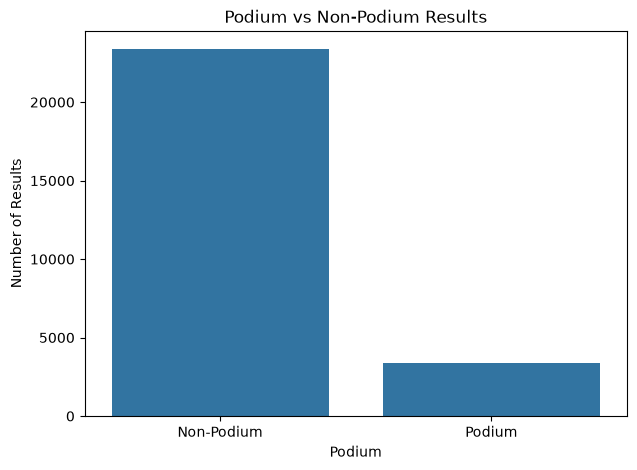

In [16]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=eda_results,
    x="podium_raw"
)

plt.xlabel("Podium")
plt.ylabel("Number of Results")
plt.title("Podium vs Non-Podium Results")

plt.xticks(
    [0, 1],
    ["Non-Podium", "Podium"]
)

plt.show()

<a id="h019"></a>
### Step 1.3d: Season coverage: races and circuits per season
<a id="c016"></a>
*Code cell 17* | [Back to contents](#toc)
Races per season grow from 7 (1950) to 24 (2024). In almost every season `circuits == races` (one race per circuit), so there are no duplicated race entries. Season length changes what a "typical" season looks like and is an argument for era-aware features.


In [17]:
# Season coverage

season_summary = races.groupby("year").agg(
    races=("raceId", "count"),
    circuits=("circuitId", "nunique")
).reset_index()

display(season_summary)

,year,races,circuits
0,1950,7,7
1,1951,8,8
2,1952,8,8
3,1953,9,9
4,1954,9,9
5,1955,7,7
6,1956,8,8
7,1957,8,8
8,1958,11,11
9,1959,9,9


<a id="h020"></a>
### Step 1.3e: Plot: number of Grands Prix per season
<a id="c017"></a>
*Code cell 18* | [Back to contents](#toc)
Visualises the growth in calendar length, including the dip in 2020 (COVID-shortened season).


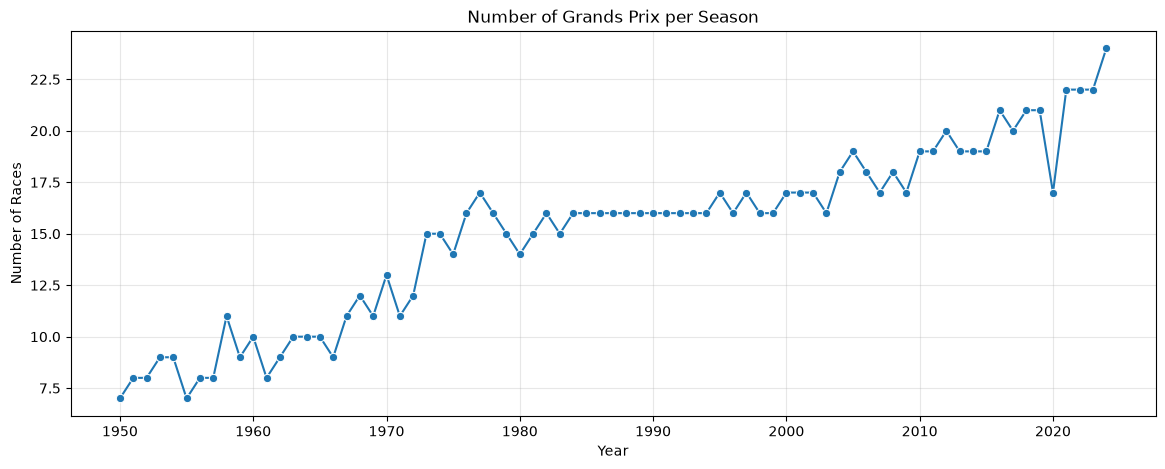

In [18]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=season_summary,
    x="year",
    y="races",
    marker="o"
)

plt.title("Number of Grands Prix per Season")
plt.xlabel("Year")
plt.ylabel("Number of Races")
plt.grid(True, alpha=0.3)
plt.show()

<a id="h021"></a>
### Step 1.4: Starting-grid statistics
<a id="c018"></a>
*Code cell 19* | [Back to contents](#toc)
Numerical summary of `grid`: median 11, maximum 34 (huge fields in some eras) and a minimum of **0**. The value 0 is not a real grid slot and is investigated in Step 1.9e.


In [19]:
# Starting grid position distribution

grid_summary = results["grid"].describe()
grid_summary

count    26759.000000
mean        11.134796
std          7.202860
min          0.000000
25%          5.000000
50%         11.000000
75%         17.000000
max         34.000000
Name: grid, dtype: float64

<a id="h022"></a>
### Step 1.4a: Histogram of grid positions
<a id="c019"></a>
*Code cell 20* | [Back to contents](#toc)
Shows the sharp spike at `grid = 0` and a long tail up to 34, which only exists in the large fields of the 1950s-1990s. Counts per slot fall after 20 because modern fields have about 20 cars.


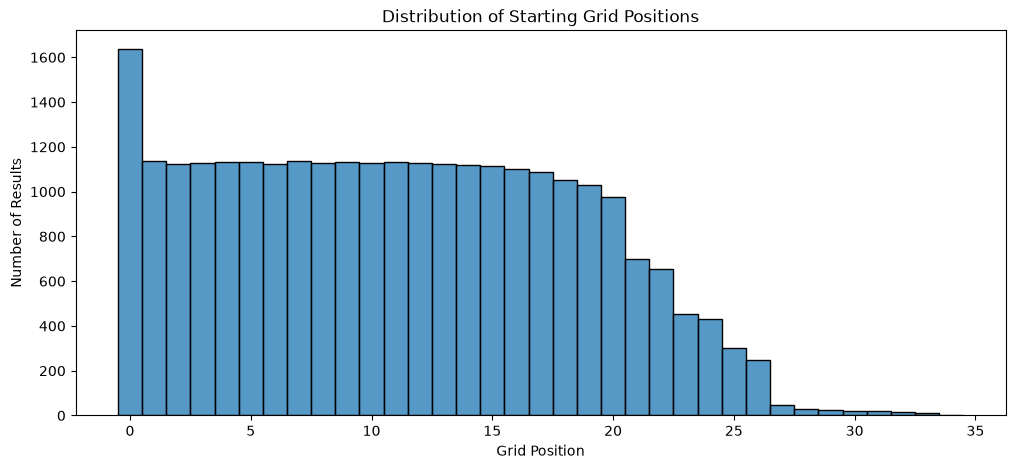

In [20]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=results,
    x="grid",
    bins=35,
    discrete=True
)

plt.title("Distribution of Starting Grid Positions")
plt.xlabel("Grid Position")
plt.ylabel("Number of Results")
plt.show()

<a id="h023"></a>
### Step 1.4b: How many rows have `grid = 0`?
<a id="c020"></a>
*Code cell 21* | [Back to contents](#toc)
1,638 rows (6.12%). The introduction says 0 means a pit-lane start but asks us to *verify it in the EDA*: this cell only counts them. The explanation is provided by Step 1.9e (crosstab with DNQ/DNPQ status and `laps = 0`).


In [21]:
print("Number of grid = 0:", (results["grid"] == 0).sum())
print("Percentage:", round((results["grid"] == 0).mean() * 100, 2), "%")

Number of grid = 0: 1638
Percentage: 6.12 %


<a id="h024"></a>
### Step 1.4c: Min / max of grid
<a id="c021"></a>
*Code cell 22* | [Back to contents](#toc)
Quick sanity print next to the `describe()` above: grid values lie between 0 and 34.


In [22]:
print("Minimum grid position:", results["grid"].min())
print("Maximum grid position:", results["grid"].max())

Minimum grid position: 0
Maximum grid position: 34


<a id="h025"></a>
### Step 1.5: Finishing-position statistics (`positionOrder`)
<a id="c022"></a>
*Code cell 23* | [Back to contents](#toc)
`positionOrder` is always filled (1 to 39). Because it ranks *every* entrant, classified or not, it is the correct source for the podium target.


In [23]:
# Finishing position distribution

position_summary = results["positionOrder"].describe()
position_summary

count    26759.000000
mean        12.794051
std          7.665951
min          1.000000
25%          6.000000
50%         12.000000
75%         18.000000
max         39.000000
Name: positionOrder, dtype: float64

<a id="h026"></a>
### Step 1.5a: Histogram of finishing positions
<a id="c023"></a>
*Code cell 24* | [Back to contents](#toc)
Counts decrease with rank because large fields (positions above 20) occurred only in some eras. The shape is a direct consequence of field size, not of data errors.


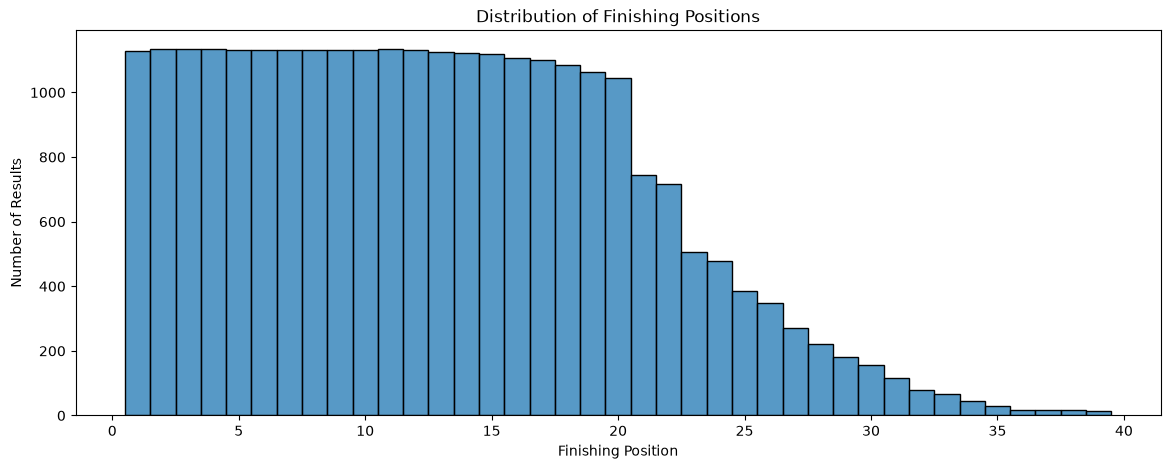

In [24]:
plt.figure(figsize=(14, 5))

sns.histplot(
    data=results,
    x="positionOrder",
    bins=39,
    discrete=True
)

plt.title("Distribution of Finishing Positions")
plt.xlabel("Finishing Position")
plt.ylabel("Number of Results")

plt.show()

<a id="h027"></a>
### Step 1.5b: Min / max of finishing position
<a id="c024"></a>
*Code cell 25* | [Back to contents](#toc)
Sanity print: min 1, max 39 (no zero or negative ranks).


In [25]:
print("Minimum finishing position:", results["positionOrder"].min())
print("Maximum finishing position:", results["positionOrder"].max())

Minimum finishing position: 1
Maximum finishing position: 39


<a id="h028"></a>
### Step 1.6: Attach readable status names to `results`
<a id="c025"></a>
*Code cell 26* | [Back to contents](#toc)
Left join with `status` on `statusId`. A **left** join keeps every result row (none is lost); the result is an EDA table only.


In [26]:
# Add readable status names to results

results_status = results.merge(
    status[["statusId", "status"]],
    on="statusId",
    how="left"
)

results_status[["statusId", "status"]].head()

,statusId,status
0,1,Finished
1,1,Finished
2,1,Finished
3,1,Finished
4,1,Finished


<a id="h029"></a>
### Step 1.6a: Most frequent race statuses
<a id="c026"></a>
*Code cell 27* | [Back to contents](#toc)
"Finished" (7,674) and lapped finishes ("+1 Lap", ...) are the minority of rows; the rest are retirements (Engine 2,026, Accident 1,062, Collision 854, ...). Important: **"Did not qualify" (1,025) and "Did not prequalify" (331) are present as rows**, i.e. entrants that never started. They must be handled in the modeling table (see Step 1.9e).


In [27]:
status_counts = (
    results_status["status"]
    .value_counts()
    .reset_index()
)

status_counts.columns = ["Status", "Count"]

status_counts.head(15)

,Status,Count
0,Finished,7674
1,+1 Lap,4037
2,Engine,2026
3,+2 Laps,1613
4,Accident,1062
5,Did not qualify,1025
6,Collision,854
7,Gearbox,810
8,Spun off,795
9,+3 Laps,731


<a id="h030"></a>
### Step 1.6b: Plot: top-15 statuses
<a id="c027"></a>
*Code cell 28* | [Back to contents](#toc)
Horizontal bar chart of the table above; makes the heavy tail of retirement reasons visible. This is the starting point for the later mechanical vs. non-mechanical grouping.


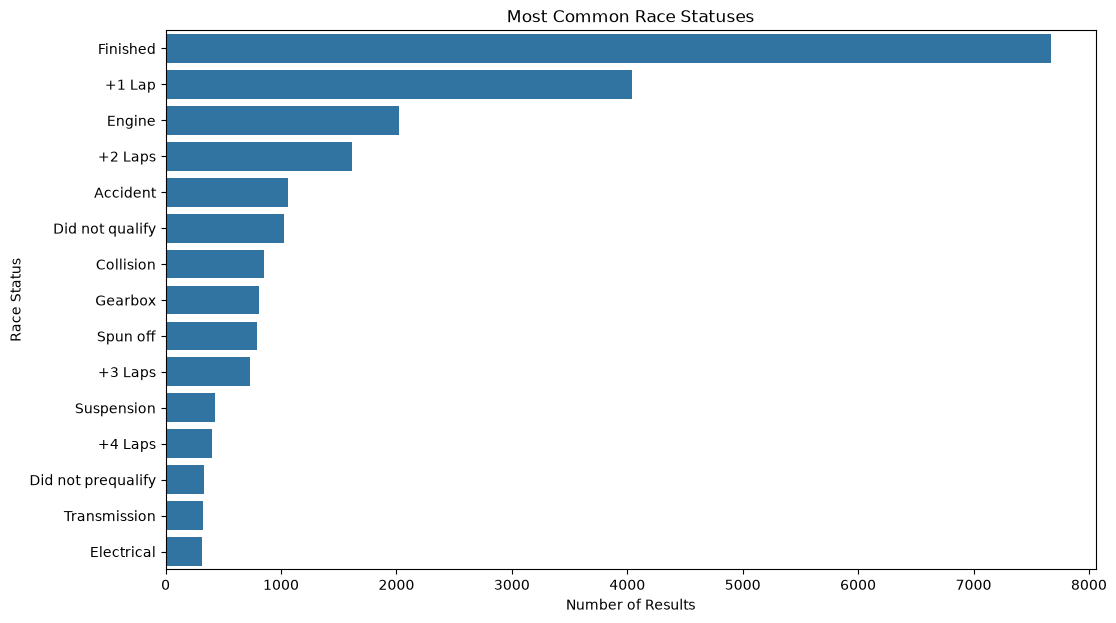

In [28]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=status_counts.head(15),
    y="Status",
    x="Count"
)

plt.title("Most Common Race Statuses")
plt.xlabel("Number of Results")
plt.ylabel("Race Status")

plt.show()

<a id="h031"></a>
### Step 1.6c: Top-20 statuses (table)
<a id="c028"></a>
*Code cell 29* | [Back to contents](#toc)
Extends the top-15 to 20 rows.


In [29]:
display(status_counts.head(20))

,Status,Count
0,Finished,7674
1,+1 Lap,4037
2,Engine,2026
3,+2 Laps,1613
4,Accident,1062
5,Did not qualify,1025
6,Collision,854
7,Gearbox,810
8,Spun off,795
9,+3 Laps,731


<a id="h032"></a>
### Step 1.7: Attach the season (`year`) to each result
<a id="c029"></a>
*Code cell 30* | [Back to contents](#toc)
Join with `races` to be able to analyse by season/era. Left join, no rows lost.


In [30]:
# Add race year to each result

results_with_year = results.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left"
)

results_with_year[["raceId", "year", "driverId"]].head()

,raceId,year,driverId
0,18,2008,1
1,18,2008,2
2,18,2008,3
3,18,2008,4
4,18,2008,5


<a id="h033"></a>
### Step 1.7a: Driver participation per season
<a id="c030"></a>
*Code cell 31* | [Back to contents](#toc)
Entries per season rise from 160 (1950) to 477 (1977) and then fall again; unique drivers per season peak in the 1950s (100+) because of one-off and shared-drive entries. This evidences the uneven fields described in the introduction.


In [31]:
driver_participation = (
    results_with_year
    .groupby("year")
    .agg(
        driver_race_records=("driverId", "count"),
        unique_drivers=("driverId", "nunique")
    )
    .reset_index()
)

display(driver_participation)

,year,driver_race_records,unique_drivers
0,1950,160,81
1,1951,179,84
2,1952,215,105
3,1953,246,108
4,1954,230,97
5,1955,180,84
6,1956,190,85
7,1957,171,76
8,1958,241,87
9,1959,195,88


<a id="h034"></a>
### Step 1.7b: Plot: driver-race records per season
<a id="c031"></a>
*Code cell 32* | [Back to contents](#toc)


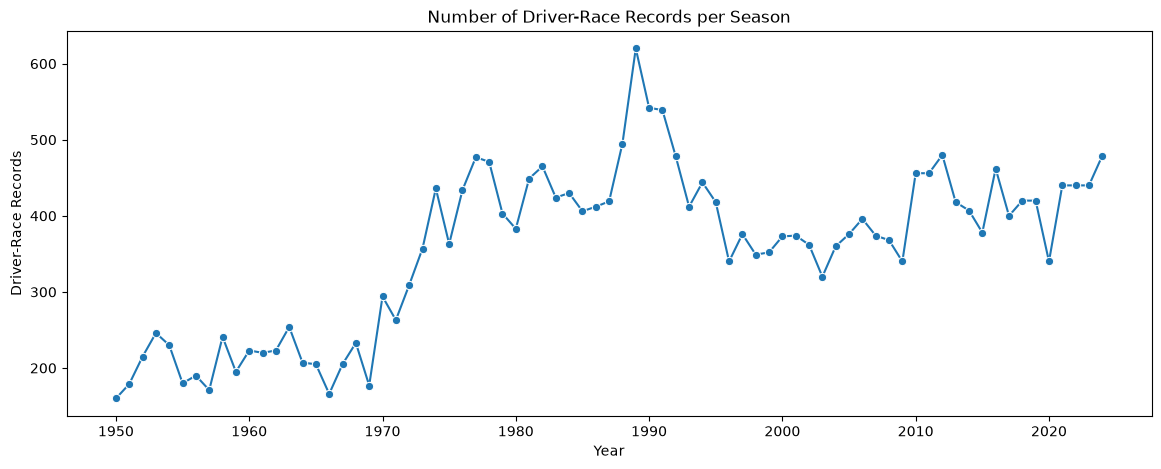

In [32]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=driver_participation,
    x="year",
    y="driver_race_records",
    marker="o"
)

plt.title("Number of Driver-Race Records per Season")
plt.xlabel("Year")
plt.ylabel("Driver-Race Records")

plt.show()

<a id="h035"></a>
### Step 1.7c: Plot: unique drivers per season
<a id="c032"></a>
*Code cell 33* | [Back to contents](#toc)
Many different drivers per season in the 1950s (including one-off local drivers) vs. a stable roster later. Relevant for "driver form" features, which will be sparse for early eras.


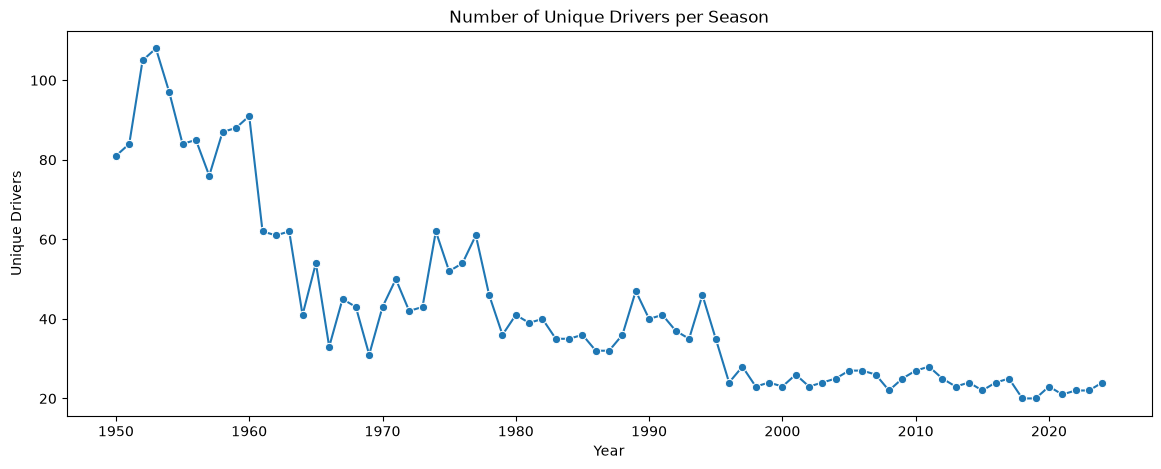

In [33]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=driver_participation,
    x="year",
    y="unique_drivers",
    marker="o"
)

plt.title("Number of Unique Drivers per Season")
plt.xlabel("Year")
plt.ylabel("Unique Drivers")

plt.show()

<a id="h036"></a>
### Step 1.7d: Podium base rate and field size per season, with the train / validation / test split
<a id="c033"></a>
*Code cell 34* | [Back to contents](#toc)
**Why:** the introduction says podiums are about 15% of rows in the modern era and far fewer in eras with 30+ entrants, while Step 1.3a gives only the *overall* rate (12.69%). We need the rate **per season** and **per split** (train ≤ 2019, validation 2020–2021, test ≥ 2022) because a base-rate shift between splits directly affects model evaluation and threshold choice.
**How to read:** the dashed line is the 15% reference. Where entries per race are high, the podium rate is far lower.


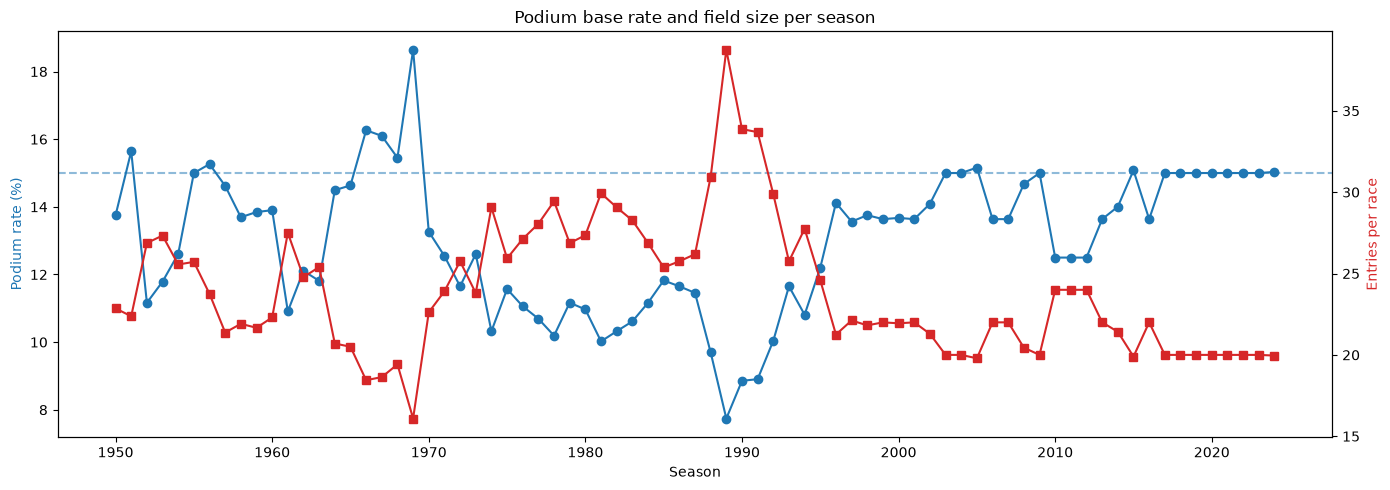

,races,rows,podiums,podium_rate_%
split,,,,
train (<=2019),1018,24620,3076,12.49
validation (2020-2021),39,780,117,15.00
test (>=2022),68,1359,204,15.01


In [34]:
era_df = results.merge(races[["raceId", "year"]], on="raceId", how="left")
era_df["podium"] = (era_df["positionOrder"] <= 3).astype(int)
era_df["split"] = pd.cut(era_df["year"], bins=[1949, 2019, 2021, 2100],
                         labels=["train (<=2019)", "validation (2020-2021)", "test (>=2022)"])

yearly = era_df.groupby("year").agg(rows=("podium", "size"), podiums=("podium", "sum"),
                                    races=("raceId", "nunique")).reset_index()
yearly["podium_rate_%"] = yearly["podiums"] / yearly["rows"] * 100
yearly["entries_per_race"] = yearly["rows"] / yearly["races"]

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(yearly["year"], yearly["podium_rate_%"], color="tab:blue", marker="o", label="Podium rate (%)")
ax1.axhline(15, color="tab:blue", linestyle="--", alpha=0.5)
ax1.set_xlabel("Season"); ax1.set_ylabel("Podium rate (%)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(yearly["year"], yearly["entries_per_race"], color="tab:red", marker="s", label="Entries per race")
ax2.set_ylabel("Entries per race", color="tab:red")
plt.title("Podium base rate and field size per season"); fig.tight_layout(); plt.show()

split_summary = era_df.groupby("split", observed=True).agg(
    races=("raceId", "nunique"), rows=("podium", "size"), podiums=("podium", "sum"))
split_summary["podium_rate_%"] = (split_summary["podiums"] / split_summary["rows"] * 100).round(2)
display(split_summary)

<a id="h037"></a>
### Step 1.8: Qualifying position statistics
<a id="c034"></a>
*Code cell 35* | [Back to contents](#toc)
`qualifying.position` runs from 1 to 28 with no missing value, so the qualifying order itself is always available *where the table has rows*.


In [35]:
# Qualifying position statistics

qualifying["position"].describe()

count    10494.000000
mean        11.195826
std          6.260374
min          1.000000
25%          6.000000
50%         11.000000
75%         16.000000
max         28.000000
Name: position, dtype: float64

<a id="h038"></a>
### Step 1.8a: Missing qualifying positions
<a id="c035"></a>
*Code cell 36* | [Back to contents](#toc)
0 missing: missingness in qualifying lies in the lap times (q1-q3) and in the **absence of whole races**, not in `position`.


In [36]:
print("Total qualifying records:", len(qualifying))
print(
    "Missing qualifying positions:",
    (qualifying["position"].astype(str) == r"\N").sum()
)

Total qualifying records: 10494
Missing qualifying positions: 0


<a id="h039"></a>
### Step 1.8b: Histogram of qualifying positions
<a id="c036"></a>
*Code cell 37* | [Back to contents](#toc)


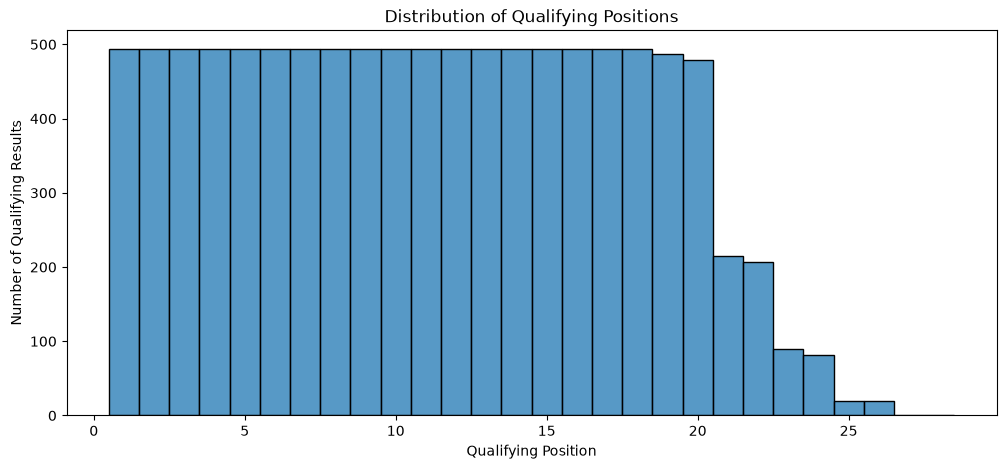

In [37]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=qualifying,
    x="position",
    bins=28,
    discrete=True
)

plt.title("Distribution of Qualifying Positions")
plt.xlabel("Qualifying Position")
plt.ylabel("Number of Qualifying Results")

plt.show()

<a id="h040"></a>
### Step 1.8c: Min / max of qualifying position (1 and 28).
<a id="c037"></a>
*Code cell 38* | [Back to contents](#toc)


In [38]:
print("Minimum qualifying position:", qualifying["position"].min())
print("Maximum qualifying position:", qualifying["position"].max())

Minimum qualifying position: 1
Maximum qualifying position: 28


<a id="h041"></a>
### Step 1.8d: Counts per qualifying position
<a id="c038"></a>
*Code cell 39* | [Back to contents](#toc)
Every position from 1 to 18 appears exactly 494 times, i.e. the table covers **494 qualifying sessions** only (vs. 1,125 races in `races`). That is the quantified coverage gap, which is plotted per season in Step 1.8e.


In [39]:
qualifying_position_counts = (
    qualifying["position"]
    .value_counts()
    .sort_index()
)

display(qualifying_position_counts)

position
1     494
2     494
3     494
4     494
5     494
6     494
7     494
8     494
9     494
10    494
11    494
12    494
13    494
14    494
15    494
16    494
17    494
18    494
19    487
20    479
21    215
22    207
23     90
24     82
25     20
26     20
27      1
28      1
Name: count, dtype: int64

<a id="h042"></a>
### Step 1.8e: Qualifying coverage per season (explicitly required by the project brief: "historical qualifying-coverage drift")
<a id="c039"></a>
*Code cell 40* | [Back to contents](#toc)
**Why:** `qualifying.csv` only has rows for part of F1 history, so any qualifying-based feature will be missing for older races. We measure coverage at two levels: share of **races** that have any qualifying data, and share of **result rows** (driver-race) that can be matched to a qualifying row. We also plot the share of rows that reached Q3.
**Decision it supports:** impute, fall back to `grid`, or restrict the training window (to be taken in the feature-engineering part).


First season with qualifying data: 1994


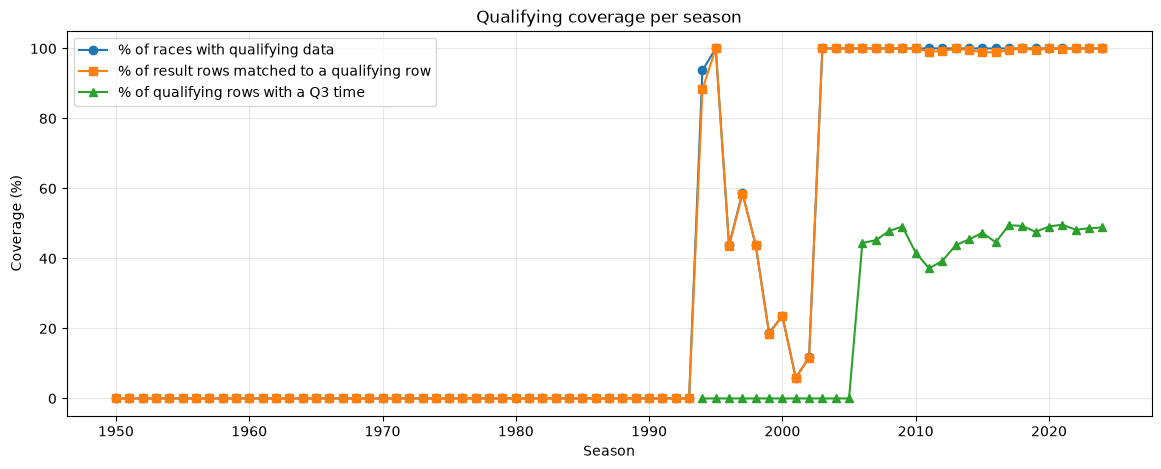

In [40]:
race_year = races[["raceId", "year"]]
qual_keys = qualifying[["raceId", "driverId"]].drop_duplicates().assign(has_quali=1)

cov_race = (race_year.assign(has_quali=race_year["raceId"].isin(qualifying["raceId"]))
            .groupby("year")["has_quali"].mean() * 100)

cov_rows = (results[["raceId", "driverId"]].drop_duplicates()
            .merge(race_year, on="raceId", how="left")
            .merge(qual_keys, on=["raceId", "driverId"], how="left")
            .assign(has_quali=lambda d: d["has_quali"].fillna(0))
            .groupby("year")["has_quali"].mean() * 100)

q3_present = qualifying["q3"].notna() & (qualifying["q3"].astype(str) != r"\N")
q3_share = (qualifying.assign(has_q3=q3_present).merge(race_year, on="raceId")
            .groupby("year")["has_q3"].mean() * 100)

first_year = int(race_year.loc[race_year["raceId"].isin(qualifying["raceId"]), "year"].min())
print("First season with qualifying data:", first_year)

plt.figure(figsize=(14, 5))
plt.plot(cov_race.index, cov_race.values, marker="o", label="% of races with qualifying data")
plt.plot(cov_rows.index, cov_rows.values, marker="s", label="% of result rows matched to a qualifying row")
plt.plot(q3_share.index, q3_share.values, marker="^", label="% of qualifying rows with a Q3 time")
plt.xlabel("Season"); plt.ylabel("Coverage (%)")
plt.title("Qualifying coverage per season")
plt.legend(); plt.grid(alpha=0.3); plt.show()

<a id="h043"></a>
### Step 1.9: Prepare grid vs. podium analysis
<a id="c040"></a>
*Code cell 41* | [Back to contents](#toc)
Temporary copy with `grid`, `positionOrder` and the `podium` flag (raw results, EDA only).


In [41]:
# Temporary dataframe for EDA

eda_grid = results[["grid", "positionOrder"]].copy()

eda_grid["podium"] = (
    pd.to_numeric(eda_grid["positionOrder"], errors="coerce") <= 3
).astype(int)

eda_grid.head()

,grid,positionOrder,podium
0,1,1,1
1,5,2,1
2,7,3,1
3,11,4,0
4,3,5,0


<a id="h044"></a>
### Step 1.9a: Podium rate by starting grid position
<a id="c041"></a>
*Code cell 42* | [Back to contents](#toc)
Strong, almost monotone relation: grid 1 gives a **63.5%** podium rate, grid 2 55.6%, grid 3 46.3%, falling to about 1% beyond 15. `grid = 0` gives **0%**. This shows why grid position is the strongest pre-race signal (and a legitimate feature, since the grid is fixed before the race).


In [42]:
grid_podium_rate = (
    eda_grid
    .groupby("grid")
    .agg(
        total_results=("podium", "count"),
        podiums=("podium", "sum"),
        podium_rate=("podium", "mean")
    )
    .reset_index()
)

grid_podium_rate["podium_rate_percent"] = (
    grid_podium_rate["podium_rate"] * 100
)

display(grid_podium_rate)

,grid,total_results,podiums,podium_rate,podium_rate_percent
0,0,1638,0,0.000000,0.000000
1,1,1136,721,0.634683,63.468310
2,2,1125,626,0.556444,55.644444
3,3,1130,523,0.462832,46.283186
4,4,1132,386,0.340989,34.098940
5,5,1132,283,0.250000,25.000000
6,6,1125,209,0.185778,18.577778
7,7,1135,147,0.129515,12.951542
8,8,1129,112,0.099203,9.920283
9,9,1132,94,0.083039,8.303887


<a id="h045"></a>
### Step 1.9b: Plot: podium rate by grid (all values)
<a id="c042"></a>
*Code cell 43* | [Back to contents](#toc)


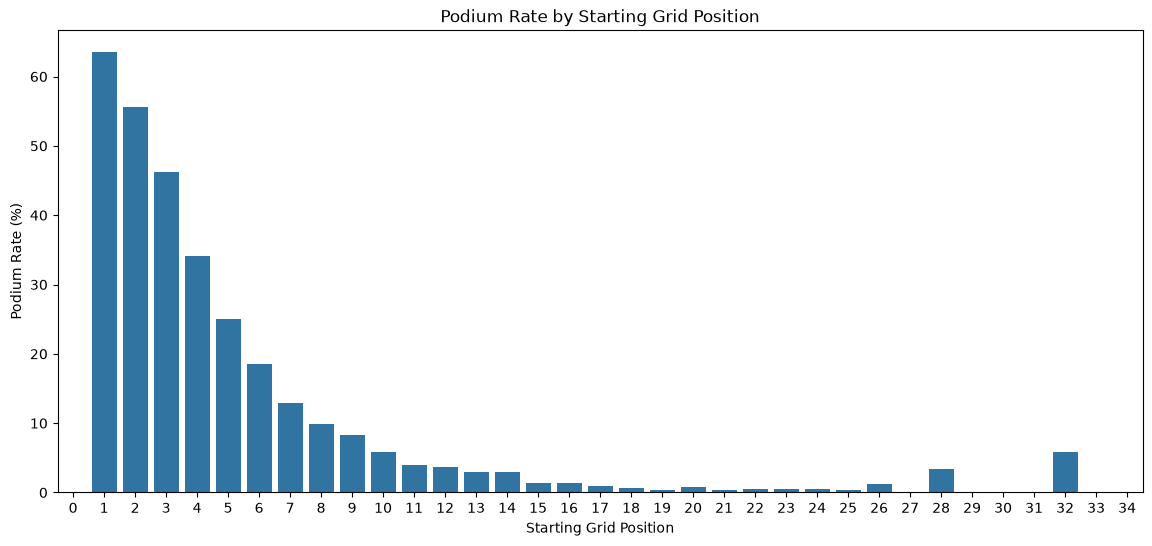

In [43]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=grid_podium_rate,
    x="grid",
    y="podium_rate_percent"
)

plt.title("Podium Rate by Starting Grid Position")
plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")

plt.show()

<a id="h046"></a>
### Step 1.9c: Plot: podium rate by grid, positions 1-20
<a id="c043"></a>
*Code cell 44* | [Back to contents](#toc)
Same chart restricted to realistic grid slots so the shape is easier to read (excludes `grid = 0` and the sparse slots above 20).


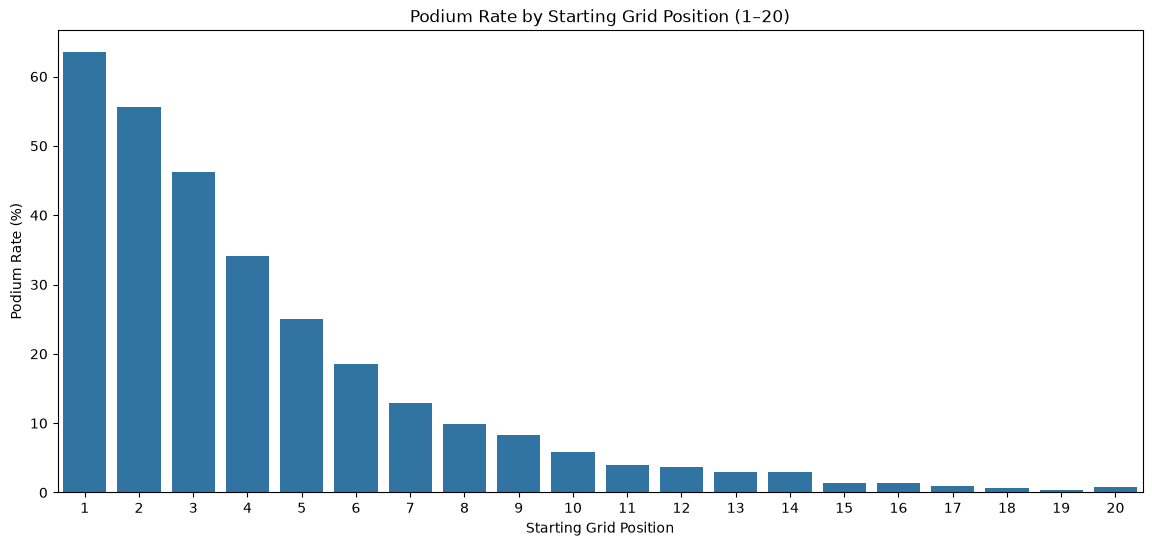

In [44]:
grid_podium_rate_20 = grid_podium_rate[
    grid_podium_rate["grid"].between(1, 20)
]

plt.figure(figsize=(14, 6))

sns.barplot(
    data=grid_podium_rate_20,
    x="grid",
    y="podium_rate_percent"
)

plt.title("Podium Rate by Starting Grid Position (1–20)")
plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")

plt.show()

<a id="h402"></a>
### Step 1.9d: Did grid position become less decisive after DRS (2011)?
<a id="c502"></a>
*Code cell 45* | [Back to contents](#toc)
**Why:** the introduction notes that DRS (introduced in 2011) makes grid position *slightly* less decisive. We compare the podium rate by grid slot in 2000–2010 and 2011–2024 (both eras with fields of about 20–24 cars) and the share of podium finishers who started 4th or lower.
**Caveat:** 2010–2011 also brought the refuelling ban and a single tyre supplier, and team dominance differs between the periods, so this is a descriptive comparison of eras, not a measured DRS effect. The cell prints its reading from the numbers; either way it supports treating the value of a grid slot as era-dependent, which Part B handles with a modern training window and per-season evaluation.


period,2000-2010 (before DRS),2011-2024 (DRS)
grid,,
1,74.6,80.8
2,58.0,68.7
3,52.8,50.3
4,32.6,34.3
5,21.2,19.2
6,17.1,14.0
7,13.0,8.1
8,8.3,3.2
9,2.6,4.2


Share of podium finishers who started 4th or lower: {'2000-2010 (before DRS)': 38.2, '2011-2024 (DRS)': 33.6}
Reading: in this data the start slot did NOT become less decisive after 2011 - fewer podium finishers came from 4th or lower (38.2% -> 33.6%) and the front row converted more often. Car dominance and the other rule changes outweigh any DRS effect, so the ERA (not DRS) is what the model must respect.


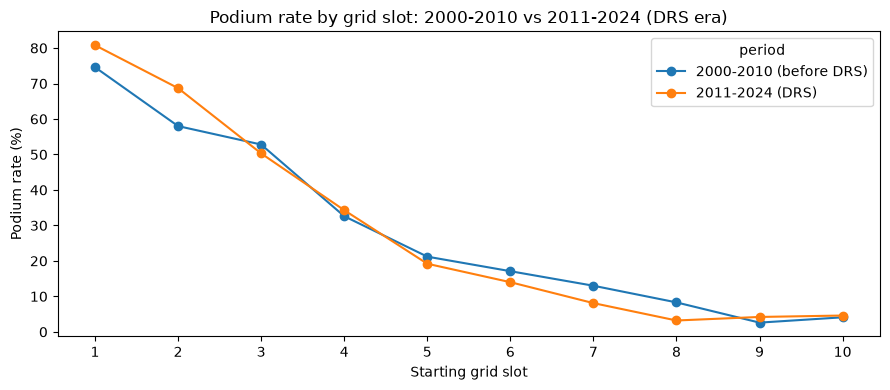

In [45]:
# Podium rate by grid slot before vs after DRS (raw results, starters with a grid slot only)
drs_df = results[["raceId", "grid", "positionOrder"]].merge(races[["raceId", "year"]], on="raceId", how="left", validate="many_to_one")
drs_df = drs_df[(drs_df["grid"] > 0) & drs_df["year"].between(2000, 2024)].copy()
drs_df["period"] = np.where(drs_df["year"] <= 2010, "2000-2010 (before DRS)", "2011-2024 (DRS)")
drs_df["podium"] = (drs_df["positionOrder"] <= 3).astype(int)
drs_rate = drs_df[drs_df["grid"] <= 10].groupby(["grid", "period"])["podium"].mean().mul(100).unstack().round(1)
display(drs_rate)
drs_share = drs_df[drs_df["podium"] == 1].groupby("period")["grid"].apply(lambda g: round(100 * (g >= 4).mean(), 1))
print("Share of podium finishers who started 4th or lower:", drs_share.to_dict())
_before, _after = drs_share.get("2000-2010 (before DRS)"), drs_share.get("2011-2024 (DRS)")
if _after < _before:
    print(f"Reading: in this data the start slot did NOT become less decisive after 2011 - fewer podium finishers came from 4th or lower ({_before}% -> {_after}%) "
          f"and the front row converted more often. Car dominance and the other rule changes outweigh any DRS effect, so the ERA (not DRS) is what the model must respect.")
else:
    print(f"Reading: after 2011 more podium finishers came from 4th or lower ({_before}% -> {_after}%), i.e. the start slot became somewhat less decisive, "
          f"consistent with (but not proof of) a DRS effect.")
ax = drs_rate.plot(marker="o", figsize=(9, 4))
ax.set_xlabel("Starting grid slot"); ax.set_ylabel("Podium rate (%)"); ax.set_xticks(range(1, 11))
ax.set_title("Podium rate by grid slot: 2000-2010 vs 2011-2024 (DRS era)")
plt.tight_layout(); plt.show()


<a id="h047"></a>
### Step 1.9e: What does `grid = 0` actually mean? (the introduction says "verify in EDA")
<a id="c044"></a>
*Code cell 46* | [Back to contents](#toc)
**Why:** 1,638 rows (6.12%) have `grid = 0` and **none** of them is a podium. Before choosing how to treat them we must know what they are: pit-lane starts, drivers who failed to (pre-)qualify, or drivers who never started. We cross-tabulate `grid = 0` with the DNQ / DNPQ statuses and with `laps = 0`, and look at how the share evolves by decade.
**Decision it supports:** whether non-starters (DNQ/DNPQ, 0 laps) stay in the modeling table or are filtered, and whether a `started_race` / `pit_lane_start` flag is needed.


grid == 0  x  DNQ/DNPQ status


did_not_qualify,False,True,All
grid_zero,,,
False,25109,12,25121
True,294,1344,1638
All,25403,1356,26759


grid == 0  x  laps == 0


zero_laps,False,True,All
grid_zero,,,
False,24155,966,25121
True,72,1566,1638
All,24227,2532,26759


Top statuses for grid == 0 rows that are NOT DNQ/DNPQ (pit-lane starts or other):


status
Withdrew        164
+1 Lap           27
Finished         22
Accident         20
Injury            8
+2 Laps           7
Engine            6
Disqualified      6
Excluded          6
Retired           3
Name: count, dtype: int64

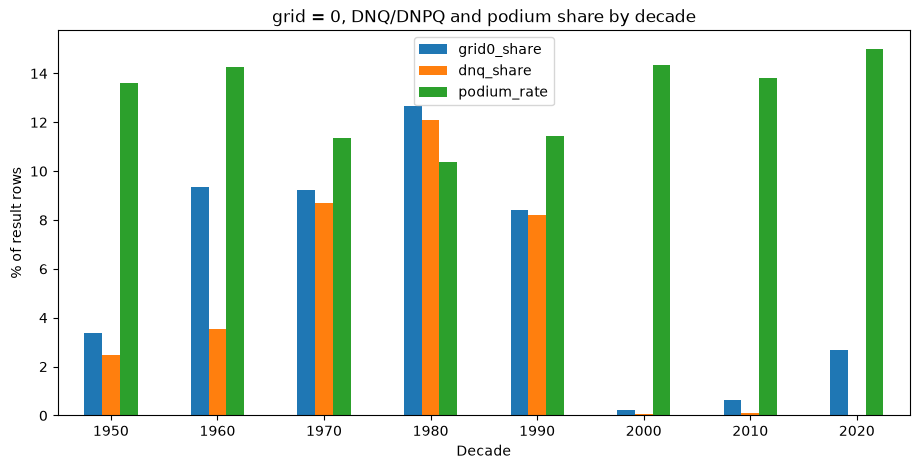

In [46]:
g = (results.merge(status, on="statusId", how="left")
            .merge(races[["raceId", "year"]], on="raceId", how="left"))
g["grid_zero"] = g["grid"] == 0
g["did_not_qualify"] = g["status"].isin(["Did not qualify", "Did not prequalify"])
g["zero_laps"] = g["laps"] == 0
g["podium"] = g["positionOrder"] <= 3

print("grid == 0  x  DNQ/DNPQ status")
display(pd.crosstab(g["grid_zero"], g["did_not_qualify"], margins=True))
print("grid == 0  x  laps == 0")
display(pd.crosstab(g["grid_zero"], g["zero_laps"], margins=True))
print("Top statuses for grid == 0 rows that are NOT DNQ/DNPQ (pit-lane starts or other):")
display(g.loc[g["grid_zero"] & ~g["did_not_qualify"], "status"].value_counts().head(10))

by_decade = g.groupby((g["year"] // 10) * 10).agg(
    grid0_share=("grid_zero", "mean"), dnq_share=("did_not_qualify", "mean"),
    podium_rate=("podium", "mean")) * 100
by_decade.plot(kind="bar", figsize=(11, 5))
plt.xlabel("Decade"); plt.ylabel("% of result rows")
plt.title("grid = 0, DNQ/DNPQ and podium share by decade"); plt.xticks(rotation=0); plt.show()

<a id="h048"></a>
### Step 1.9f: Indianapolis 500 (1950-1960) quantified
<a id="c045"></a>
*Code cell 47* | [Back to contents](#toc)
**Why:** the introduction warns that the Indy 500 counted for the championship in 1950-1960 but almost no F1 regulars entered it, so it distorts race counts, home-race analysis and grid structure. We identify those races via the circuit name (restricted to 1950-1960, because the same speedway hosted the US Grand Prix again in 2000-2007) and measure how many rows and "Indy-only" drivers are involved.
**Decision it supports:** exclude (or flag) these races in the modeling table; whichever is chosen must be documented.


In [47]:
indy_circuit_ids = circuits.loc[circuits["name"].str.contains("Indianapolis", case=False, na=False), "circuitId"]
indy_races = races[races["circuitId"].isin(indy_circuit_ids) & races["year"].between(1950, 1960)]
indy_res = results[results["raceId"].isin(indy_races["raceId"])]
other_res = results[~results["raceId"].isin(indy_races["raceId"])]
indy_only_drivers = set(indy_res["driverId"]) - set(other_res["driverId"])

print("Indy 500 races (1950-1960):", len(indy_races))
print("Result rows in those races:", len(indy_res), f"({len(indy_res) / len(results) * 100:.2f}% of all rows)")
print("Drivers who appear ONLY in the Indy 500:", len(indy_only_drivers),
      f"of {indy_res['driverId'].nunique()} Indy drivers")
print("Podium rate in Indy rows: %.2f%%  |  all other rows: %.2f%%" %
      ((indy_res["positionOrder"] <= 3).mean() * 100, (other_res["positionOrder"] <= 3).mean() * 100))
display(indy_races[["raceId", "year", "name", "circuitId"]])

Indy 500 races (1950-1960): 11
Result rows in those races: 405 (1.51% of all rows)
Drivers who appear ONLY in the Indy 500: 103 of 107 Indy drivers
Podium rate in Indy rows: 8.89%  |  all other rows: 12.75%


,raceId,year,name,circuitId
747,748,1960,Indianapolis 500,19
756,757,1959,Indianapolis 500,19
767,768,1958,Indianapolis 500,19
777,778,1957,Indianapolis 500,19
785,786,1956,Indianapolis 500,19
793,794,1955,Indianapolis 500,19
799,800,1954,Indianapolis 500,19
808,809,1953,Indianapolis 500,19
817,818,1952,Indianapolis 500,19
825,826,1951,Indianapolis 500,19


<a id="h049"></a>
### Step 1.10: Join qualifying with race results (EDA)
<a id="c046"></a>
*Code cell 48* | [Back to contents](#toc)
Inner join on `(raceId, driverId)`: only drivers present in **both** tables. In the raw `results` table, shared drives produce duplicate keys, which can duplicate rows in this EDA join; this is harmless for the exploratory rates but is a reason to repeat the analysis after de-duplication.


In [48]:
# Merge qualifying with race results

qualifying_results = qualifying[
    ["raceId", "driverId", "position"]
].merge(
    results[
        ["raceId", "driverId", "positionOrder"]
    ],
    on=["raceId", "driverId"],
    how="inner"
)

qualifying_results.head()

,raceId,driverId,position,positionOrder
0,18,1,1,1
1,18,9,2,9
2,18,5,3,5
3,18,13,4,13
4,18,2,5,2


<a id="h050"></a>
### Step 1.10a: Add the podium flag to the joined table.
<a id="c047"></a>
*Code cell 49* | [Back to contents](#toc)


In [49]:
qualifying_results["podium"] = (
    pd.to_numeric(
        qualifying_results["positionOrder"],
        errors="coerce"
    ) <= 3
).astype(int)

<a id="h051"></a>
### Step 1.10b: Podium rate by qualifying position
<a id="c048"></a>
*Code cell 50* | [Back to contents](#toc)
Pole position gives a **75.9%** podium rate, higher than grid 1 (63.5%). The difference is not a contradiction: qualifying data exists only for the modern, more reliable and more predictable era, whereas the overall grid curve mixes in the 1950s-1980s. This is evidence for an **era-aware** approach.


In [50]:
qualifying_podium_rate = (
    qualifying_results
    .groupby("position")
    .agg(
        total_results=("podium", "count"),
        podiums=("podium", "sum"),
        podium_rate=("podium", "mean")
    )
    .reset_index()
)

qualifying_podium_rate["podium_rate_percent"] = (
    qualifying_podium_rate["podium_rate"] * 100
)

display(qualifying_podium_rate)

,position,total_results,podiums,podium_rate,podium_rate_percent
0,1,494,375,0.759109,75.910931
1,2,494,305,0.617409,61.740891
2,3,494,249,0.504049,50.404858
3,4,494,170,0.344130,34.412955
4,5,494,118,0.238866,23.886640
5,6,494,74,0.149798,14.979757
6,7,494,47,0.095142,9.514170
7,8,494,28,0.056680,5.668016
8,9,494,21,0.042510,4.251012
9,10,494,20,0.040486,4.048583


<a id="h052"></a>
### Step 1.10c: Plot: podium rate by qualifying position (1-20)
<a id="c049"></a>
*Code cell 51* | [Back to contents](#toc)


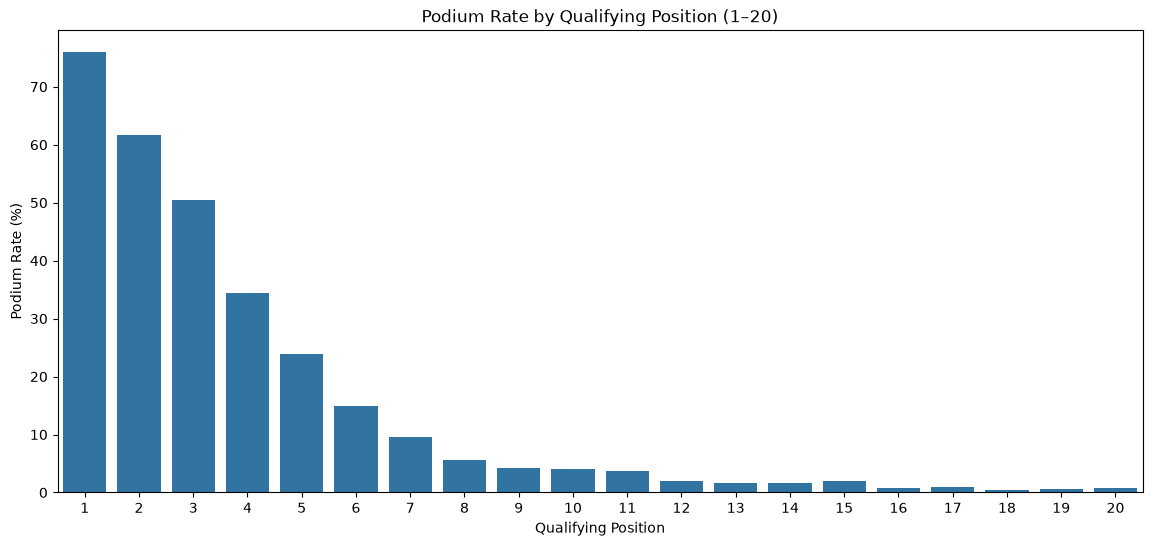

In [51]:
qualifying_podium_rate_20 = qualifying_podium_rate[
    qualifying_podium_rate["position"].between(1, 20)
]

plt.figure(figsize=(14, 6))

sns.barplot(
    data=qualifying_podium_rate_20,
    x="position",
    y="podium_rate_percent"
)

plt.title("Podium Rate by Qualifying Position (1–20)")
plt.xlabel("Qualifying Position")
plt.ylabel("Podium Rate (%)")

plt.show()

<a id="h053"></a>
### Step 1.10d: Qualifying position vs. starting grid (they are not the same thing)
<a id="c050"></a>
*Code cell 52* | [Back to contents](#toc)
**Why:** the introduction stresses that penalties, pit-lane starts and exclusions move drivers away from their qualifying slot. If the two are nearly identical, `grid` is a safe substitute where qualifying is missing; if they differ often, both signals carry information. We measure how often they disagree and plot the shift (grid - qualifying position) for drivers who actually have a grid slot.
**Note:** `drop_duplicates` is used only for this exploratory join; the formal duplicate rule is applied later.


Rows with both qualifying and grid: 10494
Share where grid != qualifying position: 23.91%
Share with grid == 0 (pit lane / non-start): 0.83%


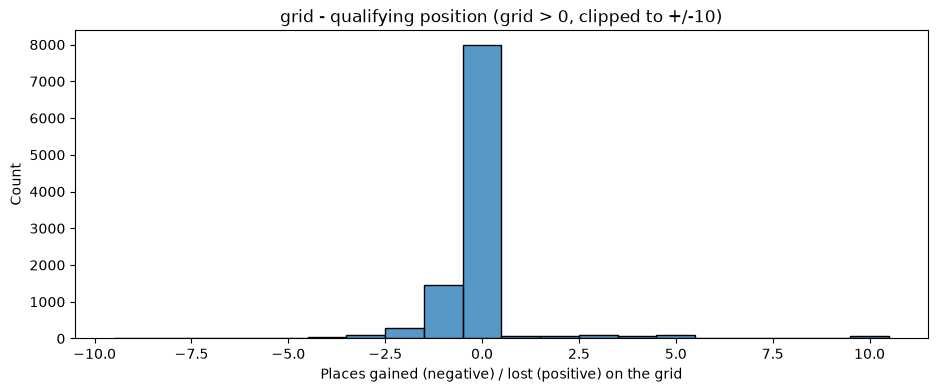

In [52]:
qg = (qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"})
      .drop_duplicates(["raceId", "driverId"])
      .merge(results[["raceId", "driverId", "grid"]].drop_duplicates(["raceId", "driverId"]),
             on=["raceId", "driverId"], how="inner"))
qg["differs"] = qg["quali_pos"] != qg["grid"]
qg["shift"] = qg["grid"] - qg["quali_pos"]

print("Rows with both qualifying and grid:", len(qg))
print("Share where grid != qualifying position: %.2f%%" % (qg["differs"].mean() * 100))
print("Share with grid == 0 (pit lane / non-start): %.2f%%" % ((qg["grid"] == 0).mean() * 100))

plt.figure(figsize=(11, 4))
sns.histplot(qg.loc[qg["grid"] > 0, "shift"].clip(-10, 10), discrete=True)
plt.title("grid - qualifying position (grid > 0, clipped to +/-10)")
plt.xlabel("Places gained (negative) / lost (positive) on the grid"); plt.show()

<a id="h054"></a>
### Step 1.11: Unified missing-value audit (all tables, all columns)
<a id="c051"></a>
*Code cell 53* | [Back to contents](#toc)
One table with `\N` + empty strings + `NaN` per column (120 rows). This is the single reference for missingness, and it exposes the `NaN` that `read_csv` created itself (e.g. 46 in `qualifying.q3`).


In [53]:
missing_audit = []

for name, df in tables.items():
    for column in df.columns:

        sentinel_count = (df[column].astype(str) == r"\N").sum()
        empty_count = (df[column].astype(str).str.strip() == "").sum()
        nan_count = df[column].isna().sum()

        total_missing = sentinel_count + empty_count + nan_count

        missing_audit.append({
            "Table": name,
            "Column": column,
            "Rows": len(df),
            "Sentinel_\\N": sentinel_count,
            "Empty_String": empty_count,
            "NaN": nan_count,
            "Total_Missing": total_missing,
            "Missing_Percentage": round(
                total_missing / len(df) * 100, 2
            )
        })

missing_audit = pd.DataFrame(missing_audit)

missing_audit = missing_audit.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_audit)

,Table,Column,Rows,Sentinel_\N,Empty_String,NaN,Total_Missing,Missing_Percentage
18,constructor_results,status,12625,12608,0,0,12608,99.87
81,races,sprint_time,1125,1110,0,0,1110,98.67
80,races,sprint_date,1125,1107,0,0,1107,98.40
77,races,fp3_time,1125,1072,0,0,1072,95.29
73,races,fp1_time,1125,1057,0,0,1057,93.96
...,...,...,...,...,...,...,...,...
107,sprint_results,grid,360,0,0,0,0,0.00
112,sprint_results,laps,360,0,0,0,0,0.00
117,sprint_results,statusId,360,0,0,0,0,0.00
118,status,statusId,139,0,0,0,0,0.00


<a id="h055"></a>
### Step 1.11a: Only the columns that have missing values.
<a id="c052"></a>
*Code cell 54* | [Back to contents](#toc)


In [54]:
missing_columns = missing_audit[
    missing_audit["Total_Missing"] > 0
]

display(missing_columns)

,Table,Column,Rows,Sentinel_\N,Empty_String,NaN,Total_Missing,Missing_Percentage
18,constructor_results,status,12625,12608,0,0,12608,99.87
81,races,sprint_time,1125,1110,0,0,1110,98.67
80,races,sprint_date,1125,1107,0,0,1107,98.40
77,races,fp3_time,1125,1072,0,0,1072,95.29
73,races,fp1_time,1125,1057,0,0,1057,93.96
75,races,fp2_time,1125,1057,0,0,1057,93.96
79,races,quali_time,1125,1057,0,0,1057,93.96
76,races,fp3_date,1125,1053,0,0,1053,93.60
28,drivers,number,861,802,0,0,802,93.15
72,races,fp1_date,1125,1035,0,0,1035,92.00


<a id="h056"></a>
### Step 1.11b: Missingness per table
<a id="c053"></a>
*Code cell 55* | [Back to contents](#toc)
`results` has by far the most missing cells (122,887, in 8 columns), but almost all are structural (see Step 1.2). `qualifying` and `races` follow.


In [55]:
table_missing_summary = (
    missing_audit
    .groupby("Table")
    .agg(
        Total_Missing=("Total_Missing", "sum"),
        Columns_With_Missing=(
            "Total_Missing",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
    .sort_values(
        "Total_Missing",
        ascending=False
    )
)

display(table_missing_summary)

,Table,Total_Missing,Columns_With_Missing
10,results,122887,8
1,constructor_results,12608,1
8,qualifying,11668,3
9,races,11349,11
5,drivers,1559,2
12,sprint_results,73,5
4,driver_standings,0,0
3,constructors,0,0
2,constructor_standings,0,0
0,circuits,0,0


<a id="h057"></a>
### Step 1.11c: Plot: top-25 columns by % missing
<a id="c054"></a>
*Code cell 56* | [Back to contents](#toc)
The worst columns are all optional metadata (sprint/practice dates and times, constructor result status, driver code/number), none of which is needed for the target.


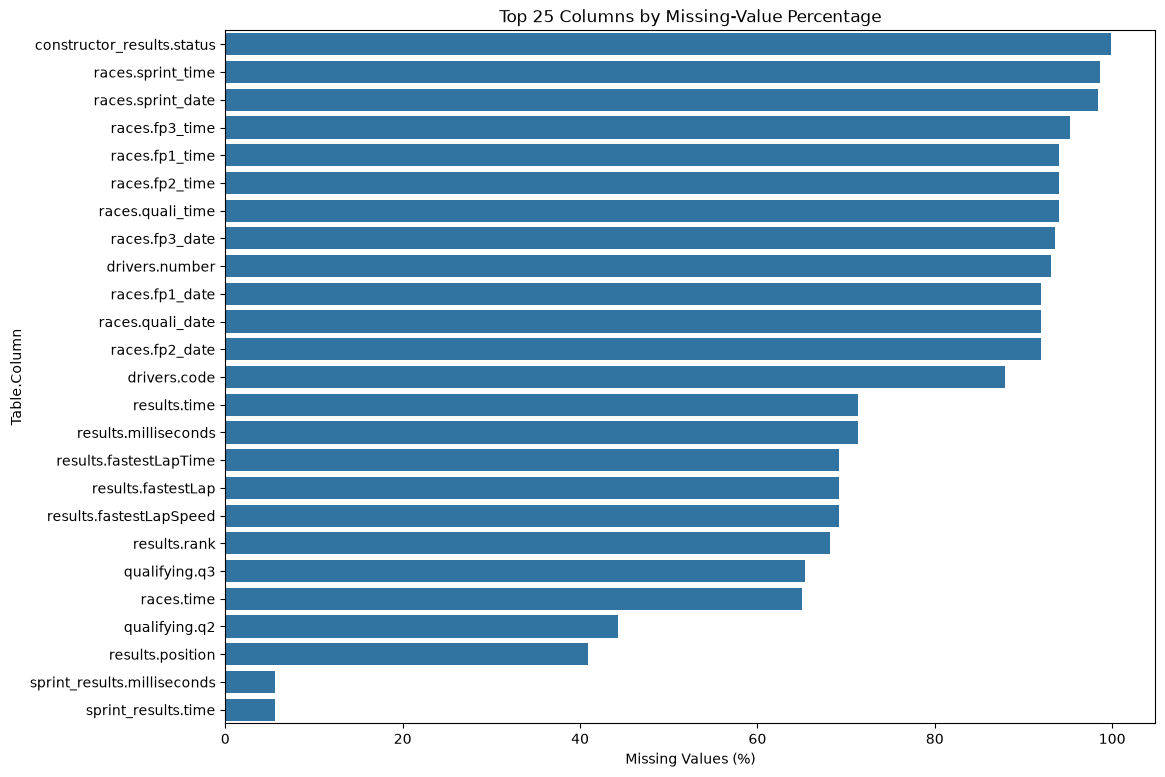

In [56]:
missing_plot = missing_columns[
    ["Table", "Column", "Missing_Percentage"]
].copy()

missing_plot["Label"] = (
    missing_plot["Table"] + "." + missing_plot["Column"]
)

missing_plot = missing_plot.head(25)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=missing_plot,
    x="Missing_Percentage",
    y="Label"
)

plt.title("Top 25 Columns by Missing-Value Percentage")
plt.xlabel("Missing Values (%)")
plt.ylabel("Table.Column")

plt.show()

<a id="h058"></a>
### Step 1.11d: Missingness of the key tables (results, qualifying, races, drivers, sprint_results).
<a id="c055"></a>
*Code cell 57* | [Back to contents](#toc)


In [57]:
key_missing = missing_audit[
    missing_audit["Table"].isin([
        "results",
        "qualifying",
        "races",
        "drivers",
        "sprint_results"
    ])
]

display(key_missing)

,Table,Column,Rows,Sentinel_\N,Empty_String,NaN,Total_Missing,Missing_Percentage
81,races,sprint_time,1125,1110,0,0,1110,98.67
80,races,sprint_date,1125,1107,0,0,1107,98.40
77,races,fp3_time,1125,1072,0,0,1072,95.29
73,races,fp1_time,1125,1057,0,0,1057,93.96
75,races,fp2_time,1125,1057,0,0,1057,93.96
79,races,quali_time,1125,1057,0,0,1057,93.96
76,races,fp3_date,1125,1053,0,0,1053,93.60
28,drivers,number,861,802,0,0,802,93.15
72,races,fp1_date,1125,1035,0,0,1035,92.00
78,races,quali_date,1125,1035,0,0,1035,92.00


<a id="h059"></a>
### Step 1.11e: Missingness detail: `results`
<a id="c056"></a>
*Code cell 58* | [Back to contents](#toc)


In [58]:
results_missing_detail = missing_audit[
    missing_audit["Table"] == "results"
].copy()

display(
    results_missing_detail.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Table,Column,Rows,Sentinel_\N,Empty_String,NaN,Total_Missing,Missing_Percentage
93,results,time,26759,19079,0,0,19079,71.30
94,results,milliseconds,26759,19079,0,0,19079,71.30
97,results,fastestLapTime,26759,18507,0,0,18507,69.16
95,results,fastestLap,26759,18507,0,0,18507,69.16
98,results,fastestLapSpeed,26759,18507,0,0,18507,69.16
96,results,rank,26759,18249,0,0,18249,68.20
88,results,position,26759,10953,0,0,10953,40.93
86,results,number,26759,6,0,0,6,0.02
87,results,grid,26759,0,0,0,0,0.00
85,results,constructorId,26759,0,0,0,0,0.00


<a id="h060"></a>
### Step 1.11f: Missingness detail: `qualifying`
<a id="c057"></a>
*Code cell 59* | [Back to contents](#toc)
`q1` is missing in 1.49% of rows, `q2` in 44% and `q3` in 65%: consistent with the knockout format (drivers eliminated in Q1 have no Q2/Q3 time) plus older formats that only recorded one time.


In [59]:
qualifying_missing_detail = missing_audit[
    missing_audit["Table"] == "qualifying"
].copy()

display(
    qualifying_missing_detail.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Table,Column,Rows,Sentinel_\N,Empty_String,NaN,Total_Missing,Missing_Percentage
63,qualifying,q3,10494,6819,0,46,6865,65.42
62,qualifying,q2,10494,4625,0,22,4647,44.28
61,qualifying,q1,10494,156,0,0,156,1.49
55,qualifying,qualifyId,10494,0,0,0,0,0.00
59,qualifying,number,10494,0,0,0,0,0.00
58,qualifying,constructorId,10494,0,0,0,0,0.00
57,qualifying,driverId,10494,0,0,0,0,0.00
56,qualifying,raceId,10494,0,0,0,0,0.00
60,qualifying,position,10494,0,0,0,0,0.00


<a id="h061"></a>
### Step 1.11g: Missingness detail: `races`
<a id="c058"></a>
*Code cell 60* | [Back to contents](#toc)
Practice/qualifying/sprint date and time columns are 92-99% missing (recorded only in recent seasons), race start `time` is 65% missing. They are kept but cannot be used as features for most of history.


In [60]:
races_missing_detail = missing_audit[
    missing_audit["Table"] == "races"
].copy()

display(
    races_missing_detail.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Table,Column,Rows,Sentinel_\N,Empty_String,NaN,Total_Missing,Missing_Percentage
81,races,sprint_time,1125,1110,0,0,1110,98.67
80,races,sprint_date,1125,1107,0,0,1107,98.40
77,races,fp3_time,1125,1072,0,0,1072,95.29
73,races,fp1_time,1125,1057,0,0,1057,93.96
75,races,fp2_time,1125,1057,0,0,1057,93.96
79,races,quali_time,1125,1057,0,0,1057,93.96
76,races,fp3_date,1125,1053,0,0,1053,93.60
72,races,fp1_date,1125,1035,0,0,1035,92.00
78,races,quali_date,1125,1035,0,0,1035,92.00
74,races,fp2_date,1125,1035,0,0,1035,92.00


<a id="h062"></a>
## 2. Cleaning (on copies of the raw tables)


<a id="h063"></a>
### Step 2.1: Create cleaned copies of all tables
<a id="c059"></a>
*Code cell 61* | [Back to contents](#toc)
`cleaned_tables = {name: df.copy()}`. **Every cleaning step from here on modifies only these copies**, which is how we respect "raw CSV files remain immutable".


In [61]:
# Create cleaned copies of all tables
# Raw tables remain unchanged

cleaned_tables = {
    name: df.copy()
    for name, df in tables.items()
}

print("Created cleaned copies for", len(cleaned_tables), "tables.")

Created cleaned copies for 14 tables.


<a id="h064"></a>
### Step 2.2: Convert the `\N` sentinel to a real missing value
<a id="c060"></a>
*Code cell 62* | [Back to contents](#toc)
`df.replace(r"\N", pd.NA)` on every table. **Justification:** `\N` is a MySQL export marker, not a value; leaving it makes numeric columns `object` and distorts statistics. We convert to missing instead of imputing, because most of the missingness is structural (not applicable).


In [62]:
# Convert \N sentinel values to pandas NA

for name, df in cleaned_tables.items():
    cleaned_tables[name] = df.replace(r"\N", pd.NA)

print("Sentinel conversion complete.")

Sentinel conversion complete.


<a id="h065"></a>
### Step 2.2a: Verify that no `\N` remains
<a id="c061"></a>
*Code cell 63* | [Back to contents](#toc)
Programmatic check over all tables and columns: 0 left.


In [63]:
remaining_sentinels = []

for name, df in cleaned_tables.items():
    for column in df.columns:
        count = (df[column].astype(str) == r"\N").sum()

        if count > 0:
            remaining_sentinels.append({
                "Table": name,
                "Column": column,
                "Remaining": count
            })

if remaining_sentinels:
    display(pd.DataFrame(remaining_sentinels))
else:
    print("No remaining \\N sentinel values found.")

No remaining \N sentinel values found.


<a id="h066"></a>
### Step 2.3: Declare which columns must be numeric
<a id="c062"></a>
*Code cell 64* | [Back to contents](#toc)
Schema map (table to numeric columns). The sprint-results entry deliberately excludes `fastestLapTime` (a `m:ss.mmm` time string, which `errors="coerce"` would turn into all-`NaN`); lap-time strings are converted to seconds in the duration step (Step 2.4).


In [64]:
numeric_columns = {
    "circuits": [
        "circuitId", "lat", "lng", "alt"
    ],

    "constructors": [
        "constructorId"
    ],

    "constructor_results": [
        "constructorResultsId", "raceId",
        "constructorId", "points"
    ],

    "constructor_standings": [
        "constructorStandingsId", "raceId",
        "constructorId", "points",
        "position", "wins"
    ],

    "drivers": [
        "driverId", "number"
    ],

    "driver_standings": [
        "driverStandingsId", "raceId",
        "driverId", "points",
        "position", "wins"
    ],

    "qualifying": [
        "qualifyId", "raceId", "driverId",
        "constructorId", "number", "position"
    ],

    "results": [
        "resultId", "raceId", "driverId",
        "constructorId", "number", "grid",
        "position", "positionOrder",
        "points", "laps", "milliseconds",
        "fastestLap", "rank",
        "fastestLapSpeed", "statusId"
    ],

    "races": [
        "raceId", "year", "round", "circuitId"
    ],

    "sprint_results": [
        "resultId", "raceId", "driverId",
        "constructorId", "number", "grid",
        "position", "positionOrder",
        "points", "laps", "milliseconds",
        "fastestLap", "statusId"
    ],

    "status": [
        "statusId"
    ]
}

<a id="h067"></a>
### Step 2.3a: Apply the numeric conversion
<a id="c063"></a>
*Code cell 65* | [Back to contents](#toc)
`pd.to_numeric(..., errors="coerce")` on the columns above. `errors="coerce"` hides failures: any unparsable value silently becomes `NaN`. A safety check that counts *new* missing values is added right after the date conversion (Step 2.3d).


In [65]:
for table_name, columns in numeric_columns.items():

    df = cleaned_tables[table_name]

    for column in columns:
        if column in df.columns:
            df[column] = pd.to_numeric(
                df[column],
                errors="coerce"
            )

    cleaned_tables[table_name] = df

print("Numeric type conversion complete.")

Numeric type conversion complete.


<a id="h068"></a>
### Step 2.3b: Convert race dates to `datetime64`
<a id="c064"></a>
*Code cell 66* | [Back to contents](#toc)
Applies to `date`, `fp1_date`, `fp2_date`, `fp3_date`, `quali_date`, `sprint_date` (semantic typing of dates, required by the brief). Missing dates become `NaT`.


In [66]:
date_columns = [
    "date",
    "fp1_date",
    "fp2_date",
    "fp3_date",
    "quali_date",
    "sprint_date"
]

for column in date_columns:
    if column in cleaned_tables["races"].columns:
        cleaned_tables["races"][column] = pd.to_datetime(
            cleaned_tables["races"][column],
            errors="coerce"
        )

print("Race date conversion complete.")

Race date conversion complete.


<a id="h069"></a>
### Step 2.3c: Convert driver date of birth to `datetime64`
<a id="c065"></a>
*Code cell 67* | [Back to contents](#toc)
Needed to compute driver age at race time (checked in the domain validation).


In [67]:
cleaned_tables["drivers"]["dob"] = pd.to_datetime(
    cleaned_tables["drivers"]["dob"],
    errors="coerce"
)

print("Driver date conversion complete.")

Driver date conversion complete.


<a id="h070"></a>
### Step 2.3d: Safety check on the type conversions (detects values destroyed by `errors="coerce"`)
<a id="c066"></a>
*Code cell 68* | [Back to contents](#toc)
**Why:** `pd.to_numeric(..., errors="coerce")` and `pd.to_datetime(..., errors="coerce")` turn *anything* unparsable into `NaN`/`NaT` without warning. The only legitimate missing values are the ones that were `\N`/`NaN` in the raw file, so for each converted column we count **new** missing values created by the conversion. Any number above 0 means real data was lost.
**Reading:** the table lists every converted column that lost values; an empty table means no real data was destroyed. Time strings such as `sprint_results.fastestLapTime` are not in the numeric list; they are parsed into seconds in Step 2.4.
We also cast integer-like columns that contain missing values to pandas nullable `Int64` (e.g. `results.position`, `drivers.number`) instead of leaving them as floats.


In [68]:
conv_rows = []
for tname, cols in numeric_columns.items():
    for c in cols:
        if c in cleaned_tables[tname].columns:
            raw_missing = int((tables[tname][c].isna() | (tables[tname][c].astype(str) == r"\N")).sum())
            new_missing = int(cleaned_tables[tname][c].isna().sum()) - raw_missing
            conv_rows.append({"Table": tname, "Column": c, "Raw_missing": raw_missing, "New_missing_after_conversion": new_missing})
date_cols_check = [("races", c) for c in date_columns] + [("drivers", "dob")]
for tname, c in date_cols_check:
    raw_missing = int((tables[tname][c].isna() | (tables[tname][c].astype(str) == r"\N")).sum())
    conv_rows.append({"Table": tname, "Column": c, "Raw_missing": raw_missing,
                      "New_missing_after_conversion": int(cleaned_tables[tname][c].isna().sum()) - raw_missing})
conv_check = pd.DataFrame(conv_rows)
print("Columns where the conversion destroyed values:")
display(conv_check[conv_check["New_missing_after_conversion"] != 0])

# Nullable integer types for integer-like columns that contain missing values
nullable_int = {"results": ["number", "position", "milliseconds", "fastestLap", "rank"],
                "sprint_results": ["number", "position", "milliseconds", "fastestLap"],
                "drivers": ["number"]}
for tname, cols in nullable_int.items():
    for c in cols:
        if c in cleaned_tables[tname].columns:
            cleaned_tables[tname][c] = cleaned_tables[tname][c].astype("Int64")

Columns where the conversion destroyed values:


,Table,Column,Raw_missing,New_missing_after_conversion


<a id="h071"></a>
### Step 2.4: Convert lap-time / duration strings to numeric seconds (required by the brief)
<a id="c067"></a>
*Code cell 69* | [Back to contents](#toc)
**Why:** the brief asks for "lap-time strings to numeric seconds". Strings like `1:27.452` cannot be compared or aggregated. We parse `m:ss.mmm`, `ss.mmm` and `h:mm:ss.mmm` into float seconds and store them in **new `_sec` columns** (the original strings are kept for traceability). Columns converted: `qualifying.q1/q2/q3`, `results.fastestLapTime`, `sprint_results.fastestLapTime`, `lap_times.time`, `pit_stops.duration`.
**Validation (not manual inspection):** (1) count strings that were present but failed to parse (must be 0); (2) for `lap_times` and `pit_stops`, which also have a `milliseconds` column, compare our seconds x 1000 against it (differences must be at most 1 ms); (3) `describe()` to check plausible ranges.
`sprint_results.fastestLapTime` is taken from the raw strings here and parsed in the same way.


In [69]:
def to_seconds(series):
    """'1:27.452' -> 87.452 | '27.452' -> 27.452 | '1:02:03.5' -> 3723.5 | \\N / NA -> NaN"""
    s = series.astype("string").str.strip()
    s = s.mask(s == r"\N")
    def parse(x):
        if pd.isna(x):
            return np.nan
        try:
            total = 0.0
            for part in x.split(":"):
                total = total * 60 + float(part)
            return total
        except ValueError:
            return np.nan
    return s.map(parse).astype("float64")

# Restore the column that the numeric conversion wiped out
cleaned_tables["sprint_results"]["fastestLapTime"] = tables["sprint_results"]["fastestLapTime"].replace(r"\N", pd.NA)

duration_cols = {"qualifying": ["q1", "q2", "q3"], "results": ["fastestLapTime"],
                 "sprint_results": ["fastestLapTime"], "lap_times": ["time"], "pit_stops": ["duration"]}
dur_rows = []
for tname, cols in duration_cols.items():
    for c in cols:
        raw = tables[tname][c]
        present = raw.notna() & (raw.astype(str) != r"\N")
        cleaned_tables[tname][c + "_sec"] = to_seconds(raw)
        dur_rows.append({"Table": tname, "Column": c + "_sec", "Present_in_raw": int(present.sum()),
                         "Parsed": int(cleaned_tables[tname][c + "_sec"].notna().sum()),
                         "Failed_to_parse": int((present & cleaned_tables[tname][c + "_sec"].isna()).sum())})
display(pd.DataFrame(dur_rows))

# Cross-check against the independent `milliseconds` columns
for tname, c in [("lap_times", "time"), ("pit_stops", "duration")]:
    ms = pd.to_numeric(cleaned_tables[tname]["milliseconds"], errors="coerce")
    diff = (cleaned_tables[tname][c + "_sec"] * 1000 - ms).abs()
    print(f"{tname}: max |seconds*1000 - milliseconds| = {diff.max():.3f} ms; rows off by more than 1 ms: {(diff > 1).sum()}")

display(pd.concat({f"{t}.{c}_sec": cleaned_tables[t][c + "_sec"].describe()
                   for t, cols in duration_cols.items() for c in cols}, axis=1).round(3))

,Table,Column,Present_in_raw,Parsed,Failed_to_parse
0,qualifying,q1_sec,10338,10338,0
1,qualifying,q2_sec,5847,5847,0
2,qualifying,q3_sec,3629,3629,0
3,results,fastestLapTime_sec,8252,8252,0
4,sprint_results,fastestLapTime_sec,351,351,0
5,lap_times,time_sec,589081,589081,0
6,pit_stops,duration_sec,11371,11371,0


lap_times: max |seconds*1000 - milliseconds| = 0.000 ms; rows off by more than 1 ms: 0
pit_stops: max |seconds*1000 - milliseconds| = 0.000 ms; rows off by more than 1 ms: 0


,qualifying.q1_sec,qualifying.q2_sec,qualifying.q3_sec,results.fastestLapTime_sec,sprint_results.fastestLapTime_sec,lap_times.time_sec,pit_stops.duration_sec
count,10338.000,5847.000,3629.000,8252.000,351.000,589081.000,11371.000
mean,88.531,87.770,87.406,90.828,86.570,95.799,85.230
std,15.393,12.111,12.260,12.339,14.409,76.400,310.427
min,53.904,53.647,53.377,55.404,68.321,55.404,12.897
25%,78.774,77.942,77.238,80.848,74.144,82.041,21.938
50%,87.141,87.125,87.039,90.268,84.892,90.608,23.606
75%,95.910,95.956,95.626,99.477,98.791,101.930,26.544
max,1002.640,132.470,129.776,202.300,124.760,7507.547,3069.017


<a id="h072"></a>
### Step 2.4a: Visual check of the converted durations
<a id="c068"></a>
*Code cell 70* | [Back to contents](#toc)
**Why:** a plot of the parsed seconds exposes outliers that summary statistics hide: slow laps behind the safety car, very long pit stops caused by red flags or penalties, and implausibly short qualifying laps. Tails are cut at the 99.5th (laps) / 99th (pit stops) percentile for readability; the cut values are printed so that nothing is hidden. These outliers are **kept** (they are real events), not deleted.


Lap time 99.5th percentile: 169.7s | max 7507.5s
Pit-stop duration 99th percentile: 1848.2s | max 3069.0s


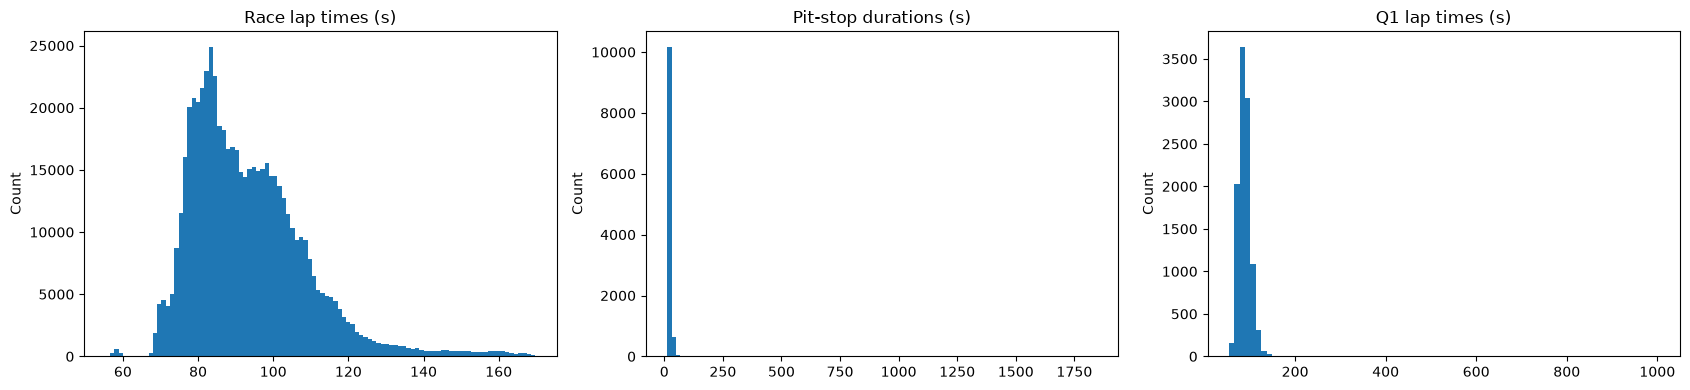

In [70]:
lt = cleaned_tables["lap_times"]["time_sec"].dropna()
ps = cleaned_tables["pit_stops"]["duration_sec"].dropna()
q1 = cleaned_tables["qualifying"]["q1_sec"].dropna()
print(f"Lap time 99.5th percentile: {lt.quantile(0.995):.1f}s | max {lt.max():.1f}s")
print(f"Pit-stop duration 99th percentile: {ps.quantile(0.99):.1f}s | max {ps.max():.1f}s")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(lt[lt <= lt.quantile(0.995)], bins=100); ax[0].set_title("Race lap times (s)")
ax[1].hist(ps[ps <= ps.quantile(0.99)], bins=100); ax[1].set_title("Pit-stop durations (s)")
ax[2].hist(q1, bins=80); ax[2].set_title("Q1 lap times (s)")
for a in ax: a.set_ylabel("Count")
plt.tight_layout(); plt.show()

<a id="h073"></a>
### Step 2.5: Time-of-day columns and a combined race timestamp
<a id="c069"></a>
*Code cell 71* | [Back to contents](#toc)
**Why:** only the date columns were typed; `races.time`, `fp*_time`, `quali_time` and `sprint_time` are still strings. We build `race_datetime` (date + start time, when the time exists) and convert the time columns to `datetime.time`. Failed parses are counted (must be 0). Race start time exists only for part of history, so `race_datetime` is `NaT` elsewhere and `date` + `round` remain the reliable ordering keys.


In [71]:
rc = cleaned_tables["races"]
rc["race_datetime"] = pd.to_datetime(rc["date"].dt.strftime("%Y-%m-%d") + " " + rc["time"].astype("string"), errors="coerce")

time_cols = ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]
for c in time_cols:
    present = rc[c].notna()
    parsed = pd.to_datetime(rc[c].astype("string"), format="%H:%M:%S", errors="coerce")
    print(f"{c:12s} present={int(present.sum()):5d}  failed_to_parse={int((present & parsed.isna()).sum())}")
    rc[c] = parsed.dt.time
cleaned_tables["races"] = rc
print("race_datetime available for", int(rc["race_datetime"].notna().sum()), "of", len(rc), "races")

time         present=  394  failed_to_parse=0
fp1_time     present=   68  failed_to_parse=0
fp2_time     present=   68  failed_to_parse=0
fp3_time     present=   53  failed_to_parse=0
quali_time   present=   68  failed_to_parse=0
sprint_time  present=   15  failed_to_parse=0
race_datetime available for 394 of 1125 races


<a id="h074"></a>
### Step 2.6: Resulting dtypes of `results`
<a id="c070"></a>
*Code cell 72* | [Back to contents](#toc)
With the nullable-integer cast from Step 2.3d, columns such as `position`, `number`, `milliseconds`, `fastestLap` and `rank` show `Int64` (integers that can be missing) instead of `float64`; identifiers are `int64`.


In [72]:
cleaned_tables["results"].dtypes

resultId                int64
raceId                  int64
driverId                int64
constructorId           int64
number                  Int64
grid                    int64
position                Int64
positionText           object
positionOrder           int64
points                float64
laps                    int64
time                   object
milliseconds            Int64
fastestLap              Int64
rank                    Int64
fastestLapTime         object
fastestLapSpeed       float64
statusId                int64
fastestLapTime_sec    float64
dtype: object

<a id="h075"></a>
### Step 2.6a: Resulting dtypes of `races`
<a id="c071"></a>
*Code cell 73* | [Back to contents](#toc)
Dates are `datetime64[ns]`. After Step 2.5 the `*_time` columns hold `datetime.time` values (pandas shows them as `object`, its dtype for Python time objects) and `race_datetime` combines date and start time.


In [73]:
cleaned_tables["races"].dtypes

raceId                    int64
year                      int64
round                     int64
circuitId                 int64
name                     object
date             datetime64[ns]
time                     object
url                      object
fp1_date         datetime64[ns]
fp1_time                 object
fp2_date         datetime64[ns]
fp2_time                 object
fp3_date         datetime64[ns]
fp3_time                 object
quali_date       datetime64[ns]
quali_time               object
sprint_date      datetime64[ns]
sprint_time              object
race_datetime    datetime64[ns]
dtype: object

<a id="h076"></a>
## 3. One row per driver per race


<a id="h077"></a>
### Step 3.1: Work on a copy of `results`
<a id="c072"></a>
*Code cell 74* | [Back to contents](#toc)
`clean_results` is the starting point of the de-duplication. Every row is one entrant-in-a-car (not yet one driver).


In [74]:
clean_results = cleaned_tables["results"].copy()

<a id="h078"></a>
### Step 3.2: Detect duplicated `(raceId, driverId)`
<a id="c073"></a>
*Code cell 75* | [Back to contents](#toc)
`duplicated(subset, keep=False)` marks **all** rows of a duplicated key. Result: **176 rows** belong to **85 duplicated driver-race pairs**; each pair has exactly 2 rows (26,759 - 26,668 = 91 removable rows, see Step 3.5).


In [75]:
duplicate_mask = clean_results.duplicated(
    subset=["raceId", "driverId"],
    keep=False
)

duplicate_results = clean_results[duplicate_mask].copy()

print("Total results rows:", len(clean_results))
print("Rows involved in duplicate groups:", len(duplicate_results))

print(
    "Duplicated (raceId, driverId) pairs:",
    duplicate_results[["raceId", "driverId"]]
    .drop_duplicates()
    .shape[0]
)

Total results rows: 26759
Rows involved in duplicate groups: 176
Duplicated (raceId, driverId) pairs: 85


<a id="h079"></a>
### Step 3.2a: Inspect the duplicated rows
<a id="c074"></a>
*Code cell 76* | [Back to contents](#toc)
Pairs differ in `constructorId`, `grid`, `laps`, `positionOrder` and `statusId`: the same driver appears once per car he drove (shared drives), usually one row with many laps and one with few. Examples: race 780, drivers 475 and 479 both appear in the winning car (positionOrder 1) and in their own retired car.


In [76]:
duplicate_results = duplicate_results.sort_values(
    ["raceId", "driverId"]
)

display(
    duplicate_results[
        [
            "raceId",
            "driverId",
            "constructorId",
            "grid",
            "position",
            "positionOrder",
            "points",
            "laps",
            "statusId"
        ]
    ].head(30)
)

,raceId,driverId,constructorId,grid,position,positionOrder,points,laps,statusId
13188,540,229,54,0,<NA>,26,0.0,0,81
13191,540,229,57,0,<NA>,29,0.0,0,97
17362,717,373,172,1,7,7,0.0,102,60
24298,717,373,172,1,<NA>,12,0.0,54,98
17740,733,465,172,0,<NA>,22,0.0,0,54
17743,733,465,97,0,<NA>,25,0.0,0,54
17961,742,475,102,20,<NA>,19,0.0,56,2
17963,742,475,172,5,<NA>,21,0.0,44,23
18062,745,418,172,11,<NA>,17,0.0,23,6
24297,745,418,172,15,11,11,0.0,92,18


<a id="h080"></a>
### Step 3.2b: Summarise each duplicated pair
<a id="c075"></a>
*Code cell 77* | [Back to contents](#toc)
Records, number of distinct constructors, max laps and best position per pair. **16 pairs involve two different constructors** (driver switched car/team during the race), 69 stay inside the same constructor.


In [77]:
duplicate_pair_summary = (
    duplicate_results
    .groupby(["raceId", "driverId"])
    .agg(
        records=("resultId", "count"),
        constructors=("constructorId", "nunique"),
        max_laps=("laps", "max"),
        min_position_order=("positionOrder", "min")
    )
    .reset_index()
)

display(duplicate_pair_summary.head(20))

,raceId,driverId,records,constructors,max_laps,min_position_order
0,540,229,2,2,0,26
1,717,373,2,1,102,7
2,733,465,2,2,0,22
3,742,475,2,2,56,19
4,745,418,2,1,92,11
5,746,475,2,1,80,3
6,766,541,2,2,0,17
7,770,479,2,1,35,14
8,774,566,2,1,69,4
9,776,581,2,1,98,6


<a id="h081"></a>
### Step 3.2c: Same-constructor vs. different-constructor pairs (69 vs. 16)
<a id="c076"></a>
*Code cell 78* | [Back to contents](#toc)
Matters because the row we keep decides which `constructorId` the driver gets for that race, and constructor form is a key feature.


In [78]:
print(
    "Pairs with multiple constructors:",
    (
        duplicate_pair_summary["constructors"] > 1
    ).sum()
)

print(
    "Pairs with same constructor:",
    (
        duplicate_pair_summary["constructors"] == 1
    ).sum()
)

Pairs with multiple constructors: 16
Pairs with same constructor: 69


<a id="h082"></a>
### Step 3.2d: Attach the season to the duplicated rows, count duplicated rows per season
<a id="c077"></a>
*Code cell 79* | [Back to contents](#toc)
Joins the season onto the duplicated rows (`duplicate_with_year`, reused by the next cells) and counts duplicated **rows** per season. The number of duplicated *pairs* (not rows) is computed in the next cell.


In [79]:
duplicate_with_year = duplicate_results.merge(
    cleaned_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left"
)

duplicate_year_summary = (
    duplicate_with_year
    .groupby("year")
    .agg(duplicate_rows=("resultId", "count"))
    .reset_index()
)

display(duplicate_year_summary)

,year,duplicate_rows
0,1950,8
1,1951,8
2,1952,6
3,1953,30
4,1954,33
5,1955,33
6,1956,24
7,1957,16
8,1958,6
9,1960,2


<a id="h083"></a>
### Step 3.2e: Duplicated pairs per season
<a id="c078"></a>
*Code cell 80* | [Back to contents](#toc)
Duplicates are concentrated in **1953-1956** (12-16 pairs per season), matching the era of shared drives (banned from 1958). Isolated cases in 1960-1964 and a single one in **1978** show that the rule must not be hard-coded to "1950s only".


In [80]:
duplicate_pairs_by_year = (
    duplicate_with_year[
        ["year", "raceId", "driverId"]
    ]
    .drop_duplicates()
    .groupby("year")
    .size()
    .reset_index(name="duplicate_pairs")
)

display(duplicate_pairs_by_year)

,year,duplicate_pairs
0,1950,4
1,1951,4
2,1952,3
3,1953,14
4,1954,16
5,1955,15
6,1956,12
7,1957,8
8,1958,3
9,1960,1


<a id="h084"></a>
### Step 3.3: Test candidate rules: "most laps" vs. "best position"
<a id="c079"></a>
*Code cell 81* | [Back to contents](#toc)
For each pair, compare the row with the **maximum laps** with the row with the **best `positionOrder`**. If both rules choose the same row, the choice is robust. Candidate rules come from the brief ("row for the car he started in" or "best positionOrder").


In [81]:
duplicate_groups = (
    clean_results[
        clean_results.duplicated(
            subset=["raceId", "driverId"],
            keep=False
        )
    ]
    .groupby(["raceId", "driverId"])
)

comparison = []

for (race_id, driver_id), group in duplicate_groups:

    max_laps = group["laps"].max()
    max_laps_rows = group[group["laps"] == max_laps]

    best_position = group["positionOrder"].min()
    max_laps_best_position = max_laps_rows["positionOrder"].min()

    comparison.append({
        "raceId": race_id,
        "driverId": driver_id,
        "records": len(group),
        "max_laps": max_laps,
        "best_position": best_position,
        "position_of_max_laps_record": max_laps_best_position,
        "max_laps_has_best_position": (
            max_laps_best_position == best_position
        )
    })

duplicate_comparison = pd.DataFrame(comparison)

display(duplicate_comparison.head(20))

,raceId,driverId,records,max_laps,best_position,position_of_max_laps_record,max_laps_has_best_position
0,540,229,2,0,26,26,True
1,717,373,2,102,7,7,True
2,733,465,2,0,22,22,True
3,742,475,2,56,19,19,True
4,745,418,2,92,11,11,True
5,746,475,2,80,3,3,True
6,766,541,2,0,17,17,True
7,770,479,2,35,14,14,True
8,774,566,2,69,4,4,True
9,776,581,2,98,6,6,True


<a id="h085"></a>
### Step 3.3a: Result of the comparison
<a id="c080"></a>
*Code cell 82* | [Back to contents](#toc)
In **85 of 85** pairs the max-laps row is also the best-position row. Both brief-suggested rules are therefore equivalent on this data, which supports using max laps as the primary criterion.


In [82]:
total_pairs = len(duplicate_comparison)

matching_pairs = (
    duplicate_comparison["max_laps_has_best_position"]
    .sum()
)

print("Total duplicate pairs:", total_pairs)
print("Max-laps record also has best position:", matching_pairs)
print(
    "Max-laps record does NOT have best position:",
    total_pairs - matching_pairs
)

Total duplicate pairs: 85
Max-laps record also has best position: 85
Max-laps record does NOT have best position: 0


<a id="h086"></a>
### Step 3.3b: Ties on laps
<a id="c081"></a>
*Code cell 83* | [Back to contents](#toc)
3 pairs tie on max laps; all have `laps = 0` (non-starters entered with two constructors). A deterministic tie-break is needed: best `positionOrder`, then smallest `resultId`.


In [83]:
tie_analysis = []

for (race_id, driver_id), group in duplicate_groups:

    max_laps = group["laps"].max()

    max_laps_count = (
        group["laps"] == max_laps
    ).sum()

    tie_analysis.append({
        "raceId": race_id,
        "driverId": driver_id,
        "max_laps": max_laps,
        "records_with_max_laps": max_laps_count
    })

tie_analysis = pd.DataFrame(tie_analysis)

print(
    "Pairs with a tie on maximum laps:",
    (tie_analysis["records_with_max_laps"] > 1).sum()
)

display(
    tie_analysis[
        tie_analysis["records_with_max_laps"] > 1
    ]
)

Pairs with a tie on maximum laps: 3


,raceId,driverId,max_laps,records_with_max_laps
0,540,229,0,2
2,733,465,0,2
6,766,541,0,2


<a id="h087"></a>
### Step 3.3c: Are the duplicates exact copies?
<a id="c082"></a>
*Code cell 84* | [Back to contents](#toc)
`nunique` per column shows 2 distinct values in `grid`, `positionOrder`, `laps`, `statusId`..., so rows are **not** exact duplicates. A naive `drop_duplicates()` would remove nothing; a rule on the key `(raceId, driverId)` is required.


In [84]:
duplicate_columns = [
    "raceId",
    "driverId",
    "constructorId",
    "grid",
    "position",
    "positionOrder",
    "points",
    "laps",
    "statusId"
]

exact_duplicate_groups = (
    duplicate_results
    .groupby(["raceId", "driverId"])[duplicate_columns]
    .nunique()
)

display(exact_duplicate_groups.head(20))

,,raceId,driverId,constructorId,grid,position,positionOrder,points,laps,statusId
raceId,driverId,,,,,,,,,
540,229,1,1,2,1,0,2,1,1,2
717,373,1,1,1,1,1,2,1,2,2
733,465,1,1,2,1,0,2,1,1,1
742,475,1,1,2,2,0,2,1,2,2
745,418,1,1,1,2,1,2,1,2,2
746,475,1,1,1,2,1,2,1,2,2
766,541,1,1,2,1,0,2,1,1,1
770,479,1,1,1,2,0,2,1,2,1
774,566,1,1,1,2,1,2,1,2,2


<a id="h088"></a>
### Step 3.4: Define the rule by sorting
<a id="c083"></a>
*Code cell 85* | [Back to contents](#toc)
Sort by `raceId`, `driverId`, then `laps` **descending**, `positionOrder` ascending, `resultId` ascending. **Rule:** keep, for each driver in each race, the row where he completed the most laps (the car he really drove); ties go to the best finishing position, then to the lowest `resultId` (deterministic). **Why:** it follows the brief's suggestions, it is verified to agree with "best positionOrder" in 85/85 cases, it needs no era-specific code and is reproducible.


In [85]:
clean_results_sorted = clean_results.sort_values(
    by=[
        "raceId",
        "driverId",
        "laps",
        "positionOrder",
        "resultId"
    ],
    ascending=[
        True,
        True,
        False,   # maximum laps first
        True,    # best position first
        True     # smallest resultId first
    ]
)

<a id="h089"></a>
### Step 3.5: Apply the rule
<a id="c084"></a>
*Code cell 86* | [Back to contents](#toc)
`drop_duplicates(subset=["raceId","driverId"], keep="first")` on the sorted table: 26,759 to **26,668** rows (91 removed, 0.34%).


In [86]:
clean_results_unique = (
    clean_results_sorted
    .drop_duplicates(
        subset=["raceId", "driverId"],
        keep="first"
    )
    .copy()
)

print("Rows before duplicate resolution:", len(clean_results))
print("Rows after duplicate resolution:", len(clean_results_unique))
print(
    "Rows removed:",
    len(clean_results) - len(clean_results_unique)
)

Rows before duplicate resolution: 26759
Rows after duplicate resolution: 26668
Rows removed: 91


<a id="h090"></a>
### Step 3.5a: Audit trail of the rows removed by the duplicate rule
<a id="c085"></a>
*Code cell 87* | [Back to contents](#toc)
**Why:** "Choose a rule, apply it and explain why" also means being able to show **exactly what was dropped**. We keep the removed rows in `dropped_duplicates`, summarise them by season, and flag the surviving rows with `had_duplicate_rows`. We specifically list removed rows with `positionOrder <= 3`, because removing a podium row can change the target.


In [87]:
dropped_duplicates = (clean_results.loc[~clean_results["resultId"].isin(clean_results_unique["resultId"])]
                      .merge(races[["raceId", "year"]], on="raceId", how="left"))
print("Rows dropped:", len(dropped_duplicates))
display(dropped_duplicates.groupby("year").size().rename("rows_dropped").to_frame().T)

kept_idx = pd.MultiIndex.from_frame(clean_results_unique[["raceId", "driverId"]])
dup_idx = pd.MultiIndex.from_frame(dropped_duplicates[["raceId", "driverId"]].drop_duplicates())
clean_results_unique["had_duplicate_rows"] = kept_idx.isin(dup_idx)
print("Surviving rows flagged as 'had_duplicate_rows':", int(clean_results_unique["had_duplicate_rows"].sum()))

print("Dropped rows that had positionOrder <= 3 (podium rows removed):")
display(dropped_duplicates.loc[dropped_duplicates["positionOrder"] <= 3,
        ["raceId", "year", "driverId", "constructorId", "grid", "position", "positionOrder", "laps", "statusId"]])

Rows dropped: 91


year,1950,1951,1952,1953,1954,1955,1956,1957,1958,1960,1961,1962,1964,1978
rows_dropped,4,4,3,16,17,18,12,8,3,1,2,1,1,1


Surviving rows flagged as 'had_duplicate_rows': 85
Dropped rows that had positionOrder <= 3 (podium rows removed):


,raceId,year,driverId,constructorId,grid,position,positionOrder,laps,statusId
26,792,1955,642,6,5,3,3,94,12
82,792,1955,427,6,5,3,3,94,12


<a id="h091"></a>
### Step 3.5b: Verify no duplicated key remains (0).
<a id="c086"></a>
*Code cell 88* | [Back to contents](#toc)


In [88]:
remaining_duplicates = (
    clean_results_unique
    .duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
    .sum()
)

print(
    "Remaining duplicated (raceId, driverId) rows:",
    remaining_duplicates
)

Remaining duplicated (raceId, driverId) rows: 0


<a id="h092"></a>
### Step 3.5c: Verify uniqueness a second way
<a id="c087"></a>
*Code cell 89* | [Back to contents](#toc)
Unique `(raceId, driverId)` pairs = number of rows = 26,668, so the grain "one row per driver per race" now holds.


In [89]:
unique_driver_race_pairs = (
    clean_results_unique[
        ["raceId", "driverId"]
    ]
    .drop_duplicates()
    .shape[0]
)

print("Unique driver-race pairs:", unique_driver_race_pairs)
print("Clean results rows:", len(clean_results_unique))

Unique driver-race pairs: 26668
Clean results rows: 26668


<a id="h093"></a>
### Step 3.5d: Replace `results` in `cleaned_tables`
<a id="c088"></a>
*Code cell 90* | [Back to contents](#toc)
Only the cleaned copy is updated; `tables["results"]` (raw) keeps its 26,759 rows.


In [90]:
cleaned_tables["results"] = clean_results_unique.copy()

print(
    "Updated cleaned_tables['results'] with duplicate-resolved results."
)

Updated cleaned_tables['results'] with duplicate-resolved results.


<a id="h094"></a>
### Step 3.5e: Duplicate-resolution impact table
<a id="c089"></a>
*Code cell 91* | [Back to contents](#toc)
Compact record of original rows, rows in duplicate groups, pairs, rows removed and remaining duplicates (0). Reusable in the report.


In [91]:
duplicate_impact = pd.DataFrame({
    "Metric": [
        "Original result rows",
        "Rows involved in duplicate groups",
        "Duplicated driver-race pairs",
        "Rows removed",
        "Final result rows",
        "Remaining duplicate pairs"
    ],
    "Value": [
        len(clean_results),
        len(duplicate_results),
        duplicate_results[
            ["raceId", "driverId"]
        ].drop_duplicates().shape[0],
        len(clean_results) - len(clean_results_unique),
        len(clean_results_unique),
        (
            clean_results_unique
            .duplicated(
                subset=["raceId", "driverId"]
            )
            .sum()
        )
    ]
})

display(duplicate_impact)

,Metric,Value
0,Original result rows,26759
1,Rows involved in duplicate groups,176
2,Duplicated driver-race pairs,85
3,Rows removed,91
4,Final result rows,26668
5,Remaining duplicate pairs,0


<a id="h095"></a>
### Step 3.6: Sensitivity of the duplicate rule (does the choice matter?)
<a id="c090"></a>
*Code cell 92* | [Back to contents](#toc)
**Why:** a rule is only well justified if we know what the alternatives would have done. For the 85 duplicated pairs we compare the chosen rule (max laps, then best `positionOrder`, then lowest `resultId`) with: best `positionOrder` only; "car he started in" (non-zero grid first, then max laps); first `resultId`; and a label rule "podium if **any** of his rows is a podium".
**How to read:** `different row chosen` counts pairs where the alternative would keep another row; `different podium label` is what really matters for the target; `different constructor` matters for constructor-form features.


In [92]:
key = ["raceId", "driverId"]
affected = dropped_duplicates[key].drop_duplicates()
cols = key + ["resultId", "positionOrder", "constructorId"]
chosen = clean_results_unique[cols]

alts = {
    "best positionOrder only": clean_results.sort_values(key + ["positionOrder", "resultId"]).drop_duplicates(key),
    "started car (grid>0) then max laps": (clean_results.assign(_nogrid=clean_results["grid"].eq(0))
        .sort_values(key + ["_nogrid", "laps", "resultId"], ascending=[True, True, True, False, True])
        .drop_duplicates(key)),
    "first resultId": clean_results.sort_values(key + ["resultId"]).drop_duplicates(key),
}
rows = []
for name, alt in alts.items():
    m = chosen.merge(alt[cols], on=key, suffixes=("", "_alt")).merge(affected, on=key)
    rows.append({"Alternative": name, "affected_pairs": len(m),
                 "different row chosen": int((m["resultId"] != m["resultId_alt"]).sum()),
                 "different podium label": int(((m["positionOrder"] <= 3) != (m["positionOrder_alt"] <= 3)).sum()),
                 "different constructor": int((m["constructorId"] != m["constructorId_alt"]).sum())})

any_podium = (clean_results[clean_results.duplicated(key, keep=False)]
              .assign(p=lambda d: d["positionOrder"] <= 3).groupby(key)["p"].max().rename("any_podium").reset_index())
m = chosen.merge(any_podium, on=key)
rows.append({"Alternative": "label = podium if ANY row is podium", "affected_pairs": len(m),
             "different row chosen": np.nan,
             "different podium label": int(((m["positionOrder"] <= 3) != m["any_podium"]).sum()),
             "different constructor": np.nan})
display(pd.DataFrame(rows))

,Alternative,affected_pairs,different row chosen,different podium label,different constructor
0,best positionOrder only,85,0.0,0,0.0
1,started car (grid>0) then max laps,85,0.0,0,0.0
2,first resultId,85,64.0,16,8.0
3,label = podium if ANY row is podium,85,NaN,0,NaN


<a id="h096"></a>
### Step 3.7: Podium rows per race before vs. after de-duplication
<a id="c091"></a>
*Code cell 93* | [Back to contents](#toc)
**Why:** in a clean race exactly 3 rows have `positionOrder <= 3`. Shared drives break this in both directions: a driver holding two podium rows loses one when we deduplicate (so the race ends with fewer than 3), and a car shared by two drivers gives *both* the same classification (so a race can have more than 3). De-duplication removes 2 podium rows (3,397 to 3,395, see Step 5.1); this cell finds the affected races so the effect on the target is documented rather than hidden.


,before,after
podium rows in the race,,
3,1107,1107
4,16,16
5,1,2
7,1,0


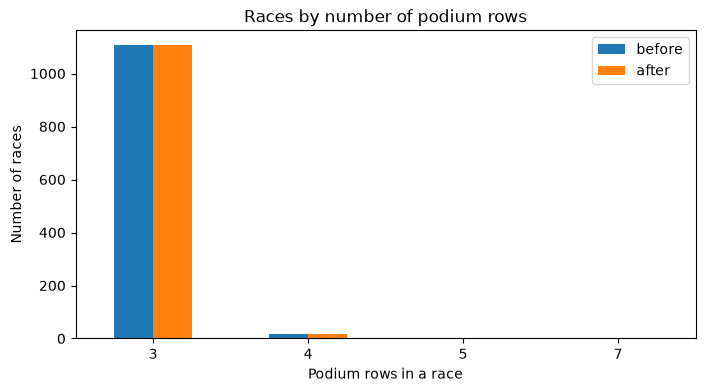

Races whose podium-row count is not exactly 3: 18


,raceId,before,after,year,name
0,746,4,4,1960,Argentine Grand Prix
1,780,4,4,1957,British Grand Prix
2,784,4,4,1956,Argentine Grand Prix
3,785,4,4,1956,Monaco Grand Prix
4,787,4,4,1956,Belgian Grand Prix
5,789,4,4,1956,British Grand Prix
6,791,4,4,1956,Italian Grand Prix
7,792,7,5,1955,Argentine Grand Prix
8,793,4,4,1955,Monaco Grand Prix
9,794,4,4,1955,Indianapolis 500


In [93]:
def podiums_per_race(df):
    return (df["positionOrder"] <= 3).groupby(df["raceId"]).sum()

before_pr = podiums_per_race(tables["results"])
after_pr = podiums_per_race(cleaned_tables["results"])
pr = pd.DataFrame({"before": before_pr, "after": after_pr})

display(pd.DataFrame({"before": before_pr.value_counts(), "after": after_pr.value_counts()}).fillna(0).astype(int)
        .rename_axis("podium rows in the race").sort_index())

pr.apply(pd.Series.value_counts).fillna(0).plot(kind="bar", figsize=(8, 4))
plt.xlabel("Podium rows in a race"); plt.ylabel("Number of races"); plt.title("Races by number of podium rows"); plt.xticks(rotation=0); plt.show()

odd = (pr[(pr["before"] != 3) | (pr["after"] != 3)].reset_index()
       .merge(races[["raceId", "year", "name"]], on="raceId", how="left"))
print("Races whose podium-row count is not exactly 3:", len(odd))
display(odd.head(30))

<a id="h097"></a>
## 4. Integrity: primary keys and foreign keys


<a id="h098"></a>
### Step 4.1: Declare primary keys of the main tables
<a id="c092"></a>
*Code cell 94* | [Back to contents](#toc)
`circuitId`, `constructorId`, `driverId`, `raceId`, `resultId`, `qualifyId`, `statusId`, `year` (seasons). Not covered: surrogate keys of standings / constructor_results / sprint_results and the composite keys; added in Step 4.3.


In [94]:
primary_keys = {
    "circuits": "circuitId",
    "constructors": "constructorId",
    "drivers": "driverId",
    "races": "raceId",
    "results": "resultId",
    "qualifying": "qualifyId",
    "status": "statusId",
    "seasons": "year"
}

<a id="h099"></a>
### Step 4.1a: Audit primary keys: not null and unique
<a id="c093"></a>
*Code cell 95* | [Back to contents](#toc)
For each key: missing count, duplicate count and unique count. All 8 keys are valid (0 missing, 0 duplicates).


In [95]:
pk_audit = []

for table_name, pk in primary_keys.items():

    df = cleaned_tables[table_name]

    missing_count = df[pk].isna().sum()
    duplicate_count = df[pk].duplicated().sum()
    unique_count = df[pk].nunique()

    pk_audit.append({
        "Table": table_name,
        "Primary_Key": pk,
        "Rows": len(df),
        "Missing_PK": missing_count,
        "Duplicate_PK": duplicate_count,
        "Unique_PK": unique_count,
        "Valid": (
            missing_count == 0 and
            duplicate_count == 0
        )
    })

pk_audit = pd.DataFrame(pk_audit)

display(pk_audit)

,Table,Primary_Key,Rows,Missing_PK,Duplicate_PK,Unique_PK,Valid
0,circuits,circuitId,77,0,0,77,True
1,constructors,constructorId,212,0,0,212,True
2,drivers,driverId,861,0,0,861,True
3,races,raceId,1125,0,0,1125,True
4,results,resultId,26668,0,0,26668,True
5,qualifying,qualifyId,10494,0,0,10494,True
6,status,statusId,139,0,0,139,True
7,seasons,year,75,0,0,75,True


<a id="h100"></a>
### Step 4.1b: Report invalid primary keys (none).
<a id="c094"></a>
*Code cell 96* | [Back to contents](#toc)


In [96]:
invalid_pks = pk_audit[
    pk_audit["Valid"] == False
]

if len(invalid_pks) == 0:
    print("All primary keys are valid.")
else:
    print("Invalid primary keys found:")
    display(invalid_pks)

All primary keys are valid.


<a id="h101"></a>
### Step 4.1c: Explicit check of `results.resultId`
<a id="c095"></a>
*Code cell 97* | [Back to contents](#toc)
The table that was modified by the de-duplication still has 26,668 unique, non-null `resultId`s, i.e. the cleaning did not break the key.


In [97]:
results_pk_check = cleaned_tables["results"]["resultId"]

print("Results rows:", len(results_pk_check))
print("Unique resultIds:", results_pk_check.nunique())
print("Missing resultIds:", results_pk_check.isna().sum())

Results rows: 26668
Unique resultIds: 26668
Missing resultIds: 0


<a id="h102"></a>
### Step 4.2: Declare foreign-key relationships
<a id="c096"></a>
*Code cell 98* | [Back to contents](#toc)
22 child-to-parent relationships (`results` to races/drivers/constructors/status, `qualifying`, `races` to circuits, standings, lap times, pit stops, sprint results...).


In [98]:
foreign_keys = [
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("races", "circuitId", "circuits", "circuitId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId")
]

<a id="h103"></a>
### Step 4.2a: Audit foreign keys
<a id="c097"></a>
*Code cell 99* | [Back to contents](#toc)
For each FK, count values that do not exist in the parent table. **0 invalid references in all 22.** Nulls are skipped by `dropna()`, so null FKs are checked separately in Step 4.3.


In [99]:
fk_audit = []

for (
    child_table,
    child_column,
    parent_table,
    parent_column
) in foreign_keys:

    child_df = cleaned_tables[child_table]
    parent_df = cleaned_tables[parent_table]

    parent_values = set(
        parent_df[parent_column].dropna()
    )

    child_values = child_df[child_column].dropna()

    invalid_mask = ~child_values.isin(parent_values)

    invalid_count = invalid_mask.sum()

    fk_audit.append({
        "Child_Table": child_table,
        "Foreign_Key": child_column,
        "Parent_Table": parent_table,
        "Parent_Key": parent_column,
        "Invalid_References": invalid_count,
        "Valid": invalid_count == 0
    })

fk_audit = pd.DataFrame(fk_audit)

display(fk_audit)

,Child_Table,Foreign_Key,Parent_Table,Parent_Key,Invalid_References,Valid
0,results,raceId,races,raceId,0,True
1,results,driverId,drivers,driverId,0,True
2,results,constructorId,constructors,constructorId,0,True
3,results,statusId,status,statusId,0,True
4,qualifying,raceId,races,raceId,0,True
5,qualifying,driverId,drivers,driverId,0,True
6,qualifying,constructorId,constructors,constructorId,0,True
7,races,circuitId,circuits,circuitId,0,True
8,driver_standings,raceId,races,raceId,0,True
9,driver_standings,driverId,drivers,driverId,0,True


<a id="h104"></a>
### Step 4.2b: Report invalid foreign keys (none).
<a id="c098"></a>
*Code cell 100* | [Back to contents](#toc)


In [100]:
invalid_fks = fk_audit[
    fk_audit["Valid"] == False
]

if len(invalid_fks) == 0:
    print("All foreign key relationships are valid.")
else:
    print("Invalid foreign key relationships found:")
    display(invalid_fks)

All foreign key relationships are valid.


<a id="h105"></a>
### Step 4.2c: Foreign-key summary: 22 checked, 22 valid, 0 invalid.
<a id="c099"></a>
*Code cell 101* | [Back to contents](#toc)


In [101]:
print("Total foreign key relationships checked:", len(fk_audit))
print(
    "Valid relationships:",
    fk_audit["Valid"].sum()
)
print(
    "Invalid relationships:",
    (~fk_audit["Valid"]).sum()
)

Total foreign key relationships checked: 22
Valid relationships: 22
Invalid relationships: 0


<a id="h106"></a>
### Step 4.3: Extended key audit (composite keys, remaining tables, null FKs, orphans)
<a id="c100"></a>
*Code cell 102* | [Back to contents](#toc)
**Why:** the audit above covers 8 primary keys and 22 foreign keys, but not (a) the **surrogate keys** of `constructor_results`, `constructor_standings`, `driver_standings`, `sprint_results`; (b) the **composite keys** that define each table's grain, e.g. `(raceId, driverId)` in `qualifying`, `(raceId, driverId, lap)` in `lap_times`, `(raceId, driverId, stop)` in `pit_stops`, `(year, round)` in `races`; (c) FK columns that are **null**, which the earlier check silently skips with `dropna()`; (d) the FK `races.year -> seasons.year`; (e) qualifying rows with no matching result row, and races with no results.
**Why it matters:** standings and qualifying are joined on `(raceId, driverId)` when features are built, so duplicates there would silently multiply rows.


In [102]:
surrogate_pks = {"constructor_results": "constructorResultsId", "constructor_standings": "constructorStandingsId",
                 "driver_standings": "driverStandingsId", "sprint_results": "resultId"}
composite_keys = {"results": ["raceId", "driverId"], "qualifying": ["raceId", "driverId"],
                  "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
                  "driver_standings": ["raceId", "driverId"], "constructor_standings": ["raceId", "constructorId"],
                  "constructor_results": ["raceId", "constructorId"], "sprint_results": ["raceId", "driverId"],
                  "races": ["year", "round"]}
key_rows = []
for t, pk in surrogate_pks.items():
    df = cleaned_tables[t]
    key_rows.append({"Table": t, "Key": pk, "Type": "surrogate PK", "Null": int(df[pk].isna().sum()),
                     "Duplicated_rows": int(df[pk].duplicated(keep=False).sum())})
for t, cols in composite_keys.items():
    df = cleaned_tables[t]
    key_rows.append({"Table": t, "Key": "+".join(cols), "Type": "composite (grain)", "Null": int(df[cols].isna().any(axis=1).sum()),
                     "Duplicated_rows": int(df.duplicated(cols, keep=False).sum())})
display(pd.DataFrame(key_rows))

null_fk = pd.DataFrame([{"Child": c, "FK": col, "Null_values": int(cleaned_tables[c][col].isna().sum())}
                        for c, col, _, _ in foreign_keys])
print("Foreign keys containing nulls:"); display(null_fk[null_fk["Null_values"] > 0] if (null_fk["Null_values"] > 0).any() else "none")

print("races.year not in seasons.year:", int((~cleaned_tables["races"]["year"].isin(cleaned_tables["seasons"]["year"])).sum()))
q_pairs = pd.MultiIndex.from_frame(cleaned_tables["qualifying"][["raceId", "driverId"]])
r_pairs = pd.MultiIndex.from_frame(cleaned_tables["results"][["raceId", "driverId"]])
print("qualifying (raceId, driverId) with no result row:", int((~q_pairs.isin(r_pairs)).sum()))
print("races without any result row:", int((~cleaned_tables["races"]["raceId"].isin(cleaned_tables["results"]["raceId"])).sum()))

,Table,Key,Type,Null,Duplicated_rows
0,constructor_results,constructorResultsId,surrogate PK,0,0
1,constructor_standings,constructorStandingsId,surrogate PK,0,0
2,driver_standings,driverStandingsId,surrogate PK,0,0
3,sprint_results,resultId,surrogate PK,0,0
4,results,raceId+driverId,composite (grain),0,0
5,qualifying,raceId+driverId,composite (grain),0,0
6,lap_times,raceId+driverId+lap,composite (grain),0,0
7,pit_stops,raceId+driverId+stop,composite (grain),0,0
8,driver_standings,raceId+driverId,composite (grain),0,0
9,constructor_standings,raceId+constructorId,composite (grain),0,0


Foreign keys containing nulls:


'none'

races.year not in seasons.year: 0
qualifying (raceId, driverId) with no result row: 0
races without any result row: 0


<a id="h107"></a>
### Step 4.4: Domain / consistency validation
<a id="c101"></a>
*Code cell 103* | [Back to contents](#toc)
**Why:** key checks prove the tables join, not that the values make sense. This cell tests rules that must hold in Formula 1 data: no negative grid/points/laps, `positionOrder >= 1`, a classified `position` equals `positionOrder`, seasons inside 1950-2024, `(year, round)` unique, practice <= qualifying <= race dates in order, and driver age at race date in a plausible range. Each check reports the number of violations so problems are surfaced by code, not by eye.


In [103]:
r, rc, d = cleaned_tables["results"], cleaned_tables["races"], cleaned_tables["drivers"]

age_df = (r[["raceId", "driverId"]].merge(rc[["raceId", "date"]], on="raceId").merge(d[["driverId", "dob"]], on="driverId"))
age = (age_df["date"] - age_df["dob"]).dt.days / 365.25

seq = ["fp1_date", "fp2_date", "fp3_date", "quali_date", "date"]
order_violations = 0
for a, b in zip(seq, seq[1:]):
    both = rc[a].notna() & rc[b].notna()
    order_violations += int((rc.loc[both, a] > rc.loc[both, b]).sum())

pos_mismatch = (r["position"] != r["positionOrder"]).fillna(False)
checks = pd.Series({
    "grid < 0": int((r["grid"] < 0).sum()),
    "positionOrder < 1": int((r["positionOrder"] < 1).sum()),
    "points < 0": int((r["points"] < 0).sum()),
    "laps < 0": int((r["laps"] < 0).sum()),
    "classified position != positionOrder": int(pos_mismatch.sum()),
    "season outside 1950-2024": int((~rc["year"].between(1950, 2024)).sum()),
    "duplicate (year, round)": int(rc.duplicated(["year", "round"]).sum()),
    "race date order violated (fp1<=fp2<=fp3<=quali<=race)": order_violations,
    "driver age at race < 16 or > 65 or unknown": int(((age < 16) | (age > 65) | age.isna()).sum()),
}, name="violations")
display(checks.to_frame())
print(f"Driver age at race: min {age.min():.1f}, max {age.max():.1f} years")

,violations
grid < 0,0
positionOrder < 1,0
points < 0,0
laps < 0,0
classified position != positionOrder,13
season outside 1950-2024,0
"duplicate (year, round)",0
race date order violated (fp1<=fp2<=fp3<=quali<=race),0
driver age at race < 16 or > 65 or unknown,0


Driver age at race: min 17.5, max 58.8 years


<a id="h108"></a>
### Step 4.5: Re-check that no `\N` sentinel remains in any cleaned table (0).
<a id="c102"></a>
*Code cell 104* | [Back to contents](#toc)


In [104]:
remaining_sentinels = []

for name, df in cleaned_tables.items():
    for column in df.columns:

        count = (df[column].astype(str) == r"\N").sum()

        if count > 0:
            remaining_sentinels.append({
                "Table": name,
                "Column": column,
                "Count": count
            })

if remaining_sentinels:
    display(pd.DataFrame(remaining_sentinels))
else:
    print("No remaining \\N sentinel values found.")

No remaining \N sentinel values found.


<a id="h109"></a>
### Step 4.5a: Re-check the grain of the final `results`
<a id="c103"></a>
*Code cell 105* | [Back to contents](#toc)
26,668 rows and 0 duplicated `(raceId, driverId)`.


In [105]:
final_results = cleaned_tables["results"]

duplicate_count = final_results.duplicated(
    subset=["raceId", "driverId"]
).sum()

print("Results rows:", len(final_results))
print("Duplicate race-driver rows:", duplicate_count)

Results rows: 26668
Duplicate race-driver rows: 0


<a id="h110"></a>
### Step 4.5b: Final primary-key audit after all cleaning steps (all valid).
<a id="c104"></a>
*Code cell 106* | [Back to contents](#toc)


In [106]:
final_pk_audit = []

for table_name, pk in primary_keys.items():

    df = cleaned_tables[table_name]

    final_pk_audit.append({
        "Table": table_name,
        "Primary_Key": pk,
        "Missing": df[pk].isna().sum(),
        "Duplicates": df[pk].duplicated().sum(),
        "Unique": df[pk].nunique()
    })

final_pk_audit = pd.DataFrame(final_pk_audit)

display(final_pk_audit)

,Table,Primary_Key,Missing,Duplicates,Unique
0,circuits,circuitId,0,0,77
1,constructors,constructorId,0,0,212
2,drivers,driverId,0,0,861
3,races,raceId,0,0,1125
4,results,resultId,0,0,26668
5,qualifying,qualifyId,0,0,10494
6,status,statusId,0,0,139
7,seasons,year,0,0,75


<a id="h111"></a>
### Step 4.5c: Final foreign-key audit after all cleaning steps (0 invalid in every relationship).
<a id="c105"></a>
*Code cell 107* | [Back to contents](#toc)


In [107]:
final_fk_audit = []

for (
    child_table,
    child_column,
    parent_table,
    parent_column
) in foreign_keys:

    child_df = cleaned_tables[child_table]
    parent_df = cleaned_tables[parent_table]

    parent_values = set(
        parent_df[parent_column].dropna()
    )

    child_values = child_df[child_column].dropna()

    invalid_count = (
        ~child_values.isin(parent_values)
    ).sum()

    final_fk_audit.append({
        "Child_Table": child_table,
        "Foreign_Key": child_column,
        "Parent_Table": parent_table,
        "Parent_Key": parent_column,
        "Invalid_References": invalid_count
    })

final_fk_audit = pd.DataFrame(final_fk_audit)

display(final_fk_audit)

,Child_Table,Foreign_Key,Parent_Table,Parent_Key,Invalid_References
0,results,raceId,races,raceId,0
1,results,driverId,drivers,driverId,0
2,results,constructorId,constructors,constructorId,0
3,results,statusId,status,statusId,0
4,qualifying,raceId,races,raceId,0
5,qualifying,driverId,drivers,driverId,0
6,qualifying,constructorId,constructors,constructorId,0
7,races,circuitId,circuits,circuitId,0
8,driver_standings,raceId,races,raceId,0
9,driver_standings,driverId,drivers,driverId,0


<a id="h112"></a>
### Step 4.5d: Rows before vs. after per table
<a id="c106"></a>
*Code cell 108* | [Back to contents](#toc)
Only `results` loses rows (91). All other tables keep every row: the cleaning is minimal and targeted.


In [108]:
cleaning_summary = []

for name in tables:

    raw_rows = len(tables[name])
    clean_rows = len(cleaned_tables[name])

    cleaning_summary.append({
        "Table": name,
        "Raw_Rows": raw_rows,
        "Clean_Rows": clean_rows,
        "Rows_Removed": raw_rows - clean_rows
    })

cleaning_summary = pd.DataFrame(cleaning_summary)

display(cleaning_summary)

,Table,Raw_Rows,Clean_Rows,Rows_Removed
0,circuits,77,77,0
1,constructors,212,212,0
2,constructor_results,12625,12625,0
3,constructor_standings,13391,13391,0
4,drivers,861,861,0
5,driver_standings,34863,34863,0
6,lap_times,589081,589081,0
7,pit_stops,11371,11371,0
8,qualifying,10494,10494,0
9,races,1125,1125,0


<a id="h113"></a>
### Step 4.5e: Cleaning report: one-line verification of the four required checks
<a id="c107"></a>
*Code cell 109* | [Back to contents](#toc)
Remaining sentinels, duplicated pairs, invalid PKs, invalid FKs: all 0.


In [109]:
cleaning_report = pd.DataFrame({
    "Check": [
        "Remaining \\N sentinels",
        "Duplicate (raceId, driverId) pairs",
        "Invalid primary keys",
        "Invalid foreign keys"
    ],
    "Result": [
        sum(
            (df.astype(str) == r"\N").sum().sum()
            for df in cleaned_tables.values()
        ),
        cleaned_tables["results"]
        .duplicated(["raceId", "driverId"])
        .sum(),
        (~final_pk_audit["Missing"].eq(0) |
         ~final_pk_audit["Duplicates"].eq(0)).sum(),
        final_fk_audit["Invalid_References"].sum()
    ]
})

display(cleaning_report)

,Check,Result
0,Remaining \N sentinels,0
1,"Duplicate (raceId, driverId) pairs",0
2,Invalid primary keys,0
3,Invalid foreign keys,0


<a id="h114"></a>
## 5. EDA after cleaning: impact of the cleaning


<a id="h115"></a>
### Step 5.1: Before/after comparison of the target
<a id="c108"></a>
*Code cell 110* | [Back to contents](#toc)
Podium counts: 3,397 to **3,395**. **Two podium rows were removed** by the de-duplication, so some races now have fewer than 3 podium rows; this is analysed in Step 3.7.


In [110]:
# Create temporary copies so we do not modify the original tables

raw_results_eda = tables["results"].copy()
clean_results_eda = cleaned_tables["results"].copy()

# Create podium target
raw_results_eda["podium"] = (
    pd.to_numeric(raw_results_eda["positionOrder"], errors="coerce") <= 3
).astype(int)

clean_results_eda["podium"] = (
    pd.to_numeric(clean_results_eda["positionOrder"], errors="coerce") <= 3
).astype(int)

# Count podium vs non-podium
podium_comparison = pd.DataFrame({
    "Before Cleaning": raw_results_eda["podium"].value_counts().sort_index(),
    "After Cleaning": clean_results_eda["podium"].value_counts().sort_index()
})

podium_comparison.index = ["Non-Podium", "Podium"]

display(podium_comparison)

,Before Cleaning,After Cleaning
Non-Podium,23362,23273
Podium,3397,3395


<a id="h116"></a>
### Step 5.1a: Podium rate before vs. after
<a id="c109"></a>
*Code cell 111* | [Back to contents](#toc)
12.69% to 12.73% (+0.04 percentage points): the cleaning barely changes the class balance, so it does not distort the target.


In [111]:
podium_percentage = pd.DataFrame({
    "Before Cleaning": raw_results_eda["podium"].value_counts(normalize=True).sort_index() * 100,
    "After Cleaning": clean_results_eda["podium"].value_counts(normalize=True).sort_index() * 100
})

podium_percentage.index = ["Non-Podium", "Podium"]

podium_percentage = podium_percentage.round(2)

display(podium_percentage)

,Before Cleaning,After Cleaning
Non-Podium,87.31,87.27
Podium,12.69,12.73


<a id="h117"></a>
### Step 5.1b: Plot: podium distribution before vs. after.
<a id="c110"></a>
*Code cell 112* | [Back to contents](#toc)


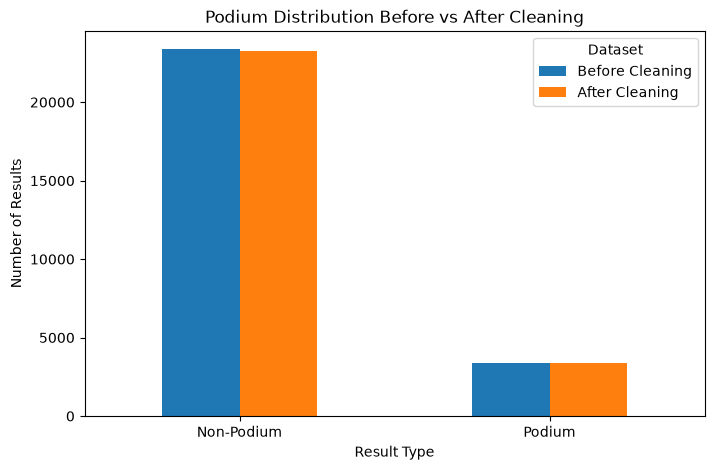

In [112]:
plot_data = pd.DataFrame({
    "Before Cleaning": raw_results_eda["podium"].value_counts().sort_index(),
    "After Cleaning": clean_results_eda["podium"].value_counts().sort_index()
})

plot_data.index = ["Non-Podium", "Podium"]

plot_data.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Result Type")
plt.ylabel("Number of Results")
plt.title("Podium Distribution Before vs After Cleaning")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.show()

<a id="h118"></a>
### Step 5.2: Attach status names to raw and cleaned `results`.
<a id="c111"></a>
*Code cell 113* | [Back to contents](#toc)


In [113]:
raw_status = tables["results"].merge(
    tables["status"][["statusId", "status"]],
    on="statusId",
    how="left"
)

clean_status = cleaned_tables["results"].merge(
    cleaned_tables["status"][["statusId", "status"]],
    on="statusId",
    how="left"
)

<a id="h119"></a>
### Step 5.2a: Race-status counts before vs. after
<a id="c112"></a>
*Code cell 114* | [Back to contents](#toc)
Removed rows are mostly retirement reasons (Engine -20, Accident -9, Gearbox -6, Spun off -5...), which is the expected signature of the *second* row of a shared drive (a car that stopped). "Finished" is unchanged (0 removed).


In [114]:
raw_status_counts = raw_status["status"].value_counts()
clean_status_counts = clean_status["status"].value_counts()

status_comparison = pd.DataFrame({
    "Before Cleaning": raw_status_counts,
    "After Cleaning": clean_status_counts
}).fillna(0)

status_comparison["Rows Removed"] = (
    status_comparison["Before Cleaning"]
    - status_comparison["After Cleaning"]
)

status_comparison = status_comparison.sort_values(
    "Before Cleaning",
    ascending=False
)

display(status_comparison.head(20))

,Before Cleaning,After Cleaning,Rows Removed
status,,,
Finished,7674,7674,0
+1 Lap,4037,4036,1
Engine,2026,2006,20
+2 Laps,1613,1611,2
Accident,1062,1053,9
Did not qualify,1025,1024,1
Collision,854,854,0
Gearbox,810,804,6
Spun off,795,790,5


<a id="h120"></a>
### Step 5.2b: Plot: status distribution before vs. after.
<a id="c113"></a>
*Code cell 115* | [Back to contents](#toc)


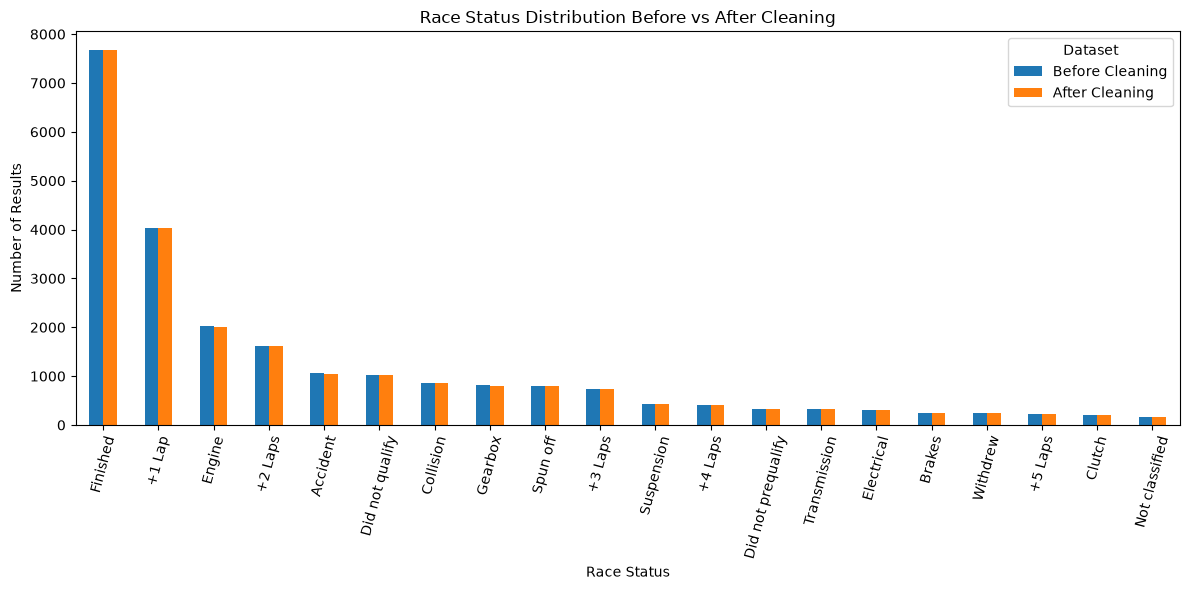

In [115]:
top_statuses = status_comparison.head(20)

top_statuses[["Before Cleaning", "After Cleaning"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Race Status")
plt.ylabel("Number of Results")
plt.title("Race Status Distribution Before vs After Cleaning")
plt.xticks(rotation=75)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

<a id="h121"></a>
### Step 5.2c: Only the statuses that changed.
<a id="c114"></a>
*Code cell 116* | [Back to contents](#toc)


In [116]:
affected_statuses = status_comparison[
    status_comparison["Rows Removed"] != 0
]

display(affected_statuses)

,Before Cleaning,After Cleaning,Rows Removed
status,,,
+1 Lap,4037,4036,1
Engine,2026,2006,20
+2 Laps,1613,1611,2
Accident,1062,1053,9
Did not qualify,1025,1024,1
Gearbox,810,804,6
Spun off,795,790,5
Suspension,431,427,4
+4 Laps,405,403,2


<a id="h122"></a>
### Step 5.3: Grid distribution before vs. after
<a id="c115"></a>
*Code cell 117* | [Back to contents](#toc)
Counts per grid slot change by a handful of rows (e.g. grid 1: 1,136 to 1,124). The shape is preserved.


In [117]:
raw_grid = pd.to_numeric(
    tables["results"]["grid"],
    errors="coerce"
)

clean_grid = pd.to_numeric(
    cleaned_tables["results"]["grid"],
    errors="coerce"
)

grid_comparison = pd.DataFrame({
    "Before Cleaning": raw_grid.value_counts().sort_index(),
    "After Cleaning": clean_grid.value_counts().sort_index()
}).fillna(0)

display(grid_comparison)

,Before Cleaning,After Cleaning
grid,,
0,1638,1635
1,1136,1124
2,1125,1119
3,1130,1127
4,1132,1128
5,1132,1121
6,1125,1120
7,1135,1132
8,1129,1122


<a id="h123"></a>
### Step 5.3a: Plot: grid before vs. after.
<a id="c116"></a>
*Code cell 118* | [Back to contents](#toc)


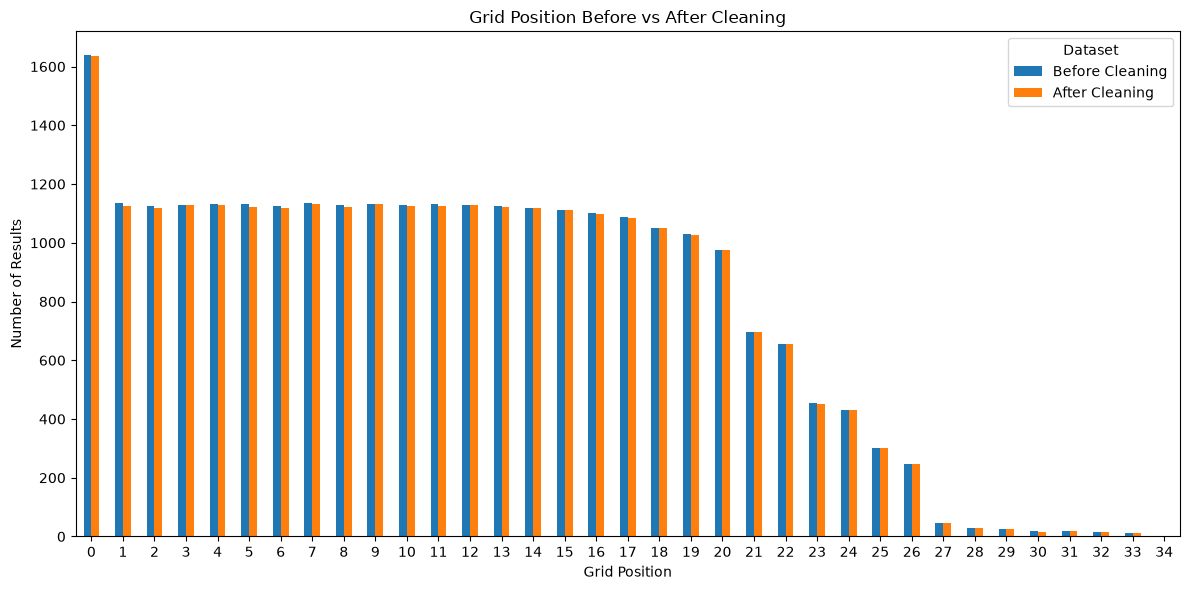

In [118]:
grid_comparison[["Before Cleaning", "After Cleaning"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Grid Position")
plt.ylabel("Number of Results")
plt.title("Grid Position Before vs After Cleaning")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

<a id="h124"></a>
### Step 5.3b: Grid summary statistics before vs. after
<a id="c117"></a>
*Code cell 119* | [Back to contents](#toc)
Mean 11.135 to 11.141; median and quartiles identical.


In [119]:
grid_summary = pd.DataFrame({
    "Before Cleaning": raw_grid.describe(),
    "After Cleaning": clean_grid.describe()
})

display(grid_summary)

,Before Cleaning,After Cleaning
count,26759.000000,26668.000000
mean,11.134796,11.140655
std,7.202860,7.198745
min,0.000000,0.000000
25%,5.000000,5.000000
50%,11.000000,11.000000
75%,17.000000,17.000000
max,34.000000,34.000000


<a id="h125"></a>
### Step 5.3c: Which grid slots lost rows
<a id="c118"></a>
*Code cell 120* | [Back to contents](#toc)
Differences are spread over all slots (1 to 12 rows each), no slot is wiped out.


In [120]:
grid_difference = (
    raw_grid.value_counts()
    .sort_index()
    .subtract(
        clean_grid.value_counts().sort_index(),
        fill_value=0
    )
)

grid_difference = grid_difference[grid_difference != 0]

display(grid_difference)

grid
0      3
1     12
2      6
3      3
4      4
5     11
6      5
7      3
8      7
10     5
11     6
13     3
14     1
15     2
16     2
17     3
18     1
19     3
20     1
21     1
23     2
26     1
27     1
28     2
30     2
33     1
Name: count, dtype: int64

<a id="h126"></a>
### Step 5.4: `positionOrder` distribution before vs. after
<a id="c119"></a>
*Code cell 121* | [Back to contents](#toc)
Shape preserved. Note: after removing rows, `positionOrder` is **no longer contiguous** within some races (a rank can be skipped). This does not affect `positionOrder <= 3` but matters if rank is ever used as a numeric feature or target.


In [121]:
raw_position_order = pd.to_numeric(
    tables["results"]["positionOrder"],
    errors="coerce"
)

clean_position_order = pd.to_numeric(
    cleaned_tables["results"]["positionOrder"],
    errors="coerce"
)

position_comparison = pd.DataFrame({
    "Before Cleaning": raw_position_order.value_counts().sort_index(),
    "After Cleaning": clean_position_order.value_counts().sort_index()
}).fillna(0)

display(position_comparison)

,Before Cleaning,After Cleaning
positionOrder,,
1,1128,1128
2,1134,1134
3,1135,1133
4,1135,1134
5,1132,1132
6,1132,1132
7,1132,1131
8,1132,1128
9,1131,1130


<a id="h127"></a>
### Step 5.4a: Plot: finishing position before vs. after.
<a id="c120"></a>
*Code cell 122* | [Back to contents](#toc)


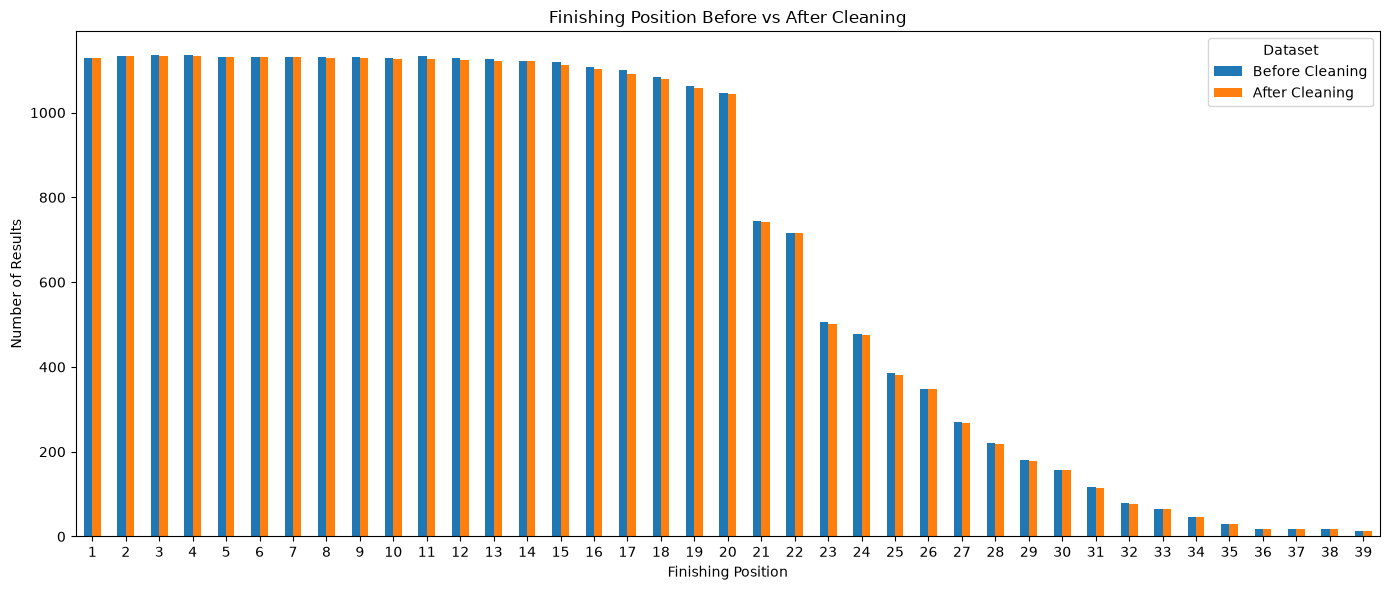

In [122]:
position_comparison[["Before Cleaning", "After Cleaning"]].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.xlabel("Finishing Position")
plt.ylabel("Number of Results")
plt.title("Finishing Position Before vs After Cleaning")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

<a id="h128"></a>
### Step 5.4b: `positionOrder` summary before vs. after (mean 12.794 to 12.778).
<a id="c121"></a>
*Code cell 123* | [Back to contents](#toc)


In [123]:
position_summary = pd.DataFrame({
    "Before Cleaning": raw_position_order.describe(),
    "After Cleaning": clean_position_order.describe()
})

display(position_summary)

,Before Cleaning,After Cleaning
count,26759.000000,26668.000000
mean,12.794051,12.777711
std,7.665951,7.662893
min,1.000000,1.000000
25%,6.000000,6.000000
50%,12.000000,12.000000
75%,18.000000,18.000000
max,39.000000,39.000000


<a id="h129"></a>
### Step 5.4c: Which finishing positions lost rows.
<a id="c122"></a>
*Code cell 124* | [Back to contents](#toc)


In [124]:
position_difference = (
    raw_position_order.value_counts()
    .sort_index()
    .subtract(
        clean_position_order.value_counts().sort_index(),
        fill_value=0
    )
)

position_difference = position_difference[
    position_difference != 0
]

display(position_difference)

positionOrder
3      2
4      1
7      1
8      4
9      1
10     3
11     6
12     6
13     5
14     1
15     8
16     4
17    10
18     6
19     4
20     2
21     3
23     3
24     3
25     4
26     1
27     2
28     2
29     3
31     3
32     2
33     1
Name: count, dtype: int64

<a id="h130"></a>
### Step 5.5: Before/after statistics of the numeric columns
<a id="c123"></a>
*Code cell 125* | [Back to contents](#toc)
Mean, median, min and max of `grid`, `positionOrder`, `points`, `laps`, `milliseconds`, `fastestLapSpeed`. Only columns affected by the 91 removed rows move; `milliseconds` and `fastestLapSpeed` do not change at all (the removed rows had none).


In [125]:
numeric_features = [
    "grid",
    "positionOrder",
    "points",
    "laps",
    "milliseconds",
    "fastestLapSpeed"
]

comparison_rows = []

for column in numeric_features:
    raw_values = pd.to_numeric(
        tables["results"][column],
        errors="coerce"
    )

    clean_values = pd.to_numeric(
        cleaned_tables["results"][column],
        errors="coerce"
    )

    comparison_rows.append({
        "Feature": column,
        "Raw Mean": raw_values.mean(),
        "Clean Mean": clean_values.mean(),
        "Raw Median": raw_values.median(),
        "Clean Median": clean_values.median(),
        "Raw Min": raw_values.min(),
        "Clean Min": clean_values.min(),
        "Raw Max": raw_values.max(),
        "Clean Max": clean_values.max()
    })

numerical_comparison = pd.DataFrame(comparison_rows)

display(numerical_comparison.round(2))

,Feature,Raw Mean,Clean Mean,Raw Median,Clean Median,Raw Min,Clean Min,Raw Max,Clean Max
0,grid,11.13,11.14,11.00,11.00,0.00,0.00,34.00,34.00
1,positionOrder,12.79,12.78,12.00,12.00,1.00,1.00,39.00,39.00
2,points,1.99,1.99,0.00,0.00,0.00,0.00,50.00,50.00
3,laps,46.30,46.29,53.00,53.00,0.00,0.00,200.00,200.00
4,milliseconds,6185832.95,6185832.95,5788193.50,5788193.50,526.00,526.00,15090540.00,15090540.00
5,fastestLapSpeed,204.12,204.12,204.89,204.89,89.54,89.54,257.32,257.32


<a id="h131"></a>
### Step 5.5a: Percentage change of the means
<a id="c124"></a>
*Code cell 126* | [Back to contents](#toc)
All changes are below 0.35% in absolute value (largest: `points` +0.33%). The cleaning has a negligible effect on the distributions.


In [126]:
numerical_comparison["Mean Change %"] = (
    (
        numerical_comparison["Clean Mean"]
        - numerical_comparison["Raw Mean"]
    )
    / numerical_comparison["Raw Mean"]
    * 100
)

display(
    numerical_comparison[
        ["Feature", "Raw Mean", "Clean Mean", "Mean Change %"]
    ].round(3)
)

,Feature,Raw Mean,Clean Mean,Mean Change %
0,grid,11.135,11.141,0.053
1,positionOrder,12.794,12.778,-0.128
2,points,1.988,1.994,0.330
3,laps,46.302,46.287,-0.032
4,milliseconds,6185832.953,6185832.953,0.000
5,fastestLapSpeed,204.116,204.116,0.000


<a id="h132"></a>
## 6. Final summary


<a id="h133"></a>
### Step 6.1: Cleaning summary per table
<a id="c125"></a>
*Code cell 127* | [Back to contents](#toc)
Rows before/after and remaining `\N` for every table: only `results` changes (-91 rows), 0 sentinels remain anywhere.


In [127]:
final_cleaning_summary = []

for name in tables:
    raw_df = tables[name]
    clean_df = cleaned_tables[name]

    # Remaining \N values
    remaining_sentinels = sum(
        (clean_df[column].astype(str) == r"\N").sum()
        for column in clean_df.columns
    )

    final_cleaning_summary.append({
        "Table": name,
        "Rows Before": len(raw_df),
        "Rows After": len(clean_df),
        "Rows Removed": len(raw_df) - len(clean_df),
        "Remaining \\N": remaining_sentinels
    })

final_cleaning_summary = pd.DataFrame(final_cleaning_summary)

display(final_cleaning_summary)

,Table,Rows Before,Rows After,Rows Removed,Remaining \N
0,circuits,77,77,0,0
1,constructors,212,212,0,0
2,constructor_results,12625,12625,0,0
3,constructor_standings,13391,13391,0,0
4,drivers,861,861,0,0
5,driver_standings,34863,34863,0,0
6,lap_times,589081,589081,0,0
7,pit_stops,11371,11371,0,0
8,qualifying,10494,10494,0,0
9,races,1125,1125,0,0


<a id="h134"></a>
### Step 6.2: Final cleaning checklist
<a id="c126"></a>
*Code cell 128* | [Back to contents](#toc)
Printed checklist of the four mandatory checks (sentinels, one row per driver-race, primary keys, foreign keys): all pass.


In [128]:
print("FINAL CLEANING CHECKLIST")
print("=" * 60)

# 1. Sentinel values
remaining_sentinels = 0

for name, df in cleaned_tables.items():
    for column in df.columns:
        remaining_sentinels += (
            df[column].astype(str) == r"\N"
        ).sum()

print(f"1. Remaining \\N values: {remaining_sentinels}")

# 2. Duplicate race-driver pairs
duplicate_pairs = (
    cleaned_tables["results"]
    .duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
    .sum()
)

print(f"2. Duplicate (raceId, driverId) rows: {duplicate_pairs}")

# 3. Primary keys
invalid_pks = 0

for table_name, pk in primary_keys.items():
    df = cleaned_tables[table_name]

    missing = df[pk].isna().sum()
    duplicates = df[pk].duplicated().sum()

    if missing > 0 or duplicates > 0:
        invalid_pks += 1

print(f"3. Tables with invalid primary keys: {invalid_pks}")

# 4. Foreign keys
invalid_fks = 0

for child_table, child_column, parent_table, parent_column in foreign_keys:

    child = cleaned_tables[child_table]
    parent = cleaned_tables[parent_table]

    parent_values = set(
        parent[parent_column].dropna()
    )

    invalid = (
        child[child_column]
        .dropna()
        .isin(parent_values)
        .eq(False)
        .sum()
    )

    if invalid > 0:
        invalid_fks += 1

print(f"4. Invalid foreign-key relationships: {invalid_fks}")

# 5. Final results size
print(
    f"5. Final results rows: "
    f"{len(cleaned_tables['results'])}"
)

print("=" * 60)

FINAL CLEANING CHECKLIST


1. Remaining \N values: 0
2. Duplicate (raceId, driverId) rows: 0
3. Tables with invalid primary keys: 0
4. Invalid foreign-key relationships: 0
5. Final results rows: 26668


<a id="h135"></a>
### Step 6.3: Cleaning impact and documented rule
<a id="c127"></a>
*Code cell 129* | [Back to contents](#toc)
Summary for the report: 26,759 to 26,668 rows (0.34% removed). **Documented rule:** per `(raceId, driverId)` keep max `laps`, then best `positionOrder`, then smallest `resultId`.


In [129]:
raw_results_count = len(tables["results"])
clean_results_count = len(cleaned_tables["results"])
removed_results_count = raw_results_count - clean_results_count

print("DATA CLEANING IMPACT")
print("=" * 60)

print(f"Raw results records:       {raw_results_count:,}")
print(f"Clean results records:     {clean_results_count:,}")
print(f"Records removed:           {removed_results_count:,}")

print(
    f"Percentage removed:        "
    f"{removed_results_count / raw_results_count * 100:.2f}%"
)

print()
print("Duplicate resolution:")
print("  Key: (raceId, driverId)")
print("  Rule: maximum laps")
print("        → best positionOrder if tied")
print("        → smallest resultId if still tied")

print()
print("Data integrity:")
print("  Sentinel values handled: Yes")
print("  Primary keys validated:  Yes")
print("  Foreign keys validated:  Yes")
print("  One result per driver-race: Yes")

DATA CLEANING IMPACT
Raw results records:       26,759
Clean results records:     26,668
Records removed:           91
Percentage removed:        0.34%

Duplicate resolution:
  Key: (raceId, driverId)
  Rule: maximum laps
        → best positionOrder if tied
        → smallest resultId if still tied

Data integrity:
  Sentinel values handled: Yes
  Primary keys validated:  Yes
  Foreign keys validated:  Yes
  One result per driver-race: Yes


<a id="h136"></a>
### Step 6.4: Export the cleaned copies and prove the raw tables were not touched
<a id="c128"></a>
*Code cell 130* | [Back to contents](#toc)
**Why:** the deliverable of Part 1 is a set of **cleaned copies** that the modeling part can load; nothing is saved yet. We write every cleaned table to CSV (human-readable), a pickle (keeps exact dtypes such as `Int64`, dates and times), the removed duplicate rows, and the cleaning log. The last lines show the raw tables still contain `\N` and the original row count, i.e. cleaning happened on copies only.


In [130]:
from pathlib import Path

OUT = Path("/kaggle/working/cleaned_data") if Path("/kaggle/working").exists() else Path("cleaned_data")
OUT.mkdir(parents=True, exist_ok=True)

for name, df in cleaned_tables.items():
    df.to_csv(OUT / f"{name}_clean.csv", index=False)
pd.to_pickle(cleaned_tables, OUT / "cleaned_tables.pkl")
dropped_duplicates.to_csv(OUT / "results_dropped_duplicates.csv", index=False)
final_cleaning_summary.to_csv(OUT / "cleaning_log.csv", index=False)
print("Saved to:", OUT.resolve(), "->", sorted(p.name for p in OUT.iterdir())[:6], "...")

# Raw immutability proof
print("Raw results rows:", len(tables["results"]), "| raw \\N values still present:",
      int((tables["results"].astype(str) == r"\N").sum().sum()))

Saved to: /tmp/claude-0/-home-claude/843a1b7a-0cf2-56f8-817e-22b27ec3a217/scratchpad/run/cleaned_data -> ['circuits_clean.csv', 'cleaned_tables.pkl', 'cleaning_log.csv', 'constructor_results_clean.csv', 'constructor_standings_clean.csv', 'constructors_clean.csv'] ...
Raw results rows: 26759 | raw \N values still present: 122887


<a id="h137"></a>
## Cleaning decisions log and decisions carried into Parts 3–5

**Decisions taken in this notebook**
| Topic | Decision | Evidence |
|---|---|---|
| Raw data | never modified; all work on `cleaned_tables` | Step 2.1, Step 6.4 (raw check) |
| `\N` sentinel | converted to missing, **not imputed** (mostly structural) | Steps 1.2, 2.2 |
| Types | numeric, dates, times and lap-time/duration strings to seconds (`*_sec` columns) | Steps 2.3-2.5 |
| One row per driver-race | keep max `laps`, then best `positionOrder`, then lowest `resultId`; removed rows saved in `dropped_duplicates` | Steps 3.3-3.7 |
| Keys | PK, composite keys and FK validated, no violations | Steps 4.1-4.4 |

**Decisions that need the modelling context are taken in Part B (decision register in B.3b):** DNQ/non-starters removed (grid 0 alone is not proof of a non-start), Indy 500 excluded, Option A qualifying fill, label `positionOrder <= 3` with an audit of odd races, leakage-safe pre-race features. The options that were considered:
1. **DNQ / DNPQ and non-starters** (`grid = 0`, `laps = 0`): keep with a `started_race` flag, or drop (Step 1.9e gives the evidence).
2. **Indianapolis 500, 1950-1960:** exclude or flag (Step 1.9f quantifies it).
3. **Qualifying coverage drift:** impute from `grid`, restrict the training window, or use qualifying only as an optional feature (Step 1.8e).
4. **Races where the number of podium rows is not 3** after de-duplication (Step 3.7): confirm that the label `positionOrder <= 3` is acceptable, or use the "any row is a podium" label.
5. **Leakage-safe versions** of standings, sprint results and anything post-race (next part).

---
<a id="h138"></a>
# Part 2 — Data-engineering questions (brief objective 2)

*(Cells here are numbered Q1.x, Q2.x, Q3.x.)*

Each question needs a **multi-hop join** across tables, because `results.csv` alone cannot answer it. Every answer below is given as **(1) a result table, (2) a visualisation, (3) a short justification of grain, missingness and, where relevant, the pre-race cutoff.**

| Question | Tables combined (join keys) | Grain of the analysis table | Pre-race cutoff |
|---|---|---|---|
| **Q1** Which circuits convert a front-row start into a podium most, and does the ranking change after 2014? | primary answer (Q1.12): `results` (grid) -> `races` (raceId) -> `circuits` (circuitId); qualifying comparison (Q1.1–Q1.11): `qualifying` -> `races` -> `circuits` -> `results` (raceId, driverId) | one row per driver per race (all races with a grid slot for the primary answer; the races with qualifying data for the comparison) | `qualifying_position` and `grid` are known **before** the race; `positionOrder` is the post-race outcome |
| **Q2** Do drivers podium more often at home, after controlling for grid? | `results` -> `races` -> `circuits` (country) and `results` -> `drivers` (nationality) | one row per driver per race (started races, `grid > 0`) | home status and `grid` are pre-race; podium is the label |
| **Q3** Which constructors have the highest mechanical-retirement rate, 2014-2021 vs 2022-2024? | `results` -> `races` (year), `results` -> `status` (cause), `results` -> `constructors` (name) | one row per driver per race (race starts) | `status` is **post-race**: a descriptive answer only, never a feature |

**Shared conventions:** the cleaned, de-duplicated `cleaned_tables["results"]` from Section 3 is always used (one row per `(raceId, driverId)`); podium means `positionOrder <= 3`; every join uses `validate=` or an explicit row-count check so a many-to-many join cannot silently inflate the data; small samples are shown with confidence intervals.

<a id="h139"></a>
### Shared helper for Part 2: Wilson confidence interval
<a id="c129"></a>
*Code cell 131* | [Back to contents](#toc)
**Why:** several answers below are rates computed on small samples (for example 16 podiums from 18 front-row starts). A rate without an interval invites over-reading, so every ranking gets a 95% **Wilson score interval**, which behaves well for small `n` and for rates near 0% or 100% (unlike the normal approximation). The function is vectorised and returns percentages.


In [131]:
from scipy import stats

def wilson_interval(k, n, z=1.96):
    """95% Wilson score interval for k successes out of n trials, returned in percent."""
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = np.where(n > 0, k / n, np.nan)
        denom = 1 + z ** 2 / n
        centre = (p + z ** 2 / (2 * n)) / denom
        half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return (centre - half) * 100, (centre + half) * 100

print("wilson_interval(16, 18) ->", [round(float(x), 1) for x in wilson_interval(16, 18)])

wilson_interval(16, 18) -> [67.2, 96.9]


<a id="h140"></a>
### Q1.1: Build the Question 1 analysis table (multi-hop join)
<a id="c130"></a>
*Code cell 132* | [Back to contents](#toc)
Starts from `qualifying` (the only source of the qualifying position) and adds, hop by hop: `races` (season and `circuitId`), `circuits` (circuit name and country) and `results` (`grid` and `positionOrder`). The qualifying position is renamed `qualifying_position` so it can never be confused with `grid`.
**Why this order:** the question is about starts that were on the front row, and only `qualifying` records the qualifying order, so it is the left-most table. Inner joins keep drivers present in all four tables.
**Scope of Q1.1–Q1.11:** this is the *qualifying-based* view (front-row qualifiers). The primary answer, based on the actual starting grid in all races, is **Q1.12**, where the two definitions are reconciled.
**Result:** 10,494 rows, i.e. every qualifying row found a race, a circuit and a result: no row was lost or multiplied. Because the whole analysis comes from `qualifying`, it covers only the seasons that table contains (the coverage plot in Q1.2b shows which).


In [132]:
# Start with qualifying information
q1 = cleaned_tables["qualifying"][
    ["raceId", "driverId", "position"]
].copy()

# Rename qualifying position to make its meaning explicit
q1 = q1.rename(
    columns={"position": "qualifying_position"}
)

# Join race information
q1 = q1.merge(
    cleaned_tables["races"][
        ["raceId", "year", "circuitId"]
    ],
    on="raceId",
    how="inner"
)

# Join circuit information
q1 = q1.merge(
    cleaned_tables["circuits"][
        ["circuitId", "name", "country"]
    ],
    on="circuitId",
    how="inner"
)

# Join actual race result
q1 = q1.merge(
    cleaned_tables["results"][
        [
            "raceId",
            "driverId",
            "grid",
            "positionOrder"
        ]
    ],
    on=["raceId", "driverId"],
    how="inner"
)

print("Rows:", len(q1))
print("Columns:", q1.columns.tolist())

display(q1.head())

Rows: 10494
Columns: ['raceId', 'driverId', 'qualifying_position', 'year', 'circuitId', 'name', 'country', 'grid', 'positionOrder']


,raceId,driverId,qualifying_position,year,circuitId,name,country,grid,positionOrder
0,18,1,1,2008,1,Albert Park Grand Prix Circuit,Australia,1,1
1,18,9,2,2008,1,Albert Park Grand Prix Circuit,Australia,2,9
2,18,5,3,2008,1,Albert Park Grand Prix Circuit,Australia,3,5
3,18,13,4,2008,1,Albert Park Grand Prix Circuit,Australia,4,13
4,18,2,5,2008,1,Albert Park Grand Prix Circuit,Australia,5,2


<a id="h141"></a>
### Q1.2: Grain check: one row per driver per race
<a id="c131"></a>
*Code cell 133* | [Back to contents](#toc)
`duplicated(["raceId","driverId"])` returns **0**, so the table keeps the required grain. This also confirms that the shared-drive rule of Section 3 did its job: a duplicated key here would have counted one driver twice in a circuit's conversion rate.


In [133]:
duplicate_driver_races = q1.duplicated(
    subset=["raceId", "driverId"]
).sum()

print(
    "Duplicate (raceId, driverId) rows:",
    duplicate_driver_races
)

Duplicate (raceId, driverId) rows: 0


<a id="h142"></a>
### Q1.2a: Missingness check on the joined columns
<a id="c132"></a>
*Code cell 134* | [Back to contents](#toc)
No missing qualifying position, grid, finishing position or circuit name, so no row has to be dropped or imputed. This only proves completeness **for the rows that exist**; the missingness that matters for this question is *absent races* (no qualifying data for most of F1 history), which the cell below measures.


In [134]:
print("Missing qualifying position:",
      q1["qualifying_position"].isna().sum())

print("Missing grid:",
      q1["grid"].isna().sum())

print("Missing finishing position:",
      q1["positionOrder"].isna().sum())

print("Missing circuit:",
      q1["name"].isna().sum())

Missing qualifying position: 0
Missing grid: 0
Missing finishing position: 0
Missing circuit: 0


<a id="h143"></a>
### Q1.2b: Join audit and qualifying coverage (grain and missingness evidence for Question 1)
<a id="c133"></a>
*Code cell 135* | [Back to contents](#toc)
**Why:** the answer to Question 1 is only as good as the join chain `qualifying -> races -> circuits -> results`. This cell (1) repeats the chain with `validate=` so pandas **raises an error** if any hop duplicates rows, and prints the row count after every hop, and (2) plots how many races per season actually have qualifying data. That second plot is the **missingness statement** for Question 1: all conclusions apply only to the seasons covered by `qualifying.csv`, not to the whole 1950-2024 history.
**Grain:** one row per `(raceId, driverId)`; the final table must keep exactly the number of qualifying rows.


,Join hop,Rows after hop
0,qualifying (start),10494
1,"+ races (year, circuitId)",10494
2,"+ circuits (name, country)",10494
3,"+ results (grid, positionOrder)",10494


Qualifying seasons covered: 1994 to 2024
Races with qualifying: 494 of 1125 races in the dataset


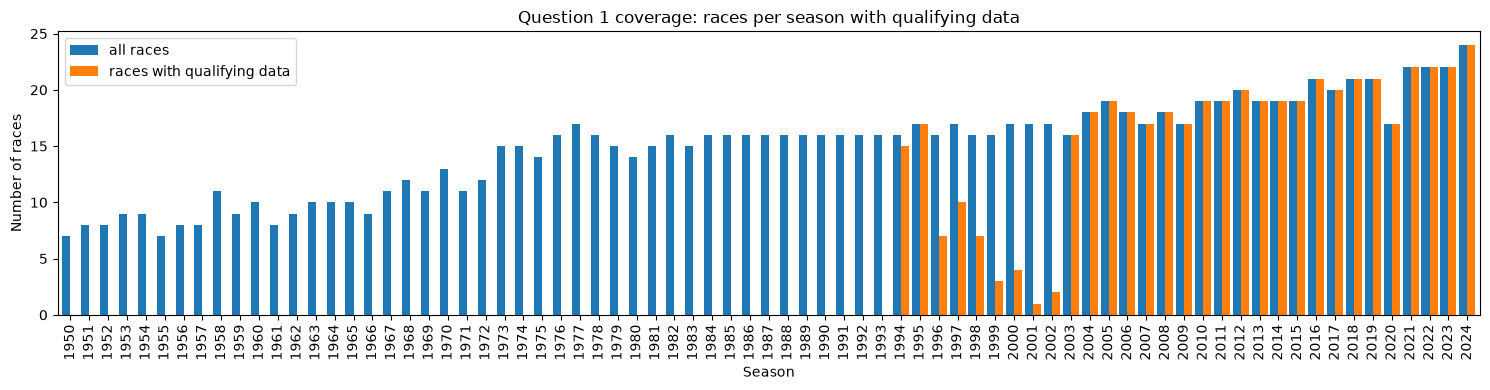

In [135]:
hops = []
step = cleaned_tables["qualifying"][["raceId", "driverId", "position"]]
hops.append(("qualifying (start)", len(step)))
step = step.merge(cleaned_tables["races"][["raceId", "year", "circuitId"]], on="raceId", how="inner", validate="many_to_one")
hops.append(("+ races (year, circuitId)", len(step)))
step = step.merge(cleaned_tables["circuits"][["circuitId", "name", "country"]], on="circuitId", how="inner", validate="many_to_one")
hops.append(("+ circuits (name, country)", len(step)))
step = step.merge(cleaned_tables["results"][["raceId", "driverId", "grid", "positionOrder"]],
                  on=["raceId", "driverId"], how="inner", validate="one_to_one")
hops.append(("+ results (grid, positionOrder)", len(step)))
display(pd.DataFrame(hops, columns=["Join hop", "Rows after hop"]))

print("Qualifying seasons covered:", int(q1["year"].min()), "to", int(q1["year"].max()))
print("Races with qualifying:", q1["raceId"].nunique(), "of", cleaned_tables["races"]["raceId"].nunique(), "races in the dataset")

coverage = (cleaned_tables["races"].groupby("year").size().rename("all races").to_frame()
            .join(q1.groupby("year")["raceId"].nunique().rename("races with qualifying data")).fillna(0))
coverage.plot(kind="bar", figsize=(15, 4), width=0.85)
plt.xlabel("Season"); plt.ylabel("Number of races")
plt.title("Question 1 coverage: races per season with qualifying data"); plt.tight_layout(); plt.show()

<a id="h144"></a>
### Q1.3: Define the front row by qualifying position
<a id="c134"></a>
*Code cell 136* | [Back to contents](#toc)
Front-row start = `qualifying_position <= 2` (pole and P2): **988 records** (2 per race x 494 races). **Cutoff:** qualifying is finished before the race, so this is a legitimate pre-race definition. It is only *one* of the two definitions the question asks us to distinguish; the grid-based definition is built in Q1.6b.


In [136]:
front_row = q1[
    q1["qualifying_position"] <= 2
].copy()

print("Front-row records:", len(front_row))

display(
    front_row[
        [
            "raceId",
            "year",
            "name",
            "country",
            "driverId",
            "qualifying_position",
            "grid",
            "positionOrder"
        ]
    ].head(20)
)

Front-row records: 988


,raceId,year,name,country,driverId,qualifying_position,grid,positionOrder
0,18,2008,Albert Park Grand Prix Circuit,Australia,1,1,1,1
1,18,2008,Albert Park Grand Prix Circuit,Australia,9,2,2,9
22,19,2008,Sepang International Circuit,Malaysia,13,1,1,19
23,19,2008,Sepang International Circuit,Malaysia,8,2,2,1
44,20,2008,Bahrain International Circuit,Bahrain,9,1,1,3
45,20,2008,Bahrain International Circuit,Bahrain,13,2,2,1
66,21,2008,Circuit de Barcelona-Catalunya,Spain,8,1,1,1
67,21,2008,Circuit de Barcelona-Catalunya,Spain,4,2,2,15
88,22,2008,Istanbul Park,Turkey,13,1,1,1
89,22,2008,Istanbul Park,Turkey,5,2,2,12


<a id="h145"></a>
### Q1.4: How often does grid differ from qualifying position?
<a id="c135"></a>
*Code cell 137* | [Back to contents](#toc)
`grid_difference = grid - qualifying_position`. Among the 988 front-row qualifiers, **51 (5.2%)** did not start where they qualified (penalties, pit-lane starts, exclusions) and 937 did. This is the evidence that qualifying position and grid are **not the same variable**: for about 1 in 20 front-row qualifiers the front-row label would be wrong if `grid` were used.


In [137]:
front_row["grid_difference"] = (
    front_row["grid"]
    - front_row["qualifying_position"]
)

front_row["grid_changed"] = (
    front_row["grid_difference"] != 0
)

print(
    "Front-row records with different grid position:",
    front_row["grid_changed"].sum()
)

print(
    "Front-row records with same grid position:",
    (~front_row["grid_changed"]).sum()
)

Front-row records with different grid position: 51
Front-row records with same grid position: 937


<a id="h146"></a>
### Q1.4a: Inspect the front-row qualifiers whose grid changed
<a id="c136"></a>
*Code cell 138* | [Back to contents](#toc)
Lists the cases. Examples visible in the output: a qualifying P1 who started 24th in Spain 2012 (a drop of 23 places, most likely a qualifying disqualification) and others who dropped 5-10 places in Monza 2005, Monaco 2012 and Hungary 2007. A qualifier moved *back* is a front-row qualifier who did not have a front-row start, which is why Q1.6b measures their podium rate separately.


In [138]:
grid_changes = front_row[
    front_row["grid_changed"]
].copy()

display(
    grid_changes[
        [
            "year",
            "name",
            "country",
            "driverId",
            "qualifying_position",
            "grid",
            "grid_difference",
            "positionOrder"
        ]
    ].head(30)
)

,year,name,country,driverId,qualifying_position,grid,grid_difference,positionOrder
588,2007,Hungaroring,Hungary,4,1,6,5,4
589,2007,Hungaroring,Hungary,1,2,1,-1,1
1219,2005,Silverstone Circuit,UK,8,2,12,10,3
1298,2005,Autodromo Nazionale di Monza,Italy,8,1,11,10,4
1299,2005,Autodromo Nazionale di Monza,Italy,31,2,1,-1,1
3493,2010,Circuit Gilles Villeneuve,Canada,17,2,7,5,5
4180,2004,Circuit de Monaco,Monaco,23,2,12,10,10
4893,2011,Buddh International Circuit,India,1,2,5,3,7
5012,2012,Shanghai International Circuit,China,1,2,7,5,3
5059,2012,Circuit de Barcelona-Catalunya,Spain,1,1,24,23,8


<a id="h147"></a>
### Q1.5: Create the podium flag
<a id="c137"></a>
*Code cell 139* | [Back to contents](#toc)
`podium = positionOrder <= 3` (same target as the project). It is the **post-race** outcome and is used here only to measure conversion, never as an input.


In [139]:
front_row["podium"] = (
    front_row["positionOrder"] <= 3
).astype(int)

<a id="h148"></a>
### Q1.6: Define the two eras
<a id="c138"></a>
*Code cell 140* | [Back to contents](#toc)
`Pre-2014` (before the hybrid power-unit regulations) vs `2014-2024`. This follows the wording "after the 2014 hybrid era". Note that `2014-2024` also contains the 2022+ ground-effect cars; a sensitivity run on 2014-2021 only is added in Q1.9d so the conclusion does not depend on that grouping.


In [140]:
front_row["era"] = front_row["year"].apply(
    lambda year: "Pre-2014" if year < 2014 else "2014-2024"
)

<a id="h149"></a>
### Q1.6a: Preview the table with era and podium
<a id="c139"></a>
*Code cell 141* | [Back to contents](#toc)
Quick check that qualifying position, grid, finishing position, era and podium line up correctly row by row (for example the 2008 Australian Grand Prix pole sitter wins and has `podium = 1`).


In [141]:
display(
    front_row[
        [
            "year",
            "era",
            "name",
            "qualifying_position",
            "grid",
            "positionOrder",
            "podium"
        ]
    ].head(20)
)

,year,era,name,qualifying_position,grid,positionOrder,podium
0,2008,Pre-2014,Albert Park Grand Prix Circuit,1,1,1,1
1,2008,Pre-2014,Albert Park Grand Prix Circuit,2,2,9,0
22,2008,Pre-2014,Sepang International Circuit,1,1,19,0
23,2008,Pre-2014,Sepang International Circuit,2,2,1,1
44,2008,Pre-2014,Bahrain International Circuit,1,1,3,1
45,2008,Pre-2014,Bahrain International Circuit,2,2,1,1
66,2008,Pre-2014,Circuit de Barcelona-Catalunya,1,1,1,1
67,2008,Pre-2014,Circuit de Barcelona-Catalunya,2,2,15,0
88,2008,Pre-2014,Istanbul Park,1,1,1,1
89,2008,Pre-2014,Istanbul Park,2,2,12,0


<a id="h150"></a>
### Q1.6b: Qualifying position vs. grid: the second half of "distinguish qualifying from grid"
<a id="c140"></a>
*Code cell 142* | [Back to contents](#toc)
**Why:** Q1.3–Q1.4 define the front row by qualifying position (`qualifying_position <= 2`) and count 51 front-row qualifiers whose grid slot changed. The question asks us to distinguish the two definitions, so this cell measures what that change does: we create both flags and split front-row starts into three groups: **qualified and started on the front row**, **qualified on the front row but started elsewhere** (penalty, pit lane, exclusion) and **promoted to the front row on the grid** (qualified P3 or lower, moved up by others' penalties).
**Cutoff:** both `qualifying_position` and `grid` are fixed before the lights go out, so either definition is a legitimate *pre-race* quantity; only `positionOrder` is post-race.
**How to read:** if penalised front-row qualifiers convert far less often, the two definitions must not be mixed.


,era,start_type,starts,podiums,conversion_%
0,2014-2024,Promoted to front row on the grid,27,18,66.67
1,2014-2024,Qualified AND started on front row,427,327,76.58
2,2014-2024,"Qualified front row, started elsewhere",29,9,31.03
3,Pre-2014,Promoted to front row on the grid,9,5,55.56
4,Pre-2014,Qualified AND started on front row,523,342,65.39
5,Pre-2014,"Qualified front row, started elsewhere",9,2,22.22


,definition,era,starts,podiums,conversion_%
0,Grid front row (grid 1-2),2014-2024,454,345,75.99
1,Grid front row (grid 1-2),Pre-2014,532,347,65.23
2,Qualifying front row (qualifying_position <= 2),2014-2024,456,336,73.68
3,Qualifying front row (qualifying_position <= 2),Pre-2014,532,344,64.66


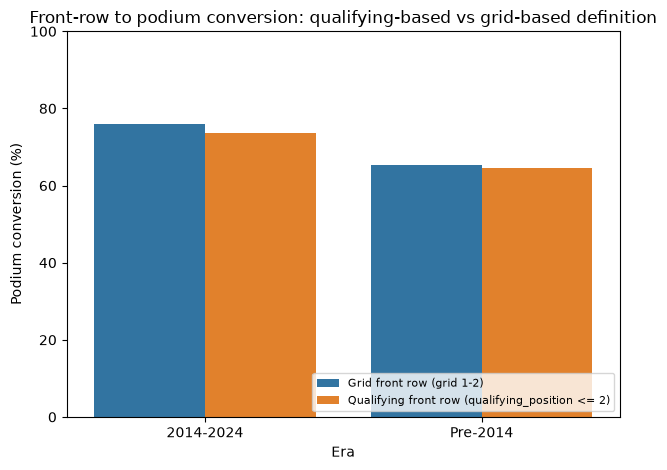

In [142]:
q1_all = q1.copy()
q1_all["podium"] = (q1_all["positionOrder"] <= 3).astype(int)
q1_all["era"] = np.where(q1_all["year"] < 2014, "Pre-2014", "2014-2024")
q1_all["front_row_quali"] = q1_all["qualifying_position"] <= 2
q1_all["front_row_grid"] = q1_all["grid"].between(1, 2)

q1_all["start_type"] = np.select(
    [q1_all["front_row_quali"] & q1_all["front_row_grid"],
     q1_all["front_row_quali"] & ~q1_all["front_row_grid"],
     ~q1_all["front_row_quali"] & q1_all["front_row_grid"]],
    ["Qualified AND started on front row",
     "Qualified front row, started elsewhere",
     "Promoted to front row on the grid"],
    default="Not front row")

by_type = (q1_all[q1_all["start_type"] != "Not front row"]
           .groupby(["era", "start_type"])
           .agg(starts=("podium", "size"), podiums=("podium", "sum")).reset_index())
by_type["conversion_%"] = (by_type["podiums"] / by_type["starts"] * 100).round(2)
display(by_type)

definition_summary = (pd.concat({
        "Qualifying front row (qualifying_position <= 2)": q1_all[q1_all["front_row_quali"]],
        "Grid front row (grid 1-2)": q1_all[q1_all["front_row_grid"]]}, names=["definition"])
    .reset_index(level=0)
    .groupby(["definition", "era"])
    .agg(starts=("podium", "size"), podiums=("podium", "sum")).reset_index())
definition_summary["conversion_%"] = (definition_summary["podiums"] / definition_summary["starts"] * 100).round(2)
display(definition_summary)

sns.barplot(data=definition_summary, x="era", y="conversion_%", hue="definition")
plt.ylim(0, 100); plt.ylabel("Podium conversion (%)"); plt.xlabel("Era")
plt.title("Front-row to podium conversion: qualifying-based vs grid-based definition")
plt.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

<a id="h151"></a>
### Q1.7: Conversion rate per circuit and era
<a id="c141"></a>
*Code cell 143* | [Back to contents](#toc)
Groups front-row starts by `(era, circuit)` and computes `podiums / front_row_starts`. **Grain:** the unit is a front-row start. Sorting by rate puts tiny samples first (Miami 6/6, Algarve 4/4, Mugello 2/2 all show 100%), which is a warning that a minimum number of starts is required before ranking.


In [143]:
circuit_conversion = (
    front_row
    .groupby(["era", "circuitId", "name", "country"])
    .agg(
        front_row_starts=("podium", "size"),
        podiums=("podium", "sum")
    )
    .reset_index()
)

circuit_conversion["podium_conversion_rate"] = (
    circuit_conversion["podiums"]
    / circuit_conversion["front_row_starts"]
    * 100
)

circuit_conversion = circuit_conversion.sort_values(
    ["era", "podium_conversion_rate", "front_row_starts"],
    ascending=[True, False, False]
)

display(circuit_conversion.head(20))

,era,circuitId,name,country,front_row_starts,podiums,podium_conversion_rate
30,2014-2024,79,Miami International Autodrome,USA,6,6,100.000000
26,2014-2024,75,Autódromo Internacional do Algarve,Portugal,4,4,100.000000
27,2014-2024,76,Autodromo Internazionale del Mugello,Italy,2,2,100.000000
17,2014-2024,22,Suzuka Circuit,Japan,18,16,88.888889
21,2014-2024,39,Circuit Park Zandvoort,Netherlands,8,7,87.500000
5,2014-2024,6,Circuit de Monaco,Monaco,20,17,85.000000
3,2014-2024,4,Circuit de Barcelona-Catalunya,Spain,22,18,81.818182
10,2014-2024,13,Circuit de Spa-Francorchamps,Belgium,22,18,81.818182
18,2014-2024,24,Yas Marina Circuit,UAE,22,18,81.818182
24,2014-2024,71,Sochi Autodrom,Russia,16,13,81.250000


<a id="h152"></a>
### Q1.7a: How many front-row starts does each circuit have?
<a id="c142"></a>
*Code cell 144* | [Back to contents](#toc)
Counts front-row starts per circuit over all eras (Silverstone 56, Interlagos 54, Barcelona 52, ...). Used to choose a sensible minimum sample for the ranking.


In [144]:
front_row_counts = (
    front_row
    .groupby(["circuitId", "name", "country"])
    .size()
    .reset_index(name="front_row_starts")
    .sort_values("front_row_starts", ascending=False)
)

display(front_row_counts.head(20))

,circuitId,name,country,front_row_starts
8,9,Silverstone Circuit,UK,56
17,18,Autódromo José Carlos Pace,Brazil,54
3,4,Circuit de Barcelona-Catalunya,Spain,52
0,1,Albert Park Grand Prix Circuit,Australia,50
10,11,Hungaroring,Hungary,48
13,14,Autodromo Nazionale di Monza,Italy,48
5,6,Circuit de Monaco,Monaco,48
12,13,Circuit de Spa-Francorchamps,Belgium,46
21,22,Suzuka Circuit,Japan,44
6,7,Circuit Gilles Villeneuve,Canada,44


<a id="h153"></a>
### Q1.7b: Distribution of front-row starts per circuit
<a id="c143"></a>
*Code cell 145* | [Back to contents](#toc)
Median 18, quartiles 7 and 38, range 2-56. The spread shows that many circuits have too few starts for a reliable rate, which justifies a threshold.


In [145]:
front_row_counts["front_row_starts"].describe()

count    43.000000
mean     22.976744
std      17.746211
min       2.000000
25%       7.000000
50%      18.000000
75%      38.000000
max      56.000000
Name: front_row_starts, dtype: float64

<a id="h154"></a>
### Q1.7c: Effect of different thresholds
<a id="c144"></a>
*Code cell 146* | [Back to contents](#toc)
35 circuits have at least 5 front-row starts, 27 at least 10 and 20 at least 20 (over both eras). The threshold trades coverage against reliability; the next cell fixes it at 10 *per era*.


In [146]:
print("Circuits with at least 5 front-row starts:",
      (front_row_counts["front_row_starts"] >= 5).sum())

print("Circuits with at least 10 front-row starts:",
      (front_row_counts["front_row_starts"] >= 10).sum())

print("Circuits with at least 20 front-row starts:",
      (front_row_counts["front_row_starts"] >= 20).sum())

Circuits with at least 5 front-row starts: 35
Circuits with at least 10 front-row starts: 27
Circuits with at least 20 front-row starts: 20


<a id="h155"></a>
### Q1.8: Apply the minimum-sample rule (at least 10 front-row starts per era)
<a id="c145"></a>
*Code cell 147* | [Back to contents](#toc)
`MIN_FRONT_ROW_STARTS = 10` removes circuits such as Miami or Algarve that have only a few starts and would otherwise top the ranking by chance. The threshold is a judgement, so Q1.11b shows confidence intervals to make the remaining uncertainty visible.


In [147]:
MIN_FRONT_ROW_STARTS = 10

circuit_ranking = circuit_conversion[
    circuit_conversion["front_row_starts"] >= MIN_FRONT_ROW_STARTS
].copy()

circuit_ranking = circuit_ranking.sort_values(
    ["era", "podium_conversion_rate", "front_row_starts"],
    ascending=[True, False, False]
)

display(circuit_ranking)

,era,circuitId,name,country,front_row_starts,podiums,podium_conversion_rate
17,2014-2024,22,Suzuka Circuit,Japan,18,16,88.888889
5,2014-2024,6,Circuit de Monaco,Monaco,20,17,85.000000
3,2014-2024,4,Circuit de Barcelona-Catalunya,Spain,22,18,81.818182
10,2014-2024,13,Circuit de Spa-Francorchamps,Belgium,22,18,81.818182
18,2014-2024,24,Yas Marina Circuit,UAE,22,18,81.818182
24,2014-2024,71,Sochi Autodrom,Russia,16,13,81.250000
13,2014-2024,17,Shanghai International Circuit,China,14,11,78.571429
7,2014-2024,9,Silverstone Circuit,UK,24,18,75.000000
22,2014-2024,69,Circuit of the Americas,USA,20,15,75.000000
11,2014-2024,14,Autodromo Nazionale di Monza,Italy,22,16,72.727273


<a id="h156"></a>
### Q1.8a: Top 10 circuits in each era
<a id="c146"></a>
*Code cell 148* | [Back to contents](#toc)
**Pre-2014:** Magny-Cours 88.89% (16 of 18), Istanbul Park 78.57%, Suzuka 76.92%, Shanghai 70.00%, Hockenheim 68.18%. **2014-2024:** Suzuka 88.89% (16 of 18), Monaco 85.00%, Barcelona, Spa and Yas Marina 81.82%. Magny-Cours and Istanbul Park have no 2014+ races, so they cannot be compared across eras.


In [148]:
top_pre_2014 = (
    circuit_ranking[circuit_ranking["era"] == "Pre-2014"]
    .head(10)
)

top_2014_2024 = (
    circuit_ranking[circuit_ranking["era"] == "2014-2024"]
    .head(10)
)

print("TOP CIRCUITS — PRE-2014")
display(top_pre_2014)

print("TOP CIRCUITS — 2014-2024")
display(top_2014_2024)

TOP CIRCUITS — PRE-2014


,era,circuitId,name,country,front_row_starts,podiums,podium_conversion_rate
39,Pre-2014,8,Circuit de Nevers Magny-Cours,France,18,16,88.888889
36,Pre-2014,5,Istanbul Park,Turkey,14,11,78.571429
53,Pre-2014,22,Suzuka Circuit,Japan,26,20,76.923077
48,Pre-2014,17,Shanghai International Circuit,China,20,14,70.000000
41,Pre-2014,10,Hockenheimring,Germany,22,15,68.181818
33,Pre-2014,2,Sepang International Circuit,Malaysia,24,16,66.666667
34,Pre-2014,3,Bahrain International Circuit,Bahrain,18,12,66.666667
50,Pre-2014,19,Indianapolis Motor Speedway,USA,12,8,66.666667
40,Pre-2014,9,Silverstone Circuit,UK,32,21,65.625000
42,Pre-2014,11,Hungaroring,Hungary,26,17,65.384615


TOP CIRCUITS — 2014-2024


,era,circuitId,name,country,front_row_starts,podiums,podium_conversion_rate
17,2014-2024,22,Suzuka Circuit,Japan,18,16,88.888889
5,2014-2024,6,Circuit de Monaco,Monaco,20,17,85.000000
3,2014-2024,4,Circuit de Barcelona-Catalunya,Spain,22,18,81.818182
10,2014-2024,13,Circuit de Spa-Francorchamps,Belgium,22,18,81.818182
18,2014-2024,24,Yas Marina Circuit,UAE,22,18,81.818182
24,2014-2024,71,Sochi Autodrom,Russia,16,13,81.250000
13,2014-2024,17,Shanghai International Circuit,China,14,11,78.571429
7,2014-2024,9,Silverstone Circuit,UK,24,18,75.000000
22,2014-2024,69,Circuit of the Americas,USA,20,15,75.000000
11,2014-2024,14,Autodromo Nazionale di Monza,Italy,22,16,72.727273


<a id="h157"></a>
### Q1.8b: Plot: all circuits that pass the threshold, by era
<a id="c147"></a>
*Code cell 149* | [Back to contents](#toc)
Grouped bars of conversion rate per circuit and era. It shows all circuits, including those present in only one era, so it is a view of the *level*, not of the *change*.


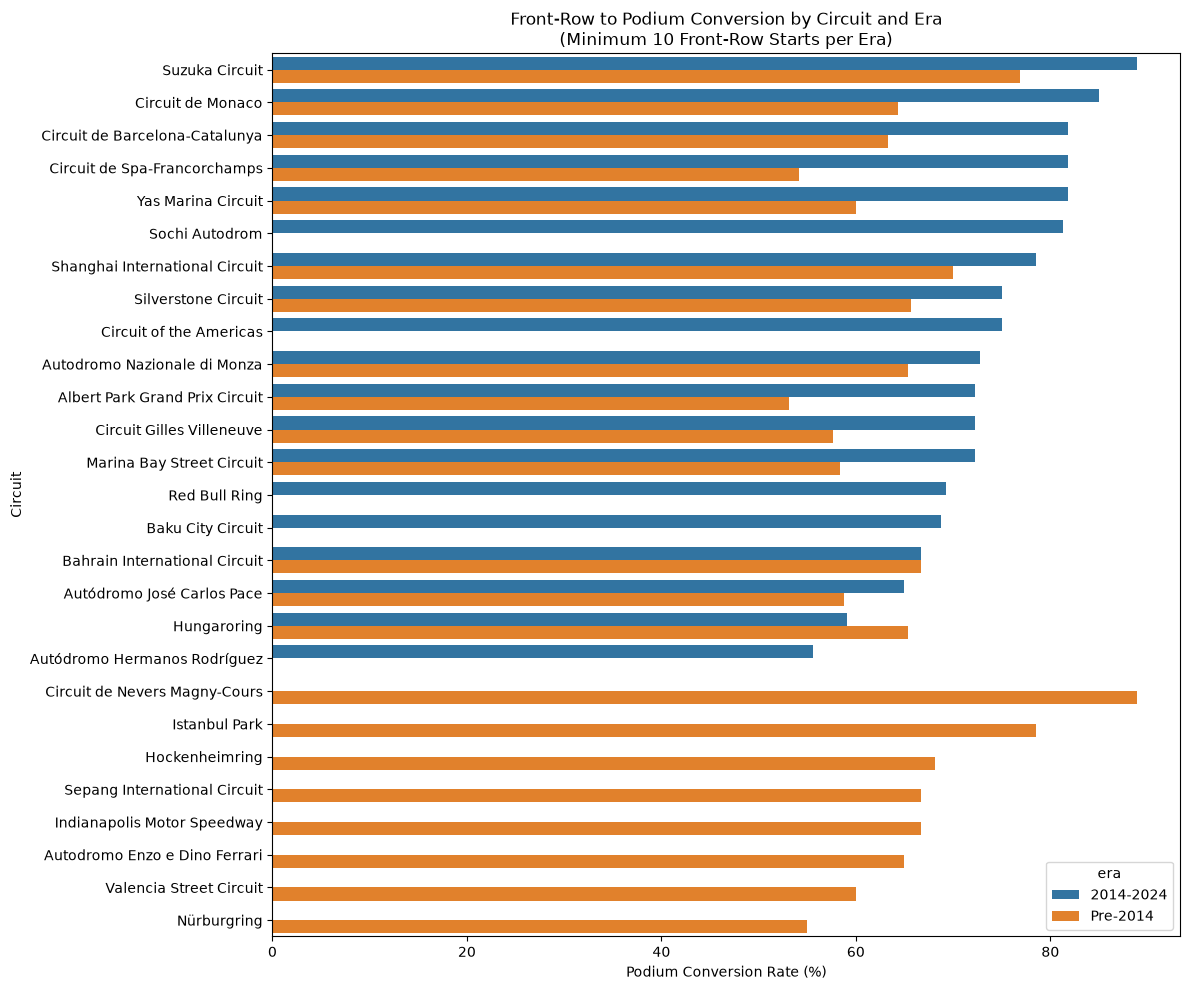

In [149]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_data = circuit_ranking.copy()

plt.figure(figsize=(12, 10))

sns.barplot(
    data=plot_data,
    x="podium_conversion_rate",
    y="name",
    hue="era"
)

plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.title(
    "Front-Row to Podium Conversion by Circuit and Era\n"
    "(Minimum 10 Front-Row Starts per Era)"
)

plt.tight_layout()
plt.show()

<a id="h158"></a>
### Q1.8c: Plot: top circuits of each era
<a id="c148"></a>
*Code cell 150* | [Back to contents](#toc)
Same idea restricted to the top 10 of each era.


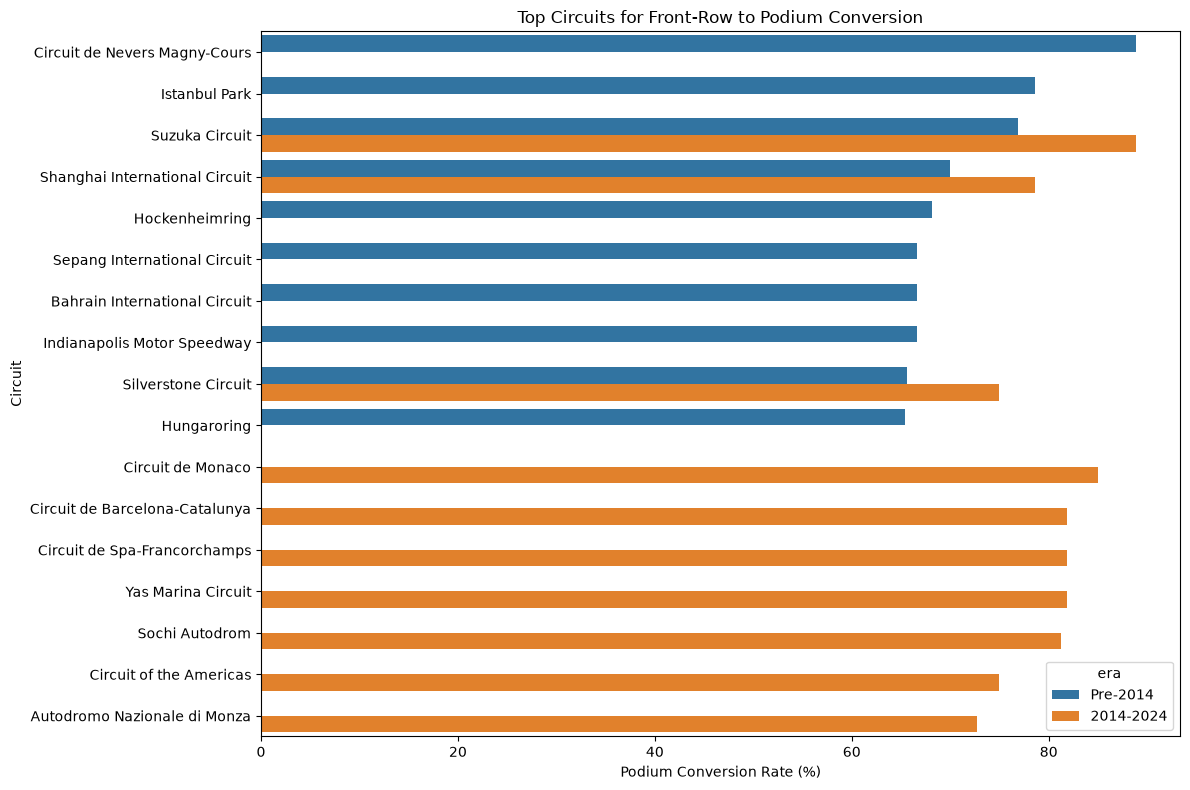

In [150]:
top_20_plot = pd.concat([
    top_pre_2014,
    top_2014_2024
])

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_plot,
    x="podium_conversion_rate",
    y="name",
    hue="era"
)

plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.title(
    "Top Circuits for Front-Row to Podium Conversion"
)

plt.tight_layout()
plt.show()

<a id="h159"></a>
### Q1.9: Circuits present in both eras
<a id="c149"></a>
*Code cell 151* | [Back to contents](#toc)
Merges the two eras on circuit: **14 circuits** have at least 10 front-row starts both before and after 2014. Only these can answer "does the ranking *change*", because a circuit missing in one era has no rank to compare.


In [151]:
pre_2014 = circuit_ranking[
    circuit_ranking["era"] == "Pre-2014"
].copy()

post_2014 = circuit_ranking[
    circuit_ranking["era"] == "2014-2024"
].copy()

era_comparison = pre_2014.merge(
    post_2014,
    on=["circuitId", "name", "country"],
    suffixes=("_pre2014", "_2014_2024")
)

print(
    "Circuits with at least 10 front-row starts in both eras:",
    len(era_comparison)
)

display(era_comparison)

Circuits with at least 10 front-row starts in both eras: 14


,era_pre2014,circuitId,name,country,front_row_starts_pre2014,podiums_pre2014,podium_conversion_rate_pre2014,era_2014_2024,front_row_starts_2014_2024,podiums_2014_2024,podium_conversion_rate_2014_2024
0,Pre-2014,22,Suzuka Circuit,Japan,26,20,76.923077,2014-2024,18,16,88.888889
1,Pre-2014,17,Shanghai International Circuit,China,20,14,70.000000,2014-2024,14,11,78.571429
2,Pre-2014,3,Bahrain International Circuit,Bahrain,18,12,66.666667,2014-2024,24,16,66.666667
3,Pre-2014,9,Silverstone Circuit,UK,32,21,65.625000,2014-2024,24,18,75.000000
4,Pre-2014,11,Hungaroring,Hungary,26,17,65.384615,2014-2024,22,13,59.090909
5,Pre-2014,14,Autodromo Nazionale di Monza,Italy,26,17,65.384615,2014-2024,22,16,72.727273
6,Pre-2014,6,Circuit de Monaco,Monaco,28,18,64.285714,2014-2024,20,17,85.000000
7,Pre-2014,4,Circuit de Barcelona-Catalunya,Spain,30,19,63.333333,2014-2024,22,18,81.818182
8,Pre-2014,24,Yas Marina Circuit,UAE,10,6,60.000000,2014-2024,22,18,81.818182
9,Pre-2014,18,Autódromo José Carlos Pace,Brazil,34,20,58.823529,2014-2024,20,13,65.000000


<a id="h160"></a>
### Q1.9a: Change in conversion rate per circuit
<a id="c150"></a>
*Code cell 152* | [Back to contents](#toc)
Percentage-point change (2014-2024 minus pre-2014), largest first. Spa +27.7, Yas Marina +21.8, Monaco +20.7, Albert Park +19.1 and Barcelona +18.5 improve most, and the overall conversion also rises (see Q1.11). A circuit-level change of 20 points can still come from a few races, hence the intervals in Q1.11b.


In [152]:
era_comparison["conversion_change"] = (
    era_comparison["podium_conversion_rate_2014_2024"]
    - era_comparison["podium_conversion_rate_pre2014"]
)

era_comparison["absolute_change"] = (
    era_comparison["conversion_change"].abs()
)

era_comparison = era_comparison.sort_values(
    "conversion_change",
    ascending=False
)

display(
    era_comparison[
        [
            "name",
            "country",
            "podium_conversion_rate_pre2014",
            "podium_conversion_rate_2014_2024",
            "conversion_change"
        ]
    ]
)

,name,country,podium_conversion_rate_pre2014,podium_conversion_rate_2014_2024,conversion_change
12,Circuit de Spa-Francorchamps,Belgium,54.166667,81.818182,27.651515
8,Yas Marina Circuit,UAE,60.000000,81.818182,21.818182
6,Circuit de Monaco,Monaco,64.285714,85.000000,20.714286
13,Albert Park Grand Prix Circuit,Australia,53.125000,72.222222,19.097222
7,Circuit de Barcelona-Catalunya,Spain,63.333333,81.818182,18.484848
11,Circuit Gilles Villeneuve,Canada,57.692308,72.222222,14.529915
10,Marina Bay Street Circuit,Singapore,58.333333,72.222222,13.888889
0,Suzuka Circuit,Japan,76.923077,88.888889,11.965812
3,Silverstone Circuit,UK,65.625000,75.000000,9.375000
1,Shanghai International Circuit,China,70.000000,78.571429,8.571429


<a id="h161"></a>
### Q1.9b: Prepare the top-10 lists for plotting
<a id="c151"></a>
*Code cell 153* | [Back to contents](#toc)
Extracts the top 10 of each era and concatenates them.


In [153]:
top_pre = (
    circuit_ranking[
        circuit_ranking["era"] == "Pre-2014"
    ]
    .head(10)
    .copy()
)

top_hybrid = (
    circuit_ranking[
        circuit_ranking["era"] == "2014-2024"
    ]
    .head(10)
    .copy()
)

top_plot = pd.concat([
    top_pre,
    top_hybrid
])

<a id="h162"></a>
### Q1.9c: Plot: top 10 circuits, pre-2014 vs 2014-2024
<a id="c152"></a>
*Code cell 154* | [Back to contents](#toc)
The main chart for "which circuits convert best, and does it change". Suzuka is top-3 in both eras while Magny-Cours/Istanbul (pre-2014) and Monaco/Barcelona/Spa (post-2014) lead only one era.


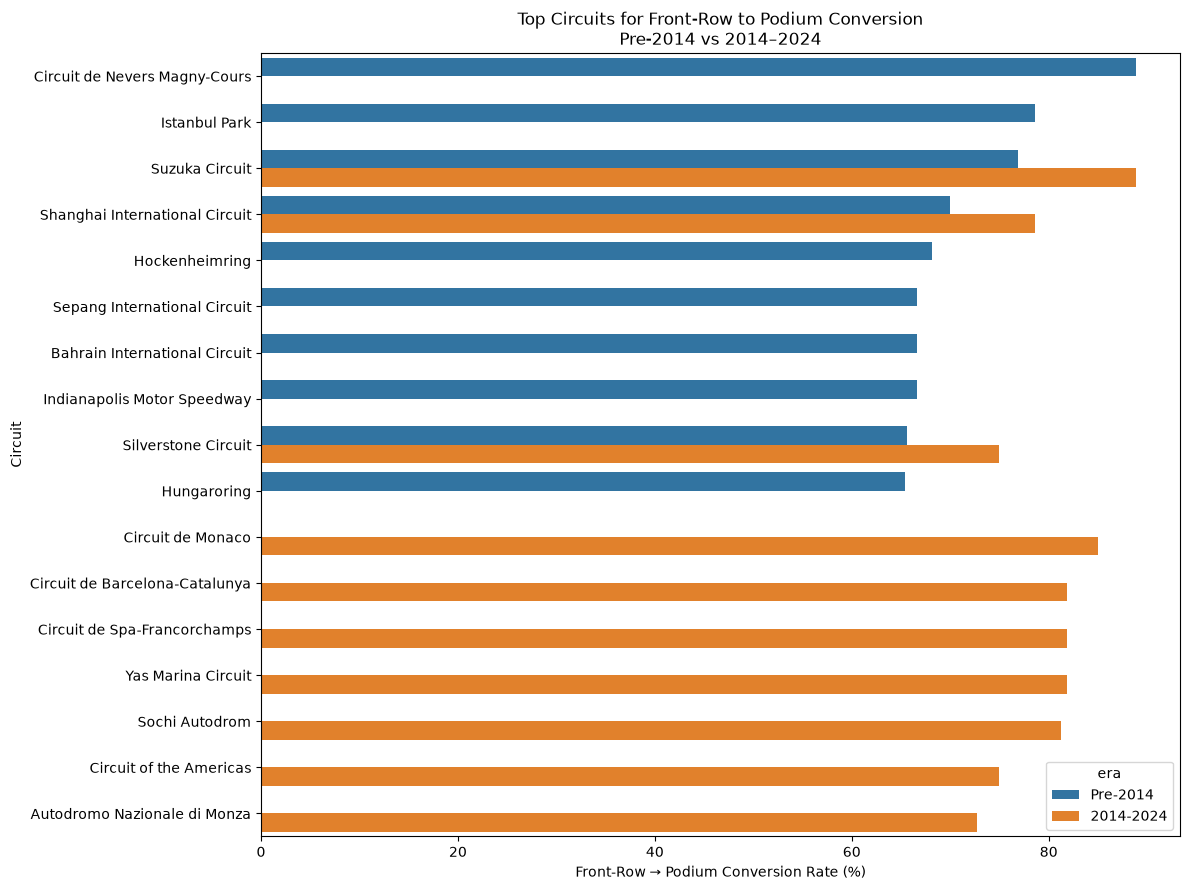

In [154]:
plt.figure(figsize=(12, 9))

sns.barplot(
    data=top_plot,
    x="podium_conversion_rate",
    y="name",
    hue="era"
)

plt.xlabel("Front-Row → Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.title(
    "Top Circuits for Front-Row to Podium Conversion\n"
    "Pre-2014 vs 2014–2024"
)

plt.tight_layout()
plt.show()

<a id="h163"></a>
### Q1.9d: Rank comparison on the SAME set of circuits, with a correlation and sensitivity check
<a id="c153"></a>
*Code cell 155* | [Back to contents](#toc)
**Why:** a rank change computed on two different circuit lists is not comparable. `rank_pre2014` ranks each circuit among *all* circuits with at least 10 front-row starts before 2014 (more than 20 of them, e.g. Spa is 21st) while `rank_2014_2024` ranks among the smaller post-2014 set, so a circuit "climbs" simply because the second list is shorter. Here both ranks are computed **among the 14 circuits present in both eras** only.
**What is added:** Spearman correlation between the two eras' rates (does the ranking change?), a 95% interval for it that accounts for binomial sampling noise (parametric bootstrap on the observed counts), and a sensitivity run using only 2014-2021 (the strict turbo-hybrid era, without the 2022+ ground-effect cars).
**How to read:** a correlation near 1 means the ranking is stable; near 0 means the circuit order is essentially reshuffled.


,name,country,rank_pre2014,rank_2014_2024,rank_change
12,Circuit de Spa-Francorchamps,Belgium,13,3,10
8,Yas Marina Circuit,UAE,9,3,6
6,Circuit de Monaco,Monaco,7,2,5
13,Albert Park Grand Prix Circuit,Australia,14,9,5
7,Circuit de Barcelona-Catalunya,Spain,8,3,5
11,Circuit Gilles Villeneuve,Canada,12,9,3
10,Marina Bay Street Circuit,Singapore,11,9,2
0,Suzuka Circuit,Japan,1,1,0
3,Silverstone Circuit,UK,4,7,-3
5,Autodromo Nazionale di Monza,Italy,5,8,-3


Spearman rho between eras on 14 common circuits: 0.20 (p = 0.498); 95% sampling interval [-0.41, 0.59]
Sensitivity (2014-2021 only): rho = -0.23 (p = 0.429) on 14 circuits


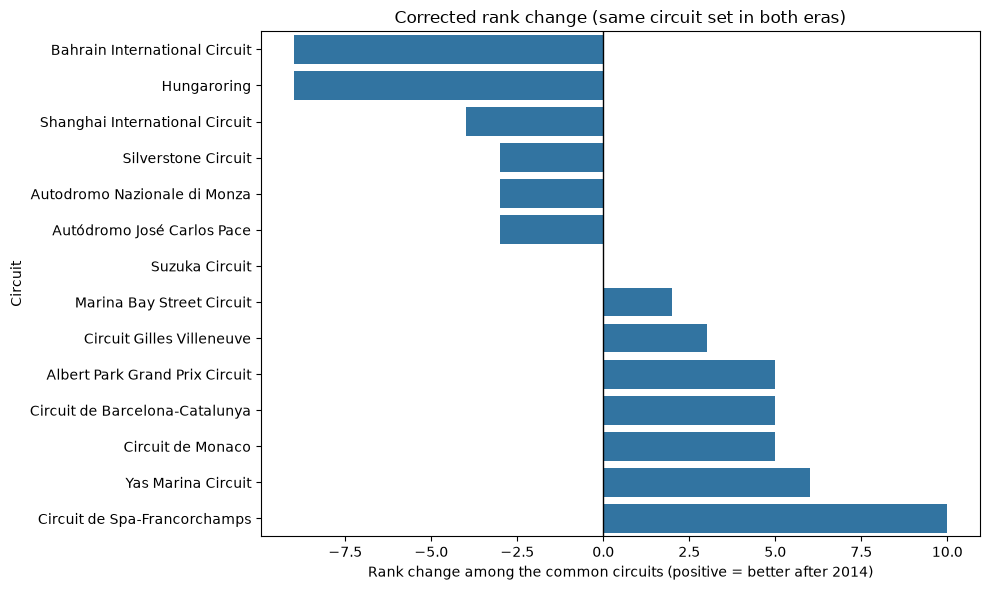

In [155]:
cmp = era_comparison[["circuitId", "name", "country",
                      "front_row_starts_pre2014", "podiums_pre2014", "podium_conversion_rate_pre2014",
                      "front_row_starts_2014_2024", "podiums_2014_2024", "podium_conversion_rate_2014_2024"]].copy()
cmp["rank_pre2014"] = cmp["podium_conversion_rate_pre2014"].rank(ascending=False, method="min").astype(int)
cmp["rank_2014_2024"] = cmp["podium_conversion_rate_2014_2024"].rank(ascending=False, method="min").astype(int)
cmp["rank_change"] = cmp["rank_pre2014"] - cmp["rank_2014_2024"]   # positive = climbed after 2014
display(cmp.sort_values("rank_change", ascending=False)[
    ["name", "country", "rank_pre2014", "rank_2014_2024", "rank_change"]])

rho, p_value = stats.spearmanr(cmp["podium_conversion_rate_pre2014"], cmp["podium_conversion_rate_2014_2024"])
rng = np.random.default_rng(42)
n_pre, k_pre = cmp["front_row_starts_pre2014"].to_numpy(), cmp["podiums_pre2014"].to_numpy()
n_post, k_post = cmp["front_row_starts_2014_2024"].to_numpy(), cmp["podiums_2014_2024"].to_numpy()
boot = []
for _ in range(2000):
    r_b = stats.spearmanr(rng.binomial(n_pre, k_pre / n_pre) / n_pre, rng.binomial(n_post, k_post / n_post) / n_post)[0]
    if not np.isnan(r_b):
        boot.append(r_b)
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Spearman rho between eras on {len(cmp)} common circuits: {rho:.2f} (p = {p_value:.3f}); 95% sampling interval [{lo:.2f}, {hi:.2f}]")

# Sensitivity: strict hybrid era only (2014-2021)
hybrid = (q1_all[q1_all["front_row_quali"] & q1_all["year"].between(2014, 2021)]
          .groupby("circuitId").agg(starts_2014_2021=("podium", "size"), podiums_2014_2021=("podium", "sum")).reset_index())
hybrid = hybrid[hybrid["starts_2014_2021"] >= MIN_FRONT_ROW_STARTS]
hybrid["rate_2014_2021"] = hybrid["podiums_2014_2021"] / hybrid["starts_2014_2021"] * 100
sens = cmp.merge(hybrid, on="circuitId")
if len(sens) >= 4:
    rho_h, p_h = stats.spearmanr(sens["podium_conversion_rate_pre2014"], sens["rate_2014_2021"])
    print(f"Sensitivity (2014-2021 only): rho = {rho_h:.2f} (p = {p_h:.3f}) on {len(sens)} circuits")

plot_rank = cmp.sort_values("rank_change")
plt.figure(figsize=(10, 6))
sns.barplot(data=plot_rank, x="rank_change", y="name", color="tab:blue")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Rank change among the common circuits (positive = better after 2014)")
plt.ylabel("Circuit"); plt.title("Corrected rank change (same circuit set in both eras)")
plt.tight_layout(); plt.show()

<a id="h164"></a>
### Q1.10: Qualifying-based Q1 table (rounded)
<a id="c154"></a>
*Code cell 156* | [Back to contents](#toc)
Rounds the qualifying-based table to 2 decimals (the threshold filter is re-applied as a safeguard). It uses the **qualifying-based** front row only; the grid-based ranking follows in Q1.10a, and the primary answer for the report is Q1.12.


In [156]:
final_q1_table = circuit_ranking[
    circuit_ranking["front_row_starts"] >= 10
].copy()

final_q1_table = final_q1_table[
    [
        "era",
        "name",
        "country",
        "front_row_starts",
        "podiums",
        "podium_conversion_rate"
    ]
].copy()

final_q1_table["podium_conversion_rate"] = (
    final_q1_table["podium_conversion_rate"].round(2)
)

display(
    final_q1_table.sort_values(
        ["era", "podium_conversion_rate"],
        ascending=[True, False]
    )
)

,era,name,country,front_row_starts,podiums,podium_conversion_rate
17,2014-2024,Suzuka Circuit,Japan,18,16,88.89
5,2014-2024,Circuit de Monaco,Monaco,20,17,85.00
3,2014-2024,Circuit de Barcelona-Catalunya,Spain,22,18,81.82
10,2014-2024,Circuit de Spa-Francorchamps,Belgium,22,18,81.82
18,2014-2024,Yas Marina Circuit,UAE,22,18,81.82
24,2014-2024,Sochi Autodrom,Russia,16,13,81.25
13,2014-2024,Shanghai International Circuit,China,14,11,78.57
7,2014-2024,Silverstone Circuit,UK,24,18,75.00
22,2014-2024,Circuit of the Americas,USA,20,15,75.00
11,2014-2024,Autodromo Nazionale di Monza,Italy,22,16,72.73


<a id="h165"></a>
### Q1.10a: Circuit ranking with the GRID-based front row, compared with the qualifying-based ranking
<a id="c155"></a>
*Code cell 157* | [Back to contents](#toc)
**Why:** the question asks to *distinguish* qualifying position from grid. The ranking above uses qualifying only. Here the same ranking (same threshold of at least 10 starts per era) is rebuilt with `grid` 1-2 and compared circuit by circuit: Spearman correlation per era, the circuits where the two definitions disagree most, and a scatter plot (points on the diagonal are unaffected by penalties).
**Reading the answer:** if the correlation is high, penalties do not change *which circuits* convert best; the largest gaps point to circuits where grid penalties or pit-lane starts matter.


,era,circuits,spearman_rho,p_value
0,2014-2024,19,0.88,0.0
1,Pre-2014,22,0.85,0.0


Circuits where the two definitions disagree most (percentage points):


,era,name,front_row_starts_quali,rate_quali,front_row_starts_grid,rate_grid,gap_pp
11,2014-2024,Autódromo José Carlos Pace,20,65.0,19,78.9,13.9
24,Pre-2014,Circuit de Monaco,28,64.3,28,71.4,7.1
18,2014-2024,Baku City Circuit,16,68.8,16,62.5,-6.2
4,2014-2024,Circuit Gilles Villeneuve,18,72.2,18,77.8,5.6
14,2014-2024,Autódromo Hermanos Rodríguez,18,55.6,18,61.1,5.6
34,Pre-2014,Shanghai International Circuit,20,70.0,20,65.0,-5.0
15,2014-2024,Circuit of the Americas,20,75.0,20,80.0,5.0
13,2014-2024,Yas Marina Circuit,22,81.8,22,86.4,4.5
16,2014-2024,Red Bull Ring,26,69.2,26,73.1,3.8
32,Pre-2014,Autodromo Nazionale di Monza,26,65.4,26,69.2,3.8


Top 5 by grid-based front row: Pre-2014


,name,country,front_row_starts,podiums,rate
39,Circuit de Nevers Magny-Cours,France,18,16,88.9
36,Istanbul Park,Turkey,14,11,78.6
53,Suzuka Circuit,Japan,26,20,76.9
37,Circuit de Monaco,Monaco,28,20,71.4
42,Hungaroring,Hungary,26,18,69.2


Top 5 by grid-based front row: 2014-2024


,name,country,front_row_starts,podiums,rate
17,Suzuka Circuit,Japan,18,16,88.9
18,Yas Marina Circuit,UAE,22,19,86.4
5,Circuit de Monaco,Monaco,20,17,85.0
3,Circuit de Barcelona-Catalunya,Spain,22,18,81.8
10,Circuit de Spa-Francorchamps,Belgium,22,18,81.8


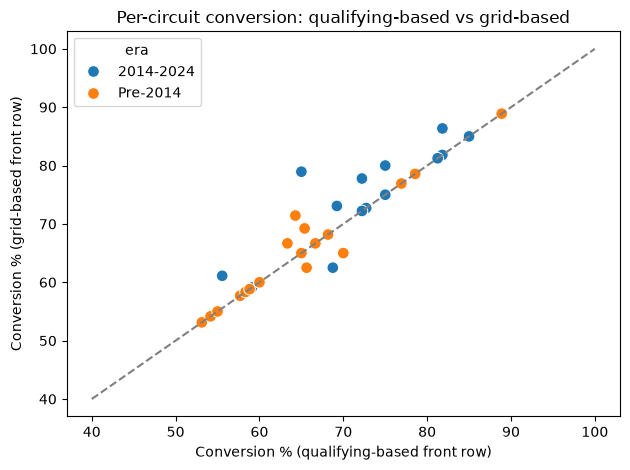

In [157]:
def circuit_conversion_table(df, flag, min_starts=MIN_FRONT_ROW_STARTS):
    sub = df[df[flag]]
    t = (sub.groupby(["era", "circuitId", "name", "country"])
         .agg(front_row_starts=("podium", "size"), podiums=("podium", "sum")).reset_index())
    t["rate"] = t["podiums"] / t["front_row_starts"] * 100
    return t[t["front_row_starts"] >= min_starts]

tab_quali = circuit_conversion_table(q1_all, "front_row_quali")
tab_grid = circuit_conversion_table(q1_all, "front_row_grid")
both_defs = tab_quali.merge(tab_grid, on=["era", "circuitId", "name", "country"], suffixes=("_quali", "_grid"))
both_defs["gap_pp"] = both_defs["rate_grid"] - both_defs["rate_quali"]

rho_rows = []
for era_name, grp in both_defs.groupby("era"):
    r_e, p_e = stats.spearmanr(grp["rate_quali"], grp["rate_grid"])
    rho_rows.append({"era": era_name, "circuits": len(grp), "spearman_rho": round(r_e, 2), "p_value": round(p_e, 4)})
display(pd.DataFrame(rho_rows))

print("Circuits where the two definitions disagree most (percentage points):")
display(both_defs.reindex(both_defs["gap_pp"].abs().sort_values(ascending=False).index)
        [["era", "name", "front_row_starts_quali", "rate_quali", "front_row_starts_grid", "rate_grid", "gap_pp"]].head(10).round(1))

for era_name in ["Pre-2014", "2014-2024"]:
    print(f"Top 5 by grid-based front row: {era_name}")
    display(tab_grid[tab_grid["era"] == era_name].sort_values(["rate", "front_row_starts"], ascending=False)
            .head(5)[["name", "country", "front_row_starts", "podiums", "rate"]].round(1))

sns.scatterplot(data=both_defs, x="rate_quali", y="rate_grid", hue="era", s=70)
plt.plot([40, 100], [40, 100], color="grey", linestyle="--")
plt.xlabel("Conversion % (qualifying-based front row)"); plt.ylabel("Conversion % (grid-based front row)")
plt.title("Per-circuit conversion: qualifying-based vs grid-based"); plt.tight_layout(); plt.show()

<a id="h166"></a>
### Q1.11: Overall conversion by era
<a id="c156"></a>
*Code cell 158* | [Back to contents](#toc)
Across all circuits: **64.66%** (344 of 532) before 2014 and **73.68%** (336 of 456) from 2014. A front-row start converts to a podium about 9 points more often after 2014, consistent with the hybrid-era dominance of a few fast cars (Q1.11b tests this difference).


In [158]:
overall_q1 = (
    front_row
    .groupby("era")
    .agg(
        front_row_starts=("podium", "size"),
        podiums=("podium", "sum")
    )
    .reset_index()
)

overall_q1["conversion_rate"] = (
    overall_q1["podiums"]
    / overall_q1["front_row_starts"]
    * 100
)

overall_q1["conversion_rate"] = (
    overall_q1["conversion_rate"].round(2)
)

display(overall_q1)

,era,front_row_starts,podiums,conversion_rate
0,2014-2024,456,336,73.68
1,Pre-2014,532,344,64.66


<a id="h167"></a>
### Q1.11a: Plot: overall conversion before and after 2014
<a id="c157"></a>
*Code cell 159* | [Back to contents](#toc)
Two-bar chart of the overall rates with value labels.


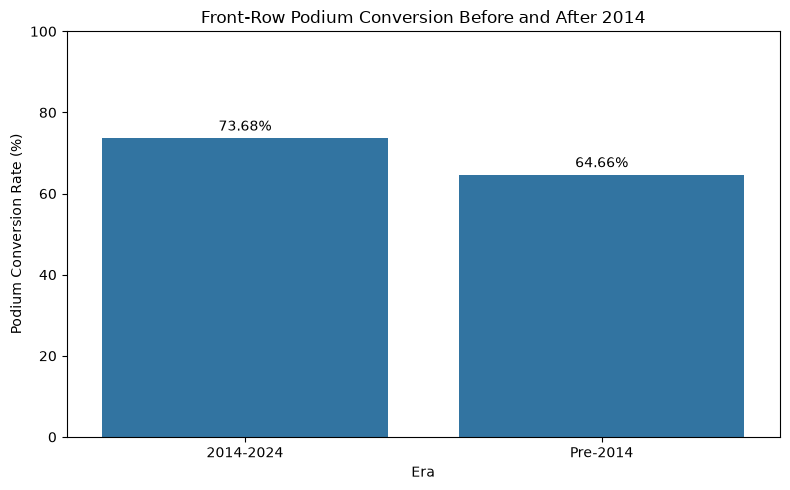

In [159]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=overall_q1,
    x="era",
    y="conversion_rate"
)

plt.xlabel("Era")
plt.ylabel("Podium Conversion Rate (%)")
plt.title("Front-Row Podium Conversion Before and After 2014")
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

<a id="h168"></a>
### Q1.11b: Uncertainty: confidence intervals per circuit and a significance test of the era change
<a id="c158"></a>
*Code cell 160* | [Back to contents](#toc)
**Why:** with 10-30 front-row starts per circuit and era, a few races can move a circuit several places. The plot shows each common circuit's conversion rate in both eras with its **95% Wilson interval**; overlapping intervals mean the individual circuit's change is not reliable. The last lines test the **overall** change (64.66% to 73.68% in the earlier cell) with a chi-square test on the counts.
**Answer it supports:** "the ranking changes" is a statement about the *order*, but "the conversion rate went up after 2014" can be statistically supported, and individual circuit moves must be reported with their intervals.


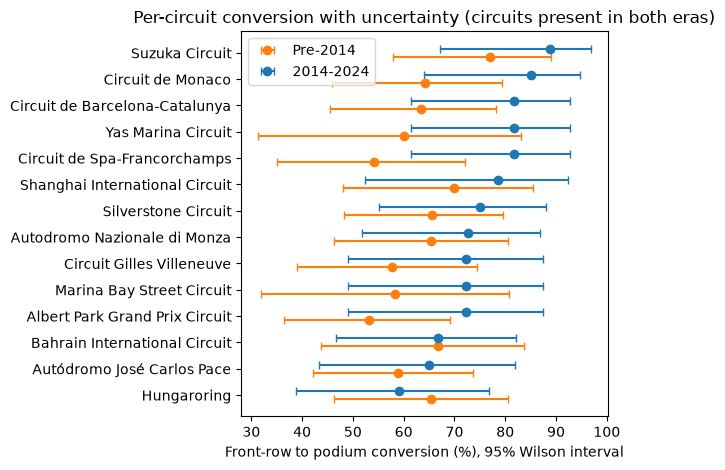

Overall change: 64.66% -> 73.68% (chi-square p = 0.0029)


In [160]:
plot_ci = cmp.sort_values("podium_conversion_rate_2014_2024").reset_index(drop=True)
y = np.arange(len(plot_ci))
for label, k_col, n_col, color, offset in [("Pre-2014", "podiums_pre2014", "front_row_starts_pre2014", "tab:orange", -0.15),
                                           ("2014-2024", "podiums_2014_2024", "front_row_starts_2014_2024", "tab:blue", 0.15)]:
    rate = plot_ci[k_col] / plot_ci[n_col] * 100
    low, high = wilson_interval(plot_ci[k_col], plot_ci[n_col])
    plt.errorbar(rate, y + offset, xerr=[rate - low, high - rate], fmt="o", color=color, label=label, capsize=3)
plt.yticks(y, plot_ci["name"]); plt.xlabel("Front-row to podium conversion (%), 95% Wilson interval")
plt.title("Per-circuit conversion with uncertainty (circuits present in both eras)")
plt.legend(); plt.tight_layout(); plt.show()

pre_row = overall_q1[overall_q1["era"] == "Pre-2014"].iloc[0]
post_row = overall_q1[overall_q1["era"] == "2014-2024"].iloc[0]
table = [[post_row["podiums"], post_row["front_row_starts"] - post_row["podiums"]],
         [pre_row["podiums"], pre_row["front_row_starts"] - pre_row["podiums"]]]
chi2, p_overall, _, _ = stats.chi2_contingency(table)
print(f"Overall change: {pre_row['conversion_rate']:.2f}% -> {post_row['conversion_rate']:.2f}% (chi-square p = {p_overall:.4f})")

<a id="h189"></a>
### Q1.12: Final answer — front-row START (grid) as the primary definition
<a id="c179"></a>
*Code cell 161* | [Back to contents](#toc)
**Why:** the brief says *front-row **start*** and asks us to *distinguish qualifying from grid*. Q1.1–Q1.11 start from `qualifying` (front-row **qualifiers**), which limits them to the 494 races that have qualifying data. This cell starts from `results.grid` (grid 1–2, grid 0 and the Indy 500 removed) so it covers 1,114 races, then reconciles the two definitions.
**Output:** top circuits per era, the overall conversion of a front-row start per era, the Spearman rank correlation of the circuit ranking before vs after 2014 (with a bootstrap interval), a rank-change table, a dot plot, and a reconciliation of qualifiers vs starters (how many changed exact slot and how many truly left the front row).


Races in the results table: 1125 | races kept for the grid-based analysis: 1114 | rows with grid 0 (pit lane / no slot) removed: 1635 | Indy-500 rows removed: 381

Top 6 circuits by front-row -> podium conversion, before 2014 (>= 10 front-row starts):


,era,circuit,front_row_starts,podiums,conversion_%
0,before 2014,Circuit de Nevers Magny-Cours,36,29,80.56
1,before 2014,Istanbul Park,14,11,78.57
2,before 2014,Dijon-Prenois,12,9,75.00
3,before 2014,Circuit Bremgarten,10,7,70.00
4,before 2014,Suzuka Circuit,50,35,70.00
5,before 2014,Sepang International Circuit,30,21,70.00



Top 6 circuits by front-row -> podium conversion, 2014 onward (>= 10 front-row starts):


,era,circuit,front_row_starts,podiums,conversion_%
0,2014 onward,Suzuka Circuit,18,16,88.89
1,2014 onward,Yas Marina Circuit,22,19,86.36
2,2014 onward,Circuit de Monaco,20,17,85.00
3,2014 onward,Circuit de Spa-Francorchamps,22,18,81.82
4,2014 onward,Circuit de Barcelona-Catalunya,22,18,81.82
5,2014 onward,Sochi Autodrom,16,13,81.25



Overall conversion of a front-row START: {'2014 onward': 75.99, 'before 2014': 56.29}


Circuits present in both eras (>= 10 front-row starts each): 16 | Spearman rank correlation = -0.03, 95% bootstrap interval [-0.53, 0.41]


era,2014 onward,before 2014,rank_before,rank_after,rank_change
circuit,,,,,
Circuit de Monaco,85.0,49.2,15.0,3.0,12.0
Circuit de Spa-Francorchamps,81.8,55.1,12.0,4.5,7.5
Circuit Gilles Villeneuve,77.8,52.9,13.0,8.0,5.0
Autodromo Nazionale di Monza,72.7,48.4,16.0,11.0,5.0
Yas Marina Circuit,86.4,60.0,6.5,2.0,4.5
Red Bull Ring,73.1,52.0,14.0,10.0,4.0
Autódromo José Carlos Pace,78.9,59.7,8.0,6.0,2.0
Silverstone Circuit,75.0,56.4,10.0,9.0,1.0
Suzuka Circuit,88.9,70.0,1.0,1.0,0.0


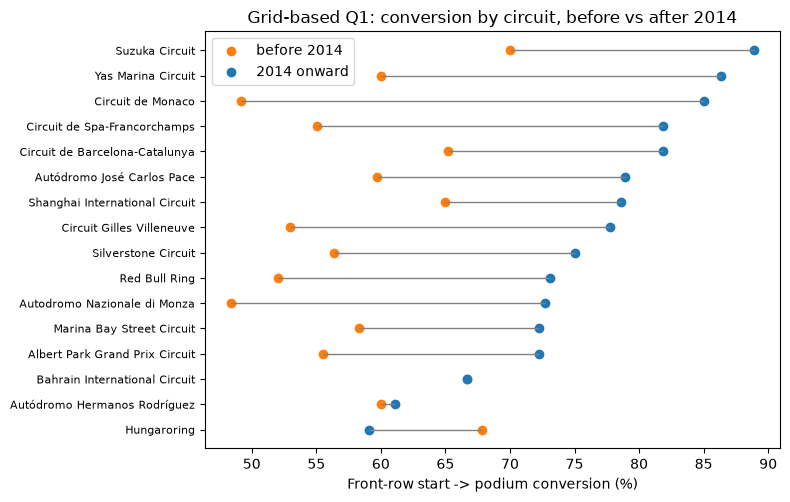


Front-row QUALIFIERS with a usable grid slot: 986  |  changed exact slot: 49  |  actually LEFT the front row (grid > 2): 36
   (also removed above: front-row qualifiers whose grid is 0 = pit-lane start: 2 )


,front-row QUALIFIERS (q_pos<=2),"front-row STARTERS, same races (grid<=2)","front-row STARTERS, all races (grid<=2) = PRIMARY"
era,,,
2014 onward,74.01,75.99,75.99
before 2014,64.66,65.23,56.29


Races with qualifying data: 494 of 1114 - the qualifying-based version cannot describe the earlier seasons.


In [161]:
# Q1.12 (primary answer): the brief asks about a FRONT-ROW START (= the actual grid slot), so the PRIMARY analysis starts from results.grid, not from qualifying.
# Qualifying position is analysed separately below, and the two definitions are reconciled.
indy_circuit_ids = cleaned_tables["circuits"].loc[cleaned_tables["circuits"]["name"].str.contains("Indianapolis", case=False, na=False), "circuitId"]   # same rule as Q2.3b
res_q1 = (cleaned_tables["results"][["raceId", "driverId", "grid", "positionOrder"]]
          .merge(cleaned_tables["races"][["raceId", "year", "circuitId"]], on="raceId", validate="many_to_one")
          .merge(cleaned_tables["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId", validate="many_to_one"))
res_q1["podium"] = (res_q1["positionOrder"] <= 3).astype(int)
res_q1["era"] = np.where(res_q1["year"] < 2014, "before 2014", "2014 onward")
indy_rows = res_q1["circuitId"].isin(indy_circuit_ids) & res_q1["year"].between(1950, 1960)       # the Indy 500 counted for the title but is not a Grand Prix field
base_q1 = res_q1[(res_q1["grid"] > 0) & ~indy_rows]
print("Races in the results table:", res_q1["raceId"].nunique(), "| races kept for the grid-based analysis:", base_q1["raceId"].nunique(),
      "| rows with grid 0 (pit lane / no slot) removed:", int((res_q1["grid"] <= 0).sum()), "| Indy-500 rows removed:", int(indy_rows.sum()))

fr = base_q1[base_q1["grid"] <= 2]
def rank_table(frame, min_starts=10):
    t = (frame.groupby(["era", "circuit"]).agg(front_row_starts=("podium", "size"), podiums=("podium", "sum")).reset_index())
    t["conversion_%"] = 100 * t["podiums"] / t["front_row_starts"]
    return t[t["front_row_starts"] >= min_starts]
tab = rank_table(fr)
for era in ("before 2014", "2014 onward"):
    print(f"\nTop 6 circuits by front-row -> podium conversion, {era} (>= 10 front-row starts):")
    display(tab[tab["era"] == era].sort_values("conversion_%", ascending=False).head(6).round(2).reset_index(drop=True))
print("\nOverall conversion of a front-row START:", fr.groupby("era")["podium"].mean().mul(100).round(2).to_dict())

# Does the ranking change after 2014?  Same circuits in both eras, rank correlation with a race-level (cluster) bootstrap interval
wide = tab.pivot(index="circuit", columns="era", values="conversion_%").dropna()
rho = wide.corr(method="spearman").iloc[0, 1]
rng_q = np.random.default_rng(0); races_by_era = {e: fr[fr["era"] == e]["raceId"].unique() for e in ("before 2014", "2014 onward")}; rhos = []
for _ in range(500):
    parts = []
    for e, rs in races_by_era.items():
        pick = rng_q.choice(rs, len(rs)); b = fr[fr["era"] == e].set_index("raceId").loc[pick].reset_index()
        t = rank_table(b, 10).set_index("circuit")["conversion_%"].rename(e); parts.append(t)
    w = pd.concat(parts, axis=1).dropna()
    if len(w) >= 5: rhos.append(w.corr(method="spearman").iloc[0, 1])
print(f"Circuits present in both eras (>= 10 front-row starts each): {len(wide)} | Spearman rank correlation = {rho:.2f}, 95% bootstrap interval [{np.nanpercentile(rhos, 2.5):.2f}, {np.nanpercentile(rhos, 97.5):.2f}]")
wide["rank_before"] = wide["before 2014"].rank(ascending=False); wide["rank_after"] = wide["2014 onward"].rank(ascending=False); wide["rank_change"] = wide["rank_before"] - wide["rank_after"]
display(wide.sort_values("rank_change", ascending=False).round(1))

fig, ax = plt.subplots(figsize=(8, max(4, 0.32 * len(wide))))
w2 = wide.sort_values("2014 onward"); y = np.arange(len(w2))
ax.hlines(y, w2["before 2014"], w2["2014 onward"], color="grey", lw=1); ax.scatter(w2["before 2014"], y, label="before 2014", color="tab:orange"); ax.scatter(w2["2014 onward"], y, label="2014 onward", color="tab:blue")
ax.set_yticks(y); ax.set_yticklabels(w2.index, fontsize=8); ax.set_xlabel("Front-row start -> podium conversion (%)"); ax.set_title("Grid-based Q1: conversion by circuit, before vs after 2014"); ax.legend(); plt.tight_layout(); plt.show()

# Reconcile qualifying vs grid (the brief: 'distinguish qualifying position from grid')
qq = cleaned_tables["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "q_pos"})
both = base_q1.merge(qq, on=["raceId", "driverId"], how="inner", validate="one_to_one")
front_q = both[both["q_pos"] <= 2]
moved_slot = int((front_q["grid"] != front_q["q_pos"]).sum()); left_front = int((front_q["grid"] > 2).sum())
print(f"\nFront-row QUALIFIERS with a usable grid slot: {len(front_q)}  |  changed exact slot: {moved_slot}  |  actually LEFT the front row (grid > 2): {left_front}")
print("   (also removed above: front-row qualifiers whose grid is 0 = pit-lane start:", int(((qq.merge(res_q1[["raceId", "driverId", "grid"]], on=["raceId", "driverId"])["q_pos"] <= 2) & (qq.merge(res_q1[["raceId", "driverId", "grid"]], on=["raceId", "driverId"])["grid"] <= 0)).sum()), ")")
cmp = pd.DataFrame({"front-row QUALIFIERS (q_pos<=2)": front_q.groupby("era")["podium"].mean() * 100,
                    "front-row STARTERS, same races (grid<=2)": both[both["grid"] <= 2].groupby("era")["podium"].mean() * 100,
                    "front-row STARTERS, all races (grid<=2) = PRIMARY": fr.groupby("era")["podium"].mean() * 100})
display(cmp.round(2)); print("Races with qualifying data:", both["raceId"].nunique(), "of", base_q1["raceId"].nunique(), "- the qualifying-based version cannot describe the earlier seasons.")

<a id="h169"></a>
### Q2.1: Inspect driver nationalities and circuit countries (why a mapping is needed)
<a id="c159"></a>
*Code cell 162* | [Back to contents](#toc)
**Question 2 setup:** "home race" means the driver's nationality equals the circuit's country. The two columns use different vocabularies: drivers have adjectives (`British`, `Monegasque`, `East German`, even `'Argentinian '` with a trailing space), circuits have country names (`UK`, `Monaco`, `USA` and `United States` both). They cannot be compared directly, so a mapping table is required. This is a multi-hop join through `results -> drivers` for nationality and `results -> races -> circuits` for country.


In [162]:
# Inspect driver nationalities
print("Driver nationalities:")
print(
    sorted(
        cleaned_tables["drivers"]["nationality"]
        .dropna()
        .unique()
    )
)

# Inspect circuit countries
print("\nCircuit countries:")
print(
    sorted(
        cleaned_tables["circuits"]["country"]
        .dropna()
        .unique()
    )
)

Driver nationalities:
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

Circuit countries:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


<a id="h170"></a>
### Q2.1b: Nationality-to-country mapping
<a id="c160"></a>
*Code cell 163* | [Back to contents](#toc)
**Why:** nationality adjectives and country names cannot be compared directly, so this cell defines the mapping and the cleaned tables used by every Q2 cell (`drivers_clean`, `circuits_clean`) and lists any nationality left without a mapping (`unmapped`).
**Decisions (documented):** (1) driver nationality (an adjective such as "British") is mapped to the **circuit country** string used in `circuits.csv` (such as "UK"); (2) whitespace is stripped (`'Argentinian '` has a trailing space in the raw data); (3) circuit country labels are unified (`United States` -> `USA`); (4) dual nationalities map to a **set** of countries (`American-Italian` is at home in both USA and Italy); (5) `East German` maps to Germany. A check lists any nationality without a mapping.
**Limitation:** `drivers.nationality` is one *current* nationality per driver, not the nationality at the time of each race.


In [163]:
NATIONALITY_TO_COUNTRIES = {
    "American": {"USA"}, "American-Italian": {"USA", "Italy"}, "Argentine": {"Argentina"},
    "Argentine-Italian": {"Argentina", "Italy"}, "Argentinian": {"Argentina"}, "Australian": {"Australia"},
    "Austrian": {"Austria"}, "Belgian": {"Belgium"}, "Brazilian": {"Brazil"}, "British": {"UK"},
    "Canadian": {"Canada"}, "Chilean": {"Chile"}, "Chinese": {"China"}, "Colombian": {"Colombia"},
    "Czech": {"Czech Republic"}, "Danish": {"Denmark"}, "Dutch": {"Netherlands"}, "East German": {"Germany"},
    "Finnish": {"Finland"}, "French": {"France"}, "German": {"Germany"}, "Hungarian": {"Hungary"},
    "Indian": {"India"}, "Indonesian": {"Indonesia"}, "Irish": {"Ireland"}, "Italian": {"Italy"},
    "Japanese": {"Japan"}, "Liechtensteiner": {"Liechtenstein"}, "Malaysian": {"Malaysia"},
    "Mexican": {"Mexico"}, "Monegasque": {"Monaco"}, "New Zealander": {"New Zealand"}, "Polish": {"Poland"},
    "Portuguese": {"Portugal"}, "Rhodesian": {"Rhodesia"}, "Russian": {"Russia"}, "South African": {"South Africa"},
    "Spanish": {"Spain"}, "Swedish": {"Sweden"}, "Swiss": {"Switzerland"}, "Thai": {"Thailand"},
    "Uruguayan": {"Uruguay"}, "Venezuelan": {"Venezuela"},
}
COUNTRY_ALIASES = {"United States": "USA"}

drivers_clean = cleaned_tables["drivers"].copy()
drivers_clean["nationality_clean"] = drivers_clean["nationality"].astype("string").str.strip()
drivers_clean["home_countries"] = drivers_clean["nationality_clean"].map(NATIONALITY_TO_COUNTRIES)

circuits_clean = cleaned_tables["circuits"].copy()
circuits_clean["country_clean"] = (circuits_clean["country"].astype("string").str.strip()
                                   .replace(COUNTRY_ALIASES))

unmapped = sorted(set(drivers_clean["nationality_clean"].dropna()) - set(NATIONALITY_TO_COUNTRIES))
print("Nationalities without a mapping:", unmapped)
print("Circuit countries after cleaning:", sorted(circuits_clean["country_clean"].dropna().unique()))

Nationalities without a mapping: []
Circuit countries after cleaning: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA']


<a id="h171"></a>
### Q2.2: Preview the nationality mapping
<a id="c161"></a>
*Code cell 164* | [Back to contents](#toc)
Shows each nationality, its cleaned form and the set of home countries (`American-Italian` is at home in USA and Italy). The output reports no unmapped nationality.


In [164]:
print("Unmapped nationalities:", unmapped)

print("\nDriver nationality mapping preview:")

display(
    drivers_clean[
        ["nationality", "nationality_clean", "home_countries"]
    ]
    .assign(
        home_countries=lambda df: df["home_countries"].apply(
            lambda countries: ", ".join(sorted(countries))
            if isinstance(countries, set)
            else None
        )
    )
    .drop_duplicates()
    .sort_values("nationality_clean")
)

Unmapped nationalities: []

Driver nationality mapping preview:


,nationality,nationality_clean,home_countries
25,American,American,USA
491,American-Italian,American-Italian,"Italy, USA"
59,Argentine,Argentine,Argentina
573,Argentine-Italian,Argentine-Italian,"Argentina, Italy"
859,Argentinian,Argentinian,Argentina
16,Australian,Australian,Australia
24,Austrian,Austrian,Austria
91,Belgian,Belgian,Belgium
11,Brazilian,Brazilian,Brazil
0,British,British,UK


<a id="h172"></a>
### Q2.3: Build the Question 2 analysis table and the home flag (multi-hop join)
<a id="c162"></a>
*Code cell 165* | [Back to contents](#toc)
`results` -> `races` (year, circuit) -> `circuits_clean` (country) and `results` -> `drivers_clean` (nationality and home countries), each with `validate="many_to_one"`: the row count stays at **26,668**, so no join multiplied rows. `is_home_race` = the circuit country is in the driver's set of home countries; `podium` = `positionOrder <= 3`.
**Grain:** one row per driver per race. **Result before controlling for grid:** home 10.67% (266 of 2,493) vs away 12.94% (3,129 of 24,175), i.e. home starts look **worse**, which is exactly why the raw comparison is misleading: it ignores where the drivers start. **Cutoff:** nationality, circuit and grid are all known before the race. The home rows include the Indianapolis 500 (1950-1960); this is checked in the cell below.


In [165]:
# 1. Start with cleaned race results
home_analysis = cleaned_tables["results"][
    ["raceId", "driverId", "grid", "positionOrder"]
].copy()

# 2. Join race year and circuit ID
home_analysis = home_analysis.merge(
    cleaned_tables["races"][["raceId", "year", "circuitId"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
)

# 3. Join circuit country
home_analysis = home_analysis.merge(
    circuits_clean[["circuitId", "country_clean"]],
    on="circuitId",
    how="inner",
    validate="many_to_one"
)

# 4. Join driver nationality and mapped home countries
home_analysis = home_analysis.merge(
    drivers_clean[["driverId", "nationality_clean", "home_countries"]],
    on="driverId",
    how="inner",
    validate="many_to_one"
)

# 5. Define home race and podium
home_analysis["is_home_race"] = home_analysis.apply(
    lambda row: (
        row["country_clean"] in row["home_countries"]
        if isinstance(row["home_countries"], set)
        else False
    ),
    axis=1
)

home_analysis["podium"] = (
    home_analysis["positionOrder"] <= 3
).astype(int)

# 6. Inspect the resulting dataset
print("Rows:", len(home_analysis))
print("Columns:", home_analysis.columns.tolist())

print("\nHome vs away race counts:")
display(
    home_analysis["is_home_race"]
    .value_counts()
    .rename(index={True: "Home race", False: "Away race"})
    .to_frame("race_results")
)

print("\nPodium rate before controlling for grid:")
display(
    home_analysis.groupby("is_home_race")
    .agg(
        race_results=("podium", "size"),
        podiums=("podium", "sum"),
        podium_rate=("podium", "mean")
    )
    .assign(
        podium_rate=lambda df: (df["podium_rate"] * 100).round(2)
    )
)

Rows: 26668
Columns: ['raceId', 'driverId', 'grid', 'positionOrder', 'year', 'circuitId', 'country_clean', 'nationality_clean', 'home_countries', 'is_home_race', 'podium']

Home vs away race counts:


,race_results
is_home_race,
Away race,24175
Home race,2493



Podium rate before controlling for grid:


,race_results,podiums,podium_rate
is_home_race,,,
False,24175,3129,12.94
True,2493,266,10.67


<a id="h173"></a>
### Q2.3b: Sanity checks on the home-race flag (grain, composition and the Indianapolis 500 problem)
<a id="c163"></a>
*Code cell 166* | [Back to contents](#toc)
**Why:** a flag built from two text fields can be wrong in ways that totals hide. We check (a) which nationalities generate the home-race rows, (b) how many **distinct drivers** contribute (a handful of drivers would make the result an anecdote), and (c) how many home rows come from the **Indianapolis 500 (1950-1960)**. The introduction warns that this race counted for the championship but was entered almost only by American drivers, so it inflates "home" rows for the USA and distorts the home-race analysis.
**What it creates:** `home_analysis["is_indy500"]`, used by the sensitivity analysis below.


In [166]:
indy_circuit_ids = cleaned_tables["circuits"].loc[
    cleaned_tables["circuits"]["name"].str.contains("Indianapolis", case=False, na=False), "circuitId"]
home_analysis["is_indy500"] = home_analysis["circuitId"].isin(indy_circuit_ids) & home_analysis["year"].between(1950, 1960)

home_rows = home_analysis[home_analysis["is_home_race"]]
print("Home-race rows:", len(home_rows), "| distinct drivers with at least one home race:", home_rows["driverId"].nunique())
print("Home rows coming from the Indianapolis 500 (1950-1960):", int(home_rows["is_indy500"].sum()),
      f"({home_rows['is_indy500'].mean() * 100:.1f}% of home rows)")

print("Home-race rows by driver nationality (top 10):")
display(home_rows.groupby("nationality_clean").agg(rows=("podium", "size"), drivers=("driverId", "nunique"),
                                                   podium_rate=("podium", "mean"))
        .assign(podium_rate=lambda d: (d["podium_rate"] * 100).round(1)).sort_values("rows", ascending=False).head(10))

print("Home rows by decade:")
display(home_rows.groupby((home_rows["year"] // 10) * 10).size().to_frame("home_rows").T)

Home-race rows: 2493 | distinct drivers with at least one home race: 663
Home rows coming from the Indianapolis 500 (1950-1960): 380 (15.2% of home rows)
Home-race rows by driver nationality (top 10):


,rows,drivers,podium_rate
nationality_clean,,,
American,500,142,9.0
British,482,137,14.3
Italian,463,92,6.5
French,218,56,11.9
German,208,47,13.9
Brazilian,119,27,16.8
Belgian,66,20,4.5
Spanish,65,13,13.8
South African,59,22,6.8


Home rows by decade:


year,1950,1960,1970,1980,1990,2000,2010,2020
home_rows,712,339,323,360,323,216,152,68


<a id="h174"></a>
### Q2.4: Compare home and away starts within grid groups (the control)
<a id="c164"></a>
*Code cell 167* | [Back to contents](#toc)
Rows with `grid = 0` (pit-lane starts or non-starters, **1,635 rows**) are removed because they have no comparable grid slot. Remaining starts are put into five grid groups (1-3, 4-6, 7-10, 11-15, 16+) and the podium rate of home and away starts is compared **inside each group**, so home drivers are only compared with drivers who started from similar positions.
**Result:** within every group the rates are nearly identical (1-3: 54.9% home vs 55.5% away; 4-6: 24.5% vs 26.1%; 7-10: 8.8% vs 9.3%; 11-15: 3.4% vs 3.0%; 16+: 0.74% vs 0.73%). The groups are coarse and no uncertainty is shown; both are addressed by the cells that follow.


In [167]:
# Keep only records with a valid, positive grid position.
grid_analysis = home_analysis[
    home_analysis["grid"].notna()
    & (home_analysis["grid"] > 0)
].copy()

# Group similar starting positions.
grid_analysis["grid_group"] = pd.cut(
    grid_analysis["grid"],
    bins=[0, 3, 6, 10, 15, float("inf")],
    labels=[
        "1–3",
        "4–6",
        "7–10",
        "11–15",
        "16+"
    ],
    include_lowest=True
)

# Compare home and away podium rates within each grid group.
grid_comparison = (
    grid_analysis
    .groupby(
        ["grid_group", "is_home_race"],
        observed=False
    )
    .agg(
        race_results=("podium", "size"),
        podiums=("podium", "sum"),
        podium_rate=("podium", "mean")
    )
    .reset_index()
)

grid_comparison["podium_rate"] = (
    grid_comparison["podium_rate"] * 100
).round(2)

grid_comparison["race_type"] = (
    grid_comparison["is_home_race"]
    .map({True: "Home", False: "Away"})
)

display(
    grid_comparison[
        [
            "grid_group",
            "race_type",
            "race_results",
            "podiums",
            "podium_rate"
        ]
    ]
)

print("Records excluded due to invalid or unknown grid:")
print(len(home_analysis) - len(grid_analysis))

,grid_group,race_type,race_results,podiums,podium_rate
0,1–3,Away,3106,1725,55.54
1,1–3,Home,264,145,54.92
2,4–6,Away,3108,812,26.13
3,4–6,Home,261,64,24.52
4,7–10,Away,4123,385,9.34
5,7–10,Home,388,34,8.76
6,11–15,Away,5135,154,3.00
7,11–15,Home,470,16,3.40
8,16+,Away,7237,53,0.73
9,16+,Home,941,7,0.74


Records excluded due to invalid or unknown grid:
1635


<a id="h175"></a>
### Q2.4b: Visualisation of the grid-controlled comparison (the brief requires a visual)
<a id="c165"></a>
*Code cell 168* | [Back to contents](#toc)
**Why:** the grid-group table above is the core of the answer; this is its chart. Bars compare the podium rate of home and away starts **inside the same grid group**, with the number of starts printed above each bar so the reader can judge reliability.
**How to read:** if home starts were really better *after* controlling for grid, the "Home" bar would be higher than the "Away" bar within groups. Bars of equal height mean no visible home effect.


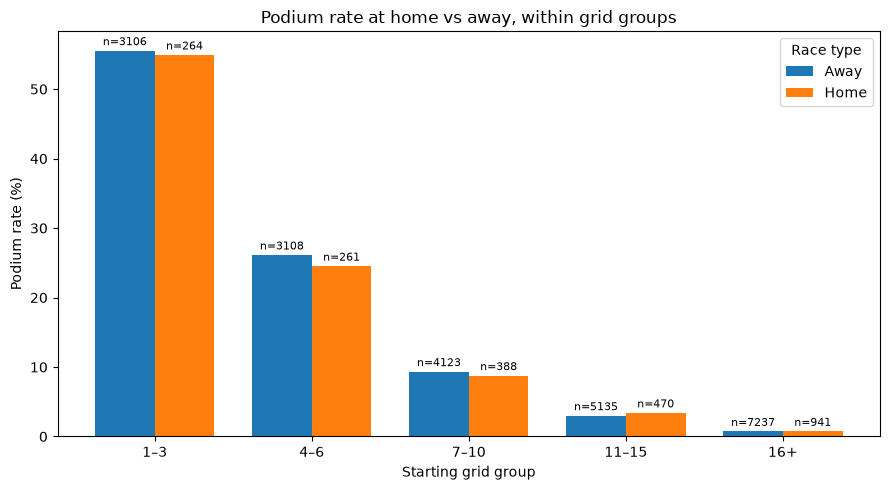

In [168]:
plot_df = grid_comparison.copy()
plot_df["podium_rate"] = plot_df["podium_rate"].fillna(0)   # a group with no home starts would be a NaN bar
groups = list(plot_df["grid_group"].cat.categories)
rates = plot_df.pivot(index="grid_group", columns="race_type", values="podium_rate").reindex(groups)
counts = plot_df.pivot(index="grid_group", columns="race_type", values="race_results").reindex(groups)

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(groups)); width = 0.38
for j, race_type in enumerate(["Away", "Home"]):
    bars = ax.bar(x + (j - 0.5) * width, rates[race_type].fillna(0), width, label=race_type)
    ax.bar_label(bars, labels=[f"n={int(c) if pd.notna(c) else 0}" for c in counts[race_type]], fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(groups)
ax.set_xlabel("Starting grid group"); ax.set_ylabel("Podium rate (%)")
ax.set_title("Podium rate at home vs away, within grid groups"); ax.legend(title="Race type")
plt.tight_layout(); plt.show()

<a id="h176"></a>
### Q2.5: Grid-adjusted home vs away podium rate (direct standardisation)
<a id="c166"></a>
*Code cell 169* | [Back to contents](#toc)
Both groups are re-weighted to the **same** grid-group distribution, so the only difference left is home vs away. **Result:** away 13.59%, home 13.28%, a difference of **-0.31 percentage points**: once the starting position is controlled for, the home effect is essentially zero (the raw gap of about -2.3 points shrinks to -0.3, which suggests that home starts came from somewhat worse grid slots on average). Confidence intervals are added in Q2.5b.


In [169]:
# Calculate podium rates within each grid group and race type.
adjustment_stats = (
    grid_analysis
    .groupby(
        ["grid_group", "is_home_race"],
        observed=True
    )
    .agg(
        starts=("podium", "size"),
        podiums=("podium", "sum")
    )
    .reset_index()
)

adjustment_stats["rate"] = (
    adjustment_stats["podiums"]
    / adjustment_stats["starts"]
)

# Put home and away rates side by side.
rate_pivot = adjustment_stats.pivot(
    index="grid_group",
    columns="is_home_race",
    values="rate"
)

rate_pivot = rate_pivot.rename(
    columns={False: "away_rate", True: "home_rate"}
)

# Use the same grid-group weights for both types of race.
grid_weights = (
    grid_analysis
    .groupby("grid_group", observed=True)
    .size()
)

grid_weights = grid_weights / grid_weights.sum()

# Standardize both rates to the pooled grid distribution.
adjusted_away_rate = (
    rate_pivot["away_rate"] * grid_weights
).sum()

adjusted_home_rate = (
    rate_pivot["home_rate"] * grid_weights
).sum()

adjusted_difference = (
    adjusted_home_rate - adjusted_away_rate
) * 100

print(f"Grid-adjusted away podium rate: {adjusted_away_rate * 100:.2f}%")
print(f"Grid-adjusted home podium rate: {adjusted_home_rate * 100:.2f}%")
print(f"Adjusted difference (home - away): {adjusted_difference:+.2f} percentage points")

Grid-adjusted away podium rate: 13.59%
Grid-adjusted home podium rate: 13.28%
Adjusted difference (home - away): -0.31 percentage points


<a id="h177"></a>
### Q2.5b: Stronger control for starting position: exact-grid stratification with a confidence interval
<a id="c167"></a>
*Code cell 170* | [Back to contents](#toc)
**Why:** the earlier adjustment uses five **coarse** grid groups (1-3, 4-6, ...). Inside "1-3" a pole sitter and a P3 starter are treated as equal although their podium chances differ a lot, and a result of -0.31 points comes with **no measure of uncertainty**. Here every exact grid slot 1-19 (and 20+) is its own stratum, home and away are compared inside each stratum, and the strata are combined with the pooled grid distribution (direct standardisation). We also compute the **Mantel-Haenszel odds ratio**. Confidence intervals come from a **cluster bootstrap over races** (a race is resampled as a whole, because podium results within a race are not independent).
**Excluded:** rows with `grid = 0` (pit-lane or non-starters) are removed, exactly as in the earlier cell, because they have no comparable starting position.
**Reading:** an interval that contains 0 percentage points (or an odds ratio interval that contains 1) means no detectable home advantage.


In [170]:
def adjusted_gap(df, cap=20, n_boot=1000, seed=42):
    """Home-minus-away podium rate after standardising on exact grid slot, with a cluster bootstrap over races."""
    d = df[df["grid"] > 0].copy()
    d["stratum"] = d["grid"].clip(upper=cap).astype(int)
    strata = np.sort(d["stratum"].unique())
    races_ = d["raceId"].unique()
    r_idx = pd.Series(np.arange(len(races_)), index=races_)[d["raceId"]].to_numpy()
    s_idx = pd.Series(np.arange(len(strata)), index=strata)[d["stratum"]].to_numpy()
    h = d["is_home_race"].astype(int).to_numpy()
    pod = d["podium"].to_numpy()
    N = np.zeros((len(races_), len(strata), 2))
    K = np.zeros_like(N)
    np.add.at(N, (r_idx, s_idx, h), 1)
    np.add.at(K, (r_idx, s_idx, h), pod)

    def statistic(w):
        n = np.tensordot(w, N, axes=(0, 0))
        k = np.tensordot(w, K, axes=(0, 0))
        ok = (n[:, 0] > 0) & (n[:, 1] > 0)
        weights = (n[ok, 0] + n[ok, 1]) / (n[ok, 0] + n[ok, 1]).sum()
        away = (k[ok, 0] / n[ok, 0] * weights).sum()
        home = (k[ok, 1] / n[ok, 1] * weights).sum()
        a, b, c, dd = k[ok, 1], n[ok, 1] - k[ok, 1], k[ok, 0], n[ok, 0] - k[ok, 0]
        tot = n[ok, 0] + n[ok, 1]
        with np.errstate(divide="ignore", invalid="ignore"):
            odds = (a * dd / tot).sum() / (b * c / tot).sum()
        return home * 100, away * 100, (home - away) * 100, odds

    est = statistic(np.ones(len(races_)))
    rng = np.random.default_rng(seed)
    boots = np.array([statistic(rng.multinomial(len(races_), np.ones(len(races_)) / len(races_))) for _ in range(n_boot)])
    lo_d, hi_d = np.nanpercentile(boots[:, 2], [2.5, 97.5])
    lo_o, hi_o = np.nanpercentile(boots[:, 3], [2.5, 97.5])
    return {"home_starts": int(h.sum()), "adj_home_%": est[0], "adj_away_%": est[1], "diff_pp": est[2],
            "diff_ci_low": lo_d, "diff_ci_high": hi_d, "mh_odds_ratio": est[3], "or_ci_low": lo_o, "or_ci_high": hi_o}

main_result = adjusted_gap(home_analysis)
print(pd.Series(main_result).round(3).to_string())

home_starts      2324.000
adj_home_%         13.346
adj_away_%         13.583
diff_pp            -0.236
diff_ci_low        -1.472
diff_ci_high        1.053
mh_odds_ratio       0.969
or_ci_low           0.831
or_ci_high          1.124


<a id="h178"></a>
### Q2.5c: Cross-check with a logistic regression
<a id="c168"></a>
*Code cell 171* | [Back to contents](#toc)
**Why:** stratification can only control for grid. A regression lets us control for grid slot **and** the decade (cars, reliability and field size change a lot across eras, and home races are not spread evenly over eras) at the same time. Model: `podium ~ is_home + C(exact grid, capped at 20) + C(decade)`, with standard errors **clustered by driver** (the same driver appears in many rows). The odds ratio for `is_home` should be close to the Mantel-Haenszel value above if the conclusion is robust.
**Note:** the cell is skipped with a message if `statsmodels` is not installed.


In [171]:
try:
    import statsmodels.formula.api as smf

    model_df = grid_analysis.copy()
    model_df["grid_capped"] = model_df["grid"].clip(upper=20).astype(int)
    model_df["decade"] = (model_df["year"] // 10 * 10).astype(str)
    model_df["home"] = model_df["is_home_race"].astype(int)
    logit = smf.logit("podium ~ home + C(grid_capped) + C(decade)", data=model_df).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": model_df["driverId"]})
    odds_ratio = float(np.exp(logit.params["home"]))
    ci_low, ci_high = np.exp(logit.conf_int().loc["home"]).astype(float)
    print(f"Home odds ratio (grid + decade controlled): {odds_ratio:.2f}  95% CI [{ci_low:.2f}, {ci_high:.2f}]  p = {logit.pvalues['home']:.3f}")
except ImportError:
    print("statsmodels is not installed: skipping the regression cross-check.")

Home odds ratio (grid + decade controlled): 0.94  95% CI [0.77, 1.14]  p = 0.531


<a id="h179"></a>
### Q2.5d: Sensitivity of the home-advantage estimate and a forest plot
<a id="c169"></a>
*Code cell 172* | [Back to contents](#toc)
**Why:** a conclusion is only trustworthy if it survives reasonable changes in the data. We repeat the exact-grid estimate for (1) all races, (2) **without the Indianapolis 500**, (3) only the seasons covered by qualifying data (the modern, better-recorded era), and (4) only 2014 onward. The forest plot shows the estimate and 95% interval of each specification; the dashed line is "no effect".
**Cutoff:** home status and grid are known before the race, the podium outcome is the label, so nothing here mixes post-race information into the explanatory side.


,specification,home_starts,adj_home_%,adj_away_%,diff_pp,diff_ci_low,diff_ci_high,mh_odds_ratio,or_ci_low,or_ci_high
0,All races,2324,13.35,13.58,-0.24,-1.56,1.12,0.97,0.82,1.13
1,Without Indianapolis 500 (1950-60),1944,13.50,13.65,-0.14,-1.33,1.09,0.97,0.82,1.12
2,Qualifying era only (>= 1994),593,11.91,14.28,-2.38,-4.52,-0.34,0.69,0.50,0.92
3,2014 onward,144,17.08,15.08,2.00,-3.63,5.62,0.86,0.44,1.49


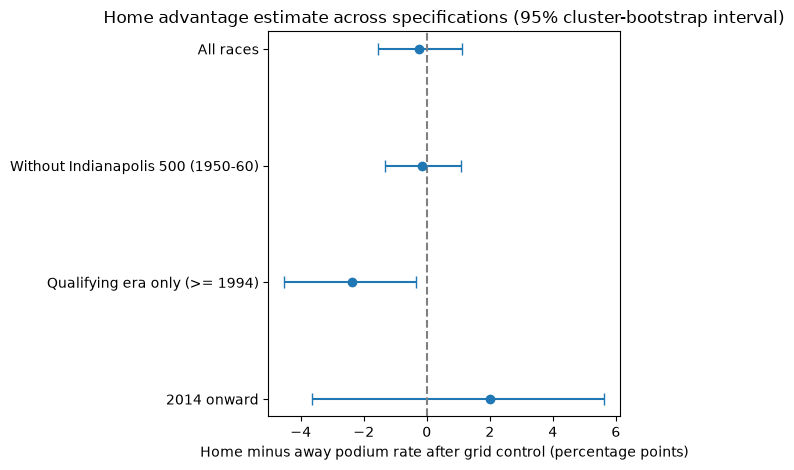

In [172]:
first_quali_year = int(q1["year"].min())
specs = {
    "All races": home_analysis,
    "Without Indianapolis 500 (1950-60)": home_analysis[~home_analysis["is_indy500"]],
    f"Qualifying era only (>= {first_quali_year})": home_analysis[home_analysis["year"] >= first_quali_year],
    "2014 onward": home_analysis[home_analysis["year"] >= 2014],
}
sens_rows = []
for label, data in specs.items():
    sens_rows.append({"specification": label, **adjusted_gap(data, n_boot=500)})
sens_table = pd.DataFrame(sens_rows)
display(sens_table.round(2))

y = np.arange(len(sens_table))[::-1]
plt.errorbar(sens_table["diff_pp"], y,
             xerr=[sens_table["diff_pp"] - sens_table["diff_ci_low"], sens_table["diff_ci_high"] - sens_table["diff_pp"]],
             fmt="o", capsize=4)
plt.axvline(0, color="grey", linestyle="--")
plt.yticks(y, sens_table["specification"])
plt.xlabel("Home minus away podium rate after grid control (percentage points)")
plt.title("Home advantage estimate across specifications (95% cluster-bootstrap interval)")
plt.tight_layout(); plt.show()

<a id="h190"></a>
### Q2.6: Final Q2 table — the answer across specifications
<a id="c180"></a>
*Code cell 173* | [Back to contents](#toc)
**Why:** the pooled estimate is near zero but the 1994-onward run has an interval that excludes zero, so the conclusion must say the result depends on the population. The cell also checks that drivers *really started* (laps ≥ 1), and shows how many home starts are retained in strata that have both home and away drivers.
**Output:** one table (specification, home starts, difference in points, 95% interval, retained home starts) and a sentence listing which specifications exclude zero.


In [173]:
# Q2.6: the final Q2 answer follows from this sensitivity table; "started" is checked with laps; the retained population is accounted for
laps_q2 = cleaned_tables["results"][["raceId", "driverId", "laps"]]
ha = home_analysis.merge(laps_q2, on=["raceId", "driverId"], how="left", validate="one_to_one")
specs2 = {
    "All races, grid > 0": ha,
    "grid > 0 AND completed >= 1 lap (really started the race)": ha[ha["laps"].fillna(0) > 0],
    "Without Indianapolis 500": ha[~ha["is_indy500"]],
    "1994 onward (modern pit-stop / grid regime)": ha[ha["year"] >= 1994],
    "2014 onward": ha[ha["year"] >= 2014],
}
rows = []
for label, d in specs2.items():
    r = adjusted_gap(d, n_boot=500)
    dd = d[d["grid"] > 0].assign(stratum=lambda x: x["grid"].clip(upper=20).astype(int)); cnt = dd.groupby(["stratum", "is_home_race"]).size().unstack(fill_value=0)
    ok = cnt[(cnt.get(True, 0) > 0) & (cnt.get(False, 0) > 0)].index
    home_all = int(dd["is_home_race"].sum()); home_kept = int(dd[dd["stratum"].isin(ok)]["is_home_race"].sum())
    rows.append({"specification": label, **{k: r[k] for k in ("home_starts", "diff_pp", "diff_ci_low", "diff_ci_high")}, "home starts kept in overlapping strata": f"{home_kept}/{home_all}"})
q2_tab = pd.DataFrame(rows); display(q2_tab.round(2))
sig = q2_tab[(q2_tab["diff_ci_low"] > 0) | (q2_tab["diff_ci_high"] < 0)]
print("Specifications whose 95% interval EXCLUDES zero:", sig["specification"].tolist() if len(sig) else "none")
print("READING: the pooled estimate is near zero, but it depends on the population. " +
      ("In the specifications listed above home races show a small LOWER podium rate after grid control - not a home ADVANTAGE; " if len(sig) else "") +
      "nowhere is a positive home effect supported. The honest statement is: no evidence of a home advantage after controlling for the starting slot; any small negative gap is population-sensitive and not causal.")

,specification,home_starts,diff_pp,diff_ci_low,diff_ci_high,home starts kept in overlapping strata
0,"All races, grid > 0",2324,-0.24,-1.56,1.12,2324/2324
1,grid > 0 AND completed >= 1 lap (really starte...,2229,-0.28,-1.63,1.10,2229/2229
2,Without Indianapolis 500,1944,-0.14,-1.33,1.09,1944/1944
3,1994 onward (modern pit-stop / grid regime),593,-2.38,-4.52,-0.34,593/593
4,2014 onward,144,2.00,-3.63,5.62,144/144


Specifications whose 95% interval EXCLUDES zero: ['1994 onward (modern pit-stop / grid regime)']
READING: the pooled estimate is near zero, but it depends on the population. In the specifications listed above home races show a small LOWER podium rate after grid control - not a home ADVANTAGE; nowhere is a positive home effect supported. The honest statement is: no evidence of a home advantage after controlling for the starting slot; any small negative gap is population-sensitive and not causal.


<a id="h180"></a>
### Q3.1: Build the Question 3 table and audit the statuses (multi-hop join)
<a id="c170"></a>
*Code cell 174* | [Back to contents](#toc)
`results` (car's `constructorId`, laps, `statusId`) -> `races` (year) and -> `status` (cause text), both `many_to_one`, filtered to 2014-2024. **Grain:** one row per driver per race. The status table is the only source of *why* a race ended, so the join to `status` is what makes this question impossible from `results.csv` alone. The grouped output shows that the 2014-2024 results contain 288 different (year, status) combinations, which is why the causes need to be grouped explicitly.
**Missingness:** no missing status after the join. **Cutoff:** `status` is only known after the race, so this answer is descriptive.


In [174]:
# Join race years to results, then inspect statuses.
retirement_audit = cleaned_tables["results"][
    ["raceId", "constructorId", "grid", "laps", "statusId"]
].merge(
    cleaned_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
).merge(
    cleaned_tables["status"][["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

retirement_audit = retirement_audit[
    retirement_audit["year"].between(2014, 2024)
].copy()

status_summary = (
    retirement_audit
    .groupby(["year", "status"], dropna=False)
    .size()
    .reset_index(name="records")
)

display(
    status_summary.sort_values(
        ["year", "records"],
        ascending=[True, False]
    )
)

,year,status,records
16,2014,Finished,200
0,2014,+1 Lap,95
1,2014,+2 Laps,22
7,2014,Collision,14
4,2014,Accident,9
...,...,...,...
280,2024,Hydraulics,1
281,2024,Overheating,1
282,2024,Power Unit,1
283,2024,Radiator,1


<a id="h181"></a>
### Q3.2: List every status found in 2014-2024
<a id="c171"></a>
*Code cell 175* | [Back to contents](#toc)
**66 distinct status descriptions.** Finished (2,403) and lapped finishes dominate; the failure causes include Engine (81), Collision (150), Accident (85), Brakes (49), Gearbox (42), Power Unit (42) and a long tail of one-off components. Reading this list is what lets us split mechanical failures from crashes, driver causes and regulation decisions.


In [175]:
status_list = (
    retirement_audit
    .groupby("status", dropna=False)
    .size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
)

print("Number of distinct status descriptions:", len(status_list))

display(status_list.reset_index(drop=True))

Number of distinct status descriptions: 66


,status,records
0,Finished,2403
1,+1 Lap,1178
2,+2 Laps,208
3,Collision,150
4,Accident,85
5,Engine,81
6,Collision damage,59
7,Retired,50
8,Brakes,49
9,Gearbox,42


<a id="h182"></a>
### Q3.3: Classify statuses and compute the mechanical flag
<a id="c172"></a>
*Code cell 176* | [Back to contents](#toc)
The brief defines a mechanical retirement as a race start that ended early because a **component of the car failed**, excluding crashes, driver causes and regulation decisions. The cell builds an explicit set of mechanical statuses (engine, gearbox, brakes, hydraulics, ERS, battery, ...), flags `mechanical_failure`, assigns the era (`2014-2021` vs `2022-2024`) and prints the totals: **313** flagged records in 2014-2021 and **74** in 2022-2024.
 **Borderline statuses:** `Mechanical`, `Puncture` and `Tyre` fit more than one candidate set; Q3.4b gives every status exactly one documented category and tests strict / base / broad variants.


In [176]:
# Explicit mechanical/component-failure statuses observed in the data.
mechanical_statuses = {
    "Engine",
    "Brakes",
    "Gearbox",
    "Power Unit",
    "Suspension",
    "Hydraulics",
    "Electrical",
    "Wheel",
    "Oil leak",
    "Overheating",
    "Water pressure",
    "Mechanical",
    "Turbo",
    "Battery",
    "Fuel pressure",
    "Exhaust",
    "ERS",
    "Electronics",
    "Water leak",
    "Transmission",
    "Wheel nut",
    "Radiator",
    "Oil pressure",
    "Throttle",
    "Clutch",
    "Driveshaft",
    "Fuel leak",
    "Vibrations",
    "Steering",
    "Fuel system",
    "Fuel pump",
    "Drivetrain",
    "Brake duct",
    "Cooling system",
    "Differential",
    "Spark plugs",
    "Water pump",
    "Puncture",
    "Tyre",
}

# Generic/ambiguous statuses are deliberately not counted as mechanical.
ambiguous_statuses = {
    "Retired",
    "Withdrew",
    "Mechanical",  # Explicitly mechanical; retained in the explicit list above.
    "Technical",
    "Power loss",
    "Damage",
    "Undertray",
    "Front wing",
    "Rear wing",
}

# Classify statuses for the analysis.
retirement_audit["mechanical_failure"] = (
    retirement_audit["status"].isin(mechanical_statuses)
)

retirement_audit["ambiguous_status"] = (
    retirement_audit["status"].isin(ambiguous_statuses)
)

print("Mechanical-failure records by era:")

retirement_audit["era"] = retirement_audit["year"].apply(
    lambda year: (
        "2014–2021" if year <= 2021 else "2022–2024"
    )
)

display(
    retirement_audit.groupby("era").agg(
        records=("status", "size"),
        mechanical_failures=("mechanical_failure", "sum"),
        ambiguous_records=("ambiguous_status", "sum")
    )
)

print("\nRecords with grid = 0, by status:")
display(
    retirement_audit[retirement_audit["grid"].eq(0)]
    .groupby("status")
    .size()
    .sort_values(ascending=False)
    .to_frame("records")
)

print("\nMechanical statuses observed:")
display(
    retirement_audit[
        retirement_audit["mechanical_failure"]
    ]["status"]
    .value_counts()
    .to_frame("records")
)

Mechanical-failure records by era:


,records,mechanical_failures,ambiguous_records
era,,,
2014–2021,3267,313,70
2022–2024,1359,74,28



Records with grid = 0, by status:


,records
status,
+1 Lap,27
Finished,22
+2 Laps,7
Collision damage,3
Withdrew,3
Accident,2
Retired,2
Power Unit,2
Brakes,2



Mechanical statuses observed:


,records
status,
Engine,81
Brakes,49
Power Unit,42
Gearbox,42
Suspension,25
Hydraulics,15
Electrical,14
Wheel,11
Oil leak,10


<a id="h183"></a>
### Q3.4: Define a race start, join constructors and compute the rate per constructor and era
<a id="c173"></a>
*Code cell 177* | [Back to contents](#toc)
**Denominator:** `race_start_proxy` = completed at least one lap, or the status is a mechanical failure or an incident; explicit non-starters (withdrew, did not qualify, excluded) are removed when they completed no lap. This removes **11 of 4,626** rows. **Join:** `constructors` adds the name (`many_to_one`). **Grain:** one row per car start. **Rate** = mechanical retirements / race starts, with at least 20 starts per constructor and era.
**Result (by `constructorId`):** 2014-2021 highest: Caterham 23.53% (8 of 34), Lotus F1 17.33%, Toro Rosso 16.12%, Renault 13.50%, McLaren 13.48%. 2022-2024 highest: Alpine 11.03% (15 of 136), Alfa Romeo 10.23%, AlphaTauri 6.82%, Ferrari 5.88%.
 Each rename has its own `constructorId`, so one team is split across rows (Toro Rosso / AlphaTauri / RB; Lotus / Renault / Alpine); Q3.4c adds a lineage view.


In [177]:
# Known statuses indicating a race-ending incident after starting.
incident_statuses = {
    "Accident",
    "Collision",
    "Collision damage",
    "Spun off",
    "Retired",
    "Power loss",
    "Technical",
    "Puncture",
    "Tyre",
    "Debris",
    "Damage",
    "Undertray",
    "Front wing",
    "Rear wing",
    "Out of fuel",
    "Illness",
    "Disqualified",
}

# Explicit non-start statuses: exclude these unless laps > 0.
nonstart_statuses = {
    "Withdrew",
    "Did not qualify",
    "Did not prequalify",
    "Excluded",
    "107% Rule",
}

# Operational proxy for a race start:
# positive completed laps OR a known post-start failure/incident.
retirement_audit["race_start_proxy"] = (
    retirement_audit["laps"].fillna(0).gt(0)
    | retirement_audit["status"].isin(mechanical_statuses)
    | retirement_audit["status"].isin(incident_statuses)
)

# Exclude explicit non-start statuses when no laps were completed.
retirement_audit.loc[
    retirement_audit["status"].isin(nonstart_statuses)
    & retirement_audit["laps"].fillna(0).eq(0),
    "race_start_proxy"
] = False

# Keep only the two requested periods and race-start opportunities.
started_records = retirement_audit[
    retirement_audit["race_start_proxy"]
    & retirement_audit["year"].between(2014, 2024)
].copy()

# Join constructor names.
started_records = started_records.merge(
    cleaned_tables["constructors"][["constructorId", "name"]],
    on="constructorId",
    how="left",
    validate="many_to_one"
).rename(columns={"name": "constructor"})

# Summarize each constructor by period.
constructor_rates = (
    started_records
    .groupby(["era", "constructorId", "constructor"])
    .agg(
        race_starts=("race_start_proxy", "size"),
        mechanical_retirements=("mechanical_failure", "sum")
    )
    .reset_index()
)

constructor_rates["mechanical_retirement_rate"] = (
    constructor_rates["mechanical_retirements"]
    / constructor_rates["race_starts"]
    * 100
)

constructor_rates["mechanical_retirement_rate"] = (
    constructor_rates["mechanical_retirement_rate"].round(2)
)

# Display top constructors in each era.
for era in ["2014–2021", "2022–2024"]:
    print(f"\nTop constructors by mechanical-retirement rate: {era}")

    display(
        constructor_rates[
            (constructor_rates["era"] == era)
            & (constructor_rates["race_starts"] >= 20)
        ]
        .sort_values(
            ["mechanical_retirement_rate", "race_starts"],
            ascending=[False, False]
        )
        .head(15)
    )

print("\nRace-start proxy audit:")
print("All records in 2014–2024:", len(retirement_audit))
print("Included race-start records:", len(started_records))
print(
    "Excluded records:",
    len(retirement_audit) - len(started_records)
)


Top constructors by mechanical-retirement rate: 2014–2021


,era,constructorId,constructor,race_starts,mechanical_retirements,mechanical_retirement_rate
12,2014–2021,207,Caterham,34,8,23.53
13,2014–2021,208,Lotus F1,75,13,17.33
3,2014–2021,5,Toro Rosso,242,39,16.12
2,2014–2021,4,Renault,200,27,13.50
0,2014–2021,1,McLaren,319,43,13.48
7,2014–2021,15,Sauber,200,22,11.00
5,2014–2021,9,Red Bull,319,34,10.66
16,2014–2021,211,Racing Point,76,8,10.53
17,2014–2021,213,AlphaTauri,78,8,10.26
11,2014–2021,206,Marussia,31,3,9.68



Top constructors by mechanical-retirement rate: 2022–2024


,era,constructorId,constructor,race_starts,mechanical_retirements,mechanical_retirement_rate
29,2022–2024,214,Alpine F1 Team,136,15,11.03
24,2022–2024,51,Alfa Romeo,88,9,10.23
28,2022–2024,213,AlphaTauri,88,6,6.82
21,2022–2024,6,Ferrari,136,8,5.88
20,2022–2024,3,Williams,134,7,5.22
26,2022–2024,131,Mercedes,136,6,4.41
30,2022–2024,215,RB F1 Team,48,2,4.17
25,2022–2024,117,Aston Martin,134,5,3.73
27,2022–2024,210,Haas F1 Team,135,5,3.70
19,2022–2024,1,McLaren,136,5,3.68



Race-start proxy audit:
All records in 2014–2024: 4626
Included race-start records: 4615
Excluded records: 11


<a id="h184"></a>
### Q3.4b: Documented status classification and a strict / base / broad sensitivity
<a id="c174"></a>
*Code cell 178* | [Back to contents](#toc)
**Why:** the definition in the brief (a component failed; **not** a crash, the driver, or a regulation decision) is a judgement over 66 free-text statuses, and the sets defined in Q3.3 and Q3.4 overlap: `Mechanical` is in both the mechanical and the "ambiguous" set, and `Puncture` and `Tyre` are in both the mechanical and the "incident" set. Because the answer depends on this mapping, the mapping must be written down and tested.
**What this cell does:** (1) lists the status values that sit in two sets; (2) assigns **every** status found in 2014-2024 to exactly one category and shows any status left unclassified (it should be none); (3) recomputes the results under three definitions: **strict** (clear component failures only, without tyre/wheel/vibration), **base** (the Q3.3 list) and **broad** (adds power loss, technical, damage, undertray, wings). If the era comparison and the constructor ranking hold under all three, the answer does not depend on the grey cases.


In [178]:
import re

contested = {"Puncture", "Tyre", "Wheel", "Wheel nut", "Vibrations"}
mech_base = set(mechanical_statuses)
mech_strict = mech_base - contested
mech_broad = mech_base | {"Power loss", "Technical", "Damage", "Undertray", "Front wing", "Rear wing"}
crash_driver = {"Accident", "Collision", "Collision damage", "Spun off", "Debris", "Out of fuel", "Illness"}
regulation = {"Disqualified", "Excluded"}
generic_or_nonstart = {"Retired", "Withdrew", "Did not qualify", "Did not prequalify", "107% Rule"}

overlap = sorted(mech_base & (set(ambiguous_statuses) | set(incident_statuses)))
print("Statuses that appear in the mechanical set AND in the ambiguous/incident sets:", overlap)

def categorise(status):
    s = str(status)
    if s == "Finished" or re.fullmatch(r"\+\d+ Laps?", s):
        return "finished (incl. lapped)"
    if s in mech_strict:
        return "mechanical: strict"
    if s in contested:
        return "mechanical: contested (tyre / wheel / vibration)"
    if s in mech_broad:
        return "possibly mechanical (broad only)"
    if s in crash_driver:
        return "crash / driver / external"
    if s in regulation:
        return "regulation decision"
    if s in generic_or_nonstart:
        return "generic or non-start (cause unknown)"
    return "UNCLASSIFIED"

status_map = (retirement_audit["status"].value_counts().rename_axis("status").reset_index(name="records"))
status_map["category"] = status_map["status"].map(categorise)
display(status_map.groupby("category").agg(statuses=("status", "size"), records=("records", "sum")))
print("Unclassified statuses:", status_map.loc[status_map["category"] == "UNCLASSIFIED", "status"].tolist())

definitions = {"strict": mech_strict, "base (notebook)": mech_base, "broad": mech_broad}
era_rows, constructor_by_def = [], {}
for label, status_set in definitions.items():
    tmp = started_records.assign(mech=started_records["status"].isin(status_set))
    for era_name, g in tmp.groupby("era"):
        era_rows.append({"definition": label, "era": era_name, "race_starts": len(g),
                         "mechanical_retirements": int(g["mech"].sum()),
                         "rate_%": round(g["mech"].mean() * 100, 2)})
    by_con = (tmp.groupby(["era", "constructor"]).agg(starts=("mech", "size"), mech=("mech", "sum")).reset_index())
    by_con["rate"] = by_con["mech"] / by_con["starts"] * 100
    constructor_by_def[label] = by_con[by_con["starts"] >= 20]
era_def = pd.DataFrame(era_rows)
display(era_def.pivot(index="definition", columns="era", values="rate_%"))

for era_name in sorted(started_records["era"].unique()):
    merged = None
    for label, tbl in constructor_by_def.items():
        part = tbl[tbl["era"] == era_name][["constructor", "rate"]].rename(columns={"rate": label})
        merged = part if merged is None else merged.merge(part, on="constructor", how="outer")
    print(f"Spearman correlation of constructor rates across definitions, {era_name}:")
    display(merged.drop(columns="constructor").corr(method="spearman").round(2))

Statuses that appear in the mechanical set AND in the ambiguous/incident sets: ['Mechanical', 'Puncture', 'Tyre']


,statuses,records
category,,
UNCLASSIFIED,1,1
crash / driver / external,7,310
finished (incl. lapped),9,3825
generic or non-start (cause unknown),2,64
mechanical: contested (tyre / wheel / vibration),5,27
mechanical: strict,34,360
possibly mechanical (broad only),6,27
regulation decision,2,12


Unclassified statuses: ['Seat']


era,2014–2021,2022–2024
definition,,
base (notebook),9.60,5.46
broad,10.15,6.13
strict,8.80,5.39


Spearman correlation of constructor rates across definitions, 2014–2021:


,strict,base (notebook),broad
strict,1.00,0.99,0.98
base (notebook),0.99,1.00,0.99
broad,0.98,0.99,1.00


Spearman correlation of constructor rates across definitions, 2022–2024:


,strict,base (notebook),broad
strict,1.00,0.96,0.87
base (notebook),0.96,1.00,0.94
broad,0.87,0.94,1.00


<a id="h185"></a>
### Q3.4c: Denominator audit (what counts as a "race start") and constructor lineages
<a id="c175"></a>
*Code cell 179* | [Back to contents](#toc)
**Why 1: the denominator.** The definition asks for the rate among **race starts**. The `race_start_proxy` above mixes laps and statuses: a row counts as a start when `laps > 0` **or** its status is mechanical or an incident, so a car that failed before completing lap 1 counts as a start while a non-starter does not. The proxy removes only 11 of 4,626 rows, so the impact is expected to be tiny; this is checked here: the excluded rows are listed and the era rates are recomputed with two alternative denominators (all result rows, and only rows with `grid > 0`).
**Why 2: constructor identity.** The introduction warns that each rename gets a new `constructorId`, which **splits one team into several** (Force India -> Racing Point -> Aston Martin; Toro Rosso -> AlphaTauri -> RB; Lotus F1 -> Renault -> Alpine; Sauber -> Alfa Romeo; Marussia -> Manor). Treating them separately lowers the number of starts per row and can hide a team that is reliable or unreliable across eras. The table by `constructorId` stays as the literal answer; the lineage table is an explicit, documented alternative with 95% Wilson intervals.


In [179]:
excluded_rows = retirement_audit[~retirement_audit["race_start_proxy"]]
print("Rows excluded by the race-start proxy:", len(excluded_rows))
display(excluded_rows[["year", "status", "laps", "grid", "constructorId"]].sort_values("year"))

denominators = {
    "notebook proxy": started_records,
    "all result rows 2014-2024": retirement_audit,
    "rows with grid > 0": retirement_audit[retirement_audit["grid"] > 0],
}
den_rows = []
for label, frame in denominators.items():
    for era_name, g in frame.groupby("era"):
        den_rows.append({"denominator": label, "era": era_name, "starts": len(g),
                         "mechanical": int(g["mechanical_failure"].sum()),
                         "rate_%": round(g["mechanical_failure"].mean() * 100, 2)})
display(pd.DataFrame(den_rows).pivot(index="denominator", columns="era", values="rate_%"))

LINEAGE = {
    "Force India": "Silverstone team (Force India / Racing Point / Aston Martin)",
    "Racing Point": "Silverstone team (Force India / Racing Point / Aston Martin)",
    "Aston Martin": "Silverstone team (Force India / Racing Point / Aston Martin)",
    "Toro Rosso": "Faenza team (Toro Rosso / AlphaTauri / RB)",
    "AlphaTauri": "Faenza team (Toro Rosso / AlphaTauri / RB)",
    "RB F1 Team": "Faenza team (Toro Rosso / AlphaTauri / RB)",
    "Lotus F1": "Enstone team (Lotus / Renault / Alpine)",
    "Renault": "Enstone team (Lotus / Renault / Alpine)",
    "Alpine F1 Team": "Enstone team (Lotus / Renault / Alpine)",
    "Sauber": "Hinwil team (Sauber / Alfa Romeo)",
    "Alfa Romeo": "Hinwil team (Sauber / Alfa Romeo)",
    "Marussia": "Marussia / Manor",
    "Manor Marussia": "Marussia / Manor",
}
started_records["lineage"] = started_records["constructor"].map(LINEAGE).fillna(started_records["constructor"])
print("Constructor names grouped into a lineage:", sorted(set(LINEAGE) & set(started_records["constructor"])))

lineage_rates = (started_records.groupby(["era", "lineage"])
                 .agg(race_starts=("race_start_proxy", "size"), mechanical_retirements=("mechanical_failure", "sum"))
                 .reset_index())
lineage_rates["rate_%"] = (lineage_rates["mechanical_retirements"] / lineage_rates["race_starts"] * 100).round(2)
low, high = wilson_interval(lineage_rates["mechanical_retirements"], lineage_rates["race_starts"])
lineage_rates["ci_low_%"], lineage_rates["ci_high_%"] = low.round(1), high.round(1)

for era_name in sorted(lineage_rates["era"].unique()):
    print(f"Top lineages by mechanical-retirement rate: {era_name} (at least 20 starts)")
    display(lineage_rates[(lineage_rates["era"] == era_name) & (lineage_rates["race_starts"] >= 20)]
            .sort_values("rate_%", ascending=False).head(8))

Rows excluded by the race-start proxy: 11


,year,status,laps,grid,constructorId
22076,2014,Withdrew,0,14,10
22163,2014,Withdrew,0,15,208
22460,2015,Withdrew,0,0,3
22461,2015,Withdrew,0,17,1
22462,2015,Withdrew,0,12,9
23142,2016,Withdrew,0,20,210
23252,2016,Withdrew,0,7,210
25347,2022,Withdrew,0,0,210
26038,2023,Withdrew,0,0,117
26596,2024,Withdrew,0,10,117


era,2014–2021,2022–2024
denominator,,
all result rows 2014-2024,9.58,5.45
notebook proxy,9.60,5.46
rows with grid > 0,9.42,5.46


Constructor names grouped into a lineage: ['Alfa Romeo', 'AlphaTauri', 'Alpine F1 Team', 'Aston Martin', 'Force India', 'Lotus F1', 'Manor Marussia', 'Marussia', 'RB F1 Team', 'Racing Point', 'Renault', 'Sauber', 'Toro Rosso']
Top lineages by mechanical-retirement rate: 2014–2021 (at least 20 starts)


,era,lineage,race_starts,mechanical_retirements,rate_%,ci_low_%,ci_high_%
0,2014–2021,Caterham,34,8,23.53,12.4,40.0
2,2014–2021,Faenza team (Toro Rosso / AlphaTauri / RB),320,47,14.69,11.2,19.0
1,2014–2021,Enstone team (Lotus / Renault / Alpine),319,43,13.48,10.2,17.7
7,2014–2021,McLaren,319,43,13.48,10.2,17.7
9,2014–2021,Red Bull,319,34,10.66,7.7,14.5
4,2014–2021,Haas F1 Team,242,23,9.50,6.4,13.9
5,2014–2021,Hinwil team (Sauber / Alfa Romeo),320,27,8.44,5.9,12.0
11,2014–2021,Williams,319,26,8.15,5.6,11.7


Top lineages by mechanical-retirement rate: 2022–2024 (at least 20 starts)


,era,lineage,race_starts,mechanical_retirements,rate_%,ci_low_%,ci_high_%
12,2022–2024,Enstone team (Lotus / Renault / Alpine),136,15,11.03,6.8,17.4
16,2022–2024,Hinwil team (Sauber / Alfa Romeo),136,10,7.35,4.0,13.0
13,2022–2024,Faenza team (Toro Rosso / AlphaTauri / RB),136,8,5.88,3.0,11.2
14,2022–2024,Ferrari,136,8,5.88,3.0,11.2
21,2022–2024,Williams,134,7,5.22,2.6,10.4
18,2022–2024,Mercedes,136,6,4.41,2.0,9.3
20,2022–2024,Silverstone team (Force India / Racing Point /...,134,5,3.73,1.6,8.4
15,2022–2024,Haas F1 Team,135,5,3.70,1.6,8.4


<a id="h186"></a>
### Q3.5: Plot: top 10 mechanical-retirement rates in each era
<a id="c176"></a>
*Code cell 180* | [Back to contents](#toc)
Two horizontal bar charts, one per era. They answer "who is highest in each era" but use separate x axes, show no uncertainty and cannot show how a team moved; the dumbbell chart at the end puts both eras on one axis.


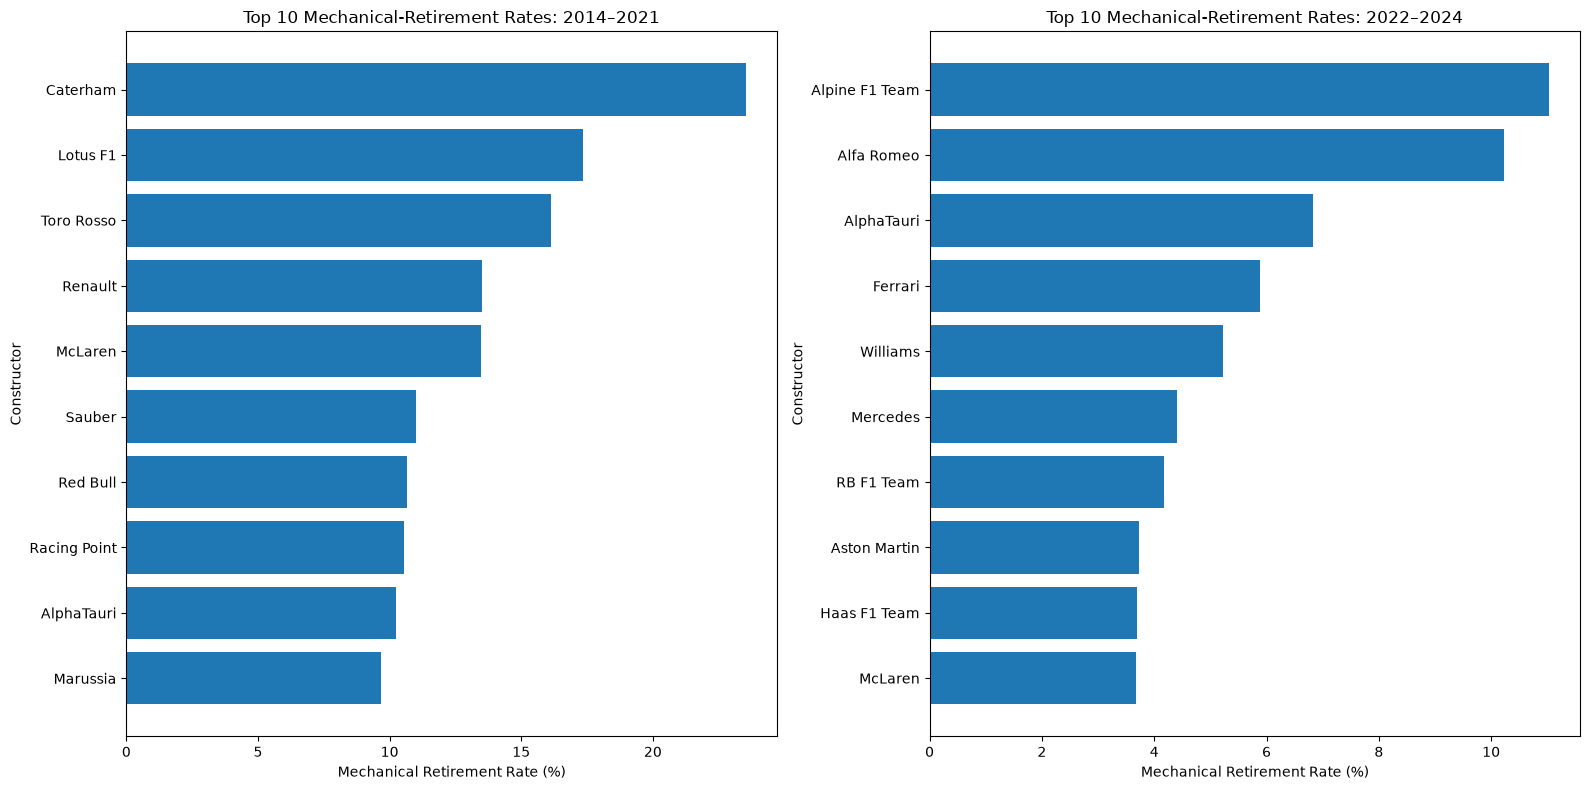

In [180]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

eras = ["2014–2021", "2022–2024"]

for ax, era in zip(axes, eras):
    plot_data = (
        constructor_rates[
            (constructor_rates["era"] == era)
            & (constructor_rates["race_starts"] >= 20)
        ]
        .sort_values("mechanical_retirement_rate", ascending=False)
        .head(10)
        .sort_values("mechanical_retirement_rate")
    )

    ax.barh(
        plot_data["constructor"],
        plot_data["mechanical_retirement_rate"]
    )

    ax.set_title(f"Top 10 Mechanical-Retirement Rates: {era}")
    ax.set_xlabel("Mechanical Retirement Rate (%)")
    ax.set_ylabel("Constructor")

plt.tight_layout()
plt.show()

<a id="h187"></a>
### Q3.6: Era-level mechanical-retirement rate
<a id="c177"></a>
*Code cell 181* | [Back to contents](#toc)
Across all constructors: **9.60%** (313 of 3,260 starts) in 2014-2021 and **5.46%** (74 of 1,355) in 2022-2024, i.e. mechanical failures became about 4 points rarer in the ground-effect era (a regulation-driven engine-development freeze is a plausible reason, but the data cannot prove the cause). Q3.6b tests whether the drop is larger than chance.


In [181]:
era_summary = (
    started_records
    .groupby("era")
    .agg(
        race_starts=("race_start_proxy", "size"),
        mechanical_retirements=("mechanical_failure", "sum")
    )
    .reset_index()
)

era_summary["mechanical_retirement_rate"] = (
    era_summary["mechanical_retirements"]
    / era_summary["race_starts"]
    * 100
).round(2)

display(era_summary)

,era,race_starts,mechanical_retirements,mechanical_retirement_rate
0,2014–2021,3260,313,9.60
1,2022–2024,1355,74,5.46


<a id="h188"></a>
### Q3.6b: Era comparison on the same chart, with uncertainty and a significance test
<a id="c178"></a>
*Code cell 182* | [Back to contents](#toc)
**Why:** the earlier bar chart shows two separate top-10 lists, so the reader cannot see **how each team changed** between 2014-2021 and 2022-2024, and shows no uncertainty. The dumbbell chart places both eras on one axis for every team lineage that has at least 20 starts in both periods, with 95% Wilson intervals. The chi-square test checks whether the overall drop from 9.60% to 5.46% is larger than chance.
**Caveats to state in the report:** (1) the periods have 8 and 3 seasons, so 2022-2024 intervals are wider; (2) a car's retirement can come from the **power-unit supplier** (customer teams share engines), so a constructor's rate is not purely its own engineering; (3) `status` is a **post-race** field, so this is a descriptive question and the column must never be used as a pre-race feature.


Overall rate 2014–2021: 9.60%  ->  2022–2024: 5.46%  (chi-square p = 5.049e-06)


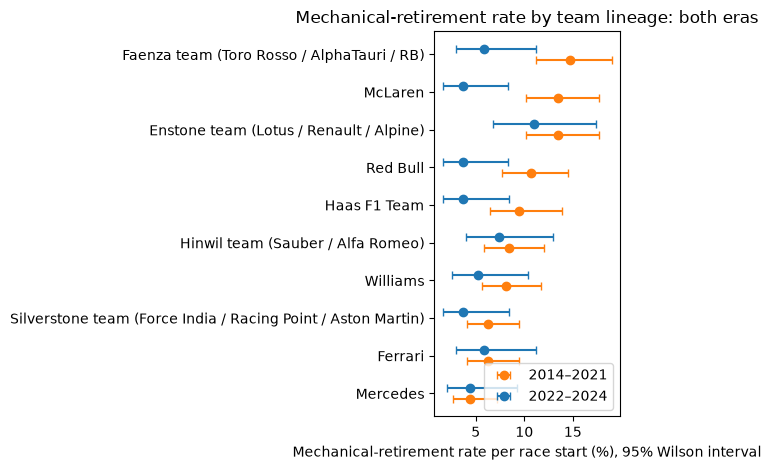

In [182]:
eras = sorted(era_summary["era"].unique())
tab_era = era_summary.set_index("era")
contingency = [[tab_era.loc[e, "mechanical_retirements"], tab_era.loc[e, "race_starts"] - tab_era.loc[e, "mechanical_retirements"]] for e in eras]
chi2, p_era, _, _ = stats.chi2_contingency(contingency)
print(f"Overall rate {eras[0]}: {tab_era.loc[eras[0], 'mechanical_retirement_rate']:.2f}%  ->  {eras[1]}: {tab_era.loc[eras[1], 'mechanical_retirement_rate']:.2f}%  (chi-square p = {p_era:.4g})")

wide = lineage_rates[lineage_rates["race_starts"] >= 20].pivot(index="lineage", columns="era", values=["race_starts", "mechanical_retirements"])
wide = wide.dropna()
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
plot_lin = pd.DataFrame({"lineage": wide.index})
for e in eras:
    plot_lin[f"rate_{e}"] = (wide[f"mechanical_retirements_{e}"] / wide[f"race_starts_{e}"] * 100).to_numpy()
    lo_e, hi_e = wilson_interval(wide[f"mechanical_retirements_{e}"], wide[f"race_starts_{e}"])
    plot_lin[f"lo_{e}"], plot_lin[f"hi_{e}"] = lo_e, hi_e
plot_lin = plot_lin.sort_values(f"rate_{eras[0]}").reset_index(drop=True)

y = np.arange(len(plot_lin))
for e, color, off in [(eras[0], "tab:orange", -0.15), (eras[1], "tab:blue", 0.15)]:
    plt.errorbar(plot_lin[f"rate_{e}"], y + off,
                 xerr=[plot_lin[f"rate_{e}"] - plot_lin[f"lo_{e}"], plot_lin[f"hi_{e}"] - plot_lin[f"rate_{e}"]],
                 fmt="o", color=color, capsize=3, label=e)
plt.yticks(y, plot_lin["lineage"]); plt.xlabel("Mechanical-retirement rate per race start (%), 95% Wilson interval")
plt.title("Mechanical-retirement rate by team lineage: both eras"); plt.legend(); plt.tight_layout(); plt.show()

<a id="h191"></a>
### Q3.7: Robustness audit — do the counted failures really end the race early, and does the answer survive other definitions?
<a id="c181"></a>
*Code cell 183* | [Back to contents](#toc)
**Why:** the brief defines a mechanical retirement as a start that *ended early* because a component failed. A status label alone does not prove the car ended early, so this cell checks the laps completed against the race distance, counts zero-lap cases, confirms no lapped finisher is counted, lists unclassified statuses, and re-computes era rates and the top-3 constructors under six definitions.
**Output:** a few audit counts, a table of era rates per definition, and the top-3 constructors per era under each definition.


In [183]:
# Q3.7 robustness audit: (a) does every counted "mechanical retirement" really END EARLY?  (b) which statuses are unclassified?  (c) sensitivity to the start definition, zero-lap rows and lapped cars
res_all = cleaned_tables["results"][["raceId", "driverId", "constructorId", "grid", "laps", "statusId", "positionOrder"]]
winner_laps = res_all.groupby("raceId")["laps"].max().rename("race_laps")
ra = retirement_audit.merge(winner_laps, on="raceId", how="left", validate="many_to_one")
ra["laps"] = ra["laps"].fillna(0); ra["share_of_race_distance"] = ra["laps"] / ra["race_laps"]
mech = ra[ra["mechanical_failure"]]
print("Rows labelled mechanical (base definition), 2014-2024:", len(mech))
print("  completed the FULL race distance (laps == race laps) although labelled as a failure:", int((mech["laps"] >= mech["race_laps"]).sum()))
print("  completed >= 90% of the distance (classified finishers by the sporting rules):", int((mech["share_of_race_distance"] >= 0.9).sum()))
print("  completed 0 laps (failed before the first racing lap - ambiguous 'start'):", int((mech["laps"] == 0).sum()))
print("  statuses of the form '+N Lap(s)' inside the mechanical set (lapped finish counted as failure):", int(mech["status"].astype(str).str.fullmatch(r"\+\d+ Laps?").sum()), "<- must be 0")
unc = status_map[status_map["category"] == "UNCLASSIFIED"]; display(unc)
print("Unclassified statuses are NOT counted as mechanical in any definition (e.g. 'Seat' = a driver-seat problem, not a power-train failure). They stay in the denominator because the car did start.")

def era_rate(num_mask, den_mask):
    g = ra[den_mask].assign(num=num_mask[den_mask])
    return g.groupby("era").agg(starts=("num", "size"), mechanical=("num", "sum")).assign(rate=lambda t: (100 * t["mechanical"] / t["starts"]).round(2))["rate"]
base_m = ra["status"].isin(mechanical_statuses); strict_m = ra["status"].isin(mech_strict); broad_m = ra["status"].isin(mech_broad)
start = ra["race_start_proxy"]; started_laps = ra["laps"] > 0; grid_started = ra["grid"] > 0
variants = {
    "base, notebook start proxy": era_rate(base_m, start),
    "strict statuses, notebook proxy": era_rate(strict_m, start),
    "broad statuses, notebook proxy": era_rate(broad_m, start),
    "base, only cars that completed >= 1 lap": era_rate(base_m & started_laps, started_laps),
    "base, grid > 0 starters": era_rate(base_m & grid_started, grid_started),
    "base, excluding labelled-failure rows that ran >= 90% distance": era_rate(base_m & (ra["share_of_race_distance"] < 0.9), start),
}
sens3 = pd.DataFrame(variants).T; display(sens3)
# Do the top constructors survive the definition changes?
def top_ctors(num_mask, den_mask, era, k=3, min_starts=20):
    g = ra[den_mask & (ra["era"] == era)].assign(num=num_mask[den_mask & (ra["era"] == era)]).groupby("constructorId").agg(starts=("num", "size"), m=("num", "sum"))
    g = g[g["starts"] >= min_starts]; g["rate"] = 100 * g["m"] / g["starts"]
    names = cleaned_tables["constructors"].set_index("constructorId")["name"]
    return [names[i] for i in g.sort_values("rate", ascending=False).head(k).index]
for era in ("2014–2021", "2022–2024"):
    print(f"\nTop-3 constructors {era}:")
    for lab, nm, dm in [("base / notebook proxy", base_m, start), ("strict", strict_m, start), ("broad", broad_m, start), ("base, >=1 lap only", base_m & started_laps, started_laps), ("base, < 90% distance only", base_m & (ra["share_of_race_distance"] < 0.9), start)]:
        print(f"   {lab:28s}", top_ctors(nm, dm, era))

Rows labelled mechanical (base definition), 2014-2024: 387
  completed the FULL race distance (laps == race laps) although labelled as a failure: 1
  completed >= 90% of the distance (classified finishers by the sporting rules): 41
  completed 0 laps (failed before the first racing lap - ambiguous 'start'): 22
  statuses of the form '+N Lap(s)' inside the mechanical set (lapped finish counted as failure): 0 <- must be 0


,status,records,category
56,Seat,1,UNCLASSIFIED


Unclassified statuses are NOT counted as mechanical in any definition (e.g. 'Seat' = a driver-seat problem, not a power-train failure). They stay in the denominator because the car did start.


era,2014–2021,2022–2024
"base, notebook start proxy",9.60,5.46
"strict statuses, notebook proxy",8.80,5.39
"broad statuses, notebook proxy",10.15,6.13
"base, only cars that completed >= 1 lap",9.39,5.14
"base, grid > 0 starters",9.42,5.46
"base, excluding labelled-failure rows that ran >= 90% distance",8.59,4.87



Top-3 constructors 2014–2021:
   base / notebook proxy        ['Caterham', 'Lotus F1', 'Toro Rosso']
   strict                       ['Caterham', 'Lotus F1', 'Toro Rosso']
   broad                        ['Caterham', 'Lotus F1', 'Toro Rosso']
   base, >=1 lap only           ['Caterham', 'Lotus F1', 'Toro Rosso']
   base, < 90% distance only    ['Caterham', 'Lotus F1', 'Toro Rosso']

Top-3 constructors 2022–2024:
   base / notebook proxy        ['Alpine F1 Team', 'Alfa Romeo', 'AlphaTauri']
   strict                       ['Alpine F1 Team', 'Alfa Romeo', 'AlphaTauri']
   broad                        ['Alfa Romeo', 'Alpine F1 Team', 'AlphaTauri']
   base, >=1 lap only           ['Alpine F1 Team', 'Alfa Romeo', 'AlphaTauri']
   base, < 90% distance only    ['Alpine F1 Team', 'Alfa Romeo', 'Ferrari']


---
<a id="h192"></a>
## Part 2 summary: answers, justification and caveats

*All numbers below come from the cells above; the primary answers are Q1.12, Q2.6 and Q3.7.*

<a id="h193"></a>
### Q1: Front row to podium by circuit
**Answer (primary definition = front-row START, `grid` 1-2).** Over 1,114 Grand Prix races a front-row start converts to a podium **56.3%** of the time before 2014 and **76.0%** from 2014. Among circuits with at least 10 front-row starts per era the leaders are Magny-Cours (80.6%), Istanbul Park (78.6%) and Dijon (75.0%) before 2014, and Suzuka (88.9%), Yas Marina (86.4%), Monaco (85.0%), Spa and Barcelona (81.8%) from 2014.
**Does the ranking change after 2014?** Yes, materially: across the 16 circuits present in both eras the Spearman rank correlation is **-0.03 (95% bootstrap interval about -0.53 to 0.41)**, i.e. no stable ranking. Monaco (+12 places) and Spa (+7.5) gained most; Hungaroring (-14) and Bahrain (-11) fell most. Part of this is small samples (10-50 front-row starts per circuit and era).
**Qualifying vs grid.** The qualifying-based version covers only the 494 races with qualifying data (front-row qualifiers: 64.7% before 2014, 74.0% from 2014). Of the 988 front-row qualifiers, 2 started from the pit lane; of the remaining 986 with a grid slot, 49 changed exact slot (51 including the 2 pit-lane starts, the figure in Q1.4) and **36 actually left the front row**: changing slot is not the same as leaving the front row.
**Grain / missingness / cutoff.** One row per driver per race; grid 0 and the Indy 500 (1950-60) removed; qualifying position and grid are known before the race, `positionOrder` is the outcome.
**Caveats.** Wide intervals; Magny-Cours and Istanbul Park have no post-2014 races; early grids were three-wide, so "grid <= 2" is not literally a front row before about 1960.

<a id="h194"></a>
### Q2: Home advantage
**Answer.** The raw comparison is misleading (home 10.67% vs away 12.94%). After controlling for the exact starting slot the home-minus-away difference is **-0.24 percentage points, 95% interval [-1.56, +1.12]**: **no evidence of a home advantage**. The result is robust to requiring at least one completed lap (-0.28) and to dropping the Indy 500 (-0.14). It is population-sensitive: from 1994 onward the estimate is **-2.38 points [-4.52, -0.34]**, a small *lower* podium rate at home, and from 2014 it is +2.0 [-3.6, +5.6] on only 144 home starts. No specification supports a positive home effect.
**Grain / missingness / cutoff.** One row per driver per race; grid > 0 required (grid 0 has no comparable start slot); all home starts fall in strata with both home and away drivers, so none are dropped.
**Caveats.** `drivers.nationality` is the current nationality, home teams may differ in strength beyond what grid captures, the estimate is associative, not causal.

<a id="h195"></a>
### Q3: Mechanical retirements
**Answer.** The rate fell from **9.60%** of race starts in 2014-2021 to **5.46%** in 2022-2024. Highest by constructor: **2014-2021** Caterham (23.5%), Lotus F1 (17.3%), Toro Rosso (16.1%); **2022-2024** Alpine (11.0%), Alfa Romeo (10.2%), AlphaTauri (6.8%). The top three are the same under the strict, base and >=1-lap definitions; under the broad definition the first two of 2022-2024 swap, and if rows that ran at least 90% of the distance are excluded Ferrari replaces AlphaTauri in third place.
**Audit.** Of 387 rows counted as mechanical, 1 ran the full distance, 41 ran at least 90% of it, 22 completed 0 laps, and none is a lapped finish. Era rates range 8.6-10.2% (2014-21) and 4.9-6.1% (2022-24) across the definitions: the **drop between eras is robust**, the exact level depends on the definition. The only unclassified status ("Seat", 1 record) is not counted as mechanical.
**Grain / missingness / cutoff.** One row per car start; `status` is **post-race** information, so this is descriptive and must never become a pre-race feature.
**Caveats.** Classification of contested statuses (tyre, wheel, vibration, power loss) is a judgement; renamed constructors are split by `constructorId` (lineage results are shown); a constructor's failure may be its engine supplier's; the second period has only three seasons.

<a id="h196"></a>
# Parts 3–5 — Feature engineering, predictive modelling and experiments (brief objectives 3–5)

**Structure of this part.** The work is organised in two parts.

* **Part A (attempt 1):** builds a first modelling table, explores it, splits the data chronologically, preprocesses it and trains logistic regression, random forest and a shallow neural network, followed by a first feature-group ablation. It uses grid, qualifying, calendar and identifier features only (no standings or form). It is kept as the documented *before* of a before/after comparison (B.12), because the milestone asks for every attempt to stay visible.
* **Part B (final pipeline):** attempt 1 has structural limitations (table below) that are better solved by a rebuild than by patching single cells. Part B therefore rebuilds the feature table once, checks it for leakage, runs every model and every ablation on that same table, and compares its results with Part A.

<a id="h197"></a>
### Lessons from attempt 1 and how Part B addresses them

| # | Finding | Why it matters | Resolution |
|---|---|---|---|
| 1 | The split differs from the course suggestion (attempt 1: train up to 2018 and validation 2019-21; course: up to 2019 and 2020-21) | A deviation is acceptable only if it is justified | A split-justification cell is included and Part B uses the course split |
| 2 | A draft standings feature shifted across seasons (`groupby("driverId").shift(1)`) | Round 1 would inherit the previous season's final totals instead of 0, so the feature would change scale at the start of every season | Left out of attempt 1; `v2_build_features` shifts within each season |
| 3 | The models and the ablation use different feature sets, and the ablation never touches logistic regression or the neural network | The brief requires one table and one feature set for all models, with the ablation reported per group | Part B: every model and every ablation on the same table |
| 4 | A summary table typed by hand goes stale on re-run | Reported numbers must be computed so they stay consistent when the notebook is re-run | All summary tables are computed (A.4.6, B.14, B.17) |
| 5 | Driver, constructor and circuit one-hot encoding creates about 1,100 columns for roughly 12% positives | It hurts the random forest, maps unseen identifiers to nothing at test time, and lets the model memorise history | Part B tests the identifiers as optional groups and adopts them only if they help |
| 6 | The ablation uses one seed, one split and validation only; differences of about 0.01 PR-AUC are within noise | Conclusions would rest on noise | Part B uses 3 seeds, a paired race-level bootstrap and removes correlated groups together |
| 7 | No baseline, no hyper-parameter trials, no learning curves, no uncertainty | The brief requires justification against a baseline and selection on train and validation only | Part B |
| 8 | No driver or constructor form features; qualifying coverage drift, DNQ rows, the Indianapolis 500 and sprint results are not handled | Raised explicitly in the course introduction | Part B |
| 9 | Standings were explored inside the ablation step (A.5.3) | Feature engineering belongs to Step 3 | Part B builds all features first |


<a id="h198"></a>
## Part A (attempt 1) — feature selection & engineering

<a id="h199"></a>
### A.3.1 Modelling table
<a id="c182"></a>
*Code cell 184* | [Back to contents](#toc)
Starts from the cleaned results (one row per driver per race), joins race info and the qualifying position, creates the binary **target `podium = positionOrder ≤ 3`**, and turns invalid grid values (≤ 0) into `NaN`.

**Strengths:** `validate=` on every merge, duplicate check, grid ≤ 0 -> missing instead of "position 0".
**Notes**
* `positionOrder` is kept only to build the target. It must never reach a feature list (audited in the leakage cell).
* This table still contains DNQ/DNPQ rows and the Indy 500 seasons - the course introduction requires a decision on both. Decision and evidence are in Part B.
* Pit-lane starts also carry grid 0; they become `NaN` here and are given an explicit "no slot" treatment in Part B.


In [184]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Start from the cleaned results table.
feature_df = cleaned_tables["results"][
    ["raceId", "driverId", "constructorId", "grid", "positionOrder"]
].copy()

# Join race information.
feature_df = feature_df.merge(
    cleaned_tables["races"][
        ["raceId", "year", "round", "circuitId"]
    ],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Join qualifying position.
qualifying_features = cleaned_tables["qualifying"][
    ["raceId", "driverId", "position"]
].rename(
    columns={"position": "qualifying_position"}
)

feature_df = feature_df.merge(
    qualifying_features,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Create the binary target.
feature_df["podium"] = (
    feature_df["positionOrder"] <= 3
).astype("int8")

# Invalid grid positions are treated as missing.
feature_df.loc[feature_df["grid"] <= 0, "grid"] = np.nan

# Check the resulting dataset.
print("Dataset shape:", feature_df.shape)

print(
    "Duplicate driver-race pairs:",
    feature_df.duplicated(["raceId", "driverId"]).sum()
)

print("\nTarget distribution:")
display(
    feature_df["podium"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Non-podium", 1: "Podium"})
    .to_frame("count")
)

print("\nCandidate feature missingness:")
display(
    feature_df[
        [
            "grid",
            "qualifying_position",
            "year",
            "round",
            "circuitId",
            "driverId",
            "constructorId"
        ]
    ].isna().sum().to_frame("missing_count")
)

Dataset shape: (26668, 10)
Duplicate driver-race pairs: 0

Target distribution:


,count
podium,
Non-podium,23273
Podium,3395



Candidate feature missingness:


,missing_count
grid,1635
qualifying_position,16174
year,0
round,0
circuitId,0
driverId,0
constructorId,0


<a id="h200"></a>
### A.3.2 Exploratory evidence - grid position vs podium
<a id="c183"></a>
*Code cell 185* | [Back to contents](#toc)
Podium rate by grid group (1–3, 4–6, 7–10, 11–15, 16+). This is the first piece of *exploratory evidence* the brief asks for: grid is expected to be the strongest single signal, and the monotone fall in podium rate justifies keeping it.

**Notes:** the plot shows a rate only. Part B adds the quantitative version (univariate AUC, Spearman, mutual information) for every candidate feature, not just grid.


,grid_group,starts,podiums,podium_rate
0,1–3,3370,1870,55.49
1,4–6,3369,876,26.00
2,7–10,4511,419,9.29
3,11–15,5605,170,3.03
4,16+,8178,60,0.73


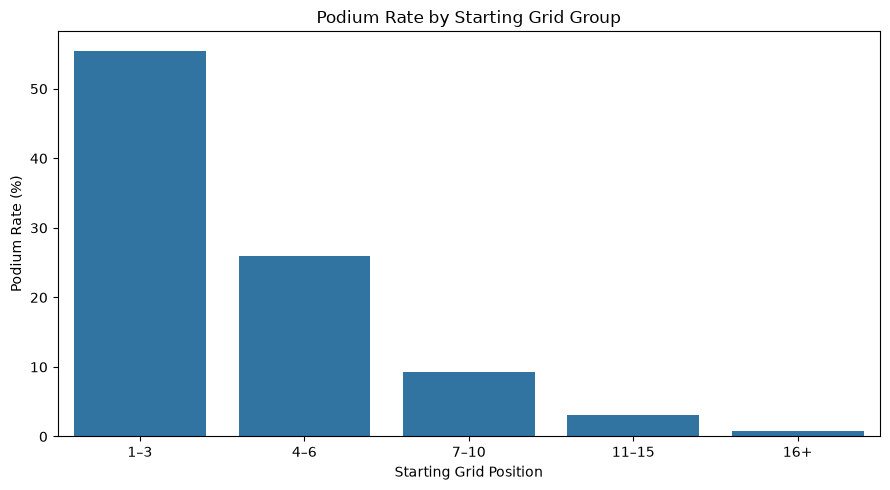

In [185]:
# Keep records with valid grid positions for this analysis.
eda_features = feature_df[
    feature_df["grid"].notna()
].copy()

eda_features["grid_group"] = pd.cut(
    eda_features["grid"],
    bins=[0, 3, 6, 10, 15, np.inf],
    labels=["1–3", "4–6", "7–10", "11–15", "16+"],
    include_lowest=True
)

# Calculate podium rates by grid group.
grid_podium_rates = (
    eda_features.groupby("grid_group", observed=False)
    .agg(
        starts=("podium", "size"),
        podiums=("podium", "sum"),
        podium_rate=("podium", "mean")
    )
    .reset_index()
)

grid_podium_rates["podium_rate"] *= 100

display(grid_podium_rates.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=grid_podium_rates,
    x="grid_group",
    y="podium_rate"
)

plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")
plt.title("Podium Rate by Starting Grid Group")
plt.tight_layout()
plt.show()

<a id="h201"></a>
### A.3.3 Exploratory evidence - qualifying position vs podium
<a id="c184"></a>
*Code cell 186* | [Back to contents](#toc)
Same analysis for qualifying position. Comparing it with the previous plot shows how much *new* information qualifying adds beyond the grid (they differ only through penalties / pit-lane starts), which is why Part B builds a `grid_penalty` feature.

**Note:** only rows with qualifying data are shown, so this plot over-represents modern seasons (see next cell).


,qualifying_group,starts,podiums,podium_rate
0,1–3,1482,929,62.69
1,4–6,1482,362,24.43
2,7–10,1976,116,5.87
3,11–15,2470,54,2.19
4,16+,3084,21,0.68


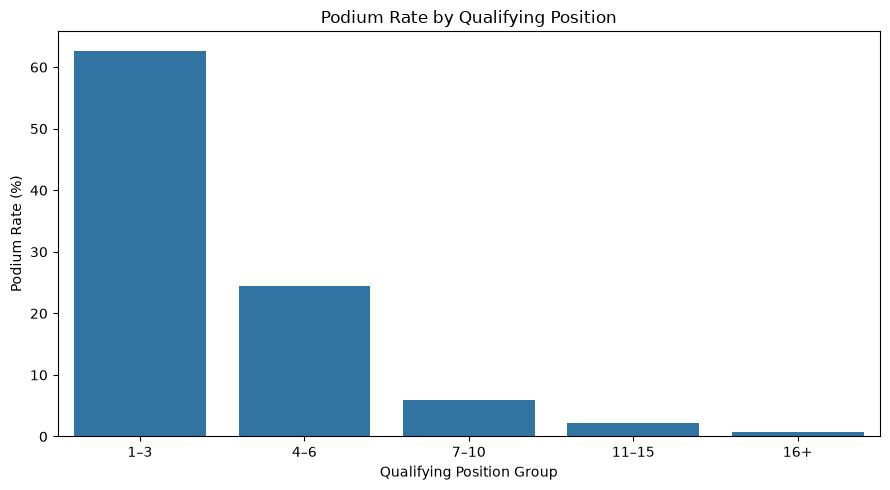

In [186]:
qualifying_eda = feature_df[
    feature_df["qualifying_position"].notna()
    & (feature_df["qualifying_position"] > 0)
].copy()

qualifying_eda["qualifying_group"] = pd.cut(
    qualifying_eda["qualifying_position"],
    bins=[0, 3, 6, 10, 15, np.inf],
    labels=["1–3", "4–6", "7–10", "11–15", "16+"],
    include_lowest=True
)

qualifying_podium_rates = (
    qualifying_eda.groupby(
        "qualifying_group",
        observed=False
    )
    .agg(
        starts=("podium", "size"),
        podiums=("podium", "sum"),
        podium_rate=("podium", "mean")
    )
    .reset_index()
)

qualifying_podium_rates["podium_rate"] *= 100

display(qualifying_podium_rates.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=qualifying_podium_rates,
    x="qualifying_group",
    y="podium_rate"
)

plt.xlabel("Qualifying Position Group")
plt.ylabel("Podium Rate (%)")
plt.title("Podium Rate by Qualifying Position")
plt.tight_layout()
plt.show()

<a id="h202"></a>
### A.3.4 Qualifying coverage by season and decade
<a id="c185"></a>
*Code cell 187* | [Back to contents](#toc)
Shows how many results have a qualifying row. This is the *coverage drift* the intro warns about: the table prints the first 15 seasons; the cell below (A.3.4b) plots every season.

 Decision (documented there and in Part B): do **not** drop old seasons blindly and do **not** impute a qualifying position - fall back to the grid slot, add a `qualifying_missing` flag, and let a training-window trial decide whether old seasons help.


In [187]:
# Compare qualifying-data availability by year.
qualifying_availability = (
    feature_df.assign(
        qualifying_available=feature_df["qualifying_position"].notna()
    )
    .groupby("year")
    .agg(
        total_records=("podium", "size"),
        records_with_qualifying=("qualifying_available", "sum"),
        podiums=("podium", "sum")
    )
    .reset_index()
)

qualifying_availability["qualifying_coverage_pct"] = (
    qualifying_availability["records_with_qualifying"]
    / qualifying_availability["total_records"] * 100
).round(2)

display(qualifying_availability.head(15))

# Summarize by decade to reveal historical coverage patterns.
feature_df["decade"] = (feature_df["year"] // 10) * 10

qualifying_by_decade = (
    feature_df.groupby("decade")
    .agg(
        total_records=("podium", "size"),
        records_with_qualifying=(
            "qualifying_position",
            lambda s: s.notna().sum()
        )
    )
    .reset_index()
)

qualifying_by_decade["qualifying_coverage_pct"] = (
    qualifying_by_decade["records_with_qualifying"]
    / qualifying_by_decade["total_records"] * 100
).round(2)

display(qualifying_by_decade)

,year,total_records,records_with_qualifying,podiums,qualifying_coverage_pct
0,1950,156,0,22,0.0
1,1951,175,0,28,0.0
2,1952,212,0,24,0.0
3,1953,230,0,29,0.0
4,1954,213,0,29,0.0
5,1955,162,0,25,0.0
6,1956,178,0,29,0.0
7,1957,163,0,25,0.0
8,1958,238,0,33,0.0
9,1959,195,0,27,0.0


,decade,total_records,records_with_qualifying,qualifying_coverage_pct
0,1950,1922,0,0.00
1,1960,2108,0,0.00
2,1970,3806,0,0.00
3,1980,4503,0,0.00
4,1990,4250,1396,32.85
5,2000,3643,2686,73.73
6,2010,4297,4274,99.46
7,2020,2139,2138,99.95


<a id="h203"></a>
### A.3.4b Qualifying coverage - every season, with the split boundaries
<a id="c186"></a>
*Code cell 188* | [Back to contents](#toc)
Plots coverage for all seasons and marks both the attempt-1 split (validation from 2019) and the course split (validation from 2020). Prints the first season with ≥ 90 % coverage.

**Why:** missingness here is *not random* - it is perfectly predicted by era - so a plain median imputation would hand the model "era" information through the back door. The handling used later (fallback + flag + window trial) is stated explicitly.


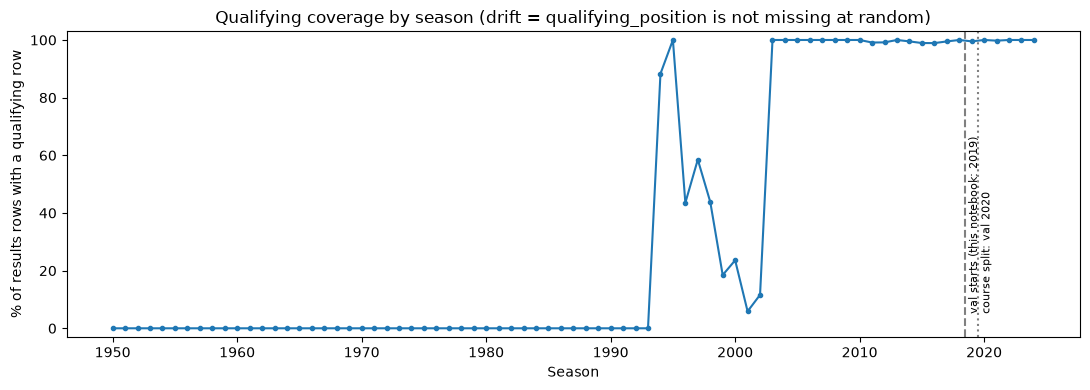

First season with >= 90% qualifying coverage: 1995
Seasons with 0% coverage: 44 | seasons with partial coverage (0-90%): 8


In [188]:
# Qualifying coverage drift: show EVERY season (the original table printed only the first 15 rows)
cov = qualifying_availability.sort_values("year")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(cov["year"], cov["qualifying_coverage_pct"], marker="o", ms=3)
ax.axvline(2018.5, ls="--", c="grey");  ax.text(2018.7, 5, "val starts (this notebook: 2019)", rotation=90, va="bottom", fontsize=8)
ax.axvline(2019.5, ls=":",  c="grey");  ax.text(2019.7, 5, "course split: val 2020", rotation=90, va="bottom", fontsize=8)
ax.set_ylim(-3, 103); ax.set_xlabel("Season"); ax.set_ylabel("% of results rows with a qualifying row")
ax.set_title("Qualifying coverage by season (drift = qualifying_position is not missing at random)")
plt.tight_layout(); plt.show()

first_full = cov.loc[cov["qualifying_coverage_pct"] >= 90, "year"].min()
print("First season with >= 90% qualifying coverage:", first_full)
print("Seasons with 0% coverage:", int((cov["qualifying_coverage_pct"] == 0).sum()),
      "| seasons with partial coverage (0-90%):", int(cov["qualifying_coverage_pct"].between(0.01, 89.99).sum()))

# Documented handling (used later in the v2 pipeline):
#  - qualifying_position is NOT dropped for old seasons: it falls back to the grid slot and a missing-flag is added,
#  - and a "training-scope" trial (train from 1950 vs from the first full-coverage era) decides empirically.

<a id="h204"></a>
### A.3.5 Chronological split
<a id="c187"></a>
*Code cell 189* | [Back to contents](#toc)
Train ≤ 2018, validation 2019–2021, test 2022–2024, with sizes, years and podium rates (≈12.5 % / 15 % / 15 % in the real run), plus boundary checks.

**Strengths:** chronological (no future in the past), sizes and class balance reported, test untouched.
**Deviation from the course suggestion** (*train ≤ 2019, validation 2020–2021, test ≥ 2022*): attempt 1 validates on 2019–2021. The cell below documents the comparison; Part B follows the course split.


In [189]:
# Define chronological boundaries.
train_df = feature_df[
    feature_df["year"] <= 2018
].copy()

validation_df = feature_df[
    feature_df["year"].between(2019, 2021)
].copy()

test_df = feature_df[
    feature_df["year"].between(2022, 2024)
].copy()

# Summarize each subset.
split_summary = pd.DataFrame([
    {
        "split": "Train",
        "first_year": train_df["year"].min(),
        "last_year": train_df["year"].max(),
        "records": len(train_df),
        "podiums": int(train_df["podium"].sum()),
        "podium_rate_pct": train_df["podium"].mean() * 100
    },
    {
        "split": "Validation",
        "first_year": validation_df["year"].min(),
        "last_year": validation_df["year"].max(),
        "records": len(validation_df),
        "podiums": int(validation_df["podium"].sum()),
        "podium_rate_pct": validation_df["podium"].mean() * 100
    },
    {
        "split": "Test",
        "first_year": test_df["year"].min(),
        "last_year": test_df["year"].max(),
        "records": len(test_df),
        "podiums": int(test_df["podium"].sum()),
        "podium_rate_pct": test_df["podium"].mean() * 100
    }
])

split_summary["podium_rate_pct"] = (
    split_summary["podium_rate_pct"].round(2)
)

display(split_summary)

# Verify the boundaries and coverage.
assert train_df["year"].max() < validation_df["year"].min()
assert validation_df["year"].max() < test_df["year"].min()

assert (
    len(train_df) + len(validation_df) + len(test_df)
    == len(feature_df)
)

print("Chronological split verified.")

,split,first_year,last_year,records,podiums,podium_rate_pct
0,Train,1950,2018,24109,3011,12.49
1,Validation,2019,2021,1200,180,15.00
2,Test,2022,2024,1359,204,15.01


Chronological split verified.


<a id="h205"></a>
### A.3.5b Split justification
<a id="c188"></a>
*Code cell 190* | [Back to contents](#toc)
* Rows and podium rate per season, with the boundaries drawn.
* Course split vs the split used, and how many rows (2019) move.
* A small experiment: one simple model scored with a **random** 70/30 split vs a **chronological** split. A random split lets later seasons into training, so it is not a valid yardstick for predicting future races - and the numbers show how the two differ.

**Statement for the report:** the task is to predict *future* races from information available before them, so the split is chronological; the test block (2022–2024) is the most recent era (ground-effect regulations) and is never used for any choice.


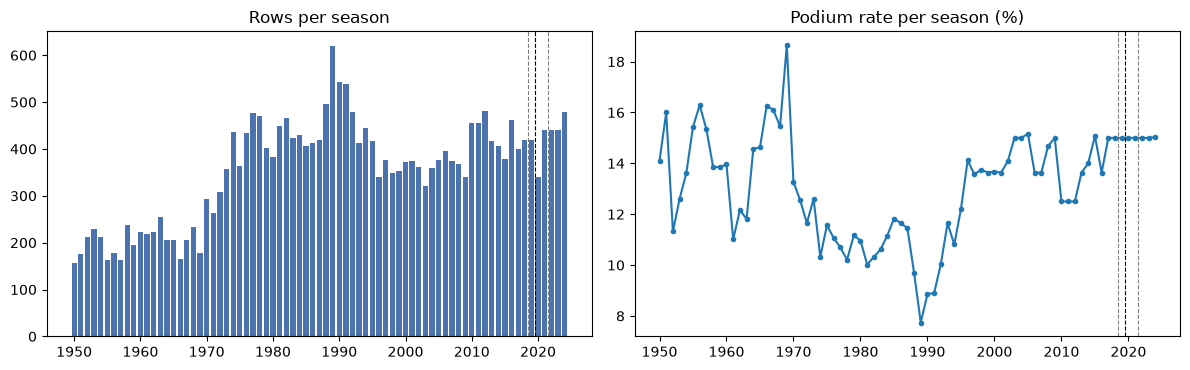

Course-suggested split : {'train': (None, 2019), 'validation': (2020, 2021), 'test': (2022, None)}
Split used above        : {'train': (None, 2018), 'validation': (2019, 2021), 'test': (2022, 2024)}
Rows in 2019 (moved between train and validation by the deviation): 420
chronological  PR-AUC=0.6785  ROC-AUC=0.9148
random         PR-AUC=0.6049  ROC-AUC=0.8991
Which split scores higher is NOT the argument (it depends on the era mix). The argument is validity: the task is to predict FUTURE races, so every model is judged on later seasons than it was trained on.


/tmp/claude-0/-home-claude/843a1b7a-0cf2-56f8-817e-22b27ec3a217/scratchpad/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/tmp/claude-0/-home-claude/843a1b7a-0cf2-56f8-817e-22b27ec3a217/scratchpad/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [190]:
# Split justification: course suggestion vs. the split used above, and why a random split is not used
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score

per_season = (feature_df.groupby("year").agg(rows=("podium", "size"), podiums=("podium", "sum"),
                                             podium_rate=("podium", "mean")).reset_index())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(per_season["year"], per_season["rows"], color="#4C72B0"); ax[0].set_title("Rows per season")
ax[1].plot(per_season["year"], per_season["podium_rate"] * 100, marker="o", ms=3); ax[1].set_title("Podium rate per season (%)")
for a in ax:
    for x, c in [(2018.5, "grey"), (2019.5, "k"), (2021.5, "grey")]:
        a.axvline(x, ls="--", c=c, lw=.8)
plt.tight_layout(); plt.show()

course = {"train": (None, 2019), "validation": (2020, 2021), "test": (2022, None)}
used   = {"train": (None, 2018), "validation": (2019, 2021), "test": (2022, 2024)}
print("Course-suggested split :", course)
print("Split used above        :", used)
print("Rows in 2019 (moved between train and validation by the deviation):",
      int((feature_df["year"] == 2019).sum()))

# Why chronological and not random: compare a random 70/30 split against a chronological one with the SAME simple model.
# (A random split puts races of the same season on both sides of the split, so season-specific driver/team strength leaks across.)
_cols = ["grid", "year"]
_d = feature_df.dropna(subset=["grid"]).copy()
_d = _d[_d["year"] <= 2021]                                   # the reserved TEST seasons (2022+) are NOT touched by this diagnostic
_chrono_tr, _chrono_te = _d[_d["year"] <= 2018], _d[_d["year"] >= 2019]      # train <= 2018 vs validation-era block 2019-2021
_rand_tr, _rand_te = train_test_split(_d, test_size=len(_chrono_te) / len(_d), random_state=0)
for name, tr, te in [("chronological", _chrono_tr, _chrono_te), ("random", _rand_tr, _rand_te)]:
    m = LogisticRegression(max_iter=1000).fit(tr[_cols], tr["podium"])
    p = m.predict_proba(te[_cols])[:, 1]
    print(f"{name:14s} PR-AUC={average_precision_score(te['podium'], p):.4f}  ROC-AUC={roc_auc_score(te['podium'], p):.4f}")
print("Which split scores higher is NOT the argument (it depends on the era mix). The argument is validity: the task is to predict FUTURE races, so every model is judged on later seasons than it was trained on.")

<a id="h206"></a>
### A.3.6 Candidate feature lists and missingness per split
<a id="c189"></a>
*Code cell 191* | [Back to contents](#toc)
Defines `core_features` (grid, year, round, driverId, constructorId, circuitId) and `qualifying_features` (core + qualifying position + missing flag) and prints the missing values in each split.

**Limitations (addressed in Part B)**
* `qualifying_features` is redefined in A.3.9 and is also the name of a DataFrame in A.3.1, so re-running cells out of order would break them - Part B uses unique `v2_*` names.
* `year` and `round` as raw numeric features let a model learn "calendar time" instead of racing signal; they are tested as an optional group in Part B rather than assumed.


In [191]:
# Create an indicator for missing qualifying information.
feature_df["qualifying_missing"] = (
    feature_df["qualifying_position"].isna().astype("int8")
)

# Define the feature sets.
core_features = [
    "grid",
    "year",
    "round",
    "driverId",
    "constructorId",
    "circuitId"
]

qualifying_features = core_features + [
    "qualifying_position",
    "qualifying_missing"
]

target = "podium"

# Compare missingness in the training, validation, and test sets.
for split_name, split_df in [
    ("Train", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(f"\n{split_name}")
    display(
        split_df[
            core_features + ["qualifying_position"]
        ].isna().sum().to_frame("missing_values")
    )


Train


,missing_values
grid,1566
year,0
round,0
driverId,0
constructorId,0
circuitId,0
qualifying_position,16171



Validation


,missing_values
grid,29
year,0
round,0
driverId,0
constructorId,0
circuitId,0
qualifying_position,3



Test


,missing_values
grid,40
year,0
round,0
driverId,0
constructorId,0
circuitId,0
qualifying_position,0


<a id="h207"></a>
### A.3.7 Imports for preprocessing
<a id="c190"></a>
*Code cell 192* | [Back to contents](#toc)
Imports `ColumnTransformer`, `Pipeline`, `SimpleImputer`, `OneHotEncoder`, `StandardScaler` and prints the version. No logic.


In [192]:
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("scikit-learn version:", sklearn.__version__)
print("Preprocessing components imported successfully.")

scikit-learn version: 1.6.1
Preprocessing components imported successfully.


<a id="h208"></a>
### A.3.8 Rebuild the splits
<a id="c191"></a>
*Code cell 193* | [Back to contents](#toc)
Re-creates the three splits of A.3.5 and asserts they cover `feature_df`. (Part B defines its split once, in B.3.)


In [193]:
# Rebuild the chronological splits from feature_df.
feature_df["qualifying_missing"] = (
    feature_df["qualifying_position"].isna().astype("int8")
)

train_df = feature_df[feature_df["year"] <= 2018].copy()

validation_df = feature_df[
    feature_df["year"].between(2019, 2021)
].copy()

test_df = feature_df[
    feature_df["year"].between(2022, 2024)
].copy()

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

assert len(train_df) + len(validation_df) + len(test_df) == len(feature_df)

Train: (24109, 12)
Validation: (1200, 12)
Test: (1359, 12)


<a id="h209"></a>
### A.3.9 Numeric / categorical feature lists
<a id="c192"></a>
*Code cell 194* | [Back to contents](#toc)
Splits features into numeric (`grid`, `year`, `round`, `qualifying_position`) and categorical (`driverId`, `constructorId`, `circuitId`).

**Notes**
* `driverId`, `constructorId`, `circuitId` are **identifiers** treated as categories -> thousands of one-hot columns (next cells).
* `qualifying_features` is reassigned here to a *different* list (it now contains the missing flag at the end).


In [194]:
core_numeric = [
    "grid",
    "year",
    "round"
]

core_categorical = [
    "driverId",
    "constructorId",
    "circuitId"
]

core_features = core_numeric + core_categorical

qualifying_numeric = core_numeric + [
    "qualifying_position"
]

qualifying_categorical = core_categorical

qualifying_features = (
    qualifying_numeric
    + qualifying_categorical
    + ["qualifying_missing"]
)

target = "podium"

<a id="h210"></a>
### A.3.9b Leakage / information-cutoff audit
<a id="c193"></a>
*Code cell 195* | [Back to contents](#toc)
The brief fixes the prediction moment: **after qualifying, before the race**. This cell lists every feature with the reason it is known by then and **asserts** that no post-race field (`positionOrder`, `points`, `laps`, `status`, fastest lap, pit stops, …) is in the feature list. Sprint results are technically pre-race; they are left out as a conservative cutoff, and that choice is stated.

The same assertion is applied to the Part B feature lists, together with a *no-lookahead perturbation test* that scrambles the future and checks nothing moves.


In [195]:
# Leakage / information-cutoff audit of the feature lists defined so far
# Prediction moment = after qualifying, before the lights go out. Anything produced BY the race is forbidden.
POST_RACE_FIELDS = {
    "positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status",
    "pit_stops", "stop", "duration", "lap_time", "podium",
}
AVAILABLE_BEFORE_RACE = {
    "grid": "qualifying result + penalties, published before the race",
    "qualifying_position": "qualifying result",
    "qualifying_missing": "derived from availability of the qualifying row",
    "year": "calendar", "round": "calendar", "circuitId": "calendar",
    "driverId": "entry list", "constructorId": "entry list",
}
audit = pd.DataFrame({
    "feature": qualifying_features,
    "allowed_pre_race": [f in AVAILABLE_BEFORE_RACE for f in qualifying_features],
    "why": [AVAILABLE_BEFORE_RACE.get(f, "NOT VERIFIED") for f in qualifying_features],
})
display(audit)
assert not (set(qualifying_features) & POST_RACE_FIELDS), "post-race field used as a feature"
print("No post-race field is in the feature list. Sprint results are not used (technically pre-race, but dropped for a conservative cutoff).")
print("Standings added later must be 'before this race' - checked in the standings blocks below.")

,feature,allowed_pre_race,why
0,grid,True,"qualifying result + penalties, published befor..."
1,year,True,calendar
2,round,True,calendar
3,qualifying_position,True,qualifying result
4,driverId,True,entry list
5,constructorId,True,entry list
6,circuitId,True,calendar
7,qualifying_missing,True,derived from availability of the qualifying row


No post-race field is in the feature list. Sprint results are not used (technically pre-race, but dropped for a conservative cutoff).
Standings added later must be 'before this race' - checked in the standings blocks below.


<a id="h211"></a>
### A.3.10 Preprocessing pipelines
<a id="c194"></a>
*Code cell 196* | [Back to contents](#toc)
Numeric: median imputation + standardisation. Categorical: most-frequent imputation + one-hot (`handle_unknown="ignore"`). Two `ColumnTransformer`s: core, and core + qualifying (+ missing flag passthrough).

**Strengths:** everything is inside sklearn objects, so it can be fitted on train only.
**Limitations (addressed in Part B)**
* One-hot of *all* IDs: ~1,100 columns for ~24 k rows. Unseen drivers/constructors at test time become all-zeros (no information), and tree models dilute `max_features` over mostly-empty columns.
* Median imputation of `qualifying_position` for pre-1996 rows silently turns "no data" into "mid-field". The missing flag partly repairs this; Part B instead falls back to the grid slot.


In [196]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric preprocessing.
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing.
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Feature set A: core features.
core_preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, core_numeric),
    ("categorical", categorical_preprocessor, core_categorical)
])

# Feature set B: core + qualifying.
qualifying_preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_preprocessor,
        qualifying_numeric
    ),
    (
        "categorical",
        categorical_preprocessor,
        qualifying_categorical
    ),
    (
        "missing_indicator",
        "passthrough",
        ["qualifying_missing"]
    )
])

print("Both preprocessing pipelines are defined.")

Both preprocessing pipelines are defined.


<a id="h212"></a>
### A.3.11 Fit preprocessing on train only, transform validation/test
<a id="c195"></a>
*Code cell 197* | [Back to contents](#toc)
Builds the six matrices and prints shapes (≈1,124 / 1,126 columns) and NaN counts.

**Strengths:** `fit_transform` on train, `transform` on the others - no leakage through scaler/imputer statistics. Dimensions show exactly the one-hot explosion described above.


In [197]:
# Separate predictors and target.
X_train_core = train_df[core_features]
X_val_core = validation_df[core_features]
X_test_core = test_df[core_features]

X_train_qual = train_df[qualifying_features]
X_val_qual = validation_df[qualifying_features]
X_test_qual = test_df[qualifying_features]

y_train = train_df[target]
y_val = validation_df[target]
y_test = test_df[target]

# Fit only on training data.
X_train_core_processed = core_preprocessor.fit_transform(X_train_core)

X_val_core_processed = core_preprocessor.transform(X_val_core)
X_test_core_processed = core_preprocessor.transform(X_test_core)

X_train_qual_processed = qualifying_preprocessor.fit_transform(X_train_qual)

X_val_qual_processed = qualifying_preprocessor.transform(X_val_qual)
X_test_qual_processed = qualifying_preprocessor.transform(X_test_qual)

# Inspect dimensions.
print("CORE FEATURE SET")
print("Train:", X_train_core_processed.shape)
print("Validation:", X_val_core_processed.shape)
print("Test:", X_test_core_processed.shape)

print("\nCORE + QUALIFYING FEATURE SET")
print("Train:", X_train_qual_processed.shape)
print("Validation:", X_val_qual_processed.shape)
print("Test:", X_test_qual_processed.shape)

# Check for NaN values after preprocessing.
import numpy as np

print(
    "\nNaN values after core preprocessing:",
    np.isnan(X_train_core_processed.data).sum()
    if hasattr(X_train_core_processed, "data")
    else np.isnan(X_train_core_processed).sum()
)

CORE FEATURE SET
Train: (24109, 1124)
Validation: (1200, 1124)
Test: (1359, 1124)

CORE + QUALIFYING FEATURE SET
Train: (24109, 1126)
Validation: (1200, 1126)
Test: (1359, 1126)

NaN values after core preprocessing: 0


<a id="h213"></a>
### A.3.12 Preprocessing check table
<a id="c196"></a>
*Code cell 198* | [Back to contents](#toc)
Shape and remaining-NaN counts per feature set and split in one table. All remaining-missing counts must be 0.


In [198]:
from scipy import sparse
import numpy as np

def count_missing_transformed(X):
    if sparse.issparse(X):
        return int(np.isnan(X.data).sum())
    return int(np.isnan(X).sum())

preprocessing_check = pd.DataFrame([
    {
        "feature_set": "Core",
        "split": "Train",
        "rows": X_train_core_processed.shape[0],
        "features": X_train_core_processed.shape[1],
        "missing_values": count_missing_transformed(X_train_core_processed)
    },
    {
        "feature_set": "Core",
        "split": "Validation",
        "rows": X_val_core_processed.shape[0],
        "features": X_val_core_processed.shape[1],
        "missing_values": count_missing_transformed(X_val_core_processed)
    },
    {
        "feature_set": "Core",
        "split": "Test",
        "rows": X_test_core_processed.shape[0],
        "features": X_test_core_processed.shape[1],
        "missing_values": count_missing_transformed(X_test_core_processed)
    },
    {
        "feature_set": "Core + qualifying",
        "split": "Train",
        "rows": X_train_qual_processed.shape[0],
        "features": X_train_qual_processed.shape[1],
        "missing_values": count_missing_transformed(X_train_qual_processed)
    },
    {
        "feature_set": "Core + qualifying",
        "split": "Validation",
        "rows": X_val_qual_processed.shape[0],
        "features": X_val_qual_processed.shape[1],
        "missing_values": count_missing_transformed(X_val_qual_processed)
    },
    {
        "feature_set": "Core + qualifying",
        "split": "Test",
        "rows": X_test_qual_processed.shape[0],
        "features": X_test_qual_processed.shape[1],
        "missing_values": count_missing_transformed(X_test_qual_processed)
    }
])

display(preprocessing_check)

,feature_set,split,rows,features,missing_values
0,Core,Train,24109,1124,0
1,Core,Validation,1200,1124,0
2,Core,Test,1359,1124,0
3,Core + qualifying,Train,24109,1126,0
4,Core + qualifying,Validation,1200,1126,0
5,Core + qualifying,Test,1359,1126,0


<a id="h214"></a>
## Part A (attempt 1) — predictive modelling

<a id="h215"></a>
### A.4.1 Logistic regression: core vs core + qualifying
<a id="c197"></a>
*Code cell 199* | [Back to contents](#toc)
Trains a balanced LR on each feature set, selects the F1-maximising threshold **on validation**, reports ROC-AUC / PR-AUC / F1 (validation PR-AUC ≈ 0.701 -> 0.706 with qualifying).

**Strengths:** threshold from validation only; imbalance handled; PR-AUC reported.
**Notes**
* The qualifying gain (+0.005) is far smaller than the noise of a ~2-season validation set; Part B puts an interval on this kind of comparison.
* The brief asks for metrics on **training and validation and test for every model**; train/test come in later cells for the three final models only.


In [199]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_recall_curve
)

def evaluate_feature_set(
    X_train,
    X_val,
    y_train,
    y_val,
    feature_set_name
):
    model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train, y_train)

    val_probabilities = model.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        val_probabilities
    )

    # Select the threshold that maximizes validation F1.
    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_idx = np.argmax(f1_values)
    best_threshold = thresholds[best_idx]

    val_predictions = (
        val_probabilities >= best_threshold
    ).astype(int)

    return {
        "feature_set": feature_set_name,
        "ROC_AUC": roc_auc_score(y_val, val_probabilities),
        "PR_AUC": average_precision_score(y_val, val_probabilities),
        "F1": f1_score(y_val, val_predictions),
        "threshold": best_threshold,
        "model": model
    }

core_result = evaluate_feature_set(
    X_train_core_processed,
    X_val_core_processed,
    y_train,
    y_val,
    "Core"
)

qualifying_result = evaluate_feature_set(
    X_train_qual_processed,
    X_val_qual_processed,
    y_train,
    y_val,
    "Core + qualifying"
)

feature_comparison = pd.DataFrame([
    {k: v for k, v in result.items() if k != "model"}
    for result in [core_result, qualifying_result]
])

display(feature_comparison.round(4))

/tmp/claude-0/-home-claude/843a1b7a-0cf2-56f8-817e-22b27ec3a217/scratchpad/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/tmp/claude-0/-home-claude/843a1b7a-0cf2-56f8-817e-22b27ec3a217/scratchpad/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,feature_set,ROC_AUC,PR_AUC,F1,threshold
0,Core,0.9181,0.7008,0.7068,0.7244
1,Core + qualifying,0.9207,0.7057,0.7216,0.7101


<a id="h216"></a>
### A.4.2 Confusion matrix and report
<a id="c198"></a>
*Code cell 200* | [Back to contents](#toc)
Confusion matrix and classification report of LR (core + qualifying) on validation at the selected threshold. Good for understanding the operating point (precision vs recall of the podium class).


In [200]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

# Use the validation predictions from the Core + qualifying model.
best_threshold = qualifying_result["threshold"]

val_probabilities = qualifying_result["model"].predict_proba(
    X_val_qual_processed
)[:, 1]

val_predictions = (
    val_probabilities >= best_threshold
).astype(int)

cm = confusion_matrix(y_val, val_predictions, labels=[0, 1])

print("Selected validation threshold:", round(best_threshold, 4))

print("\nConfusion matrix:")
display(
    pd.DataFrame(
        cm,
        index=["Actual non-podium", "Actual podium"],
        columns=["Predicted non-podium", "Predicted podium"]
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_val,
        val_predictions,
        target_names=["Non-podium", "Podium"],
        zero_division=0
    )
)

Selected validation threshold: 0.7101

Confusion matrix:


,Predicted non-podium,Predicted podium
Actual non-podium,952,68
Actual podium,40,140



Classification report:
              precision    recall  f1-score   support

  Non-podium       0.96      0.93      0.95      1020
      Podium       0.67      0.78      0.72       180

    accuracy                           0.91      1200
   macro avg       0.82      0.86      0.83      1200
weighted avg       0.92      0.91      0.91      1200



<a id="h217"></a>
### A.4.3 Threshold 0.5 vs tuned
<a id="c199"></a>
*Code cell 201* | [Back to contents](#toc)
Compares the default 0.5 cut-off with the validation-optimised threshold. It shows why a tuned threshold is needed with ~15 % positives: at 0.5 a balanced LR over-predicts podiums. Valid because the tuning uses validation data only.


In [201]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.5, qualifying_result["threshold"]]:
    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, predictions),
        "recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions)
    })

threshold_comparison = pd.DataFrame(threshold_results)
display(threshold_comparison.round(4))

,threshold,precision,recall,F1
0,0.5000,0.5374,0.8778,0.6667
1,0.7101,0.6731,0.7778,0.7216


<a id="h218"></a>
### A.4.4 Random forest and shallow MLP
<a id="c200"></a>
*Code cell 202* | [Back to contents](#toc)
Defines `find_best_threshold` / `evaluate_model`, trains RF (200 trees, leaf 2, `balanced_subsample`) and an MLP with one hidden layer of 32 units on the same matrix; validation PR-AUC ≈ RF 0.726, MLP 0.719, LR 0.706.

**Strengths:** same matrix for all three; one hidden layer satisfies the "shallow NN" requirement; thresholds on validation.
**Limitations (addressed in Part B)**
* **No hyper-parameter search**: one hand-picked setting per model, so "the models differ by ≤ 0.02" says little. Part B tunes each model with rolling-origin folds that never touch the test years.
* A single seed for RF/MLP. Part B averages three.
* Gradient boosting (suggested in the brief) is not included; Part B adds it.


In [202]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)
import numpy as np
import pandas as pd

# Find the threshold that maximizes F1 on validation data
def find_best_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_idx = np.argmax(f1_values)

    return thresholds[best_idx]


def evaluate_model(name, model, X_train, X_val, y_train, y_val):
    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_val)[:, 1]
    threshold = find_best_threshold(y_val, probabilities)
    predictions = (probabilities >= threshold).astype(int)

    return {
        "model_name": name,
        "ROC_AUC": roc_auc_score(y_val, probabilities),
        "PR_AUC": average_precision_score(y_val, probabilities),
        "precision": precision_score(y_val, predictions),
        "recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "threshold": threshold,
        "model": model
    }


# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42
)

rf_result = evaluate_model(
    "Random Forest",
    rf_model,
    X_train_qual_processed,
    X_val_qual_processed,
    y_train,
    y_val
)


# Model 3: Shallow Neural Network (one hidden layer)
mlp_model = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    early_stopping=True,
    validation_fraction=0.1,
    max_iter=100,
    random_state=42
)

mlp_result = evaluate_model(
    "Shallow Neural Network",
    mlp_model,
    X_train_qual_processed,
    X_val_qual_processed,
    y_train,
    y_val
)


# Compare all three models
validation_results = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "ROC_AUC": qualifying_result["ROC_AUC"],
        "PR_AUC": qualifying_result["PR_AUC"],
        "F1": qualifying_result["F1"],
        "threshold": qualifying_result["threshold"]
    },
    {
        "model": rf_result["model_name"],
        "ROC_AUC": rf_result["ROC_AUC"],
        "PR_AUC": rf_result["PR_AUC"],
        "F1": rf_result["F1"],
        "threshold": rf_result["threshold"]
    },
    {
        "model": mlp_result["model_name"],
        "ROC_AUC": mlp_result["ROC_AUC"],
        "PR_AUC": mlp_result["PR_AUC"],
        "F1": mlp_result["F1"],
        "threshold": mlp_result["threshold"]
    }
])

display(
    validation_results
    .sort_values("PR_AUC", ascending=False)
    .round(4)
)


,model,ROC_AUC,PR_AUC,F1,threshold
1,Random Forest,0.9306,0.7257,0.7292,0.7256
2,Shallow Neural Network,0.9175,0.7187,0.7209,0.3877
0,Logistic Regression,0.9207,0.7057,0.7216,0.7101


<a id="h219"></a>
### A.4.5 Evaluation on the unseen test set
<a id="c201"></a>
*Code cell 203* | [Back to contents](#toc)
Scores the three models on the test seasons using thresholds frozen from validation (PR-AUC ≈ RF 0.603, LR 0.603, MLP 0.584).

**Strengths:** test used once, thresholds not re-tuned. **Note** the large drop from validation to test (≈ 0.72 -> 0.60) - a sign that the validation model selection was optimistic (small validation set, many ID columns) or that the test era differs. Part B quantifies this with bootstrap intervals.


In [203]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Model objects and their validation-selected thresholds
models_to_test = [
    (
        "Logistic Regression",
        qualifying_result["model"],
        qualifying_result["threshold"]
    ),
    (
        "Random Forest",
        rf_result["model"],
        rf_result["threshold"]
    ),
    (
        "Shallow Neural Network",
        mlp_result["model"],
        mlp_result["threshold"]
    )
]

test_results = []
test_probabilities = {}

for name, model, threshold in models_to_test:
    # Predict on the untouched test set
    probabilities = model.predict_proba(
        X_test_qual_processed
    )[:, 1]

    predictions = (probabilities >= threshold).astype(int)

    test_probabilities[name] = probabilities

    test_results.append({
        "model": name,
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC": average_precision_score(y_test, probabilities),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "threshold_from_validation": threshold
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df
    .sort_values("PR_AUC", ascending=False)
    .round(4)
)


,model,ROC_AUC,PR_AUC,precision,recall,F1,threshold_from_validation
1,Random Forest,0.9210,0.6032,0.6407,0.5245,0.5768,0.7256
0,Logistic Regression,0.9103,0.6028,0.5738,0.5147,0.5426,0.7101
2,Shallow Neural Network,0.9087,0.5838,0.5853,0.6225,0.6033,0.3877


<a id="h220"></a>
### A.4.6 Summary table
<a id="c202"></a>
*Code cell 204* | [Back to contents](#toc)
Builds the summary table from the stored results (`qualifying_result`, `rf_result`, `mlp_result`, `test_results_df`), so it stays correct on every re-run.


In [204]:
# Computed (replaces the hand-typed table): validation numbers come from the stored model results, test numbers from test_results_df
def _summary_row(name, res):
    t = test_results_df.set_index("model").loc[name]
    return {"Model": name,
            "Validation ROC-AUC": res["ROC_AUC"], "Validation PR-AUC": res["PR_AUC"], "Validation F1": res["F1"],
            "Test ROC-AUC": t["ROC_AUC"], "Test PR-AUC": t["PR_AUC"], "Test F1": t["F1"]}

model_summary = pd.DataFrame([
    _summary_row("Logistic Regression", qualifying_result),
    _summary_row("Random Forest", rf_result),
    _summary_row("Shallow Neural Network", mlp_result),
])
display(model_summary.round(4))


,Model,Validation ROC-AUC,Validation PR-AUC,Validation F1,Test ROC-AUC,Test PR-AUC,Test F1
0,Logistic Regression,0.9207,0.7057,0.7216,0.9103,0.6028,0.5426
1,Random Forest,0.9306,0.7257,0.7292,0.9210,0.6032,0.5768
2,Shallow Neural Network,0.9175,0.7187,0.7209,0.9087,0.5838,0.6033


<a id="h221"></a>
### A.4.7 Training-set metrics
<a id="c203"></a>
*Code cell 205* | [Back to contents](#toc)
ROC-AUC / PR-AUC / F1 of each model on the **training** data - required by the brief. Compare with validation to see over-fitting: a high-capacity RF will score far higher on train than on validation (expected).


In [205]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score
)
import pandas as pd

models_to_evaluate = [
    {
        "name": "Logistic Regression",
        "model": qualifying_result["model"],
        "X_train": X_train_qual_processed,
        "X_val": X_val_qual_processed,
        "threshold": qualifying_result["threshold"]
    },
    {
        "name": "Random Forest",
        "model": rf_result["model"],
        "X_train": X_train_qual_processed,
        "X_val": X_val_qual_processed,
        "threshold": rf_result["threshold"]
    },
    {
        "name": "Shallow Neural Network",
        "model": mlp_result["model"],
        "X_train": X_train_qual_processed,
        "X_val": X_val_qual_processed,
        "threshold": mlp_result["threshold"]
    }
]

training_results = []

for item in models_to_evaluate:
    train_prob = item["model"].predict_proba(
        item["X_train"]
    )[:, 1]

    train_pred = (
        train_prob >= item["threshold"]
    ).astype(int)

    training_results.append({
        "model": item["name"],
        "ROC_AUC": roc_auc_score(y_train, train_prob),
        "PR_AUC": average_precision_score(y_train, train_prob),
        "F1": f1_score(y_train, train_pred),
        "threshold_from_validation": item["threshold"]
    })

training_results_df = pd.DataFrame(training_results)

display(training_results_df.round(4))


,model,ROC_AUC,PR_AUC,F1,threshold_from_validation
0,Logistic Regression,0.9133,0.5600,0.5851,0.7101
1,Random Forest,0.9510,0.7338,0.6729,0.7256
2,Shallow Neural Network,0.9071,0.5679,0.5606,0.3877


<a id="h222"></a>
### A.4.8 Shape / target / feature-set sanity checks
<a id="c204"></a>
*Code cell 206* | [Back to contents](#toc)
Prints matrix shapes, target balance per split and the feature names used. Confirms that all models use the same matrices - the "same table, same features" requirement.


In [206]:

# 1. Check dimensions
print("FEATURE MATRIX SHAPES")
print("-" * 50)

print("Train:", X_train_qual_processed.shape)
print("Validation:", X_val_qual_processed.shape)
print("Test:", X_test_qual_processed.shape)

print("\nTARGET SHAPES")
print("-" * 50)

print("Train:", y_train.shape)
print("Validation:", y_val.shape)
print("Test:", y_test.shape)

print("\nTARGET DISTRIBUTION")
print("-" * 50)

for name, y in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}:")
    print(y.value_counts().sort_index())
    print("Podium rate:", round(y.mean(), 4))

# All models should use these same matrices
print("\nFEATURE SET")
print("-" * 50)
print("Numeric:", qualifying_numeric)
print("Categorical:", qualifying_categorical)
print("Additional:", ["qualifying_missing"])


FEATURE MATRIX SHAPES
--------------------------------------------------
Train: (24109, 1126)
Validation: (1200, 1126)
Test: (1359, 1126)

TARGET SHAPES
--------------------------------------------------
Train: (24109,)
Validation: (1200,)
Test: (1359,)

TARGET DISTRIBUTION
--------------------------------------------------

Train:
podium
0    21098
1     3011
Name: count, dtype: int64
Podium rate: 0.1249

Validation:
podium
0    1020
1     180
Name: count, dtype: int64
Podium rate: 0.15

Test:
podium
0    1155
1     204
Name: count, dtype: int64
Podium rate: 0.1501

FEATURE SET
--------------------------------------------------
Numeric: ['grid', 'year', 'round', 'qualifying_position']
Categorical: ['driverId', 'constructorId', 'circuitId']
Additional: ['qualifying_missing']


<a id="h223"></a>
### A.4.9 Model object checks
<a id="c205"></a>
*Code cell 207* | [Back to contents](#toc)
Prints class, `n_features_in_`, `predict_proba` availability and classes for each model. A quick assertion-style check that all three consumed the same number of columns.


In [207]:

models = {
    "Logistic Regression": qualifying_result["model"],
    "Random Forest": rf_result["model"],
    "Shallow Neural Network": mlp_result["model"]
}

for name, model in models.items():
    print(f"\n{name}")
    print("-" * 40)
    print("Model class:", type(model).__name__)
    print("Fitted features:", getattr(model, "n_features_in_", "Not available"))
    print("Has predict_proba:", hasattr(model, "predict_proba"))
    print("Classes:", getattr(model, "classes_", "Not available"))



Logistic Regression
----------------------------------------
Model class: LogisticRegression
Fitted features: 1126
Has predict_proba: True
Classes: [0 1]

Random Forest
----------------------------------------
Model class: RandomForestClassifier
Fitted features: 1126
Has predict_proba: True
Classes: [0 1]

Shallow Neural Network
----------------------------------------
Model class: MLPClassifier
Fitted features: 1126
Has predict_proba: True
Classes: [0 1]


<a id="h224"></a>
### A.4.10 Metrics on all splits
<a id="c206"></a>
*Code cell 208* | [Back to contents](#toc)
Recomputes ROC-AUC / PR-AUC per model and split plus the probability range. Together with 4.7 this gives the "train / validation / unseen test" table; the probability range confirms outputs are proper probabilities.


In [208]:

from sklearn.metrics import average_precision_score, roc_auc_score
import pandas as pd
import numpy as np

splits = {
    "Train": (X_train_qual_processed, y_train),
    "Validation": (X_val_qual_processed, y_val),
    "Test": (X_test_qual_processed, y_test)
}

metric_check = []

for model_name, model in models.items():
    for split_name, (X, y) in splits.items():
        probabilities = model.predict_proba(X)[:, 1]

        metric_check.append({
            "model": model_name,
            "split": split_name,
            "ROC_AUC": roc_auc_score(y, probabilities),
            "PR_AUC": average_precision_score(y, probabilities),
            "probability_min": probabilities.min(),
            "probability_max": probabilities.max()
        })

metric_check_df = pd.DataFrame(metric_check)

display(
    metric_check_df
    .sort_values(["model", "split"])
    .round(4)
)


,model,split,ROC_AUC,PR_AUC,probability_min,probability_max
2,Logistic Regression,Test,0.9103,0.6028,0.0003,0.9623
0,Logistic Regression,Train,0.9133,0.5600,0.0002,0.9820
1,Logistic Regression,Validation,0.9207,0.7057,0.0005,0.9748
5,Random Forest,Test,0.9210,0.6032,0.0089,0.9419
3,Random Forest,Train,0.9510,0.7338,0.0009,0.9570
4,Random Forest,Validation,0.9306,0.7257,0.0043,0.9488
8,Shallow Neural Network,Test,0.9087,0.5838,0.0016,0.7026
6,Shallow Neural Network,Train,0.9071,0.5679,0.0005,0.7626
7,Shallow Neural Network,Validation,0.9175,0.7187,0.0018,0.7462


<a id="h225"></a>
### A.4.11 Split overlap and coverage checks
<a id="c207"></a>
*Code cell 209* | [Back to contents](#toc)
Year ranges, pairwise index overlaps (should be 0) and "all rows covered" for the three splits. A guard against leakage by duplicated rows.


In [209]:

# Check the year ranges
print("YEAR RANGES")
print("-" * 50)

for name, df in [
    ("Train", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {df['year'].min()}–{df['year'].max()}, "
        f"rows={len(df)}"
    )

# Check that every row belongs to exactly one split.
# The data frames were created from feature_df using year filters.
train_indices = set(train_df.index)
val_indices = set(validation_df.index)
test_indices = set(test_df.index)

print("\nOVERLAP CHECK")
print("-" * 50)

print("Train ∩ Validation:", len(train_indices & val_indices))
print("Train ∩ Test:", len(train_indices & test_indices))
print("Validation ∩ Test:", len(val_indices & test_indices))

print("\nCOVERAGE CHECK")
print("-" * 50)

all_indices = train_indices | val_indices | test_indices

print("Rows in feature_df:", len(feature_df))
print("Unique rows across splits:", len(all_indices))
print("All rows covered:", all_indices == set(feature_df.index))


YEAR RANGES
--------------------------------------------------
Train: 1950–2018, rows=24109
Validation: 2019–2021, rows=1200
Test: 2022–2024, rows=1359

OVERLAP CHECK
--------------------------------------------------
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

COVERAGE CHECK
--------------------------------------------------
Rows in feature_df: 26668
Unique rows across splits: 26668
All rows covered: True


<a id="h226"></a>
## Part A (attempt 1) — feature-group ablation

<a id="h227"></a>
### A.5.1 Define the groups
<a id="c208"></a>
*Code cell 210* | [Back to contents](#toc)
Groups: grid, qualifying, driver, constructor, circuit, race_context. `full_features` is the union.

**Limitation (addressed in Part B):** these groups are *identifier-based* (driver, constructor, circuit) rather than the groups the brief names (standings, qualifying, grid, form); Part B ablates those groups.


In [210]:
ablation_groups = {
    "grid": ["grid"],

    "qualifying": [
        "qualifying_position",
        "qualifying_missing"
    ],

    "driver": ["driverId"],

    "constructor": ["constructorId"],

    "circuit": ["circuitId"],

    "race_context": [
        "year",
        "round"
    ]
}

full_features = (
    ["grid", "year", "round", "qualifying_position"]
    + ["driverId", "constructorId", "circuitId"]
    + ["qualifying_missing"]
)

print("FULL FEATURE SET:")
print(full_features)

print("\nABLATION GROUPS:")
for group, features in ablation_groups.items():
    print(f"{group}: {features}")

FULL FEATURE SET:
['grid', 'year', 'round', 'qualifying_position', 'driverId', 'constructorId', 'circuitId', 'qualifying_missing']

ABLATION GROUPS:
grid: ['grid']
qualifying: ['qualifying_position', 'qualifying_missing']
driver: ['driverId']
constructor: ['constructorId']
circuit: ['circuitId']
race_context: ['year', 'round']


<a id="h228"></a>
### A.5.2 Ablation (attempt 1) - RF without each group
<a id="c209"></a>
*Code cell 211* | [Back to contents](#toc)
Retrains RF removing one group at a time and compares validation PR-AUC.

**Limitations (addressed in Part B):** only RF; one seed; validation only; a different configuration from the models of A.4. Because removing OHE columns changes RF `max_features` sampling, a "drop" may reflect that rather than information loss.


In [211]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_curve
)
import numpy as np
import pandas as pd


def get_best_threshold(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_idx = np.argmax(f1_values)

    return thresholds[best_idx]


def run_ablation(feature_list):

    numeric_features = [
        f for f in [
            "grid",
            "year",
            "round",
            "qualifying_position"
        ]
        if f in feature_list
    ]

    categorical_features = [
        f for f in [
            "driverId",
            "constructorId",
            "circuitId"
        ]
        if f in feature_list
    ]

    passthrough_features = [
        f for f in [
            "qualifying_missing"
        ]
        if f in feature_list
    ]

    transformers = []

    if numeric_features:
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])

        transformers.append(
            ("numeric", numeric_pipeline, numeric_features)
        )

    if categorical_features:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])

        transformers.append(
            ("categorical", categorical_pipeline, categorical_features)
        )

    if passthrough_features:
        transformers.append(
            (
                "missing_indicator",
                "passthrough",
                passthrough_features
            )
        )

    preprocessor = ColumnTransformer(transformers)

    X_train = train_df[feature_list]
    X_val = validation_df[feature_list]

    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)

    model = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    )

    model.fit(
        X_train_processed,
        y_train
    )

    val_probabilities = model.predict_proba(
        X_val_processed
    )[:, 1]

    threshold = get_best_threshold(
        y_val,
        val_probabilities
    )

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    return {
        "ROC_AUC": roc_auc_score(
            y_val,
            val_probabilities
        ),
        "PR_AUC": average_precision_score(
            y_val,
            val_probabilities
        ),
        "precision": precision_score(
            y_val,
            val_predictions
        ),
        "recall": recall_score(
            y_val,
            val_predictions
        ),
        "F1": f1_score(
            y_val,
            val_predictions
        ),
        "threshold": threshold,
        "n_features": X_train_processed.shape[1]
    }


# Run full model first
ablation_results = []

full_result = run_ablation(full_features)

ablation_results.append({
    "experiment": "Full model",
    "removed_group": "None",
    **full_result
})


# Remove one feature group at a time
for group_name, group_features in ablation_groups.items():

    reduced_features = [
        f for f in full_features
        if f not in group_features
    ]

    result = run_ablation(reduced_features)

    ablation_results.append({
        "experiment": f"Without {group_name}",
        "removed_group": group_name,
        **result
    })


ablation_results_df = pd.DataFrame(ablation_results)

display(
    ablation_results_df.round(4)
)

,experiment,removed_group,ROC_AUC,PR_AUC,precision,recall,F1,threshold,n_features
0,Full model,None,0.9306,0.7257,0.7047,0.7556,0.7292,0.7256,1126
1,Without grid,grid,0.9226,0.7102,0.7232,0.7111,0.7171,0.7459,1125
2,Without qualifying,qualifying,0.9252,0.7200,0.7128,0.7444,0.7283,0.7059,1124
3,Without driver,driver,0.9318,0.7085,0.6700,0.7444,0.7053,0.6756,282
4,Without constructor,constructor,0.9280,0.7135,0.6578,0.8222,0.7309,0.6901,920
5,Without circuit,circuit,0.9295,0.7294,0.7016,0.7444,0.7224,0.6998,1055
6,Without race_context,race_context,0.9285,0.7180,0.6518,0.8111,0.7228,0.7274,1124


<a id="h229"></a>
### A.5.3 Inspect the standings tables
<a id="c210"></a>
*Code cell 212* | [Back to contents](#toc)
Prints columns/heads of `driver_standings`, `constructor_standings`, `races`. These are the raw loads, shown for orientation only; Part B reads `cleaned_tables[...]`.


In [212]:
print("DRIVER STANDINGS")
print(driver_standings.columns.tolist())
print(driver_standings.head())

print("\nCONSTRUCTOR STANDINGS")
print(constructor_standings.columns.tolist())
print(constructor_standings.head())

print("\nRACES")
print(races[["raceId", "year", "round"]].head())

DRIVER STANDINGS
['driverStandingsId', 'raceId', 'driverId', 'points', 'position', 'positionText', 'wins']
   driverStandingsId  raceId  driverId  points  position positionText  wins
0                  1      18         1    10.0         1            1     1
1                  2      18         2     8.0         2            2     0
2                  3      18         3     6.0         3            3     0
3                  4      18         4     5.0         4            4     0
4                  5      18         5     4.0         5            5     0

CONSTRUCTOR STANDINGS
['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins']
   constructorStandingsId  raceId  constructorId  points  position positionText  wins
0                       1      18              1    14.0         1            1     1
1                       2      18              2     8.0         3            3     0
2                       3      18              3     9.0

---
<a id="h230"></a>
## Part B (final pipeline, v2) — features, models and experiments

Everything from here uses the same data, split, preprocessing and feature list for **every** model and every ablation. Order of work:

1. **Setup & split** - course split (train ≤ 2019 / validation 2020–21 / test ≥ 2022).
2. **Step 3** - build pre-race features (grid, qualifying, season-aware standings, driver form, constructor form), apply and document the scope rules, *prove* there is no look-ahead, show the evidence, and test optional groups and the training window.
3. **Step 4** - baselines, hyper-parameter search (rolling-origin, no test data), four models (LR, RF, gradient boosting, shallow NN), metrics on train/validation/test, uncertainty, curves.
4. **Step 5** - ablation of every group for every model, with paired intervals.

Design rule used throughout: *decisions are made by rules written before the numbers are seen (e.g. "adopt a group only if it helps both models by > 0.005 PR-AUC"), and only train / validation data enter any decision.*

<a id="h231"></a>
### B.1 Setup
<a id="c211"></a>
*Code cell 213* | [Back to contents](#toc)
Imports, fixed seed, the course-suggested split constants, window length for the form features (5 races) and the set of **forbidden post-race fields**. Names are prefixed `v2_` so nothing from Part A is overwritten.


In [213]:
# Part B (v2): ONE consolidated, leakage-checked pipeline for Steps 3-5
# Everything below uses v2_* names so it does not overwrite the variables of attempt 1 (Part A) above.
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, precision_recall_curve, roc_curve)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

V2_SEED = 42
V2_TRAIN_END, V2_VAL_YEARS, V2_TEST_YEARS = 2019, (2020, 2021), (2022, 2100)   # course split: train <= 2019, val 2020-21, test >= 2022 (open-ended so a newer dataset version is not silently dropped)
V2_FORM_WINDOW = 5

# Information that exists only AFTER the race. None of these may ever become a feature.
V2_FORBIDDEN = {"positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds",
                "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status",
                "stop", "duration", "podium"}
# NB: sprint_pos is the result of the SATURDAY sprint (same weekend, before the race) - allowed; it is not the race `position`.
print("Course split -> train <= %d | validation %d-%d | test >= %d" % (V2_TRAIN_END, V2_VAL_YEARS[0], V2_VAL_YEARS[1], V2_TEST_YEARS[0]))

Course split -> train <= 2019 | validation 2020-2021 | test >= 2022


<a id="h232"></a>
### B.2 Pre-race feature table (Step 3 - feature engineering)
<a id="c212"></a>
*Code cell 214* | [Back to contents](#toc)
`v2_build_features(tables)` builds one row per driver per race with six **core groups**, each justified by the problem:

| Group | Features | Why |
|---|---|---|
| grid | `grid_filled`, `grid_pct_field`, `grid_missing`, `front_row` | Strongest single predictor; % of field makes eras comparable; pit-lane start gets an explicit flag |
| qualifying | `quali_pos_filled`, `qualifying_missing`, `grid_penalty` | Option A: filled with the grid slot ONLY where qualifying is missing and a valid grid slot exists (both missing stays missing and is imputed in the pipeline); `qualifying_missing` flags substituted rows and the original `grid` / `qualifying_position` columns are never overwritten; penalty = grid worse than qualifying |
| driver_standings | points **% of leader**, rank, wins - *before this race, per season* | Rebuilt per season, so round 1 starts from 0 (not last season's totals) |
| constructor_standings | same, for the constructor | Car strength |
| driver_form | podium rate and avg. finish in the last 5 races, career starts | Current form across seasons |
| constructor_form | podium rate and avg. finish of the team's last 5 races (both cars pooled) | The intro says to lean on grid and constructor form |

**Optional groups** (adopted only if the trials say so - each is a hypothesis, not an assumption):

| Optional group | Features | Hypothesis |
|---|---|---|
| quali_times | `quali_gap_pole_pct` - % gap to the pole time | Position hides *how big* the gap is; time gap says if a car is genuinely fast |
| teammate | grid, qualifying-gap and recent-finish **relative to the team-mate** | Removes car effect -> isolates the driver |
| circuit_history | driver's and team's shrunk podium rate at **this** circuit in earlier visits | Track-specific strengths (prior = 3 podium places / ~20 cars, so no data-derived constant) |
| sprint | sprint position and a sprint-weekend flag | The Saturday sprint finishes *before* the race, so it is legitimate pre-race information (leakage judgement documented in the code) |
| race_context | `year`, `round` | Era / calendar position |
| circuit, driver_id, constructor_id | one-hot identifiers | Memorising history; tested, expected to over-fit
All history features use `shift(1)` so that the current race is never included. Constructor **renames reset the history** (a renamed team has a new `constructorId`); this is documented, not patched - the standings/form of a renamed team start from scratch for its first races.


In [214]:
# Build the pre-race feature table (a function, so the no-lookahead test below can re-run it on perturbed data)
def v2_build_features(t, form_window=V2_FORM_WINDOW):
    res, races = t["results"], t["races"]
    cal = races[["raceId", "year", "round", "circuitId"]]
    d = res[["raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]].merge(
        cal, on="raceId", how="left", validate="many_to_one")
    q = t["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "qualifying_position"})
    d = d.merge(q, on=["raceId", "driverId"], how="left", validate="one_to_one")
    d["podium"] = (d["positionOrder"] <= 3).astype("int8")
    d["grid"] = d["grid"].where(d["grid"] > 0)                       # grid 0 = pit-lane / no slot -> missing
    d["qualifying_position"] = d["qualifying_position"].where(d["qualifying_position"] > 0)
    d = d.sort_values(["year", "round", "raceId", "driverId"]).reset_index(drop=True)

    # ---- grid group (all known after qualifying) ----
    d["field_size"] = d.groupby("raceId")["driverId"].transform("size")
    d["grid_missing"] = d["grid"].isna().astype("int8")
    d["grid_filled"] = d["grid"].fillna(d["field_size"])             # no slot -> back of the field
    d["grid_pct_field"] = d["grid_filled"] / d["field_size"]
    d["front_row"] = (d["grid_filled"] <= 2).astype("int8")

    # ---- qualifying group (falls back to the grid where the era has no qualifying data; flag keeps the information) ----
    d["qualifying_missing"] = d["qualifying_position"].isna().astype("int8")
    d["quali_pos_filled"] = d["qualifying_position"].fillna(d["grid"])                 # Option A: substitute ONLY where qualifying is missing AND a valid grid slot exists; both missing -> stays NaN (imputed inside the pipeline). Originals `grid` / `qualifying_position` are never overwritten; `qualifying_missing` flags substituted rows.
    d["grid_penalty"] = (d["grid_filled"] - d["quali_pos_filled"]).clip(lower=0).where(d["qualifying_missing"] == 0, 0)

    # ---- qualifying TIMES (optional group): % gap to the pole time of the same race (best of the driver's Q1/Q2/Q3 laps) ----
    qt = t["qualifying"][["raceId", "driverId", "q1_sec", "q2_sec", "q3_sec"]].copy()
    qt["best_q"] = qt[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
    qt["pole_q"] = qt.groupby("raceId")["best_q"].transform("min")
    qt["quali_gap_pole_pct"] = 100 * (qt["best_q"] - qt["pole_q"]) / qt["pole_q"]
    d = d.merge(qt[["raceId", "driverId", "quali_gap_pole_pct"]], on=["raceId", "driverId"], how="left", validate="one_to_one")

    # ---- teammate-relative (optional group): me minus the average of my team-mate(s) in the SAME race, using only pre-race quantities ----
    def vs_team(col):
        g = d.groupby(["raceId", "constructorId"])[col]
        s_, n_ = g.transform("sum"), g.transform("count")
        return d[col] - (s_ - d[col]) / (n_ - 1).where(n_ > 1)
    d["grid_vs_teammate"] = vs_team("grid_filled")
    d["quali_gap_vs_teammate"] = vs_team("quali_gap_pole_pct")

    # ---- sprint weekend (optional group): the sprint is run on Saturday, i.e. BEFORE the Sunday race -> legitimate pre-race information ----
    sp = t["sprint_results"][["raceId", "driverId", "positionOrder"]].rename(columns={"positionOrder": "sprint_pos"})
    sp = sp.drop_duplicates(["raceId", "driverId"])
    d = d.merge(sp, on=["raceId", "driverId"], how="left", validate="many_to_one")
    d["sprint_weekend"] = d["raceId"].isin(set(t["sprint_results"]["raceId"])).astype("int8")

    # ---- standings BEFORE this race, rebuilt PER SEASON (round 1 -> everyone on 0 points / 0 wins) ----
    def season_before(st, key, name):
        s = st.merge(cal[["raceId", "year", "round"]], on="raceId", how="left", validate="many_to_one")
        s = s.sort_values([key, "year", "round"])
        g = s.groupby([key, "year"])
        s["pts_b"] = g["points"].shift(1).fillna(0.0)
        s["wins_b"] = g["wins"].shift(1).fillna(0.0)
        # leader's points / rank are measured among everyone's BEFORE-race totals at this race
        s["leader_b"] = s.groupby("raceId")["pts_b"].transform("max")
        s[f"{name}_points_pct_leader"] = np.where(s["leader_b"] > 0, s["pts_b"] / s["leader_b"], 0.0)
        s[f"{name}_rank_before"] = s.groupby("raceId")["pts_b"].rank(ascending=False, method="min")
        s[f"{name}_wins_before"] = s["wins_b"]
        return s[["raceId", key, f"{name}_points_pct_leader", f"{name}_rank_before", f"{name}_wins_before"]]

    ds = season_before(t["driver_standings"], "driverId", "drv")
    cs = season_before(t["constructor_standings"], "constructorId", "con")
    d = d.merge(ds, on=["raceId", "driverId"], how="left", validate="one_to_one")
    d = d.merge(cs, on=["raceId", "constructorId"], how="left", validate="many_to_one")
    # entrants not in the standings table yet (debut / table starts 1958 for constructors) -> stay NaN, imputer + flag handle them

    # ---- driver form: last N races of the DRIVER (across seasons), strictly before this race ----
    g = d.groupby("driverId", sort=False)
    d["drv_starts_before"] = g.cumcount()
    d["_pod"] = d["podium"].astype(float)
    d["drv_podium_rate_form"] = g["_pod"].transform(lambda s: s.shift(1).rolling(form_window, min_periods=1).mean())
    d["drv_avg_finish_form"] = g["positionOrder"].transform(lambda s: s.shift(1).rolling(form_window, min_periods=1).mean())
    d["form_vs_teammate"] = vs_team("drv_avg_finish_form")

    # ---- circuit history (optional group): shrunk podium rate of the driver at THIS circuit in earlier visits (prior = 3 podium places / ~20 cars) ----
    PRIOR, K = 0.15, 5
    gdc = d.groupby(["driverId", "circuitId"], sort=False)
    prior_n = gdc.cumcount()
    prior_pod = gdc["_pod"].cumsum() - d["_pod"]
    d["drv_circuit_starts"] = prior_n
    d["drv_circuit_podium_rate"] = (prior_pod + K * PRIOR) / (prior_n + K)

    # ---- constructor form: last N RACES of the constructor (both cars pooled), strictly before this race ----
    cr = (d.groupby(["constructorId", "year", "round", "raceId", "circuitId"], sort=True)
            .agg(c_pod=("_pod", "mean"), c_fin=("positionOrder", "mean")).reset_index())
    gc = cr.groupby("constructorId", sort=False)
    cr["con_podium_rate_form"] = gc["c_pod"].transform(lambda s: s.shift(1).rolling(form_window, min_periods=1).mean())
    cr["con_avg_finish_form"] = gc["c_fin"].transform(lambda s: s.shift(1).rolling(form_window, min_periods=1).mean())
    gcc = cr.groupby(["constructorId", "circuitId"], sort=False)
    cr["con_circuit_podium_rate"] = ((gcc["c_pod"].cumsum() - cr["c_pod"]) + K * PRIOR) / (gcc.cumcount() + K)
    d = d.merge(cr[["raceId", "constructorId", "con_podium_rate_form", "con_avg_finish_form", "con_circuit_podium_rate"]],
                on=["raceId", "constructorId"], how="left", validate="many_to_one")
    return d.drop(columns=["_pod"])

V2_GROUPS = {   # CORE groups: chosen from the problem logic (what is known after qualifying and drives results)
    "grid":                  ["grid_filled", "grid_pct_field", "grid_missing", "front_row"],
    "qualifying":            ["quali_pos_filled", "qualifying_missing", "grid_penalty"],
    "driver_standings":      ["drv_points_pct_leader", "drv_rank_before", "drv_wins_before"],
    "constructor_standings": ["con_points_pct_leader", "con_rank_before", "con_wins_before"],
    "driver_form":           ["drv_podium_rate_form", "drv_avg_finish_form", "drv_starts_before"],
    "constructor_form":      ["con_podium_rate_form", "con_avg_finish_form"],
}
V2_OPTIONAL = {   # OPTIONAL groups: only adopted if the trials below show a gain
    "quali_times":     ["quali_gap_pole_pct"],
    "teammate":        ["grid_vs_teammate", "quali_gap_vs_teammate", "form_vs_teammate"],
    "circuit_history": ["drv_circuit_podium_rate", "drv_circuit_starts", "con_circuit_podium_rate"],
    "sprint":          ["sprint_weekend", "sprint_pos"],
    "race_context": ["year", "round"],
    "circuit":      ["circuitId"],
    "driver_id":    ["driverId"],
    "constructor_id": ["constructorId"],
}
V2_CAT = {"circuitId", "driverId", "constructorId"}
V2_CORE = list(V2_GROUPS)

v2_all = v2_build_features(cleaned_tables)
assert not v2_all.duplicated(["raceId", "driverId"]).any()
_feats = [c for g in list(V2_GROUPS.values()) + list(V2_OPTIONAL.values()) for c in g]
assert not (set(_feats) & V2_FORBIDDEN), "post-race field used as feature"
print("v2 table:", v2_all.shape, "| features:", len(_feats))
display(v2_all[_feats].isna().mean().round(3).rename("missing_share").to_frame().T)

v2 table: (26668, 39) | features: 32


,grid_filled,grid_pct_field,grid_missing,front_row,quali_pos_filled,qualifying_missing,grid_penalty,drv_points_pct_leader,drv_rank_before,drv_wins_before,con_points_pct_leader,con_rank_before,con_wins_before,drv_podium_rate_form,drv_avg_finish_form,drv_starts_before,con_podium_rate_form,con_avg_finish_form,quali_gap_pole_pct,grid_vs_teammate,quali_gap_vs_teammate,form_vs_teammate,drv_circuit_podium_rate,drv_circuit_starts,con_circuit_podium_rate,sprint_weekend,sprint_pos,year,round,circuitId,driverId,constructorId
missing_share,0.0,0.0,0.0,0.0,0.058,0.0,0.0,0.018,0.018,0.018,0.067,0.067,0.067,0.032,0.032,0.0,0.013,0.013,0.612,0.058,0.618,0.097,0.0,0.0,0.0,0.0,0.987,0.0,0.0,0.0,0.0,0.0


<a id="h233"></a>
### B.3 Scope decisions (the intro asks for each to be decided and documented) and the final split
<a id="c213"></a>
*Code cell 215* | [Back to contents](#toc)
* **DNQ / DNPQ rows** - drivers who did not (pre-)qualify never start and can never podium; after qualifying that is *known*. Predicting them is trivial and adds easy negatives, so they are removed from **all** splits. The cell prints how many there are and their podium rate (0).
* **Other confirmed non-starters** - `Withdrew` / `Did not start` rows with no grid slot **and** zero laps. `grid = 0` alone is *not* treated as proof of a non-start: pit-lane starters also have `grid = 0` and raced, so they stay (flagged by `grid_missing`). The cell prints the split of the `grid = 0` rows into DNQ, confirmed non-start and kept starters.
* **Indy 500, 1950–1960** - scored in the championship but not run to F1 rules (different cars, tyres, schedule). Excluded; the rule is applied by circuit name so it is visible.
* **Sprint results** - pre-race, but not used (conservative).
* **Split** - course split, with races and podium rates per split. The validation block has only ~two seasons, which is why later comparisons use race-level uncertainty.

**Note on row counts:** the train row count printed here covers 1950–2019. B.7 then selects the training window from the data, so the models are fitted on that subset; B.9 prints the exact rows used.


In [215]:
# Scope decisions that the brief asks us to document: DNQ/DNPQ rows, the Indy 500 seasons, and the 3 splits
status_names = cleaned_tables["status"].set_index("statusId")["status"].astype(str)
v2_all["status_name"] = v2_all["statusId"].map(status_names)
is_dnq = v2_all["status_name"].str.contains(r"did not (?:pre)?qualify|not qualify|prequalif", case=False, regex=True, na=False)
# Other CONFIRMED non-starters: withdrew / did not start AND no grid slot AND zero laps. grid = 0 alone is NOT proof (130+ pit-lane starters have grid 0 and raced) - those stay, flagged by grid_missing.
_laps = v2_all[["raceId", "driverId"]].merge(cleaned_tables["results"][["raceId", "driverId", "laps"]], on=["raceId", "driverId"], how="left")["laps"].to_numpy()
is_nonstart = (v2_all["status_name"].str.fullmatch(r"(?i)withdrew|did not start") & v2_all["grid"].isna() & pd.Series(_laps, index=v2_all.index).fillna(0).eq(0)) & ~is_dnq
_g0 = v2_all["grid"].isna()
print(f"grid = 0 / missing rows : {int(_g0.sum()):5d}  of which DNQ/DNPQ {int((_g0 & is_dnq).sum())}, confirmed non-start (withdrew, 0 laps) {int((_g0 & is_nonstart).sum())}, KEPT as real (pit-lane) starters {int((_g0 & ~is_dnq & ~is_nonstart).sum())}")

circ = cleaned_tables["circuits"][["circuitId", "name"]]
indy_ids = circ.loc[circ["name"].str.contains("Indianapolis", case=False, na=False), "circuitId"].tolist()
is_indy = v2_all["circuitId"].isin(indy_ids) & (v2_all["year"] <= 1960)

print(f"DNQ / DNPQ rows         : {int(is_dnq.sum()):5d}  (podium rate {v2_all.loc[is_dnq, 'podium'].mean() if is_dnq.any() else float('nan'):.3f})")
print(f"Confirmed non-starters  : {int(is_nonstart.sum()):5d}  (podium rate {v2_all.loc[is_nonstart, 'podium'].mean() if is_nonstart.any() else float('nan'):.3f})")
print(f"Indy 500 rows 1950-1960 : {int(is_indy.sum()):5d}  (circuitIds {indy_ids})")
print(f"Rows before / after scope rules: {len(v2_all)} / {int((~is_dnq & ~is_nonstart & ~is_indy).sum())}")

# Rule: a driver who did not qualify is known NOT to start once qualifying is over -> predicting them is trivial and adds
# easy negatives. They are removed from every split alike. Indy 500 (1950-60) is a non-F1-style race scored in the championship.
v2_df = v2_all.loc[~is_dnq & ~is_nonstart & ~is_indy].drop(columns=["status_name", "statusId"]).reset_index(drop=True)

v2_train = v2_df[v2_df["year"] <= V2_TRAIN_END]
v2_val   = v2_df[v2_df["year"].between(*V2_VAL_YEARS)]
v2_test  = v2_df[v2_df["year"].between(*V2_TEST_YEARS)]
assert len(v2_train) + len(v2_val) + len(v2_test) == len(v2_df)
display(pd.DataFrame({"split": ["train", "validation", "test"],
                      "years": [f"{v2_train.year.min()}-{v2_train.year.max()}", f"{v2_val.year.min()}-{v2_val.year.max()}", f"{v2_test.year.min()}-{v2_test.year.max()}"],
                      "rows": [len(v2_train), len(v2_val), len(v2_test)],
                      "races": [v2_train.raceId.nunique(), v2_val.raceId.nunique(), v2_test.raceId.nunique()],
                      "podium_rate_%": [100 * x.podium.mean() for x in (v2_train, v2_val, v2_test)]}).round(2))
print("Validation is small (about two seasons): all comparisons below therefore use race-level (cluster) uncertainty, not single point estimates.")

grid = 0 / missing rows :  1635  of which DNQ/DNPQ 1342, confirmed non-start (withdrew, 0 laps) 163, KEPT as real (pit-lane) starters 130
DNQ / DNPQ rows         :  1354  (podium rate 0.000)
Confirmed non-starters  :   163  (podium rate 0.000)
Indy 500 rows 1950-1960 :   381  (circuitIds [19])
Rows before / after scope rules: 26668 / 24770


,split,years,rows,races,podium_rate_%
0,train,1950-2019,22633,1007,13.42
1,validation,2020-2021,780,39,15.00
2,test,2022-2024,1357,68,15.03


Validation is small (about two seasons): all comparisons below therefore use race-level (cluster) uncertainty, not single point estimates.


<a id="h234"></a>
### B.3b Decision 4 - podium label and races with an unusual number of podium rows
<a id="c214"></a>
*Code cell 216* | [Back to contents](#toc)
The target stays `positionOrder <= 3`. Instead of forcing exactly three positive labels per race, the cell counts podium rows per race in the final modelling table, lists every race where the count is not 3 and states why (shared drives after de-duplication). **Expected:** almost every race has exactly 3; the exceptions are few and listed, so they cannot change a conclusion.

**Decision register (all five are now settled in this notebook)**

| # | Decision | Where it is implemented |
|---|---|---|
| 1 | Remove DNQ/DNPQ and *confirmed* non-starters (withdrew / did not start with no grid and 0 laps); do **not** assume every `grid = 0` row is a non-starter | B.3 scope cell |
| 2 | Exclude the Indianapolis 500 (1950–1960) | B.3 scope cell |
| 3 | Option A: fill a missing qualifying position from a valid grid slot only; keep originals; `qualifying_missing` indicator; both missing stays missing | B.2 feature builder |
| 4 | Keep `positionOrder <= 3`; investigate races with unusual podium counts | this cell |
| 5 | Only pre-race information; standings are "before this race"; the no-look-ahead test enforces it; post-race fields are blocked in the inference function | B.2, B.4, inference |


In [216]:
# Decision 4 evidence: keep the label positionOrder <= 3, but INVESTIGATE races whose number of podium rows is not 3 (in the final modelling table)
pc = v2_df.groupby("raceId").agg(year=("year", "first"), round=("round", "first"), podium_rows=("podium", "sum"), cars=("driverId", "size"))
odd = pc[pc["podium_rows"] != 3].copy()
print(f"Races in the modelling table: {len(pc)} | with exactly 3 podium rows: {int((pc.podium_rows == 3).sum())} | with a different number: {len(odd)}")
print("Distribution of podium rows per race:", pc["podium_rows"].value_counts().sort_index().to_dict())
if len(odd):
    rn = cleaned_tables["races"].set_index("raceId")["name"]; odd["race"] = rn.reindex(odd.index).values
    top3 = (cleaned_tables["results"][cleaned_tables["results"]["raceId"].isin(odd.index) & (cleaned_tables["results"]["positionOrder"] <= 3)]
            .groupby("raceId").size().rename("podium_rows_in_cleaned_results"))
    display(odd.join(top3).sort_values(["year", "round"]))
    print("Why a race can have != 3 rows: in the 1950s a car could be shared by two drivers, and each of them got a result row with the same finishing position, so a race can show 4 or 5 podium rows (all odd races are 1950-60).")
    print("DECISION: keep `positionOrder <= 3` as the target (it is the official finishing order and matches the question 'did this DRIVER finish in the top three'). The few odd races are listed above, they are NOT forced to 3 labels, and they are",
          f"{100 * len(odd) / len(pc):.1f}% of races, so they cannot change any conclusion.")
else: print("Every race has exactly 3 podium rows - nothing to investigate.")

Races in the modelling table: 1114 | with exactly 3 podium rows: 1099 | with a different number: 15
Distribution of podium rows per race: {3: 1099, 4: 13, 5: 2}


,year,round,podium_rows,cars,race,podium_rows_in_cleaned_results
raceId,,,,,,
839,1950,7,4,27,Italian Grand Prix,4
828,1951,4,5,23,French Grand Prix,5
831,1951,7,4,22,Italian Grand Prix,4
810,1953,3,4,19,Dutch Grand Prix,4
804,1954,6,4,23,German Grand Prix,4
806,1954,8,4,20,Italian Grand Prix,4
792,1955,1,5,22,Argentine Grand Prix,5
793,1955,2,4,21,Monaco Grand Prix,4
784,1956,1,4,15,Argentine Grand Prix,4


Why a race can have != 3 rows: in the 1950s a car could be shared by two drivers, and each of them got a result row with the same finishing position, so a race can show 4 or 5 podium rows (all odd races are 1950-60).
DECISION: keep `positionOrder <= 3` as the target (it is the official finishing order and matches the question 'did this DRIVER finish in the top three'). The few odd races are listed above, they are NOT forced to 3 labels, and they are 1.3% of races, so they cannot change any conclusion.


<a id="h235"></a>
### B.4 No-look-ahead test
<a id="c215"></a>
*Code cell 217* | [Back to contents](#toc)
Takes a cut-off race (mid-2015 here), **scrambles every finishing order, status, points and standings from that race onward - and the Saturday data (qualifying times, sprint results) of every later race** - rebuilds the features and asserts that every feature (core **and** optional) of every race up to and including the cut-off is bit-for-bit unchanged. If any feature used the race itself or the future, this assertion fails. This is a stronger statement than the statement that shift(1) was used.


In [217]:
# No-lookahead test: scramble EVERYTHING that happens from a cut-off race onward and check the features of races up to that race do not move
_t = {k: v.copy() for k, v in cleaned_tables.items()}
_cal = _t["races"][["raceId", "year", "round"]]
_cut_year = 2015 if (_cal["year"] == 2015).any() else int(_cal["year"].median())
_cut_race = _cal[_cal["year"] == _cut_year].sort_values("round").iloc[len(_cal[_cal["year"] == _cut_year]) // 2]
later = set(_cal[(_cal["year"] > _cut_year) | ((_cal["year"] == _cut_year) & (_cal["round"] >= _cut_race["round"]))]["raceId"])
rng = np.random.default_rng(0)

r = _t["results"]; m = r["raceId"].isin(later)
r.loc[m, "positionOrder"] = rng.permutation(r.loc[m, "positionOrder"].values)       # shuffle finishing orders from the cut-off on
r.loc[m, "statusId"] = rng.permutation(r.loc[m, "statusId"].values)
later_strict = later - {int(_cut_race["raceId"])}               # races strictly AFTER the cut-off
for name, cols in (("qualifying", ["q1_sec", "q2_sec", "q3_sec"]), ("sprint_results", ["positionOrder"])):
    tb = _t[name]; mm = tb["raceId"].isin(later_strict)
    for c in cols:
        tb.loc[mm, c] = rng.permutation(tb.loc[mm, c].values)                           # scramble Saturday data of later races too
for name in ("driver_standings", "constructor_standings"):
    s = _t[name]; mm = s["raceId"].isin(later)
    s.loc[mm, "points"] = rng.permutation(s.loc[mm, "points"].values) * 3           # corrupt after-race standings from the cut-off on
    s.loc[mm, "wins"] = rng.permutation(s.loc[mm, "wins"].values)

pert = v2_build_features(_t)
orig = v2_all.drop(columns=["status_name"]).merge(pert.drop(columns=["status_name"], errors="ignore"), on=["raceId", "driverId"], suffixes=("", "_p"))
# features of race R may only depend on races BEFORE R -> every race strictly before AND INCLUDING the cut-off race must be unchanged
safe = orig[(orig["year"] < _cut_year) | ((orig["year"] == _cut_year) & (orig["round"] <= _cut_race["round"]))]
feat_cols = [c for g in list(V2_GROUPS.values()) + list(V2_OPTIONAL.values()) for c in g if c not in V2_CAT]
diffs = {}
for c in feat_cols:
    a, b = safe[c].astype(float), safe[c + "_p"].astype(float)
    diffs[c] = int((~np.isclose(a, b, equal_nan=True)).sum())
chk = pd.Series(diffs, name="rows_changed_by_future_scrambling")
display(chk[chk > 0].to_frame() if (chk > 0).any() else pd.DataFrame({"result": ["no feature changed in any of %d checked rows" % len(safe)]}))
assert (chk == 0).all(), "A feature uses information from the race itself or from the future"
print(f"PASSED: {len(feat_cols)} numeric features (core + optional) x {len(safe)} rows unchanged when everything from race {int(_cut_race['raceId'])} (season {_cut_year}) onward is scrambled.")

,result
0,no feature changed in any of 22647 checked rows


PASSED: 29 numeric features (core + optional) x 22647 rows unchanged when everything from race 936 (season 2015) onward is scrambled.


<a id="h236"></a>
### B.5 Exploratory evidence for the feature choices (train split only)
<a id="c216"></a>
*Code cell 218* | [Back to contents](#toc)
* Table: missing %, Spearman, **univariate ROC-AUC**, mutual information for every candidate feature.
* Bar chart of univariate signal and a **correlation heat-map** (redundancy: rank vs points vs wins; grid vs qualifying).
* Podium rate against grid slot, constructor points %, and constructor recent form.

How to use it: features with |AUC − 0.5| near 0 (e.g. flags) are kept only when the problem logic requires them; strongly correlated features (e.g. `rank` and `points %`) are retained when they behave differently across eras, and the ablation later tells whether they matter. Nothing here uses validation or test data.


,group,feature,missing_%,spearman,univariate_AUC,AUC_strength(|AUC-0.5|),mutual_info
0,grid,grid_filled,0.000,-0.453,0.117,0.383,0.128
1,grid,grid_pct_field,0.000,-0.446,0.123,0.377,0.129
2,grid,grid_missing,0.000,-0.023,0.498,0.002,0.000
3,grid,front_row,0.000,0.415,0.673,0.173,0.059
4,qualifying,quali_pos_filled,0.230,-0.454,0.116,0.384,0.128
5,qualifying,qualifying_missing,0.000,-0.011,0.492,0.008,0.007
6,qualifying,grid_penalty,0.000,-0.035,0.493,0.007,0.000
7,driver_standings,drv_points_pct_leader,1.882,0.359,0.791,0.291,0.084
8,driver_standings,drv_rank_before,1.882,-0.370,0.190,0.310,0.087
9,driver_standings,drv_wins_before,1.882,0.390,0.701,0.201,0.058


Features with NaN statistics have fewer than 200 usable TRAIN rows (e.g. sprint results exist only from 2021, i.e. after the training years).


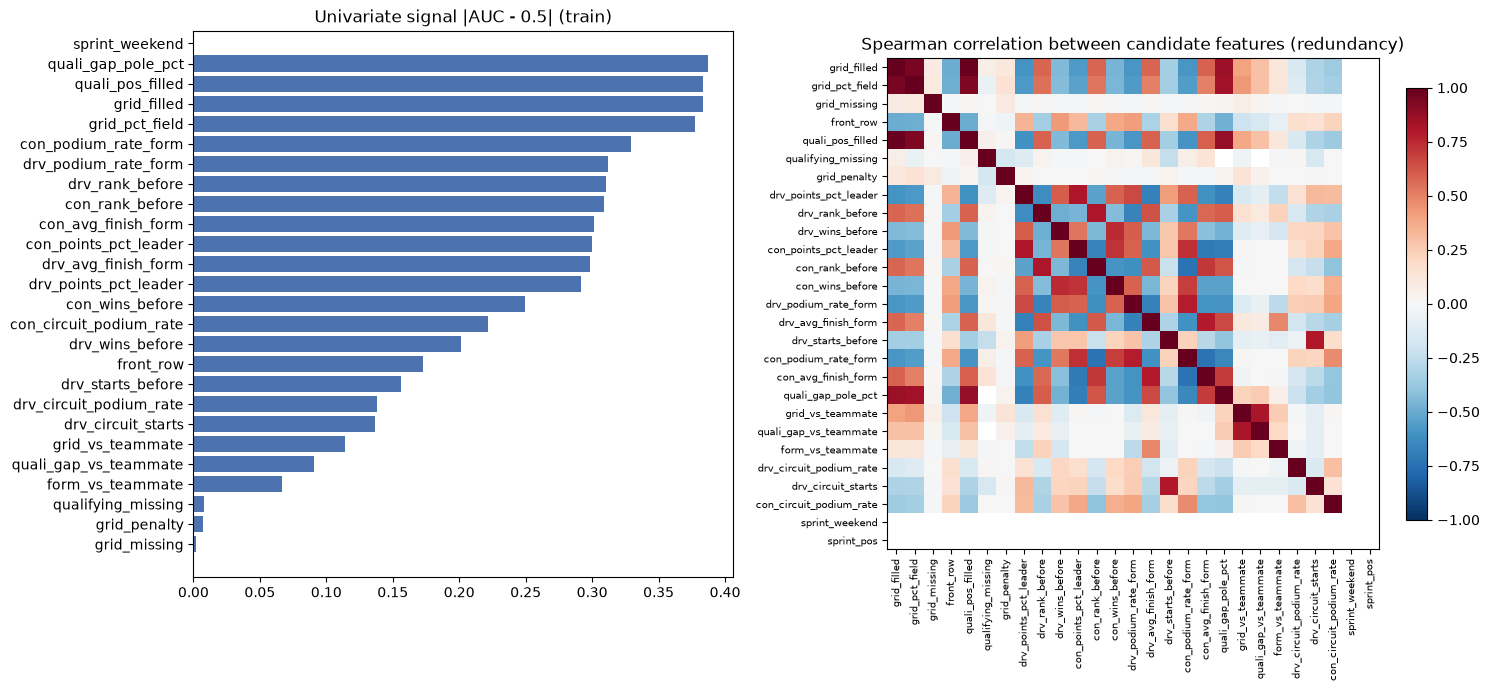

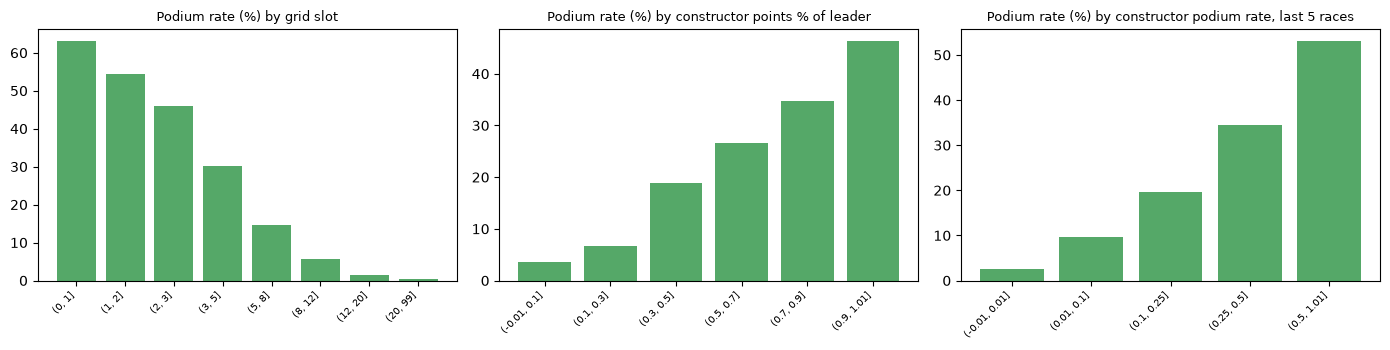

In [218]:
# Step 3 evidence: do the candidate features carry signal? (train split only; nothing from validation/test is looked at)
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import spearmanr

V2_CANDIDATES = {**V2_GROUPS, **{g: c for g, c in V2_OPTIONAL.items() if not set(c) & V2_CAT and g != "race_context"}}
num_candidates = [c for g in V2_CANDIDATES.values() for c in g]
rows = []
for gname, cols in V2_CANDIDATES.items():
    for c in cols:
        x = v2_train[c].astype(float); y = v2_train["podium"]
        ok = x.notna()
        usable = ok.sum() >= 200 and x[ok].nunique() > 1          # e.g. sprint results exist only from 2021: nothing to learn from in train
        auc = roc_auc_score(y[ok], x[ok]) if usable else np.nan
        rho = spearmanr(x[ok], y[ok])[0] if usable else np.nan
        mi = mutual_info_classif(x[ok].to_frame(), y[ok], random_state=0)[0] if usable else np.nan
        rows.append({"group": gname + ("" if gname in V2_GROUPS else " (optional)"), "feature": c, "missing_%": 100 * (~ok).mean(), "spearman": rho,
                     "univariate_AUC": auc, "AUC_strength(|AUC-0.5|)": abs(auc - 0.5), "mutual_info": mi})
evidence = pd.DataFrame(rows)
display(evidence.round(3))
print("Features with NaN statistics have fewer than 200 usable TRAIN rows (e.g. sprint results exist only from 2021, i.e. after the training years).")

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
ev = evidence.sort_values("AUC_strength(|AUC-0.5|)")
ax[0].barh(ev["feature"], ev["AUC_strength(|AUC-0.5|)"], color="#4C72B0"); ax[0].set_title("Univariate signal |AUC - 0.5| (train)")
corr = v2_train[num_candidates].astype(float).corr(method="spearman")
im = ax[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(corr))); ax[1].set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax[1].set_yticks(range(len(corr))); ax[1].set_yticklabels(corr.columns, fontsize=7)
ax[1].set_title("Spearman correlation between candidate features (redundancy)"); plt.colorbar(im, ax=ax[1], fraction=.04)
plt.tight_layout(); plt.show()

# Podium rate against the three strongest drivers of the problem logic: grid, constructor standing, constructor form
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, (col, bins, title) in zip(ax, [("grid_filled", [0, 1, 2, 3, 5, 8, 12, 20, 99], "grid slot"),
                                         ("con_points_pct_leader", [-.01, .1, .3, .5, .7, .9, 1.01], "constructor points % of leader"),
                                         ("con_podium_rate_form", [-.01, .01, .1, .25, .5, 1.01], "constructor podium rate, last 5 races")]):
    s = v2_train.dropna(subset=[col]).groupby(pd.cut(v2_train.dropna(subset=[col])[col], bins))["podium"].mean() * 100
    a.bar(range(len(s)), s.values, color="#55A868"); a.set_xticks(range(len(s))); a.set_xticklabels([str(i) for i in s.index], rotation=45, ha="right", fontsize=7)
    a.set_title("Podium rate (%) by " + title, fontsize=9)
plt.tight_layout(); plt.show()

<a id="h237"></a>
### B.6 Shared modelling machinery
<a id="c217"></a>
*Code cell 219* | [Back to contents](#toc)
One preprocessing for all models: numeric median-imputation **with missing-indicators** + scaling; categorical one-hot with rare levels grouped and unseen levels tolerated. `v2_fit_predict` fits the preprocessing on the training rows only and averages stochastic models over seeds. `v2_cv` scores a configuration on **rolling-origin folds** - train on earlier seasons, validate on the next one (2017, 2018, 2019, then the official 2020–21 validation). The test years are not even loaded (`v2_dev ≤ 2021`).


In [219]:
# Shared modelling machinery: ONE preprocessing, ONE table, used by every model and every ablation
def v2_split_cols(groups):
    cols = [c for g in groups for c in {**V2_GROUPS, **V2_OPTIONAL}[g]]
    return [c for c in cols if c not in V2_CAT], [c for c in cols if c in V2_CAT]

def v2_preprocessor(groups):
    num, cat = v2_split_cols(groups)
    parts = []
    if num:
        parts.append(("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),   # indicator keeps 'was missing'
                                       ("sc", StandardScaler())]), num))
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), cat))
    return ColumnTransformer(parts)

# --- PyTorch shallow network (the brief suggests Keras/PyTorch; wrapped so it plugs into the same pipeline as the sklearn models) ---
try:
    import torch, torch.nn as nn
    torch.set_num_threads(2); V2_HAS_TORCH = True
except Exception as _e:                                   # torch not installed: the notebook still runs, without this model
    V2_HAS_TORCH = False; print("PyTorch not available -> the PyTorch network is skipped:", _e)

if V2_HAS_TORCH:
    class V2TorchMLP:
        """1-2 hidden-layer MLP trained with Adam + weight decay; class imbalance handled with pos_weight."""
        def __init__(self, hidden=(32,), dropout=0.2, weight_decay=1e-3, lr=2e-3, epochs=40, batch=256, random_state=0):
            self.hidden, self.dropout, self.weight_decay, self.lr = hidden, dropout, weight_decay, lr
            self.epochs, self.batch, self.random_state = epochs, batch, random_state
        def fit(self, X, y):
            torch.manual_seed(self.random_state); rs = np.random.RandomState(self.random_state)
            X = torch.tensor(np.asarray(X, dtype="float32")); y_np = np.asarray(y, dtype="float32"); yt = torch.tensor(y_np)
            layers, d = [], X.shape[1]
            for h in self.hidden:
                layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(self.dropout)]; d = h
            layers.append(nn.Linear(d, 1)); self.net_ = nn.Sequential(*layers)
            pos_w = torch.tensor((1 - y_np.mean()) / max(y_np.mean(), 1e-6))
            loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
            opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
            n = len(X)
            for _ in range(self.epochs):
                self.net_.train(); order = rs.permutation(n)
                for i in range(0, n, self.batch):
                    idx = torch.tensor(order[i:i + self.batch])
                    opt.zero_grad(); loss = loss_fn(self.net_(X[idx]).squeeze(1), yt[idx]); loss.backward(); opt.step()
            self.classes_ = np.array([0, 1]); return self
        def predict_proba(self, X):
            self.net_.eval()
            with torch.no_grad():
                p = torch.sigmoid(self.net_(torch.tensor(np.asarray(X, dtype="float32"))).squeeze(1)).numpy()
            return np.column_stack([1 - p, p])

def v2_model(kind, params=None, seed=V2_SEED):
    p = dict(params or {})
    if kind == "LR":
        return LogisticRegression(max_iter=3000, class_weight="balanced", random_state=seed, **p)
    if kind == "RF":
        return RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=seed, **p)
    if kind == "HGB":
        return HistGradientBoostingClassifier(max_iter=150, random_state=seed, **p)
    if kind == "MLP":
        return MLPClassifier(max_iter=300, early_stopping=False, random_state=seed, **p)
    if kind == "TORCH":
        return V2TorchMLP(random_state=seed, **p)
    raise ValueError(kind)

V2_STOCHASTIC = {"LR": False, "RF": True, "HGB": False, "MLP": True, "TORCH": True}

def v2_fit_predict(kind, params, groups, train, evals, seeds=(V2_SEED,), pre=None):
    """Fit on `train`, return one probability vector per frame in `evals`. Stochastic models are averaged over seeds."""
    pre = pre if pre is not None else v2_preprocessor(groups)
    cols = [c for g in groups for c in {**V2_GROUPS, **V2_OPTIONAL}[g]]
    Xtr = pre.fit_transform(train[cols])                       # preprocessing fitted on the training rows ONLY
    Xev = [pre.transform(e[cols]) for e in evals]
    use = seeds if V2_STOCHASTIC[kind] else seeds[:1]
    out = [np.zeros(len(e)) for e in evals]
    for s in use:
        m = v2_model(kind, params, s).fit(Xtr, train["podium"])
        for i, X in enumerate(Xev):
            out[i] += m.predict_proba(X)[:, 1] / len(use)
    return out

def v2_best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
    return th[int(np.argmax(f1))]

def v2_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"ROC_AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p), "F1": f1_score(y, pred, zero_division=0),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0)}

# Rolling-origin folds INSIDE train+validation (train-only history before each validation block). The test split is never touched here.
V2_FOLDS = [(2016, (2017, 2017)), (2017, (2018, 2018)), (2018, (2019, 2019)), (V2_TRAIN_END, V2_VAL_YEARS)]
v2_dev = v2_df[v2_df["year"] <= V2_VAL_YEARS[1]]           # <= 2021: test years are not even loaded into the search

def v2_cv(kind, params, groups, start=1950, folds=V2_FOLDS, frame=None, pre_fn=None):
    """Mean PR-AUC over the rolling-origin folds. `frame` / `pre_fn` let the preprocessing experiments swap the table or the preprocessing."""
    scores = []
    src = v2_dev if frame is None else frame[frame["year"] <= V2_VAL_YEARS[1]]
    for tr_end, (v0, v1) in folds:
        tr = src[(src["year"] >= start) & (src["year"] <= tr_end)]
        va = src[src["year"].between(v0, v1)]
        if len(tr) < 200 or va["podium"].sum() == 0: continue
        p = v2_fit_predict(kind, params, groups, tr, [va], pre=(pre_fn(groups) if pre_fn else None))[0]
        scores.append(average_precision_score(va["podium"], p))
    return float(np.mean(scores)), scores

# smoke test on the simplest configuration
_s, _all = v2_cv("LR", {"C": 1.0}, V2_CORE)
print("smoke test LR core, PR-AUC per rolling-origin fold:", np.round(_all, 3), "mean", round(_s, 4))

smoke test LR core, PR-AUC per rolling-origin fold: [0.7   0.669 0.726 0.728] mean 0.7058


<a id="h238"></a>
### B.7 Step 3 experiments - training window, then optional feature groups
<a id="c218"></a>
*Code cell 220* | [Back to contents](#toc)
* **Training window (first).** Trains from 1950 / 1980 / 1996 / 2003 using the six core groups. More data is preferred unless a later start is clearly better (> 0.005 PR-AUC). This is the empirical answer to the qualifying-coverage drift from the intro, and it is decided *before* the optional groups so those are judged on the data the models will actually use.
* **Optional groups.** Each optional group (`quali_times`, `teammate`, `circuit_history`, `race_context`, `circuit`, `driver_id`, `constructor_id`) is added to the core set and judged on the rolling-origin PR-AUC of LR and RF. Rule: adopt only if **both** gain > 0.005. A group with (almost) no training rows - the **sprint** features, since sprint results exist only from 2021 - is reported as *not learnable* instead of trialled. The full trial table is kept.

The decisions are *computed*, not typed; read them in the printed output.


In [220]:
# Step 3 experiments (kept in the notebook): (1) which TRAINING WINDOW, then (2) which OPTIONAL groups earn a place under that window
trial_models = [("LR", {"C": 1.0}), ("RF", {"min_samples_leaf": 3, "max_features": "sqrt"})]

# (1) Training window - the empirical answer to the qualifying-coverage drift. Judged with the 6 core groups.
scope_rows = []
for start in [1950, 1980, 1996, 2003]:
    for kind, prm in trial_models:
        mean, per = v2_cv(kind, prm, V2_CORE, start=start)
        scope_rows.append({"train_from": start, "model": kind, "cv_PR_AUC": mean})
v2_scope = pd.DataFrame(scope_rows).pivot(index="train_from", columns="model", values="cv_PR_AUC")
v2_scope["mean"] = v2_scope.mean(axis=1)
display(v2_scope.round(4))
V2_START = 1950 if v2_scope.loc[1950, "mean"] >= v2_scope["mean"].max() - 0.005 else int(v2_scope["mean"].idxmax())   # prefer MORE data unless a window is clearly better
print("Training window used from now on: seasons >=", V2_START)

# (2) Optional groups, judged on that window.
def v2_testable(g):                                       # a group can only be judged if the TRAIN years actually contain it
    return all(v2_train[(v2_train["year"] >= V2_START)][c].notna().sum() >= 200 for c in V2_OPTIONAL[g] if c not in V2_CAT)
UNTESTABLE = [g for g in V2_OPTIONAL if not v2_testable(g)]
print("Optional groups with (almost) no training rows -> cannot be learned, not trialled:", UNTESTABLE or "none")
sets = {"core (6 groups)": V2_CORE}
for g in V2_OPTIONAL:
    if g in UNTESTABLE: continue
    sets[f"core + {g}"] = V2_CORE + [g]
sets["core + race_context + circuit"] = V2_CORE + ["race_context", "circuit"]
trial_rows = []
for name, groups in sets.items():
    for kind, prm in trial_models:
        mean, per = v2_cv(kind, prm, groups, start=V2_START)
        trial_rows.append({"feature_set": name, "model": kind, "cv_PR_AUC": mean, **{f"fold{i+1}": s for i, s in enumerate(per)}})
v2_trials = pd.DataFrame(trial_rows)
piv = v2_trials.pivot(index="feature_set", columns="model", values="cv_PR_AUC")
piv["gain_vs_core(min over models)"] = (piv[["LR", "RF"]] - piv.loc["core (6 groups)", ["LR", "RF"]]).min(axis=1)
display(piv.round(4)); display(v2_trials.round(4))

# Decision rule written BEFORE seeing the numbers: adopt an optional group only if BOTH models improve by more than 0.005 PR-AUC.
V2_ADOPT = [g for g in V2_OPTIONAL if g not in UNTESTABLE and piv.loc[f"core + {g}", "gain_vs_core(min over models)"] > 0.005]
V2_FINAL_GROUPS = V2_CORE + V2_ADOPT
print("Optional groups adopted:", V2_ADOPT or "none")
print("FINAL FEATURE GROUPS   :", V2_FINAL_GROUPS)

model,LR,RF,mean
train_from,,,
1950,0.7058,0.7191,0.7124
1980,0.7058,0.7277,0.7168
1996,0.7106,0.7238,0.7172
2003,0.7151,0.7242,0.7197


Training window used from now on: seasons >= 2003
Optional groups with (almost) no training rows -> cannot be learned, not trialled: ['sprint']


model,LR,RF,gain_vs_core(min over models)
feature_set,,,
core (6 groups),0.7151,0.7242,0.0000
core + circuit,0.7079,0.7300,-0.0072
core + circuit_history,0.7160,0.7304,0.0008
core + constructor_id,0.7006,0.7248,-0.0145
core + driver_id,0.7071,0.7342,-0.0081
core + quali_times,0.7155,0.7271,0.0004
core + race_context,0.7145,0.7230,-0.0012
core + race_context + circuit,0.7051,0.7287,-0.0100
core + teammate,0.7150,0.7315,-0.0002


,feature_set,model,cv_PR_AUC,fold1,fold2,fold3,fold4
0,core (6 groups),LR,0.7151,0.7262,0.6759,0.7283,0.7301
1,core (6 groups),RF,0.7242,0.7622,0.6827,0.7716,0.6802
2,core + quali_times,LR,0.7155,0.7175,0.6756,0.7330,0.7361
3,core + quali_times,RF,0.7271,0.7686,0.6774,0.7689,0.6936
4,core + teammate,LR,0.7150,0.7422,0.6685,0.7199,0.7292
5,core + teammate,RF,0.7315,0.7566,0.6932,0.7800,0.6962
6,core + circuit_history,LR,0.7160,0.7277,0.6764,0.7324,0.7273
7,core + circuit_history,RF,0.7304,0.7659,0.6921,0.7601,0.7035
8,core + race_context,LR,0.7145,0.7263,0.6786,0.7278,0.7255
9,core + race_context,RF,0.7230,0.7526,0.6803,0.7749,0.6840


Optional groups adopted: none
FINAL FEATURE GROUPS   : ['grid', 'qualifying', 'driver_standings', 'constructor_standings', 'driver_form', 'constructor_form']


<a id="h239"></a>
### B.7b The models: how each works, and its limitations
| Model | How it works | Limitations here |
|---|---|---|
| **Logistic regression** *(statistical baseline)* | Weighted sum of standardised features passed through a sigmoid; weights learned by maximum likelihood with L2 regularisation (`C`). Class weights compensate for the ~15 % podium rate. | Only monotone / linear-in-the-features effects; correlated features (grid, qualifying, standings) share weight unpredictably; missing-indicator columns act as era flags. |
| **Random forest** | Many decision trees on bootstrap samples with random feature subsets; probability = average vote. Leaf size limits over-fitting. | Probabilities are coarse; high train–test gap (memorises the training years); no extrapolation to new eras. |
| **Gradient boosting (HistGB)** | Trees built one after another, each correcting the previous errors, with a small learning rate. | Sensitive to learning rate / depth; ~1.3 k test rows means small differences are noise. |
| **Shallow NN (sklearn MLP and PyTorch)** | 1–2 hidden layers (ReLU) trained with Adam and weight decay; PyTorch version adds dropout and a class-weighted loss. | Seed-dependent (hence 3-seed averaging); needs scaling; hardest to interpret; no gain over LR in the experiments. |

**Shared limitations (state them in the report):** about two validation seasons and three test seasons; qualifying data absent before 1994 (grid fallback + missing-flag); era sensitivity (rules and car dominance change); only pre-race information, so safety cars, rain and first-lap incidents are invisible; constructor renames reset form history.

<a id="h240"></a>
### B.8 Step 4 - hyper-parameter search
<a id="c219"></a>
*Code cell 221* | [Back to contents](#toc)
Small, explicit grids for LR (`C`), RF (leaf size, `max_features`), gradient boosting (learning rate, depth), the shallow sklearn MLP (1–2 hidden layers, L2 `alpha`) and a **PyTorch** shallow network (1–2 hidden layers, dropout, weight decay; skipped automatically if PyTorch is not installed). Every configuration is scored on the same rolling-origin folds; the best mean PR-AUC is selected and the whole trial table is kept. The spread per model shows how much tuning mattered. **No test data and no test-year labels are used.**


In [221]:
# Step 4: hyper-parameter search (rolling-origin folds inside train/validation only - the test split is untouched)
GRIDS = {
    "LR":  [{"C": c} for c in (0.01, 0.1, 1.0, 10.0)],
    "RF":  [{"min_samples_leaf": l, "max_features": f} for l in (1, 3, 10) for f in ("sqrt", 0.5)],
    "HGB": [{"learning_rate": lr, "max_depth": d, "l2_regularization": 1.0} for lr in (0.03, 0.1) for d in (2, 4)],
    "MLP": [{"hidden_layer_sizes": h, "alpha": a} for h in ((16,), (32,), (32, 16)) for a in (1e-3, 1e-2)],
}
if V2_HAS_TORCH:
    GRIDS["TORCH"] = [{"hidden": h, "weight_decay": w} for h in ((16,), (32,), (32, 16)) for w in (1e-3, 1e-2)]
hpo_rows = []
for kind, grid in GRIDS.items():
    for prm in grid:
        mean, per = v2_cv(kind, prm, V2_FINAL_GROUPS, start=V2_START)
        hpo_rows.append({"model": kind, "params": str(prm), "cv_PR_AUC": mean, "folds": np.round(per, 3).tolist(), "_prm": prm})
v2_hpo = pd.DataFrame(hpo_rows)
v2_best = {k: v2_hpo[v2_hpo["model"] == k].sort_values("cv_PR_AUC", ascending=False).iloc[0] for k in GRIDS}
display(v2_hpo.drop(columns="_prm").sort_values(["model", "cv_PR_AUC"], ascending=[True, False]).round(4))
V2_PARAMS = {k: v["_prm"] for k, v in v2_best.items()}
print("Selected hyper-parameters:", V2_PARAMS)

# Learning-curve style evidence that capacity was not the problem: best vs worst config per model
display(v2_hpo.groupby("model")["cv_PR_AUC"].agg(["min", "max"]).assign(spread=lambda d: d["max"] - d["min"]).round(4))

,model,params,cv_PR_AUC,folds
11,HGB,"{'learning_rate': 0.03, 'max_depth': 4, 'l2_re...",0.7327,"[0.745, 0.69, 0.773, 0.724]"
10,HGB,"{'learning_rate': 0.03, 'max_depth': 2, 'l2_re...",0.7291,"[0.729, 0.694, 0.763, 0.73]"
12,HGB,"{'learning_rate': 0.1, 'max_depth': 2, 'l2_reg...",0.7182,"[0.716, 0.681, 0.766, 0.71]"
13,HGB,"{'learning_rate': 0.1, 'max_depth': 4, 'l2_reg...",0.7121,"[0.728, 0.671, 0.761, 0.689]"
2,LR,{'C': 1.0},0.7151,"[0.726, 0.676, 0.728, 0.73]"
1,LR,{'C': 0.1},0.7148,"[0.728, 0.676, 0.729, 0.727]"
3,LR,{'C': 10.0},0.7144,"[0.726, 0.676, 0.727, 0.729]"
0,LR,{'C': 0.01},0.7138,"[0.73, 0.672, 0.735, 0.718]"
16,MLP,"{'hidden_layer_sizes': (32,), 'alpha': 0.001}",0.7222,"[0.728, 0.706, 0.736, 0.719]"
17,MLP,"{'hidden_layer_sizes': (32,), 'alpha': 0.01}",0.7190,"[0.714, 0.7, 0.74, 0.722]"


Selected hyper-parameters: {'LR': {'C': 1.0}, 'RF': {'min_samples_leaf': 10, 'max_features': 'sqrt'}, 'HGB': {'learning_rate': 0.03, 'max_depth': 4, 'l2_regularization': 1.0}, 'MLP': {'hidden_layer_sizes': (32,), 'alpha': 0.001}, 'TORCH': {'hidden': (32,), 'weight_decay': 0.001}}


,min,max,spread
model,,,
HGB,0.7121,0.7327,0.0206
LR,0.7138,0.7151,0.0013
MLP,0.6754,0.7222,0.0467
RF,0.6934,0.7325,0.0391
TORCH,0.7112,0.7202,0.0090


<a id="h241"></a>
### B.9 Step 4 - final models, baselines, metrics on train / validation / test
<a id="c220"></a>
*Code cell 222* | [Back to contents](#toc)
All five models (LR, RF, gradient boosting, sklearn MLP, PyTorch network) use the identical table and feature groups; the stochastic ones are averaged over three seeds. **Baselines** (what the models must beat):
* rank by grid slot only (a model with zero learning),
* rank by constructor recent form only,
* the constant prior.

The decision threshold of each model is the F1-maximising one **on validation** and is then frozen. Tables for ROC-AUC, PR-AUC and F1 show **Train / Validation / Test** side by side - the train–validation gap shows over-fitting, validation–test shows drift.


In [222]:
# Step 4 - final models: SAME table, SAME features, SAME preprocessing for every model; thresholds picked on VALIDATION only
V2_SEEDS = (42, 7, 123)                       # stochastic models (RF, MLP) are averaged over 3 seeds
v2_fit_df = v2_df[(v2_df["year"] >= V2_START) & (v2_df["year"] <= V2_TRAIN_END)]
v2_frames = {"Train": v2_fit_df, "Validation": v2_val, "Test": v2_test}
print(f"Models are fitted on seasons {V2_START}-{V2_TRAIN_END}: {len(v2_fit_df):,} rows ({v2_fit_df['raceId'].nunique()} races) | "
      f"validation {len(v2_val):,} rows | test {len(v2_test):,} rows")
NAMES = {"LR": "Logistic Regression", "RF": "Random Forest", "HGB": "Gradient Boosting (HistGB)", "MLP": "Shallow NN (sklearn MLP)"}
if V2_HAS_TORCH: NAMES["TORCH"] = "Shallow NN (PyTorch)"

v2_prob = {}                                   # v2_prob[model][split] -> probabilities
for kind in NAMES:
    ps = v2_fit_predict(kind, V2_PARAMS[kind], V2_FINAL_GROUPS, v2_fit_df, list(v2_frames.values()), seeds=V2_SEEDS)
    v2_prob[NAMES[kind]] = dict(zip(v2_frames, ps))

# Baselines. They use no learning at all (or only the grid) and set the bar the models must clear.
def _rank_score(df, col, sign=-1): return sign * df[col].values.astype(float)
v2_prob["Baseline: grid slot (rank by -grid)"] = {s: _rank_score(f, "grid_filled") for s, f in v2_frames.items()}
v2_prob["Baseline: constructor form only"] = {s: np.nan_to_num(f["con_podium_rate_form"].values.astype(float), nan=0.0) for s, f in v2_frames.items()}
_prior = v2_fit_df["podium"].mean()
v2_prob["Baseline: prior (constant)"] = {s: np.full(len(f), _prior) for s, f in v2_frames.items()}

v2_thr = {m: v2_best_threshold(v2_val["podium"].values, p["Validation"]) for m, p in v2_prob.items()}   # VALIDATION only
rows = []
for m, p in v2_prob.items():
    for s, f in v2_frames.items():
        rows.append({"model": m, "split": s, "threshold(val)": v2_thr[m], **v2_metrics(f["podium"].values, p[s], v2_thr[m])})
v2_final = pd.DataFrame(rows)
for metric in ("ROC_AUC", "PR_AUC", "F1"):
    display(v2_final.pivot(index="model", columns="split", values=metric)[["Train", "Validation", "Test"]].round(4).rename_axis(metric))
print("Thresholds above were chosen on the validation predictions of each train-fitted model; the test split was only scored.")

Models are fitted on seasons 2003-2019: 6,824 rows (321 races) | validation 780 rows | test 1,357 rows


split,Train,Validation,Test
ROC_AUC,,,
Baseline: constructor form only,0.8746,0.8549,0.8767
Baseline: grid slot (rank by -grid),0.9085,0.9094,0.9137
Baseline: prior (constant),0.5000,0.5000,0.5000
Gradient Boosting (HistGB),0.9498,0.9308,0.9359
Logistic Regression,0.9312,0.9269,0.9369
Random Forest,0.9645,0.9294,0.9374
Shallow NN (PyTorch),0.9376,0.9300,0.9377
Shallow NN (sklearn MLP),0.9446,0.9266,0.9320


split,Train,Validation,Test
PR_AUC,,,
Baseline: constructor form only,0.5103,0.5077,0.4804
Baseline: grid slot (rank by -grid),0.6258,0.6386,0.6473
Baseline: prior (constant),0.1411,0.1500,0.1503
Gradient Boosting (HistGB),0.7597,0.7237,0.7171
Logistic Regression,0.6900,0.7301,0.7173
Random Forest,0.8126,0.7064,0.7108
Shallow NN (PyTorch),0.7053,0.7393,0.7142
Shallow NN (sklearn MLP),0.7440,0.7174,0.7063


split,Train,Validation,Test
F1,,,
Baseline: constructor form only,0.5667,0.6380,0.5632
Baseline: grid slot (rank by -grid),0.6462,0.6923,0.6486
Baseline: prior (constant),0.2473,0.2609,0.2614
Gradient Boosting (HistGB),0.7017,0.7016,0.6564
Logistic Regression,0.6692,0.6992,0.6637
Random Forest,0.7329,0.7059,0.6667
Shallow NN (PyTorch),0.6784,0.7049,0.6667
Shallow NN (sklearn MLP),0.6868,0.7045,0.6680


Thresholds above were chosen on the validation predictions of each train-fitted model; the test split was only scored.


<a id="h242"></a>
### B.9b Extra - refit on train + validation
<a id="c221"></a>
*Code cell 223* | [Back to contents](#toc)
The final recipe for use on future races: keep the hyper-parameters and thresholds selected above and train on **all seasons up to 2021**, then score the test seasons once. The table shows what the extra two seasons change. The train-only table above remains the headline (the cleanest protocol).


In [223]:
# Step 4 - extra: refit on train + validation (more recent seasons) and score the test seasons ONCE
# Hyper-parameters and thresholds stay exactly as selected above (train/validation only); only the training rows grow.
v2_refit_df = v2_df[(v2_df["year"] >= V2_START) & (v2_df["year"] <= V2_VAL_YEARS[1])]
rows = []
for kind in NAMES:
    p = v2_fit_predict(kind, V2_PARAMS[kind], V2_FINAL_GROUPS, v2_refit_df, [v2_test], seeds=V2_SEEDS)[0]
    m = v2_metrics(v2_test["podium"].values, p, v2_thr[NAMES[kind]])
    base_m = v2_final[(v2_final.model == NAMES[kind]) & (v2_final.split == "Test")].iloc[0]
    rows.append({"model": NAMES[kind], **{f"{k}_train_only": base_m[k] for k in ("ROC_AUC", "PR_AUC", "F1")},
                 **{f"{k}_refit(train+val)": m[k] for k in ("ROC_AUC", "PR_AUC", "F1")}})
v2_refit = pd.DataFrame(rows)
for k in ("ROC_AUC", "PR_AUC", "F1"):
    v2_refit[f"{k}_change"] = v2_refit[f"{k}_refit(train+val)"] - v2_refit[f"{k}_train_only"]
display(v2_refit.round(4))
print("The train-only numbers remain the headline results (cleanest protocol). A refit is the deployment recipe: same settings, more recent data.")

,model,ROC_AUC_train_only,PR_AUC_train_only,F1_train_only,ROC_AUC_refit(train+val),PR_AUC_refit(train+val),F1_refit(train+val),ROC_AUC_change,PR_AUC_change,F1_change
0,Logistic Regression,0.9369,0.7173,0.6637,0.9374,0.7180,0.6667,0.0005,0.0007,0.0030
1,Random Forest,0.9374,0.7108,0.6667,0.9374,0.7089,0.6667,-0.0001,-0.0019,0.0000
2,Gradient Boosting (HistGB),0.9359,0.7171,0.6564,0.9360,0.7110,0.6594,0.0001,-0.0061,0.0030
3,Shallow NN (sklearn MLP),0.9320,0.7063,0.6680,0.9334,0.7064,0.6653,0.0014,0.0001,-0.0027
4,Shallow NN (PyTorch),0.9377,0.7142,0.6667,0.9383,0.7132,0.6651,0.0006,-0.0010,-0.0015


The train-only numbers remain the headline results (cleanest protocol). A refit is the deployment recipe: same settings, more recent data.


<a id="h243"></a>
### B.10 Is the improvement over the baseline real?
<a id="c222"></a>
*Code cell 224* | [Back to contents](#toc)
Race-level (cluster) bootstrap of PR-AUC and of the **paired difference vs the grid baseline**. Rows from one race are correlated, so resampling rows would give intervals that are too narrow; resampling races does not. A model is said to beat the baseline only if the interval of the difference excludes 0; overlapping model intervals mean the ranking *between* models is not established.


In [224]:
# Step 4 - how much of the model ranking is real? Race-level (cluster) bootstrap + paired differences vs. the grid baseline
rng = np.random.default_rng(0)
def cluster_boot(frame, prob_by_model, metric, B=400):
    races = frame["raceId"].values; uniq = np.unique(races)
    idx = {r: np.where(races == r)[0] for r in uniq}
    y = frame["podium"].values; out = {m: [] for m in prob_by_model}
    for _ in range(B):
        pick = np.concatenate([idx[r] for r in rng.choice(uniq, len(uniq))])
        if y[pick].sum() == 0: continue
        for m, p in prob_by_model.items():
            out[m].append(metric(y[pick], p[pick]))
    return {m: np.array(v) for m, v in out.items()}

base = "Baseline: grid slot (rank by -grid)"
ci_rows = []
for split in ("Validation", "Test"):
    probs = {m: p[split] for m, p in v2_prob.items()}
    boots = cluster_boot(v2_frames[split], probs, average_precision_score)
    for m, b in boots.items():
        d = b - boots[base]
        ci_rows.append({"split": split, "model": m, "PR_AUC": average_precision_score(v2_frames[split]["podium"], probs[m]),
                        "CI95_low": np.percentile(b, 2.5), "CI95_high": np.percentile(b, 97.5),
                        "delta_vs_grid_baseline": d.mean(), "delta_CI95_low": np.percentile(d, 2.5), "delta_CI95_high": np.percentile(d, 97.5),
                        "P(model > baseline)": (d > 0).mean()})
v2_ci = pd.DataFrame(ci_rows)
display(v2_ci.round(4))
print("A model 'beats' the baseline only if its delta CI excludes 0. Overlapping model CIs mean the ranking between models is NOT established on this much data.")

,split,model,PR_AUC,CI95_low,CI95_high,delta_vs_grid_baseline,delta_CI95_low,delta_CI95_high,P(model > baseline)
0,Validation,Logistic Regression,0.7301,0.6190,0.8378,0.0933,0.0398,0.1443,1.0000
1,Validation,Random Forest,0.7064,0.5993,0.8282,0.0733,0.0260,0.1263,1.0000
2,Validation,Gradient Boosting (HistGB),0.7237,0.6145,0.8304,0.0857,0.0501,0.1268,1.0000
3,Validation,Shallow NN (sklearn MLP),0.7174,0.6187,0.8157,0.0799,0.0429,0.1197,1.0000
4,Validation,Shallow NN (PyTorch),0.7393,0.6345,0.8379,0.1006,0.0621,0.1376,1.0000
5,Validation,Baseline: grid slot (rank by -grid),0.6386,0.5372,0.7464,0.0000,0.0000,0.0000,0.0000
6,Validation,Baseline: constructor form only,0.5077,0.4060,0.6281,-0.1272,-0.1821,-0.0649,0.0000
7,Validation,Baseline: prior (constant),0.1500,0.1500,0.1500,-0.4894,-0.5964,-0.3872,0.0000
8,Test,Logistic Regression,0.7173,0.6630,0.7716,0.0680,0.0259,0.1111,0.9975
9,Test,Random Forest,0.7108,0.6556,0.7700,0.0634,0.0270,0.1035,1.0000


A model 'beats' the baseline only if its delta CI excludes 0. Overlapping model CIs mean the ranking between models is NOT established on this much data.


<a id="h244"></a>
### B.11 ROC / PR / calibration, race-level metric, stability by season
<a id="c223"></a>
*Code cell 225* | [Back to contents](#toc)
* ROC and precision-recall curves on validation and test, with the grid baseline dashed.
* The **headline model** is the one with the best mean PR-AUC over the rolling-origin selection folds (not on the small validation block, never on test).
* Calibration of the headline model (class-weighted models are not calibrated by design; ranking metrics are the fair comparison).
* **Top-3-per-race hit rate** - the metric closest to the real task: pick the three most likely drivers in every race.
* PR-AUC per test season to check that one year does not carry the result.


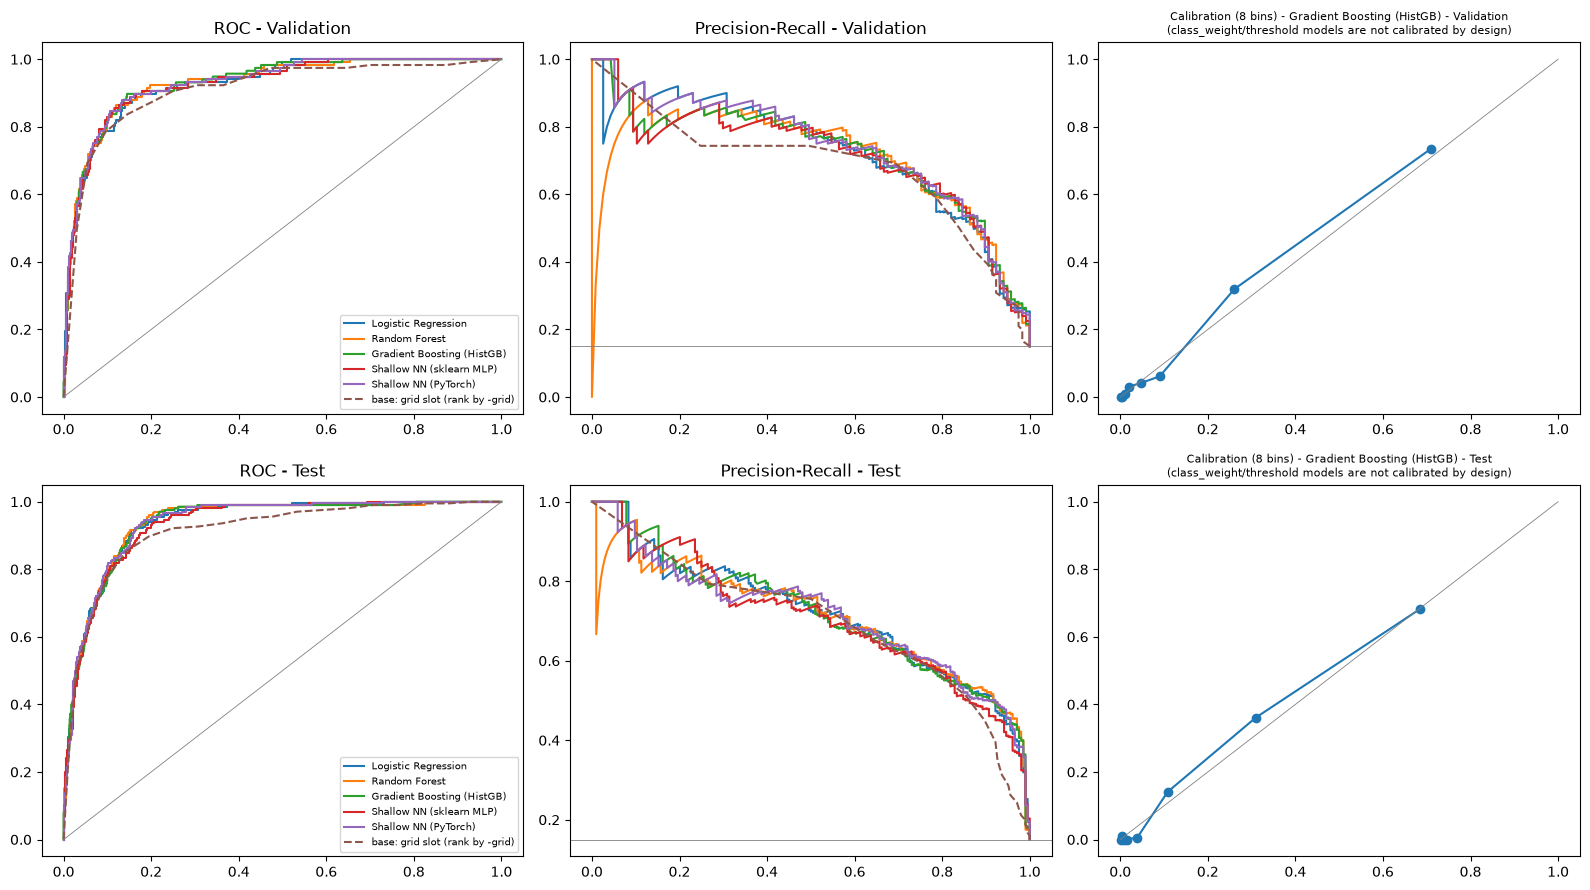

Headline model (best mean PR-AUC over the rolling-origin selection folds): Gradient Boosting (HistGB)


/tmp/ipykernel_5380/2031424783.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby("raceId").apply(lambda g: g.nlargest(3, "p")["podium"].sum() / 3).mean()
/tmp/ipykernel_5380/2031424783.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby("raceId").apply(lambda g: g.nlargest(3, "p")["podium"].sum() / 3).mean()
/tmp/ipykernel_5380/2031424783.py:28: DeprecationWarning: Data

/tmp/ipykernel_5380/2031424783.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby("raceId").apply(lambda g: g.nlargest(3, "p")["podium"].sum() / 3).mean()
/tmp/ipykernel_5380/2031424783.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby("raceId").apply(lambda g: g.nlargest(3, "p")["podium"].sum() / 3).mean()
/tmp/ipykernel_5380/2031424783.py:28: DeprecationWarning: Data

/tmp/ipykernel_5380/2031424783.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby("raceId").apply(lambda g: g.nlargest(3, "p")["podium"].sum() / 3).mean()
/tmp/ipykernel_5380/2031424783.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby("raceId").apply(lambda g: g.nlargest(3, "p")["podium"].sum() / 3).mean()


,Validation,Test
avg share of true podium picked per race,,
Logistic Regression,0.701,0.637
Random Forest,0.684,0.647
Gradient Boosting (HistGB),0.701,0.632
Shallow NN (sklearn MLP),0.692,0.627
Shallow NN (PyTorch),0.701,0.652
Baseline: grid slot (rank by -grid),0.692,0.652


model,Baseline: grid slot (rank by -grid),Gradient Boosting (HistGB)
year,,
2022,0.616,0.694
2023,0.678,0.751
2024,0.657,0.670


In [225]:
# Step 4 - curves and diagnostics (validation + test)
learned = [NAMES[k] for k in NAMES]
# Headline model: best mean PR-AUC on the rolling-origin SELECTION folds (not on the small validation block, and never on test)
V2_HEADLINE_KIND = max(NAMES, key=lambda k: v2_best[k]["cv_PR_AUC"]); V2_HEADLINE = NAMES[V2_HEADLINE_KIND]
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for r, split in enumerate(("Validation", "Test")):
    y = v2_frames[split]["podium"].values
    for m in learned + [base]:
        p = v2_prob[m][split]
        fpr, tpr, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
        ax[r, 0].plot(fpr, tpr, label=m.replace("Baseline: ", "base: "), ls="--" if m == base else "-")
        ax[r, 1].plot(rc, pr, ls="--" if m == base else "-")
    ax[r, 0].plot([0, 1], [0, 1], c="grey", lw=.6); ax[r, 0].set_title(f"ROC - {split}"); ax[r, 0].legend(fontsize=7)
    ax[r, 1].axhline(y.mean(), c="grey", lw=.6); ax[r, 1].set_title(f"Precision-Recall - {split}")
    # calibration of the best learned model by PR-AUC on validation
    best_m = V2_HEADLINE
    p = v2_prob[best_m][split]
    bins = pd.qcut(pd.Series(p).rank(method="first"), 8, labels=False)
    cal = pd.DataFrame({"p": p, "y": y, "b": bins}).groupby("b").mean()
    ax[r, 2].plot(cal["p"], cal["y"], marker="o"); ax[r, 2].plot([0, 1], [0, 1], c="grey", lw=.6)
    ax[r, 2].set_title(f"Calibration (8 bins) - {best_m} - {split}\n(class_weight/threshold models are not calibrated by design)", fontsize=8)
plt.tight_layout(); plt.show()
print("Headline model (best mean PR-AUC over the rolling-origin selection folds):", V2_HEADLINE)

# Race-level view: a podium has exactly 3 places, so also score "pick the 3 highest-probability drivers in every race"
def top3_hit(frame, p):
    d = frame[["raceId", "podium"]].assign(p=p)
    return d.groupby("raceId").apply(lambda g: g.nlargest(3, "p")["podium"].sum() / 3).mean()
display(pd.DataFrame({m: {s: top3_hit(v2_frames[s], v2_prob[m][s]) for s in ("Validation", "Test")} for m in learned + [base]}).T.round(3).rename_axis("avg share of true podium picked per race"))

# Stability by season on the test years
per_season = []
for m in [V2_HEADLINE, base]:
    for yr, g in v2_test.groupby("year"):
        pp = v2_prob[m]["Test"][v2_test.index.get_indexer(g.index)]
        per_season.append({"model": m, "year": yr, "PR_AUC": average_precision_score(g["podium"], pp), "ROC_AUC": roc_auc_score(g["podium"], pp)})
display(pd.DataFrame(per_season).pivot(index="year", columns="model", values="PR_AUC").round(3))

<a id="h245"></a>
### B.12 Attempt 1 vs final pipeline on the same test seasons
<a id="c224"></a>
*Code cell 226* | [Back to contents](#toc)
Side-by-side test metrics for the Part A models and the Part B models. Test years are identical (2022–2024); the train/validation boundaries differ (≤ 2018 / 2019–21 vs ≤ 2019 / 2020–21), which is stated under the table.


In [226]:
# Step 4 - was the rebuild worth it? Compare with the attempt-1 models on the SAME test seasons (2022-2024)
v1 = test_results_df.rename(columns={"model": "model"})[["model", "ROC_AUC", "PR_AUC", "F1"]].copy()
v1["pipeline"] = "attempt 1 (Part A: ~1,100 one-hot ID columns, no standings / form)"
v2cmp = v2_final[(v2_final["split"] == "Test") & (v2_final["model"].isin(learned))][["model", "ROC_AUC", "PR_AUC", "F1"]].copy()
v2cmp["pipeline"] = "final pipeline (Part B: leakage-checked, season-aware standings, form)"
cmp_df = pd.concat([v1, v2cmp], ignore_index=True)
display(cmp_df.round(4))
print("Test years are identical in both pipelines (2022-2024); train/validation boundaries differ (attempt 1: <=2018 / 2019-2021, final: <=2019 / 2020-2021).")

,model,ROC_AUC,PR_AUC,F1,pipeline
0,Logistic Regression,0.9103,0.6028,0.5426,"attempt 1 (Part A: ~1,100 one-hot ID columns, ..."
1,Random Forest,0.9210,0.6032,0.5768,"attempt 1 (Part A: ~1,100 one-hot ID columns, ..."
2,Shallow Neural Network,0.9087,0.5838,0.6033,"attempt 1 (Part A: ~1,100 one-hot ID columns, ..."
3,Logistic Regression,0.9369,0.7173,0.6637,"final pipeline (Part B: leakage-checked, seaso..."
4,Random Forest,0.9374,0.7108,0.6667,"final pipeline (Part B: leakage-checked, seaso..."
5,Gradient Boosting (HistGB),0.9359,0.7171,0.6564,"final pipeline (Part B: leakage-checked, seaso..."
6,Shallow NN (sklearn MLP),0.9320,0.7063,0.6680,"final pipeline (Part B: leakage-checked, seaso..."
7,Shallow NN (PyTorch),0.9377,0.7142,0.6667,"final pipeline (Part B: leakage-checked, seaso..."


Test years are identical in both pipelines (2022-2024); train/validation boundaries differ (attempt 1: <=2018 / 2019-2021, final: <=2019 / 2020-2021).


<a id="h246"></a>
## Part B — Step 5: experiments (feature-group ablation)

<a id="h247"></a>
### B.13 Remove one group at a time, for every model
<a id="c225"></a>
*Code cell 227* | [Back to contents](#toc)
* Variants: FULL, *without* each of the six groups, each group **alone** (add-back view), and **correlated groups removed together** (grid + qualifying, driver + constructor standings, driver + constructor form).
* Every variant is retrained for the four sklearn models (the PyTorch net is reported in the main tables, not ablated), with 3 seeds for RF/MLP; the threshold is re-selected on validation for each variant.
* Reported per group: **PR-AUC drop** on validation and test (positive = the group helps), a paired race-level 95 % interval for the test drop, ROC-AUC drop, F1 drop (marked noisy) and PR-AUC of the group alone. A bar chart summarises the test drops.

Reading guide: groups carry overlapping information (grid ≈ qualifying; standings ≈ form), so removing **one** often changes little - that is redundancy, not uselessness. The *together* table shows how much the whole information block is worth.


,model,group,PR_AUC_drop_val,PR_AUC_drop_test,test_drop_CI95_low,test_drop_CI95_high,ROC_AUC_drop_test,F1_drop_test(noisy),PR_AUC_group_alone_test
0,Logistic Regression,grid,-0.0003,0.0208,0.0027,0.0393,0.0035,0.0050,0.6498
1,Logistic Regression,qualifying,0.0067,0.0041,-0.0001,0.0092,0.0009,0.0111,0.6426
2,Logistic Regression,driver_standings,0.0131,0.0103,-0.0076,0.0280,0.0003,0.0043,0.5670
3,Logistic Regression,constructor_standings,0.0013,-0.0085,-0.0143,-0.0011,-0.0020,-0.0044,0.4852
4,Logistic Regression,driver_form,0.0067,-0.0103,-0.0218,0.0012,-0.0022,-0.0085,0.5304
5,Logistic Regression,constructor_form,-0.0007,0.0021,-0.0011,0.0048,0.0001,0.0053,0.5112
6,Random Forest,grid,-0.0154,0.0090,-0.0061,0.0295,0.0039,0.0078,0.6466
7,Random Forest,qualifying,0.0062,-0.0045,-0.0130,0.0040,-0.0004,0.0032,0.6400
8,Random Forest,driver_standings,0.0110,0.0075,-0.0049,0.0196,0.0003,0.0080,0.5514
9,Random Forest,constructor_standings,-0.0038,-0.0012,-0.0084,0.0062,-0.0006,-0.0015,0.4953


Correlated groups removed TOGETHER:


,model,removed together,PR_AUC_drop_val,PR_AUC_drop_test,test_drop_CI95_low,test_drop_CI95_high
0,Logistic Regression,without grid + qualifying (all start-position ...,0.0784,0.1440,0.0984,0.1871
1,Logistic Regression,without driver + constructor standings,0.0244,0.0025,-0.0195,0.0223
2,Logistic Regression,without driver + constructor form,0.0005,0.0006,-0.0146,0.0183
3,Random Forest,without grid + qualifying (all start-position ...,0.0472,0.1359,0.0774,0.1834
4,Random Forest,without driver + constructor standings,0.0141,0.0224,-0.0000,0.0467
5,Random Forest,without driver + constructor form,-0.0219,-0.0006,-0.0214,0.0198
6,Gradient Boosting (HistGB),without grid + qualifying (all start-position ...,0.0896,0.1402,0.0811,0.1905
7,Gradient Boosting (HistGB),without driver + constructor standings,0.0334,0.0054,-0.0151,0.0301
8,Gradient Boosting (HistGB),without driver + constructor form,-0.0036,0.0060,-0.0072,0.0183
9,Shallow NN (sklearn MLP),without grid + qualifying (all start-position ...,0.0787,0.1529,0.1047,0.1986


model,Gradient Boosting (HistGB),Logistic Regression,Random Forest,Shallow NN (sklearn MLP),mean_drop_over_models
PR-AUC lost on TEST when the group is removed,,,,,
grid,0.0050,0.0208,0.0090,0.0180,0.0132
driver_standings,-0.0004,0.0103,0.0075,-0.0025,0.0038
constructor_form,0.0008,0.0021,-0.0023,0.0136,0.0035
qualifying,-0.0027,0.0041,-0.0045,-0.0018,-0.0013
constructor_standings,0.0019,-0.0085,-0.0012,-0.0044,-0.0031
driver_form,0.0010,-0.0103,-0.0011,-0.0113,-0.0054


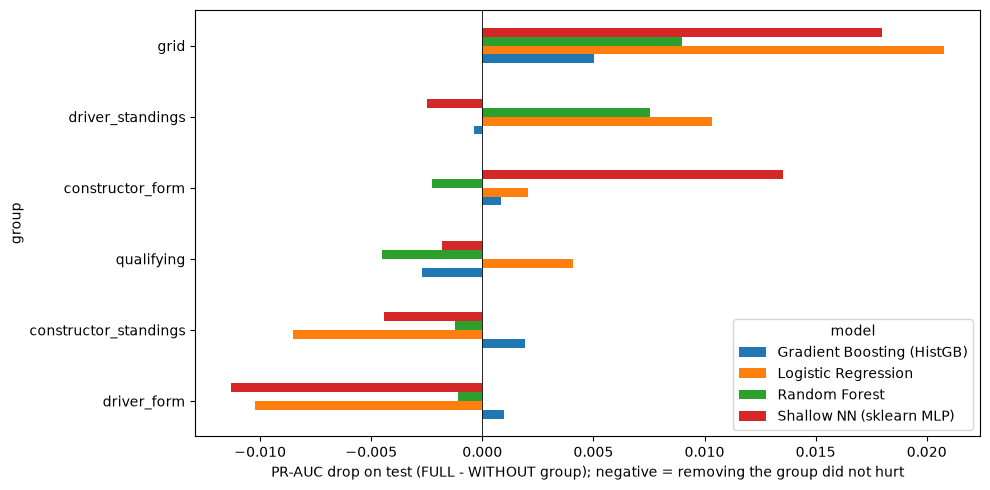

Caveats: (1) with 3-seed averaging, RF/MLP noise is reduced but not removed; (2) groups are correlated (standings vs form vs grid), so the drop of one
group understates its stand-alone value - read the 'group alone' column next to it; (3) removing columns also changes RF max_features sampling; (4) F1 at a re-selected threshold is noisy.


In [227]:
# Step 5 - feature-group ablation: retrain WITHOUT one group at a time, for ALL four models, multi-seed, same splits and thresholds-on-validation rule
V2_ABL_SEEDS = (42, 7, 123)
ABL_KINDS = [k for k in NAMES if k != "TORCH"]      # ablation uses the sklearn models (LR/RF/HGB/MLP); the PyTorch net is reported in the main tables
abl_probs = {}                                       # (model_kind, variant) -> {"Validation": p, "Test": p}
variants = {"FULL": V2_FINAL_GROUPS}
for g in V2_FINAL_GROUPS:
    variants[f"without {g}"] = [x for x in V2_FINAL_GROUPS if x != g]
COMBOS = {"without grid + qualifying (all start-position info)": ["grid", "qualifying"],
          "without driver + constructor standings": ["driver_standings", "constructor_standings"],
          "without driver + constructor form": ["driver_form", "constructor_form"]}
for cname, cg in COMBOS.items():                      # correlated groups hide each other when removed ONE at a time
    variants[cname] = [x for x in V2_FINAL_GROUPS if x not in cg]
for kind in ABL_KINDS:
    for vname, groups in variants.items():
        pv, pt = v2_fit_predict(kind, V2_PARAMS[kind], groups, v2_fit_df, [v2_val, v2_test], seeds=V2_ABL_SEEDS)
        abl_probs[(kind, vname)] = {"Validation": pv, "Test": pt}
    for g in V2_FINAL_GROUPS:                        # add-back view: this group ALONE
        pv, pt = v2_fit_predict(kind, V2_PARAMS[kind], [g], v2_fit_df, [v2_val, v2_test], seeds=V2_ABL_SEEDS)
        abl_probs[(kind, f"only {g}")] = {"Validation": pv, "Test": pt}

rows = []
for (kind, vname), p in abl_probs.items():
    thr = v2_best_threshold(v2_val["podium"].values, p["Validation"])
    for split, f in (("Validation", v2_val), ("Test", v2_test)):
        rows.append({"model": NAMES[kind], "variant": vname, "split": split, **v2_metrics(f["podium"].values, p[split], thr)})
v2_abl = pd.DataFrame(rows)

# Drop per group = FULL minus WITHOUT (positive drop = the group helps). Paired race-level bootstrap on the test seasons.
rng = np.random.default_rng(1)
def paired_drop_ci(kind, vname, split, B=300):
    f = v2_val if split == "Validation" else v2_test
    races = f["raceId"].values; uniq = np.unique(races); idx = {r: np.where(races == r)[0] for r in uniq}
    y = f["podium"].values; a, b = abl_probs[(kind, "FULL")][split], abl_probs[(kind, vname)][split]; d = []
    for _ in range(B):
        pick = np.concatenate([idx[r] for r in rng.choice(uniq, len(uniq))])
        if y[pick].sum() == 0: continue
        d.append(average_precision_score(y[pick], a[pick]) - average_precision_score(y[pick], b[pick]))
    return np.percentile(d, 2.5), np.percentile(d, 97.5)

drop_rows = []
for kind in ABL_KINDS:
    full = v2_abl[(v2_abl.model == NAMES[kind]) & (v2_abl.variant == "FULL")].set_index("split")
    for g in V2_FINAL_GROUPS:
        wo = v2_abl[(v2_abl.model == NAMES[kind]) & (v2_abl.variant == f"without {g}")].set_index("split")
        only = v2_abl[(v2_abl.model == NAMES[kind]) & (v2_abl.variant == f"only {g}")].set_index("split")
        lo, hi = paired_drop_ci(kind, f"without {g}", "Test")
        drop_rows.append({"model": NAMES[kind], "group": g,
                          "PR_AUC_drop_val": full.loc["Validation", "PR_AUC"] - wo.loc["Validation", "PR_AUC"],
                          "PR_AUC_drop_test": full.loc["Test", "PR_AUC"] - wo.loc["Test", "PR_AUC"],
                          "test_drop_CI95_low": lo, "test_drop_CI95_high": hi,
                          "ROC_AUC_drop_test": full.loc["Test", "ROC_AUC"] - wo.loc["Test", "ROC_AUC"],
                          "F1_drop_test(noisy)": full.loc["Test", "F1"] - wo.loc["Test", "F1"],
                          "PR_AUC_group_alone_test": only.loc["Test", "PR_AUC"]})
v2_drops = pd.DataFrame(drop_rows)
display(v2_drops.round(4))

combo_rows = []
for kind in ABL_KINDS:
    full = v2_abl[(v2_abl.model == NAMES[kind]) & (v2_abl.variant == "FULL")].set_index("split")
    for cname in COMBOS:
        wo = v2_abl[(v2_abl.model == NAMES[kind]) & (v2_abl.variant == cname)].set_index("split")
        lo, hi = paired_drop_ci(kind, cname, "Test")
        combo_rows.append({"model": NAMES[kind], "removed together": cname,
                           "PR_AUC_drop_val": full.loc["Validation", "PR_AUC"] - wo.loc["Validation", "PR_AUC"],
                           "PR_AUC_drop_test": full.loc["Test", "PR_AUC"] - wo.loc["Test", "PR_AUC"],
                           "test_drop_CI95_low": lo, "test_drop_CI95_high": hi})
print("Correlated groups removed TOGETHER:")
display(pd.DataFrame(combo_rows).round(4))

wide = v2_drops.pivot(index="group", columns="model", values="PR_AUC_drop_test")
wide["mean_drop_over_models"] = wide.mean(axis=1)
display(wide.sort_values("mean_drop_over_models", ascending=False).round(4).rename_axis("PR-AUC lost on TEST when the group is removed"))
ax = wide.drop(columns="mean_drop_over_models").loc[wide["mean_drop_over_models"].sort_values().index].plot.barh(figsize=(10, 5))
ax.axvline(0, c="k", lw=.6); ax.set_xlabel("PR-AUC drop on test (FULL - WITHOUT group); negative = removing the group did not hurt")
plt.tight_layout(); plt.show()
print("Caveats: (1) with 3-seed averaging, RF/MLP noise is reduced but not removed; (2) groups are correlated (standings vs form vs grid), so the drop of one")
print("group understates its stand-alone value - read the 'group alone' column next to it; (3) removing columns also changes RF max_features sampling; (4) F1 at a re-selected threshold is noisy.")

<a id="h248"></a>
### B.14 Permutation importance and the consolidated results table
<a id="c226"></a>
*Code cell 228* | [Back to contents](#toc)
* Permutation importance (validation PR-AUC) of the headline model - a cross-check of the ablation from a different angle.
* One computed table of ROC-AUC, PR-AUC and F1 for every model and baseline on Train / Validation / Test, and the chosen settings (feature groups, training window, hyper-parameters, headline model).


In [228]:
# Step 5 cross-check + final summary: permutation importance of the headline model (validation) and one consolidated results table
from sklearn.inspection import permutation_importance
kind_h = V2_HEADLINE_KIND if V2_HEADLINE_KIND in ABL_KINDS else max(ABL_KINDS, key=lambda k: v2_best[k]["cv_PR_AUC"])
pre_h = v2_preprocessor(V2_FINAL_GROUPS); cols_h = [c for g in V2_FINAL_GROUPS for c in {**V2_GROUPS, **V2_OPTIONAL}[g]]
Xtr_h = pre_h.fit_transform(v2_fit_df[cols_h]); Xva_h = pre_h.transform(v2_val[cols_h])
mdl_h = v2_model(kind_h, V2_PARAMS[kind_h], V2_SEED).fit(Xtr_h, v2_fit_df["podium"])
perm = permutation_importance(mdl_h, Xva_h, v2_val["podium"], scoring="average_precision", n_repeats=10, random_state=0)
names_out = pre_h.get_feature_names_out()
imp = pd.DataFrame({"feature": names_out, "importance": perm.importances_mean, "std": perm.importances_std}).sort_values("importance", ascending=False)
display(imp.head(15).round(4))

summary = v2_final.pivot_table(index="model", columns="split", values=["ROC_AUC", "PR_AUC", "F1"])
summary = summary.reindex(columns=pd.MultiIndex.from_product([["ROC_AUC", "PR_AUC", "F1"], ["Train", "Validation", "Test"]]))
display(summary.round(4))
print("Final feature groups :", V2_FINAL_GROUPS)
print("Training window      : seasons >=", V2_START, "to", V2_TRAIN_END, "| validation", V2_VAL_YEARS, "| test", V2_TEST_YEARS)
print("Hyper-parameters     :", V2_PARAMS)
print("Headline model       :", V2_HEADLINE, "| permutation importance shown for:", NAMES[kind_h])

,feature,importance,std
4,num__quali_pos_filled,0.0526,0.0247
1,num__grid_pct_field,0.0407,0.0161
0,num__grid_filled,0.0241,0.0141
9,num__drv_wins_before,0.0206,0.0035
17,num__con_avg_finish_form,0.0145,0.0087
7,num__drv_points_pct_leader,0.0112,0.0099
11,num__con_rank_before,0.0054,0.0081
8,num__drv_rank_before,0.0050,0.0037
10,num__con_points_pct_leader,0.0027,0.0036
13,num__drv_podium_rate_form,0.0020,0.0057


ROC_AUC                     PR_AUC                         F1                   
                                      Train Validation    Test   Train Validation    Test   Train Validation    Test
model                                                                                                               
Baseline: constructor form only      0.8746     0.8549  0.8767  0.5103     0.5077  0.4804  0.5667     0.6380  0.5632
Baseline: grid slot (rank by -grid)  0.9085     0.9094  0.9137  0.6258     0.6386  0.6473  0.6462     0.6923  0.6486
Baseline: prior (constant)           0.5000     0.5000  0.5000  0.1411     0.1500  0.1503  0.2473     0.2609  0.2614
Gradient Boosting (HistGB)           0.9498     0.9308  0.9359  0.7597     0.7237  0.7171  0.7017     0.7016  0.6564
Logistic Regression                  0.9312     0.9269  0.9369  0.6900     0.7301  0.7173  0.6692     0.6992  0.6637
Random Forest                        0.9645     0.9294  0.9374  0.8126     0.7064  0.7108  0.7329     0.7059  0.6667
Shallow NN (PyTorch)                 0.9376     0.9300  0.9377  0.7053     0.7393  0.7142  0.6784     0.7049  0.6667
Shallow NN (sklearn MLP)             0.9446     0.9266  0.9320  0.7440     0.7174  0.7063  0.6868     0.7045  0.6680

Final feature groups : ['grid', 'qualifying', 'driver_standings', 'constructor_standings', 'driver_form', 'constructor_form']
Training window      : seasons >= 2003 to 2019 | validation (2020, 2021) | test (2022, 2100)
Hyper-parameters     : {'LR': {'C': 1.0}, 'RF': {'min_samples_leaf': 10, 'max_features': 'sqrt'}, 'HGB': {'learning_rate': 0.03, 'max_depth': 4, 'l2_regularization': 1.0}, 'MLP': {'hidden_layer_sizes': (32,), 'alpha': 0.001}, 'TORCH': {'hidden': (32,), 'weight_decay': 0.001}}
Headline model       : Gradient Boosting (HistGB) | permutation importance shown for: Gradient Boosting (HistGB)


<a id="h249"></a>
### B.15 Effect of preprocessing on the data (checklist: "effect of the step on distribution / range / values")
<a id="c227"></a>
*Code cell 229* | [Back to contents](#toc)
Table of the numeric features **before** (raw min / max / mean / std, % missing) and **after** (median imputation + standardisation, fitted on train only), plus histograms before/after for four features. Reading: imputation fills gaps with the train median (a spike at the centre), scaling changes units but not shape, and the missing-indicator columns keep the information that a value was absent.


,min_raw,max_raw,mean_raw,std_raw,missing_pct,min_processed,max_processed,mean_processed,std_processed
grid_filled,1.00,24.0,11.19,6.24,0.00,-1.63,2.05,-0.0,1.0
grid_pct_field,0.04,1.0,0.52,0.29,0.00,-1.67,1.65,-0.0,1.0
grid_missing,0.00,1.0,0.00,0.06,0.00,-0.06,17.58,0.0,1.0
front_row,0.00,1.0,0.09,0.29,0.00,-0.32,3.11,-0.0,1.0
quali_pos_filled,1.00,24.0,11.19,6.23,0.03,-1.64,2.06,0.0,1.0
qualifying_missing,0.00,1.0,0.00,0.06,0.00,-0.06,17.58,0.0,1.0
grid_penalty,0.00,23.0,0.27,1.38,0.00,-0.20,16.51,0.0,1.0
drv_points_pct_leader,0.00,1.0,0.24,0.30,1.16,-0.80,2.55,-0.0,1.0
drv_rank_before,1.00,25.0,10.11,5.86,1.16,-1.56,2.56,0.0,1.0
drv_wins_before,0.00,13.0,0.43,1.31,1.16,-0.32,9.62,-0.0,1.0


Processed matrix: (6824, 29) | NaN left: 0 | missing-indicator columns added: ['num__missingindicator_quali_pos_filled', 'num__missingindicator_drv_points_pct_leader', 'num__missingindicator_drv_rank_before', 'num__missingindicator_drv_wins_before', 'num__missingindicator_con_points_pct_leader', 'num__missingindicator_con_rank_before', 'num__missingindicator_con_wins_before', 'num__missingindicator_drv_podium_rate_form', 'num__missingindicator_drv_avg_finish_form', 'num__missingindicator_con_podium_rate_form', 'num__missingindicator_con_avg_finish_form']


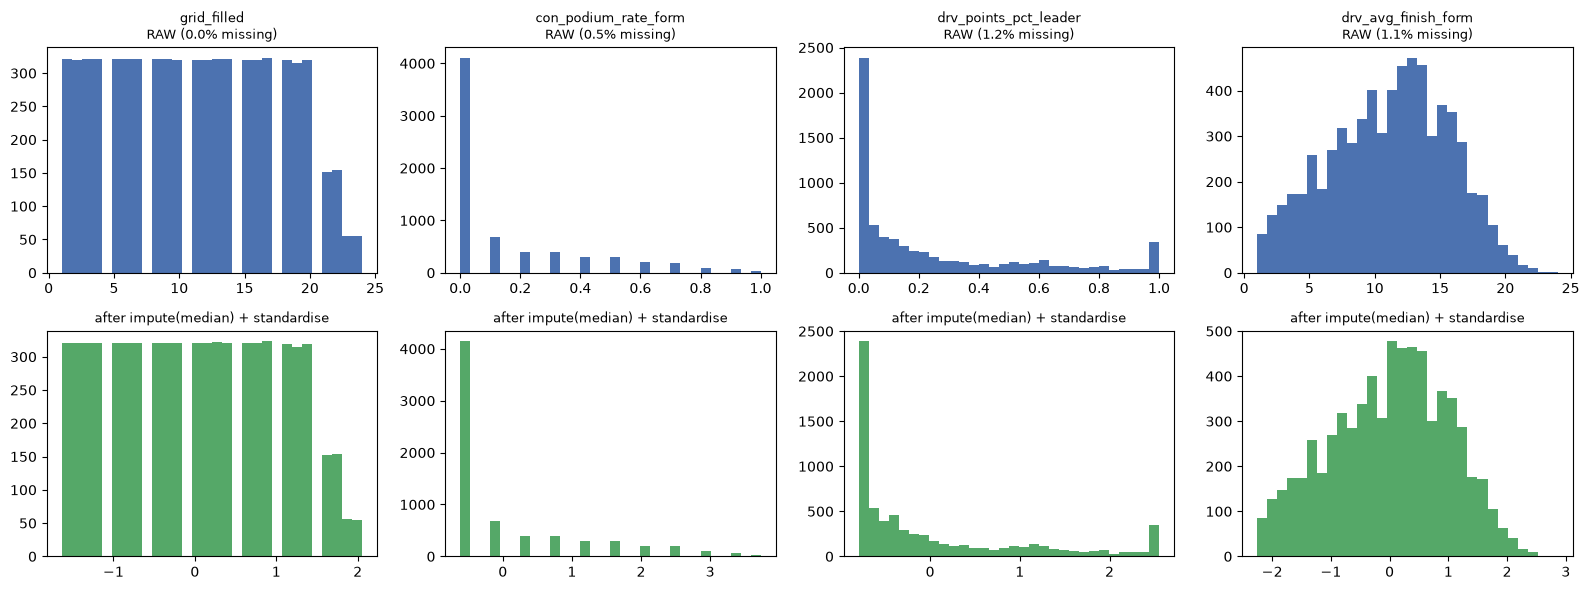

Imputation fills gaps with the train median (spike at the centre); scaling changes units only, not the shape. Missing-ness itself is preserved by the indicator columns.


In [229]:
# Checklist: effect of the preprocessing on the data (ranges, missing values, distributions) - TRAIN rows, fitted on train only
cols_num, _ = v2_split_cols(V2_FINAL_GROUPS)
pre_demo = v2_preprocessor(V2_FINAL_GROUPS).fit(v2_fit_df[v2_split_cols(V2_FINAL_GROUPS)[0] + v2_split_cols(V2_FINAL_GROUPS)[1]])
Z = pre_demo.transform(v2_fit_df[v2_split_cols(V2_FINAL_GROUPS)[0] + v2_split_cols(V2_FINAL_GROUPS)[1]])   # the transformer was fitted on numeric + categorical columns, so it must receive both
names = list(pre_demo.get_feature_names_out())
Zdf = pd.DataFrame(Z, columns=names)
before = v2_fit_df[cols_num].astype(float).describe().T[["min", "max", "mean", "std"]].assign(missing_pct=100 * v2_fit_df[cols_num].isna().mean())
after = Zdf[[f"num__{c}" for c in cols_num]].describe().T[["min", "max", "mean", "std"]]
after.index = cols_num
display(before.join(after, lsuffix="_raw", rsuffix="_processed").round(2))
print("Processed matrix:", Z.shape, "| NaN left:", int(np.isnan(Z).sum()), "| missing-indicator columns added:", [n for n in names if "missingindicator" in n])

show = [c for c in ["grid_filled", "con_podium_rate_form", "drv_points_pct_leader", "drv_avg_finish_form"] if c in cols_num]
fig, ax = plt.subplots(2, len(show), figsize=(4 * len(show), 6))
for j, c in enumerate(show):
    ax[0, j].hist(v2_fit_df[c].dropna(), bins=30, color="#4C72B0"); ax[0, j].set_title(f"{c}\nRAW ({100 * v2_fit_df[c].isna().mean():.1f}% missing)", fontsize=9)
    ax[1, j].hist(Zdf[f"num__{c}"], bins=30, color="#55A868"); ax[1, j].set_title("after impute(median) + standardise", fontsize=9)
plt.tight_layout(); plt.show()
print("Imputation fills gaps with the train median (spike at the centre); scaling changes units only, not the shape. Missing-ness itself is preserved by the indicator columns.")

<a id="h250"></a>
### B.16 Preprocessing-order and preprocessing-choice experiments (deliverable 5: at least two)
<a id="c228"></a>
*Code cell 230* | [Back to contents](#toc)
Each row is one variant of the full pipeline, scored with the same rolling-origin folds as all other selection, for LR and RF, with the delta against the reference (E0):
* **E1** imputation strategy (median / mean / constant) and with vs without missing-indicators,
* **E2order**: impute->scale (reference) vs scale->impute, and no scaling,
* **E3** qualifying with the grid fallback (reference) vs raw position median-imputed,
* **E4** where the preprocessing is **fitted**: train only (correct) vs train + validation (leaky).

Deltas within about ±0.005 PR-AUC are noise; the table is the before/after evidence the checklist asks for, with each attempt in its own row.


In [230]:
# Checklist: preprocessing-order / preprocessing-choice EXPERIMENTS (each variant = one row; chosen pipeline is the reference)
# Metric: mean PR-AUC over the same rolling-origin folds used for all selection (no test data).
def pre_fn_factory(strategy="median", add_indicator=True, order="impute_then_scale", scale=True, fill_value=None):
    def make(groups):
        num, cat = v2_split_cols(groups)
        imp = SimpleImputer(strategy=strategy, add_indicator=add_indicator, **({"fill_value": fill_value} if fill_value is not None else {}))
        steps = ([("imp", imp), ("sc", StandardScaler())] if order == "impute_then_scale" else [("sc", StandardScaler()), ("imp", imp)])
        if not scale: steps = [("imp", imp)]
        parts = [("num", Pipeline(steps), num)] if num else []
        if cat: parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), cat))
        return ColumnTransformer(parts)
    return make

exp_models = [("LR", V2_PARAMS["LR"]), ("RF", V2_PARAMS["RF"])]
experiments = {
    "E0 reference: median impute + indicator, impute -> scale": dict(pre_fn=pre_fn_factory()),
    "E1a imputation: median, NO missing-indicator":             dict(pre_fn=pre_fn_factory(add_indicator=False)),
    "E1b imputation: mean + indicator":                         dict(pre_fn=pre_fn_factory(strategy="mean")),
    "E1c imputation: constant 0 + indicator":                   dict(pre_fn=pre_fn_factory(strategy="constant", fill_value=0)),
    "E2a ORDER: scale -> impute (reverse of reference)":        dict(pre_fn=pre_fn_factory(order="scale_then_impute")),
    "E2b no scaling at all":                                    dict(pre_fn=pre_fn_factory(scale=False)),
}
_raw_q = v2_df.assign(quali_pos_filled=v2_df["qualifying_position"])                   # keep NaN where the era has no qualifying data
experiments["E3 qualifying: NO grid-fallback (raw position, median-imputed)"] = dict(pre_fn=pre_fn_factory(), frame=_raw_q)

rows = []
for name, kw in experiments.items():
    r = {"experiment": name}
    for kind, prm in exp_models:
        r[kind], _ = v2_cv(kind, prm, V2_FINAL_GROUPS, start=V2_START, **kw)
    rows.append(r)
v2_order = pd.DataFrame(rows).set_index("experiment")
for k in ("LR", "RF"): v2_order[f"{k}_delta_vs_E0"] = v2_order[k] - v2_order.loc[v2_order.index[0], k]
display(v2_order.round(4))

# E4: where is the preprocessing FITTED?  train-only (correct) vs train+validation features (statistics leak from the validation rows)
e4 = []
for tr_end, (v0, v1) in V2_FOLDS:
    tr = v2_dev[(v2_dev["year"] >= V2_START) & (v2_dev["year"] <= tr_end)]; va = v2_dev[v2_dev["year"].between(v0, v1)]
    cols = [c for g in V2_FINAL_GROUPS for c in {**V2_GROUPS, **V2_OPTIONAL}[g]]
    for label, fit_rows in (("fit on TRAIN only (correct)", tr), ("fit on TRAIN+VALIDATION features (leaky)", pd.concat([tr, va]))):
        pre = v2_preprocessor(V2_FINAL_GROUPS).fit(fit_rows[cols]); m = v2_model("LR", V2_PARAMS["LR"]).fit(pre.transform(tr[cols]), tr["podium"])
        e4.append({"variant": label, "PR_AUC": average_precision_score(va["podium"], m.predict_proba(pre.transform(va[cols]))[:, 1])})
display(pd.DataFrame(e4).groupby("variant")["PR_AUC"].mean().round(4).to_frame("mean PR-AUC (LR, rolling folds)"))
print("Reading: rows with a delta inside about +-0.005 are noise; E1a/E3 show whether the missing-indicator and the grid fallback are worth their complexity; E2 shows that the imputation/scaling ORDER is immaterial here;")
print("E4 shows how little the leak changes the score - the protocol (fit on train only) is kept because it is correct, not because the score moves.")

,LR,RF,LR_delta_vs_E0,RF_delta_vs_E0
experiment,,,,
"E0 reference: median impute + indicator, impute -> scale",0.7151,0.7325,0.0000,0.0000
"E1a imputation: median, NO missing-indicator",0.7127,0.7380,-0.0024,0.0055
E1b imputation: mean + indicator,0.7149,0.7370,-0.0002,0.0045
E1c imputation: constant 0 + indicator,0.7148,0.7362,-0.0004,0.0037
E2a ORDER: scale -> impute (reverse of reference),0.7144,0.7325,-0.0007,-0.0001
E2b no scaling at all,0.7143,0.7324,-0.0008,-0.0001
"E3 qualifying: NO grid-fallback (raw position, median-imputed)",0.7147,0.7333,-0.0004,0.0008


,"mean PR-AUC (LR, rolling folds)"
variant,
fit on TRAIN only (correct),0.7151
fit on TRAIN+VALIDATION features (leaky),0.7146


Reading: rows with a delta inside about +-0.005 are noise; E1a/E3 show whether the missing-indicator and the grid fallback are worth their complexity; E2 shows that the imputation/scaling ORDER is immaterial here;
E4 shows how little the leak changes the score - the protocol (fit on train only) is kept because it is correct, not because the score moves.


<a id="h251"></a>
### B.17 Deliverable 4 - comparison table with all five metrics, metric choice, confusion matrices, attempt log
<a id="c229"></a>
*Code cell 231* | [Back to contents](#toc)
* ROC-AUC, PR-AUC, F1, precision and recall for **every model and baseline** on validation and on the unseen test seasons.
* **Primary metric = PR-AUC**, **secondary = ROC-AUC and F1** (with precision/recall to see which side moves F1) - the reasoning (≈15 % positives, the grid-only baseline already reaching a high ROC-AUC) is printed under the table.
* Confusion matrices on the test seasons at each model's validation threshold (the "plotting the reports" item).
* Attempt log: every modelling attempt with the number of configurations searched, best CV score, test PR-AUC and the gain over (a) the no-learning baseline and (b) the **statistical baseline = logistic regression**.


split                                 Test                                 Validation                                
                                        F1 PR_AUC ROC_AUC precision recall         F1 PR_AUC ROC_AUC precision recall
model                                                                                                                
Baseline: constructor form only      0.563  0.480   0.877     0.446  0.765      0.638  0.508   0.855     0.549  0.761
Baseline: grid slot (rank by -grid)  0.649  0.647   0.914     0.650  0.647      0.692  0.639   0.909     0.692  0.692
Baseline: prior (constant)           0.261  0.150   0.500     0.150  1.000      0.261  0.150   0.500     0.150  1.000
Gradient Boosting (HistGB)           0.656  0.717   0.936     0.596  0.730      0.702  0.724   0.931     0.664  0.744
Logistic Regression                  0.664  0.717   0.937     0.612  0.725      0.699  0.730   0.927     0.667  0.735
Random Forest                        0.667  0.711   0.937     0.628  0.711      0.706  0.706   0.929     0.694  0.718
Shallow NN (PyTorch)                 0.667  0.714   0.938     0.617  0.725      0.705  0.739   0.930     0.677  0.735
Shallow NN (sklearn MLP)             0.668  0.706   0.932     0.574  0.799      0.705  0.717   0.927     0.633  0.795

Podium prevalence: {'Train': np.float64(0.141), 'Validation': np.float64(0.15), 'Test': np.float64(0.15)}
PRIMARY metric   = PR-AUC : only about 15% of rows are podiums (a random ranker scores PR-AUC ~ prevalence = 0.15, ROC-AUC 0.50);
                   PR-AUC is threshold-free and reacts to how well podium finishers are ranked above the rest, which is the actual task.
SECONDARY metrics: ROC-AUC (overall separation, but inflated by the many easy negatives: even the grid-only baseline reaches 0.91),
                   F1 at the validation-chosen threshold (what a user acting on a yes/no prediction experiences); precision and recall show which side of F1 moves.


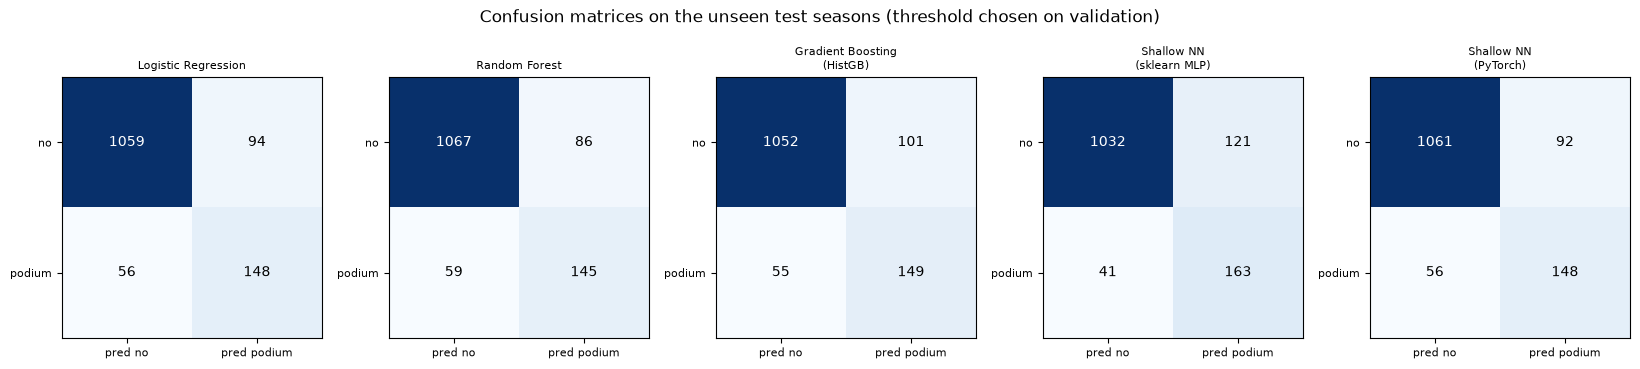

,attempt,test_PR_AUC,gain_vs_grid_baseline,gain_vs_statistical_baseline(LR)
0,Reference baseline: grid slot only (no learning),0.6473,0.0000,-0.0700
1,"Logistic Regression (4 configs searched, best...",0.7173,0.0700,0.0000
2,"Random Forest (6 configs searched, best CV PR...",0.7108,0.0635,-0.0065
3,Gradient Boosting (HistGB) (4 configs searche...,0.7171,0.0698,-0.0002
4,"Shallow NN (sklearn MLP) (6 configs searched,...",0.7063,0.0590,-0.0110
5,"Shallow NN (PyTorch) (6 configs searched, bes...",0.7142,0.0669,-0.0031


Statistical baseline for the report = Logistic Regression (simplest learned model); the shallow NNs and tree ensembles must earn their complexity relative to it.


In [231]:
# Deliverable 4: model comparison table - ALL five metrics (ROC-AUC, PR-AUC, F1, precision, recall) on validation AND test, primary/secondary metric justified
cmp_rows = []
for m, p in v2_prob.items():
    for s in ("Validation", "Test"):
        cmp_rows.append({"model": m, "split": s, "threshold(val)": v2_thr[m], **v2_metrics(v2_frames[s]["podium"].values, p[s], v2_thr[m])})
v2_all5 = pd.DataFrame(cmp_rows)
order_cols = ["ROC_AUC", "PR_AUC", "F1", "precision", "recall"]
display(v2_all5.pivot(index="model", columns="split", values=order_cols).reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0).round(3))

prev = {s: v2_frames[s]["podium"].mean() for s in ("Train", "Validation", "Test")}
print("Podium prevalence:", {k: round(v, 3) for k, v in prev.items()})
print(f"PRIMARY metric   = PR-AUC : only about {100 * prev['Test']:.0f}% of rows are podiums (a random ranker scores PR-AUC ~ prevalence = {prev['Test']:.2f}, ROC-AUC 0.50);")
print("                   PR-AUC is threshold-free and reacts to how well podium finishers are ranked above the rest, which is the actual task.")
print(f"SECONDARY metrics: ROC-AUC (overall separation, but inflated by the many easy negatives: even the grid-only baseline reaches {v2_all5[(v2_all5.model == base) & (v2_all5.split == 'Test')]['ROC_AUC'].iloc[0]:.2f}),")
print("                   F1 at the validation-chosen threshold (what a user acting on a yes/no prediction experiences); precision and recall show which side of F1 moves.")

# Plot the reports: confusion matrices on TEST at each model's validation threshold
learned_models = [m for m in v2_prob if not m.startswith("Baseline")]
fig, ax = plt.subplots(1, len(learned_models), figsize=(3.3 * len(learned_models), 3.4))
for a, m in zip(np.atleast_1d(ax), learned_models):
    pred = (v2_prob[m]["Test"] >= v2_thr[m]).astype(int); y = v2_test["podium"].values
    cm = np.array([[((y == i) & (pred == j)).sum() for j in (0, 1)] for i in (0, 1)])
    a.imshow(cm, cmap="Blues"); a.set_xticks([0, 1]); a.set_xticklabels(["pred no", "pred podium"], fontsize=8); a.set_yticks([0, 1]); a.set_yticklabels(["no", "podium"], fontsize=8)
    for i in (0, 1):
        for j in (0, 1): a.text(j, i, cm[i, j], ha="center", va="center", color="black" if cm[i, j] < cm.max() / 2 else "white")
    a.set_title(m.replace(" (", "\n("), fontsize=8)
plt.suptitle("Confusion matrices on the unseen test seasons (threshold chosen on validation)", y=1.02); plt.tight_layout(); plt.show()

# Attempt log (the checklist asks for >= 3 distinct modelling attempts, each compared with a baseline)
base_stat = "Logistic Regression"
attempts = [{"attempt": "Reference baseline: grid slot only (no learning)", "test_PR_AUC": v2_all5[(v2_all5.model == base) & (v2_all5.split == "Test")].PR_AUC.iloc[0]}]
for kind, name in NAMES.items():
    n_cfg = len(GRIDS[kind]); best_cv = v2_best[kind]["cv_PR_AUC"]
    attempts.append({"attempt": f"{name}  ({n_cfg} configs searched, best CV PR-AUC {best_cv:.3f})", "test_PR_AUC": v2_all5[(v2_all5.model == name) & (v2_all5.split == "Test")].PR_AUC.iloc[0]})
att = pd.DataFrame(attempts); att["gain_vs_grid_baseline"] = att["test_PR_AUC"] - att["test_PR_AUC"].iloc[0]
att["gain_vs_statistical_baseline(LR)"] = att["test_PR_AUC"] - att.loc[att.attempt.str.startswith(base_stat), "test_PR_AUC"].iloc[0]
display(att.round(4))
print("Statistical baseline for the report = Logistic Regression (simplest learned model); the shallow NNs and tree ensembles must earn their complexity relative to it.")

<a id="h252"></a>
# Part 6 — Model explainability (XAI, brief objective 6)

Goal: show **what the model relies on**, globally and for single predictions.

* **Global:** permutation importance (per feature and per feature group) and SHAP (summary, bar, dependence).
* **Local:** SHAP waterfall and LIME for two rows - a correctly predicted podium and a missed podium.
* **Agreement check** between methods.

> **Important - explanations are not causal effects.** A feature being important to the model only means the model uses it to predict. A good grid slot and a podium both follow from a fast car; the model cannot tell us that moving a driver up the grid *causes* a podium. Correlated features also share credit, and every explanation holds for this model on these seasons only. This statement is repeated in the output of the last XAI cell so it appears in the report.

<a id="h253"></a>
### 6.1 XAI setup
<a id="c230"></a>
*Code cell 232* | [Back to contents](#toc)
Installs `shap` / `lime` only if missing, fits the preprocessing and the **headline model** on the training seasons and explains it on the **unseen test seasons** (explanations are descriptive; nothing is selected with them). The model is also the one used by the inference function.


In [232]:
# Step 6 - XAI setup. ONE frozen final predictor (preprocessing fitted on TRAIN + the same seeds as the headline model + the validation-chosen threshold)
# is built here and used for the comparison check, every explanation and the inference function, so all three describe exactly the same model.
import sys, subprocess, importlib
for pkg in ("shap", "lime"):
    try: importlib.import_module(pkg)
    except ImportError:
        print("installing", pkg); subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
import shap
from lime.lime_tabular import LimeTabularExplainer

xai_num, xai_cat = v2_split_cols(V2_FINAL_GROUPS)
xai_cols = xai_num + xai_cat

class V2Final:
    """Frozen predictor: raw feature DataFrame -> podium probability. Seed-averaged exactly like the headline numbers in the comparison table."""
    def __init__(self, kind, params, groups, train, seeds):
        self.kind, self.num, self.cat = kind, *v2_split_cols(groups)
        self.pre = v2_preprocessor(groups).fit(train[self.num + self.cat])
        Xtr = self.pre.transform(train[self.num + self.cat])
        use = seeds if V2_STOCHASTIC[kind] else seeds[:1]
        self.models = [v2_model(kind, params, s).fit(Xtr, train["podium"]) for s in use]
        self.names = [n.replace("num__", "").replace("cat__", "") for n in self.pre.get_feature_names_out()]
    def transform(self, df): return self.pre.transform(df[self.num + self.cat])
    def proba_matrix(self, X): return np.mean([m.predict_proba(X)[:, 1] for m in self.models], axis=0)      # X = already preprocessed
    def predict_proba_df(self, df): return self.proba_matrix(self.transform(df))

FINAL = V2Final(V2_HEADLINE_KIND, V2_PARAMS[V2_HEADLINE_KIND], V2_FINAL_GROUPS, v2_fit_df, V2_SEEDS)
FINAL_THRESHOLD = v2_thr[V2_HEADLINE]                         # the SAME threshold the comparison table uses (chosen on validation only)
xai_names = FINAL.names
X_tr_x = FINAL.transform(v2_fit_df); X_te_x = FINAL.transform(v2_test)
f_proba = FINAL.proba_matrix; xai_thr = FINAL_THRESHOLD

# Consistency check: the frozen predictor must reproduce the headline model's test probabilities from the comparison table.
_chk = np.abs(FINAL.predict_proba_df(v2_test) - v2_prob[V2_HEADLINE]["Test"]).max()
print(f"Frozen predictor vs comparison-table probabilities on test: max abs difference = {_chk:.2e}")
if _chk > 1e-6: print("  (non-zero only for models trained with non-deterministic back-ends such as PyTorch; the rank ordering is unchanged to this precision)")

def base_of(feature_name):
    """Map an encoded column name back to the original feature it came from (numeric, missing-indicator, or one-hot category)."""
    n = feature_name
    if n.startswith("missingindicator_"): return n[len("missingindicator_"):]
    if n in xai_num: return n
    hits = [c for c in xai_cat if n.startswith(c + "_")]
    return max(hits, key=len) if hits else n
xai_base = [base_of(n) for n in xai_names]
print("Explained model:", V2_HEADLINE, f"({len(FINAL.models)} seed(s) averaged)", "| encoded columns:", len(xai_names), "| test rows:", len(X_te_x))
print("Test PR-AUC of this model:", round(average_precision_score(v2_test["podium"], f_proba(X_te_x)), 4))
print("IMPORTANT: every explanation below describes what the MODEL relies on. It is NOT evidence that a feature causes podium finishes.")

/tmp/claude-0/-home-claude/843a1b7a-0cf2-56f8-817e-22b27ec3a217/scratchpad/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Frozen predictor vs comparison-table probabilities on test: max abs difference = 0.00e+00
Explained model: Gradient Boosting (HistGB) (1 seed(s) averaged) | encoded columns: 29 | test rows: 1357
Test PR-AUC of this model: 0.7171
IMPORTANT: every explanation below describes what the MODEL relies on. It is NOT evidence that a feature causes podium finishes.


<a id="h254"></a>
### 6.2 Global explanation 1 - permutation importance
<a id="c231"></a>
*Code cell 233* | [Back to contents](#toc)
Shuffle one feature (15 repeats) and measure the drop in test PR-AUC; then shuffle a whole **group** together. The group version links directly to the ablation (Step 5) without retraining. Because correlated features share credit, single-feature values understate each feature - use the group table to read the real size of each block.


,feature,importance,std
4,quali_pos_filled,0.0600,0.0019
1,grid_pct_field,0.0477,0.0156
0,grid_filled,0.0321,0.0078
17,con_avg_finish_form,0.0121,0.0041
13,drv_podium_rate_form,0.0084,0.0032
8,drv_rank_before,0.0060,0.0019
7,drv_points_pct_leader,0.0049,0.0042
11,con_rank_before,0.0047,0.0034
9,drv_wins_before,0.0047,0.0041
12,con_wins_before,0.0029,0.0036


,group,n_columns,PR_AUC_drop,std
0,grid,4,0.1613,0.0194
1,qualifying,4,0.0614,0.0155
3,constructor_standings,6,0.0191,0.0103
2,driver_standings,6,0.0152,0.0075
5,constructor_form,4,0.0132,0.0093
4,driver_form,5,0.0114,0.0049


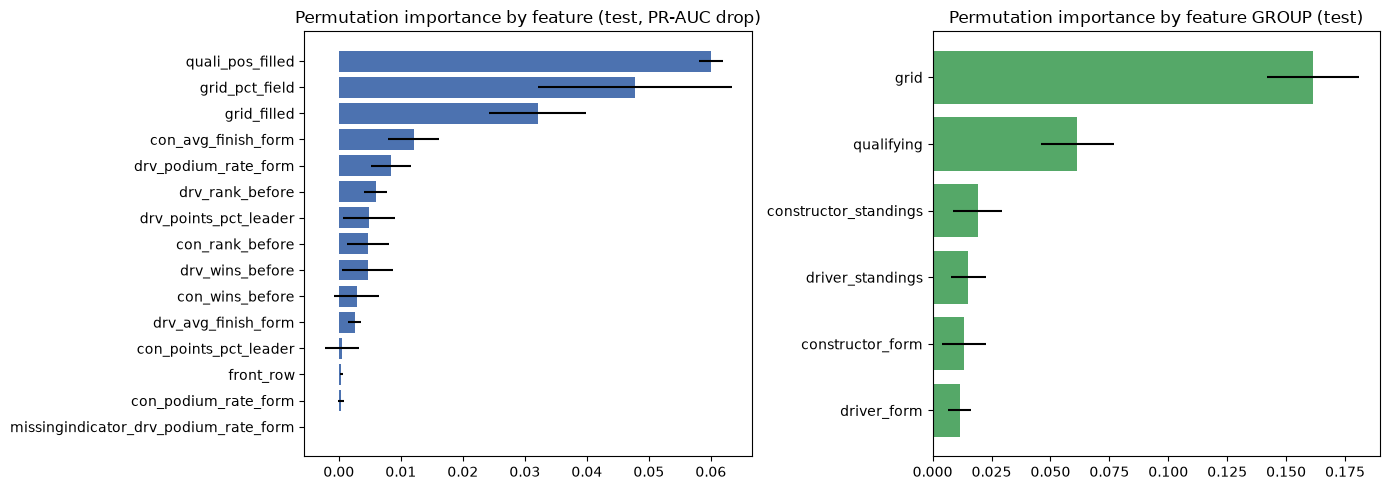

Reading: the start-position features dominate; correlated features share credit (shuffling one still leaves its twin), so single-feature importances understate each of them.


In [233]:
# Step 6 - GLOBAL explanation 1: permutation importance (drop in PR-AUC when one column - or one whole feature GROUP - is shuffled), on the TEST seasons
# Implemented directly on the frozen predictor (works for every model type, including the seed-averaged and PyTorch ones).
y_te_all = v2_test["podium"].values
base_ap = average_precision_score(y_te_all, f_proba(X_te_x)); rng_p = np.random.default_rng(0)

def perm_drop(cols, n_rep=15):
    drops = []
    for _ in range(n_rep):
        Xp = X_te_x.copy(); Xp[:, cols] = Xp[rng_p.permutation(len(Xp))][:, cols]       # shuffle the columns TOGETHER (rows stay consistent)
        drops.append(base_ap - average_precision_score(y_te_all, f_proba(Xp)))
    return np.mean(drops), np.std(drops)

perm_df = pd.DataFrame([{"feature": n, "importance": perm_drop([i])[0], "std": perm_drop([i], 5)[1]} for i, n in enumerate(xai_names)]).sort_values("importance", ascending=False)
display(perm_df.head(15).round(4))

# Group-level permutation: shuffle ALL encoded columns of a group together (numeric + missing-indicator + one-hot columns)
grp_rows = []
for g in V2_FINAL_GROUPS:
    members = set({**V2_GROUPS, **V2_OPTIONAL}[g])
    gcols = [i for i, b in enumerate(xai_base) if b in members]
    assert gcols, f"group {g!r} matched no encoded column - name matching is broken"
    m_, s_ = perm_drop(gcols); grp_rows.append({"group": g, "n_columns": len(gcols), "PR_AUC_drop": m_, "std": s_})
grp_df = pd.DataFrame(grp_rows).sort_values("PR_AUC_drop", ascending=False)
display(grp_df.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top = perm_df.head(15).iloc[::-1]; ax[0].barh(top["feature"], top["importance"], xerr=top["std"], color="#4C72B0"); ax[0].set_title("Permutation importance by feature (test, PR-AUC drop)")
g_ = grp_df.iloc[::-1]; ax[1].barh(g_["group"], g_["PR_AUC_drop"], xerr=g_["std"], color="#55A868"); ax[1].set_title("Permutation importance by feature GROUP (test)")
plt.tight_layout(); plt.show()
print("Reading: the start-position features dominate; correlated features share credit (shuffling one still leaves its twin), so single-feature importances understate each of them.")

<a id="h255"></a>
### 6.3 Global explanation 2 - SHAP
<a id="c232"></a>
*Code cell 234* | [Back to contents](#toc)
SHAP values split each prediction into additive feature contributions (in probability units for tree models). Uses the exact tree algorithm for random forests and the model-agnostic permutation algorithm for the other models. Plots: beeswarm (direction and spread of each feature's effect), mean |SHAP| bars, and a dependence plot of the top feature. In the beeswarm, red dots are high feature values; for rank-type features (grid slot) *low* values push toward a podium.


PermutationExplainer explainer:  94%|█████████▎| 374/400 [00:00<?, ?it/s]

PermutationExplainer explainer:  95%|█████████▌| 380/400 [00:10<00:00, 52.50it/s]

PermutationExplainer explainer:  96%|█████████▋| 386/400 [00:10<00:00, 44.96it/s]

PermutationExplainer explainer:  98%|█████████▊| 391/400 [00:10<00:00, 43.53it/s]

PermutationExplainer explainer:  99%|█████████▉| 396/400 [00:10<00:00, 41.90it/s]

PermutationExplainer explainer: 401it [00:10, 41.81it/s]                         

PermutationExplainer explainer: 401it [00:10,  2.54it/s]

SHAP matrix: (400, 29) | mean prediction (base value): 0.129
Additivity check (sum of SHAP + base value vs model probability): mean abs error 0.0000, max 0.0000  -> OK


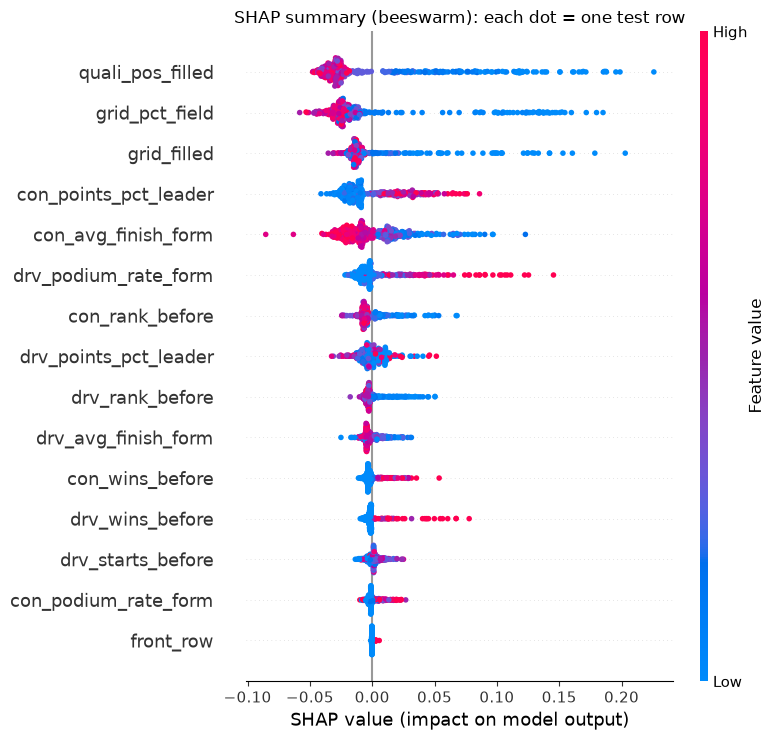

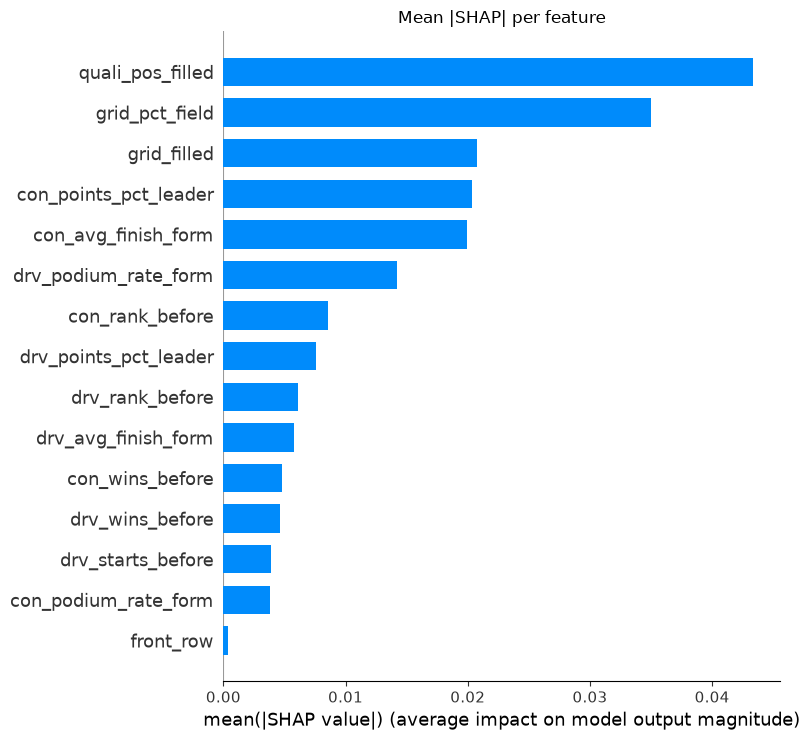

<Figure size 600x400 with 0 Axes>

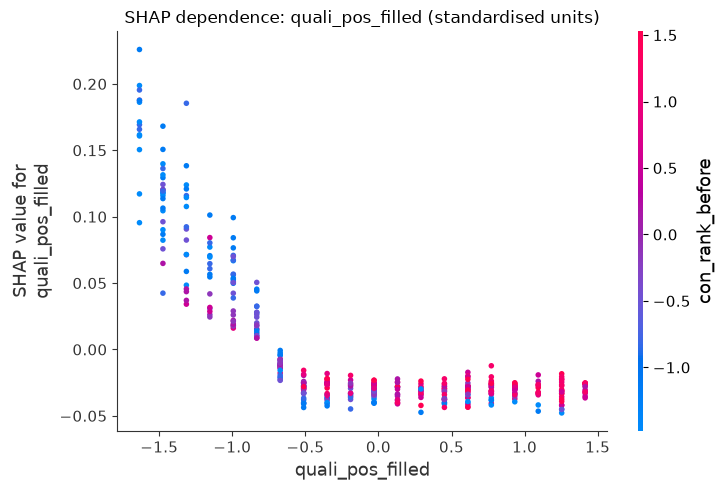

,mean |SHAP|
quali_pos_filled,0.0434
grid_pct_field,0.0350
grid_filled,0.0208
con_points_pct_leader,0.0203
con_avg_finish_form,0.0200
drv_podium_rate_form,0.0142
con_rank_before,0.0085
drv_points_pct_leader,0.0076
drv_rank_before,0.0061
drv_avg_finish_form,0.0058


In [234]:
# Step 6 - GLOBAL explanation 2: SHAP values (contribution of each feature to each prediction, in probability units), computed on a sample of the TEST seasons
rng_s = np.random.default_rng(0)
bg = X_tr_x[rng_s.choice(len(X_tr_x), 100, replace=False)]                          # background distribution = training rows
idx_s = rng_s.choice(len(X_te_x), min(400, len(X_te_x)), replace=False)
X_s = X_te_x[idx_s]

def shap_fn(X):
    """SHAP values of the FROZEN predictor. Random forest: exact TreeSHAP per seed, averaged (the predictor is the seed average). Others: model-agnostic permutation SHAP."""
    if V2_HEADLINE_KIND == "RF":
        vs, bs = [], []
        for m in FINAL.models:
            e = shap.TreeExplainer(m, bg, model_output="probability")
            v = e.shap_values(X, check_additivity=False); v = v[1] if isinstance(v, list) else (v[..., 1] if np.ndim(v) == 3 else v)
            vs.append(np.asarray(v)); bs.append(float(np.ravel(e.expected_value)[-1]))
        return np.mean(vs, axis=0), float(np.mean(bs))
    e = shap.Explainer(f_proba, bg, algorithm="permutation", feature_names=xai_names)
    o = e(X, max_evals=2 * len(xai_names) + 1)
    return np.asarray(o.values), float(np.mean(o.base_values))

sv, base_value = shap_fn(X_s)
print("SHAP matrix:", sv.shape, "| mean prediction (base value): %.3f" % base_value)
# Explanation-quality check: SHAP values must add up to the model's own prediction (local accuracy)
add_err = np.abs(sv.sum(1) + base_value - f_proba(X_s))
print(f"Additivity check (sum of SHAP + base value vs model probability): mean abs error {add_err.mean():.4f}, max {add_err.max():.4f}  ->",
      "OK" if add_err.mean() < 0.02 else "LARGE: interpret the SHAP plots with caution")

plt.figure(); shap.summary_plot(sv, X_s, feature_names=xai_names, show=False, max_display=15); plt.title("SHAP summary (beeswarm): each dot = one test row"); plt.tight_layout(); plt.show()
plt.figure(); shap.summary_plot(sv, X_s, feature_names=xai_names, plot_type="bar", show=False, max_display=15); plt.title("Mean |SHAP| per feature"); plt.tight_layout(); plt.show()
shap_imp = pd.Series(np.abs(sv).mean(0), index=xai_names).sort_values(ascending=False)
top_feat = shap_imp.index[0]
plt.figure(figsize=(6, 4)); shap.dependence_plot(top_feat, sv, X_s, feature_names=xai_names, show=False); plt.title(f"SHAP dependence: {top_feat} (standardised units)"); plt.tight_layout(); plt.show()
display(shap_imp.head(10).round(4).to_frame("mean |SHAP|"))

<a id="h256"></a>
### 6.4 Local explanation 1 - SHAP waterfall for single predictions
<a id="c233"></a>
*Code cell 235* | [Back to contents](#toc)
Two test rows: a typical **correct** podium prediction and the **missed** podium the model came closest to catching. The waterfall starts at the average predicted probability and adds each feature's push for this one row. Use the missed podium to explain *why* the model failed (e.g. a low grid slot or weak recent form), which is where the limitations of pre-race features show.


--- correctly predicted podium:  {'year': np.float64(2024.0), 'round': np.float64(4.0), 'raceId': np.float64(1124.0), 'driverId': np.float64(815.0), 'constructorId': np.float64(9.0), 'grid_filled': np.float64(2.0)} | model probability 0.652 (threshold 0.306) | actual podium: 1 | SHAP additivity error 0.0000


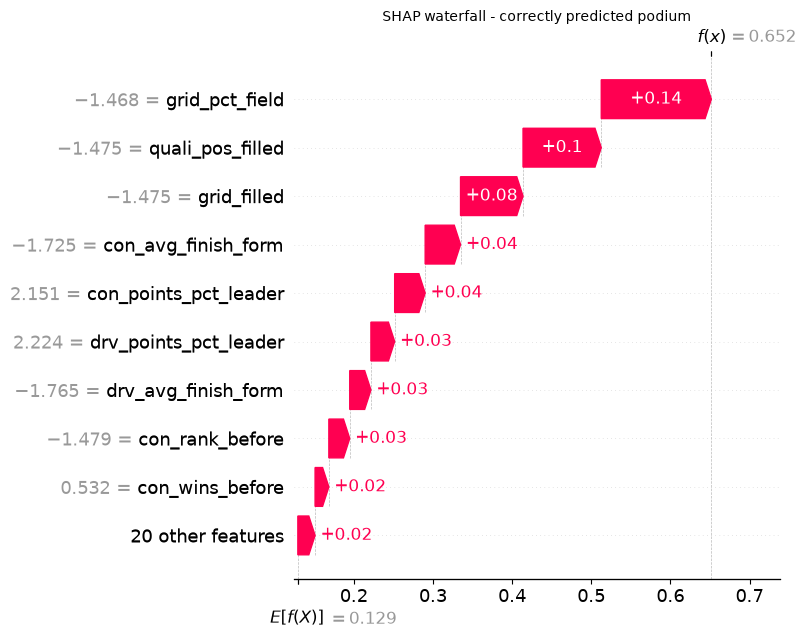

--- missed podium (false negative):  {'year': np.float64(2024.0), 'round': np.float64(10.0), 'raceId': np.float64(1130.0), 'driverId': np.float64(1.0), 'constructorId': np.float64(131.0), 'grid_filled': np.float64(3.0)} | model probability 0.302 (threshold 0.306) | actual podium: 1 | SHAP additivity error 0.0000


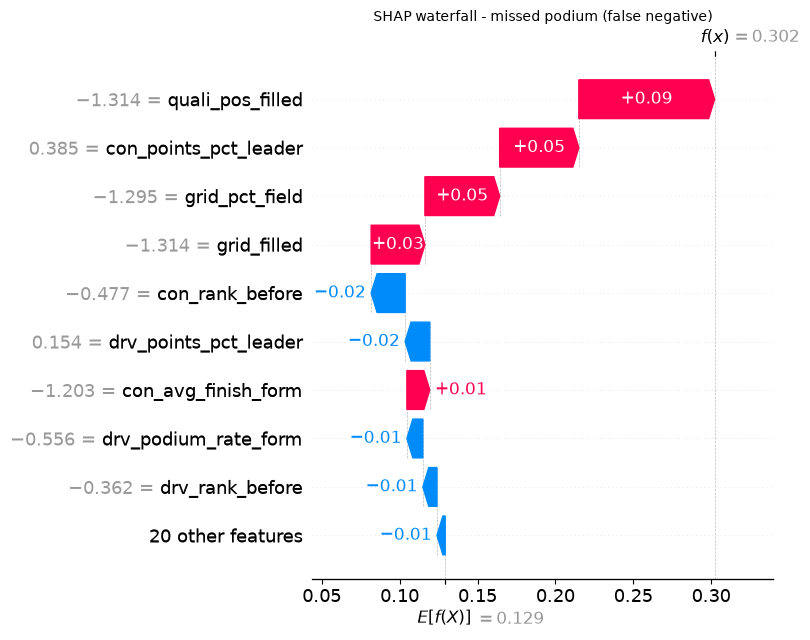

A waterfall reads: start from the average prediction, then each bar pushes the probability up (right) or down (left) FOR THIS ROW ONLY.


In [235]:
# Step 6 - LOCAL explanation 1: SHAP waterfall for single test predictions (one correct podium call + the most informative error, labelled by what it really is)
p_te = f_proba(X_te_x); y_te = v2_test["podium"].values; pred_te = (p_te >= xai_thr).astype(int)
tp_idx = np.where((y_te == 1) & (pred_te == 1))[0]; fn_idx = np.where((y_te == 1) & (pred_te == 0))[0]; fp_idx = np.where((y_te == 0) & (pred_te == 1))[0]
local_cases = {}
if len(tp_idx): local_cases["correctly predicted podium"] = tp_idx[np.argsort(np.abs(p_te[tp_idx] - np.median(p_te[tp_idx])))[0]]          # a typical correct call
if len(fn_idx): local_cases["missed podium (false negative)"] = fn_idx[np.argsort(-p_te[fn_idx])[0]]                                         # the podium the model came closest to catching
elif len(fp_idx): local_cases["false alarm (false positive)"] = fp_idx[np.argsort(-p_te[fp_idx])[0]]                                       # no misses at all -> show the worst false alarm instead
else: print("The model made no false negatives and no false positives on test at this threshold - only one local case is shown.")
assert local_cases, "no local case available"

def shap_row(i):
    v, b = shap_fn(X_te_x[i:i + 1]); return np.ravel(v), b

meta_cols = ["year", "round", "raceId", "driverId", "constructorId", "grid_filled"]
for label, i in local_cases.items():
    vals, bv = shap_row(i)
    print(f"--- {label}: ", dict(v2_test.iloc[i][meta_cols]), "| model probability %.3f (threshold %.3f) | actual podium: %d" % (p_te[i], xai_thr, y_te[i]),
          "| SHAP additivity error %.4f" % abs(vals.sum() + bv - p_te[i]))
    shap.plots.waterfall(shap.Explanation(values=vals, base_values=bv, data=X_te_x[i], feature_names=xai_names), max_display=10, show=False)
    plt.title(f"SHAP waterfall - {label}", fontsize=10); plt.tight_layout(); plt.show()
print("A waterfall reads: start from the average prediction, then each bar pushes the probability up (right) or down (left) FOR THIS ROW ONLY.")

<a id="h257"></a>
### 6.5 Local explanation 2 - LIME
<a id="c234"></a>
*Code cell 236* | [Back to contents](#toc)
LIME perturbs the row, asks the model for predictions around it and fits a small linear surrogate; the bars are the surrogate's weights (conditions on standardised features, e.g. `quali_pos_filled <= -0.83` means "better than about the 20th-percentile qualifying position"). Same two rows as above, so SHAP and LIME can be compared.

**Fidelity check:** LIME is only an approximation, so the cell prints, for each row, the local fit R² and the gap between LIME's local prediction and the model's probability. When the fit is rough, the LIME bars are read as *directions* (which conditions push the probability up or down) and the SHAP waterfall, which adds up exactly to the model probability, gives the sizes.


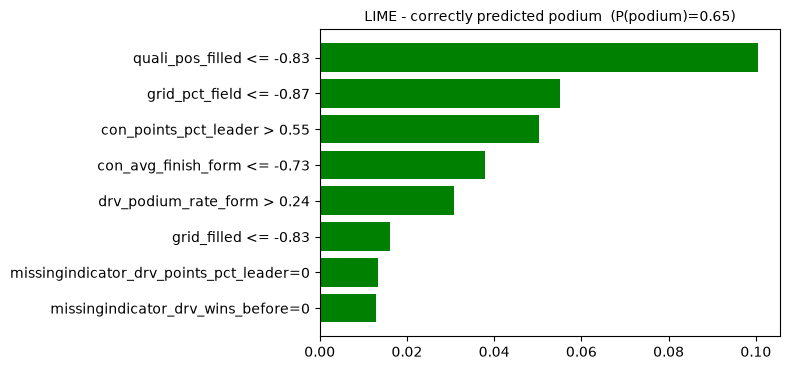

,condition,weight
0,quali_pos_filled <= -0.83,0.101
1,grid_pct_field <= -0.87,0.055
2,con_points_pct_leader > 0.55,0.050
3,con_avg_finish_form <= -0.73,0.038
4,drv_podium_rate_form > 0.24,0.031
5,grid_filled <= -0.83,0.016
6,missingindicator_drv_points_pct_leader=0,0.013
7,missingindicator_drv_wins_before=0,0.013


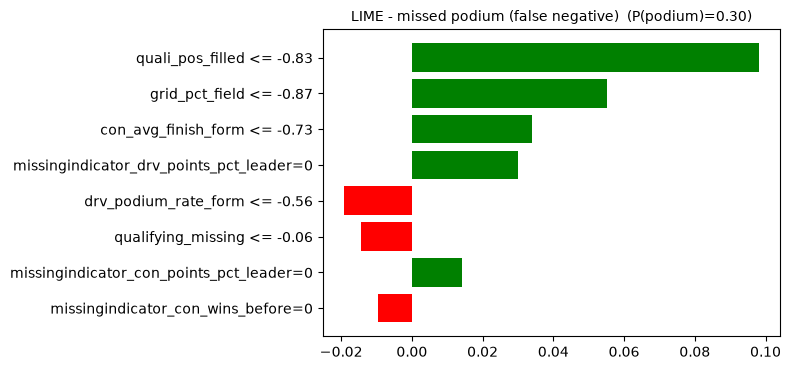

,condition,weight
0,quali_pos_filled <= -0.83,0.098
1,grid_pct_field <= -0.87,0.055
2,con_avg_finish_form <= -0.73,0.034
3,missingindicator_drv_points_pct_leader=0,0.030
4,drv_podium_rate_form <= -0.56,-0.019
5,qualifying_missing <= -0.06,-0.014
6,missingindicator_con_points_pct_leader=0,0.014
7,missingindicator_con_wins_before=0,-0.009


,case,model P(podium),LIME local prediction,local fit R2
0,correctly predicted podium,0.652,0.297,0.612
1,missed podium (false negative),0.302,0.212,0.544


LIME quality check: 'local fit R2' says how well the simple local model imitates the real model around this row (close to 1 = trustworthy, low = treat the weights as rough).
- correctly predicted podium: local fit R2 = 0.61, |model - LIME prediction| = 0.35 -> ROUGH: read the LIME bars as directions only; the SHAP waterfall above (exact by construction) gives the size of each contribution.
- missed podium (false negative): local fit R2 = 0.54, |model - LIME prediction| = 0.09 -> ROUGH: read the LIME bars as directions only; the SHAP waterfall above (exact by construction) gives the size of each contribution.
LIME weights are local and approximate: they can differ from SHAP for the same row (different method, random sampling around the row). Agreement on the TOP features is the sanity check, exact equality is not expected.


In [236]:
# Step 6 - LOCAL explanation 2: LIME for the same rows (a local linear surrogate fitted around each row). One-hot / missing-indicator columns are declared categorical so LIME never invents values like 0.37 for a yes/no column.
cat_idx = [i for i, n in enumerate(xai_names) if n.startswith("missingindicator_") or xai_base[i] in xai_cat]
lime_exp = LimeTabularExplainer(X_tr_x, feature_names=xai_names, class_names=["no podium", "podium"], mode="classification",
                                categorical_features=cat_idx, discretize_continuous=True, random_state=0)
lime_proba = lambda X: np.column_stack([1 - f_proba(X), f_proba(X)])
lime_tables, lime_quality = {}, []
for label, i in local_cases.items():
    ex = lime_exp.explain_instance(X_te_x[i], lime_proba, num_features=8, num_samples=3000)
    lime_tables[label] = pd.DataFrame(ex.as_list(), columns=["condition", "weight"])
    lime_quality.append({"case": label, "model P(podium)": p_te[i], "LIME local prediction": ex.local_pred[0], "local fit R2": ex.score})
    fig = ex.as_pyplot_figure(); fig.set_size_inches(8, 3.8); plt.title(f"LIME - {label}  (P(podium)={p_te[i]:.2f})", fontsize=10); plt.tight_layout(); plt.show()
    display(lime_tables[label].round(3))
display(pd.DataFrame(lime_quality).round(3))
print("LIME quality check: 'local fit R2' says how well the simple local model imitates the real model around this row (close to 1 = trustworthy, low = treat the weights as rough).")
for q in lime_quality:
    gap = abs(q["model P(podium)"] - q["LIME local prediction"])
    faithful = (q["local fit R2"] >= 0.7) and (gap <= 0.10)
    print(f"- {q['case']}: local fit R2 = {q['local fit R2']:.2f}, |model - LIME prediction| = {gap:.2f} -> " +
          ("faithful: the LIME weights can be read as local effects." if faithful else
           "ROUGH: read the LIME bars as directions only; the SHAP waterfall above (exact by construction) gives the size of each contribution."))
print("LIME weights are local and approximate: they can differ from SHAP for the same row (different method, random sampling around the row). Agreement on the TOP features is the sanity check, exact equality is not expected.")

<a id="h258"></a>
### 6.6 Do the explanations agree? + the non-causal statement
<a id="c235"></a>
*Code cell 237* | [Back to contents](#toc)
Rank correlation between permutation importance and mean |SHAP|, the top LIME features for each local case, and the explicit **non-causal statement** required by the milestone. Agreement on the top (start-position) features is the sanity check; exact agreement is not expected because the methods answer slightly different questions.


In [237]:
# Step 6 - do the three explanation methods agree? (rank correlation of global importances) + the statement that must accompany every explanation
cmp_imp = pd.DataFrame({"permutation": perm_df.set_index("feature")["importance"], "mean|SHAP|": shap_imp}).fillna(0)
rho = cmp_imp.corr(method="spearman").loc["permutation", "mean|SHAP|"]
display(cmp_imp.sort_values("mean|SHAP|", ascending=False).head(10).round(4))
print(f"Spearman rank correlation permutation vs SHAP (all features): {rho:.2f}")
for label in lime_tables:
    top_lime = [c.split("<")[0].split(">")[0].strip().split(" ")[-1] for c in lime_tables[label]["condition"].head(3)]
    print(f"Top LIME features for '{label}':", top_lime)
print("\nNON-CAUSAL STATEMENT: permutation importance, SHAP and LIME show which inputs the trained model relies on to produce its predictions. They do NOT show that a feature")
print("causes a podium (e.g. a good grid slot and a podium both follow from a fast car). Features are also correlated, so credit is shared between them, and the explanations hold for this model on these seasons.")

,permutation,mean|SHAP|
quali_pos_filled,0.0600,0.0434
grid_pct_field,0.0477,0.0350
grid_filled,0.0321,0.0208
con_points_pct_leader,0.0005,0.0203
con_avg_finish_form,0.0121,0.0200
drv_podium_rate_form,0.0084,0.0142
con_rank_before,0.0047,0.0085
drv_points_pct_leader,0.0049,0.0076
drv_rank_before,0.0060,0.0061
drv_avg_finish_form,0.0025,0.0058


Spearman rank correlation permutation vs SHAP (all features): 0.85
Top LIME features for 'correctly predicted podium': ['quali_pos_filled', 'grid_pct_field', 'con_points_pct_leader']
Top LIME features for 'missed podium (false negative)': ['quali_pos_filled', 'grid_pct_field', 'con_avg_finish_form']

NON-CAUSAL STATEMENT: permutation importance, SHAP and LIME show which inputs the trained model relies on to produce its predictions. They do NOT show that a feature
causes a podium (e.g. a good grid slot and a podium both follow from a fast car). Features are also correlated, so credit is shared between them, and the explanations hold for this model on these seasons.


<a id="h259"></a>
# Part 7 — Inference function (deliverable 7)

<a id="h260"></a>
### 7.1 `predict_podium(record)` - complete and partially-missing records
<a id="c236"></a>
*Code cell 238* | [Back to contents](#toc)
A single function that takes a dictionary of **pre-race** features and returns the podium probability, the decision at the validation-chosen threshold, which fields were unknown and any warnings. It uses the same frozen predictor (`FINAL`) and threshold as the comparison table and the explanations.
* accepts **any subset** of features; numeric strings such as `"3"` are accepted; fields defined from the grid / qualifying slot are rebuilt consistently,
* **refuses post-race fields** (`positionOrder`, `points`, …) - leakage guard,
* warns about out-of-range values, unknown fields, no grid/qualifying information, and many unknown fields at once.

**How unknown fields are handled (`unknown=`).** In the training table a missing standings or form value is not random: those rows (debuts, drivers or teams without a standings row yet) almost never finished on the podium - the cell prints this evidence. The missing-indicator columns therefore teach the model that *"missing" means "unlikely podium"*. For a real query in which a value is simply not known, that reading is too pessimistic, so the function offers two modes:
* `unknown="typical"` (**default**): an unknown field is filled with its **training median** and its missing-indicator stays 0, i.e. *"assume an average driver / team on what we do not know"*;
* `unknown="as_training"`: the field is left missing exactly as in training, so the model applies the training meaning of a gap.

Neither mode can recover information that was not supplied. The model relies on team strength (standings, form) as well as on the start slot, so a P3 start of an *average* team is a much weaker podium candidate than the same start by a top team: a partial record therefore gives a lower and less certain probability than the complete one, and the function says so in its warnings.

The demo scores (1) a complete record of a real test row, (2) the same driver-race with qualifying, standings and form unknown, in both modes, (3) an empty record in both modes, and (4) a record with a forbidden field. It also prints the training-data evidence for the "missing = newcomer" reading. A partially-missing record gives a *less informative* answer, not a crash.


In [238]:
# Deliverable 7: INFERENCE FUNCTION - raw pre-race record in, podium probability out; works with complete and partially-missing records.
# It uses the SAME frozen predictor (FINAL) and threshold as the comparison table and the explanations above - nothing is re-trained here.
infer_pipe, INFER_THRESHOLD = FINAL, FINAL_THRESHOLD
KEY_FEATURES = ["grid_filled", "quali_pos_filled"]                                                                              # without both, the answer is unreliable
RANGES = {"grid_filled": (1, 30), "quali_pos_filled": (1, 30), "grid_pct_field": (0, 1.2), "drv_points_pct_leader": (0, 1), "con_points_pct_leader": (0, 1),
          "drv_podium_rate_form": (0, 1), "con_podium_rate_form": (0, 1)}
# the values the TRAINING pipeline itself uses to fill gaps (median of each numeric feature on the training rows)
TRAIN_MEDIANS = dict(zip(FINAL.num, FINAL.pre.named_transformers_["num"].named_steps["imp"].statistics_))

def _derive_from_grid(rec, field_size):
    """Rebuild the features that are DEFINED from the grid slot / qualifying slot, exactly as the training pipeline defines them, so a partial record is never self-contradictory.
    A derived field is only filled when the caller did not supply it."""
    def put(k, v):
        if k in rec and (rec[k] is None or (isinstance(rec[k], float) and np.isnan(rec[k]))): rec[k] = v
    g, q = rec.get("grid_filled"), rec.get("quali_pos_filled")
    have_g = g is not None and not np.isnan(g); have_q = q is not None and not np.isnan(q)
    if have_g:
        put("grid_missing", 0); put("front_row", int(g <= 2)); put("grid_pct_field", g / field_size)
        if not have_q:                                                    # no qualifying position given -> same Option-A fallback as training: use the grid, flag it
            rec["quali_pos_filled"] = g; put("qualifying_missing", 1); put("grid_penalty", 0)
        else:
            put("qualifying_missing", 0); put("grid_penalty", max(g - q, 0))
    return rec

def predict_podium(record: dict, model=FINAL, threshold=FINAL_THRESHOLD, field_size: int = 20, unknown: str = "typical"):
    """record: {feature_name: value}. Any subset of the model's features is accepted. Only information available AFTER qualifying and BEFORE the race may be supplied.
    unknown="typical" (default): a field the caller does not know is filled with its training median and its missing-indicator stays 0 ("assume an average value").
    unknown="as_training": the field is left missing exactly as in training, where rows with a missing standings / form value almost never finished
                           on the podium, so the model lowers the probability.
    `field_size` (cars on the grid) is only used to rebuild grid-derived fields."""
    if unknown not in ("typical", "as_training"):
        raise ValueError('unknown must be "typical" or "as_training"')
    known = set(model.num + model.cat)
    forbidden = sorted(set(record) & V2_FORBIDDEN)
    if forbidden: raise ValueError(f"Post-race fields are not allowed as inputs (leakage): {forbidden}")
    warns = [f"unknown field ignored: {u}" for u in sorted(set(record) - known)]
    rec = {}
    for c in model.num:
        v = record.get(c)
        try: rec[c] = np.nan if v is None else float(v)
        except (TypeError, ValueError): rec[c] = np.nan; warns.append(f"{c}={v!r} is not numeric: treated as unknown")
    rec = _derive_from_grid(rec, field_size)
    for c in model.cat: rec[c] = record.get(c, np.nan)                       # categorical identifiers are passed through; unseen values are handled by the encoder
    missing = [c for c in model.num + model.cat if pd.isna(rec[c])]          # what is still unknown after the grid-derived fields were rebuilt
    for c in model.num:                                                     # range checks on the values the caller actually supplied
        if c in RANGES and pd.notna(rec[c]) and not (RANGES[c][0] <= rec[c] <= RANGES[c][1]):
            warns.append(f"{c}={rec[c]} outside the usual range [{RANGES[c][0]}, {RANGES[c][1]}]")
    if unknown == "typical":
        for c in model.num:
            if pd.isna(rec[c]) and pd.notna(TRAIN_MEDIANS.get(c, np.nan)): rec[c] = float(TRAIN_MEDIANS[c])
    if all(k in missing for k in KEY_FEATURES): warns.append("no grid / qualifying information: the probability is NOT reliable (the start position is the strongest input)")
    if len(missing) > 8:
        how = "filled with typical (training-median) values" if unknown == "typical" else "left missing, which the model reads as 'no history'"
        warns.append(f"{len(missing)} fields unknown and {how}: treat the probability as indicative only")
    row = pd.DataFrame([rec])[model.num + model.cat]
    p = float(model.predict_proba_df(row)[0])
    return {"podium_probability": round(p, 4), "predicted_podium": bool(p >= threshold), "threshold": round(float(threshold), 4),
            "unknown_handling": unknown, "n_missing_features": len(missing), "missing_features": missing, "warnings": warns}

# --- evidence for the "missing = newcomer" reading: podium rate of TRAINING rows whose standings / form are missing ---
ev_cols = ["drv_points_pct_leader", "drv_podium_rate_form", "con_points_pct_leader", "con_podium_rate_form"]
ev = pd.DataFrame([{"feature": c, "train_rows_missing": int(v2_fit_df[c].isna().sum()),
                    "podium_rate_when_missing_%": 100 * v2_fit_df.loc[v2_fit_df[c].isna(), "podium"].mean(),
                    "median_starts_before_when_missing": v2_fit_df.loc[v2_fit_df[c].isna(), "drv_starts_before"].median()} for c in ev_cols])
print(f"Training rows: {len(v2_fit_df):,} | overall podium rate {100 * v2_fit_df['podium'].mean():.1f}%")
display(ev.round(2))

# --- demo 1: a COMPLETE record (a real latest-season test row); the outcome is shown only to compare, it is not an input
demo = v2_test[(v2_test["year"] == v2_test["year"].max()) & (v2_test["grid_filled"] == 3)].iloc[0]       # a P3 starter of the latest season
complete = {c: (None if pd.isna(demo[c]) else (float(demo[c]) if c in FINAL.num else demo[c])) for c in FINAL.num + FINAL.cat}
print("COMPLETE record :", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in list(complete.items())[:8]}, "...")
print("  ->", predict_podium(complete), "| actual podium:", int(demo["podium"]))
_via_batch = float(FINAL.predict_proba_df(v2_test.loc[[demo.name]])[0]); _via_fn = predict_podium(complete)["podium_probability"]
print(f"  consistency: batch path {_via_batch:.4f} vs predict_podium {_via_fn:.4f}")

# --- demo 2: the SAME driver-race with qualifying, standings and form UNKNOWN (only grid + constructor form known)
partial = {k: v for k, v in complete.items() if k in ("grid_filled", "con_podium_rate_form")}
partial["quali_pos_filled"] = "3"                                                      # a numeric STRING is accepted too
print("\nPARTIAL record  :", partial)
print("  -> default (unknown='typical'):", predict_podium(partial))

# --- side-by-side: complete vs partial vs empty, in both modes for unknown fields
cases = [("complete record", complete, "typical"),
         ("partial record, unknown = typical (default)", partial, "typical"),
         ("partial record, unknown = as_training", partial, "as_training"),
         ("empty record, unknown = typical", {}, "typical"),
         ("empty record, unknown = as_training", {}, "as_training")]
cmp_inf = pd.DataFrame([{"record": lbl, **{k: v for k, v in predict_podium(r, unknown=m).items() if k in ("podium_probability", "predicted_podium", "n_missing_features")}}
                        for lbl, r, m in cases])
display(cmp_inf)
_p = dict(zip(cmp_inf["record"], cmp_inf["podium_probability"]))
print(f"Reading: the complete record gives {_p['complete record']:.3f}. With only grid, qualifying and constructor form known, the default mode treats the",
      f"rest as an average driver / team and gives {_p['partial record, unknown = typical (default)']:.3f}: the model relies on team strength as well as the start slot.",
      f"Leaving the same fields missing gives {_p['partial record, unknown = as_training']:.3f}, because in training a missing standings / form value almost never came with a podium.",
      "The empty record has no grid information, so it is flagged as unreliable in both modes. More known inputs -> a better-founded probability.")

# --- demo 3: an invalid call
try: predict_podium({"grid_filled": 3, "positionOrder": 1})
except ValueError as e: print("\nLEAKAGE guard   :", e)


Training rows: 6,824 | overall podium rate 14.1%


,feature,train_rows_missing,podium_rate_when_missing_%,median_starts_before_when_missing
0,drv_points_pct_leader,79,0.00,19.0
1,drv_podium_rate_form,75,2.67,0.0
2,con_points_pct_leader,24,0.00,20.5
3,con_podium_rate_form,36,5.56,37.0


COMPLETE record : {'grid_filled': 3.0, 'grid_pct_field': 0.15, 'grid_missing': 0.0, 'front_row': 0.0, 'quali_pos_filled': 3.0, 'qualifying_missing': 0.0, 'grid_penalty': 0.0, 'drv_points_pct_leader': 0.0} ...
  -> {'podium_probability': 0.5469, 'predicted_podium': True, 'threshold': 0.3057, 'unknown_handling': 'typical', 'n_missing_features': 0, 'missing_features': [], 'warnings': []} | actual podium: 0
  consistency: batch path 0.5469 vs predict_podium 0.5469

PARTIAL record  : {'grid_filled': 3.0, 'con_podium_rate_form': 0.2, 'quali_pos_filled': '3'}
  -> default (unknown='typical'): {'podium_probability': 0.1058, 'predicted_podium': False, 'threshold': 0.3057, 'unknown_handling': 'typical', 'n_missing_features': 10, 'missing_features': ['drv_points_pct_leader', 'drv_rank_before', 'drv_wins_before', 'con_points_pct_leader', 'con_rank_before', 'con_wins_before', 'drv_podium_rate_form', 'drv_avg_finish_form', 'drv_starts_before', 'con_avg_finish_form'], 'warnings': ['10 fields unknown 

,record,podium_probability,predicted_podium,n_missing_features
0,complete record,0.5469,True,0
1,"partial record, unknown = typical (default)",0.1058,False,10
2,"partial record, unknown = as_training",0.0631,False,10
3,"empty record, unknown = typical",0.0149,False,18
4,"empty record, unknown = as_training",0.0088,False,18


Reading: the complete record gives 0.547. With only grid, qualifying and constructor form known, the default mode treats the rest as an average driver / team and gives 0.106: the model relies on team strength as well as the start slot. Leaving the same fields missing gives 0.063, because in training a missing standings / form value almost never came with a podium. The empty record has no grid information, so it is flagged as unreliable in both modes. More known inputs -> a better-founded probability.

LEAKAGE guard   : Post-race fields are not allowed as inputs (leakage): ['positionOrder']


---
<a id="h901"></a>
# Part 8 — Report notes, deliverables and limitations

<a id="h261"></a>
## Write-up checklist (what to say in the report)

**Step 3 - justification.** Cite: the univariate/MI/correlation table (B.5), the optional-group trial and the training-window trial (B.7), the no-look-ahead test (B.4), the coverage plot (3.4b), and the split reasoning (3.5b). State the scope rules (DNQ/DNPQ removed, Indy 500 1950–60 removed, sprint results unused, constructor renames reset history).

**Step 4 - modelling.** Same table and same features for LR / RF / gradient boosting / shallow MLP; ROC-AUC, PR-AUC and F1 on train, validation and test; thresholds and hyper-parameters chosen on rolling-origin folds that stop at 2021; the grid-only baseline is the bar, and the paired bootstrap says whether it was cleared. Be explicit about which differences between models are **not** significant.

**Step 5 - ablation.** Quote the per-group drops with their intervals, the "group alone" column and the combined removals; explain the redundancy caveat.

**Deviations from the brief to declare:** none in Part B (course split used). If Part A is kept in the report, state that it used train ≤ 2018 / validation 2019–21 and no standings.

**Limitations to state:** only ~two validation seasons; modern-era test set of three seasons (≈ 1,300 rows); the F1 at a validation-selected threshold is noisy; results are for pre-race information only.

---
<a id="h262"></a>
## Deliverables and checklist - where everything is

| Milestone item | Where | Status |
|---|---|---|
| 1. Run-all notebook (audit -> cleaning -> DE answers -> features -> models -> experiments -> XAI -> inference) | this notebook (contents table at the top) | Done runs top to bottom; sections numbered |
| 2. EDA with plots | Part 1 §1 (raw), §5 (after cleaning) | Done |
| 3. Unique driver–race table, documented duplicate handling, leakage-safe features | Part 1 §3; Part B B.2–B.4 (incl. the no-look-ahead test) | Done |
| 4. Model comparison table, all five metrics, validation + test, primary/secondary metric justified | B.9 and B.17 | Done |
| 5. Feature-group ablation + ≥ 2 preprocessing-order experiments | B.13 (ablation); B.16 (preprocessing experiments E0–E4: imputation, order, scaling, qualifying fallback, fit scope) | Done |
| 6. Global (permutation, SHAP) and local (LIME, local SHAP) explanations, plotted and interpreted | Part 6 (6.1–6.6) | Done |
| 7. Inference function, complete + partially-missing record | Part 7 (7.1) | Done |
| 8. Analytical report (PDF): answers to the 3 DE questions with figures, selected features and why each is valid pre-race, limitations | separate PDF; outline in the write-up checklist above | Separate deliverable |
| Submission: public Kaggle notebook link, GitHub repo link, PDF report | outside the notebook | Submitted separately (deadline 18 Oct 2026, 11:59 PM) |

**Checklist items:** EDA Done · cleaning (sentinels, typing, one row per (raceId, driverId)) Done · data analysis & plots Done · all 3 DE questions answered in markdown Done · feature selection with evidence and plots Done · leakage-safe form feature (past races only, proven by the no-look-ahead test) Done · preprocessing effect + order experiments Done · proper split Done · models (how they work B.7b, limitations, train/validation/test performance, plots, ablation) Done · XAI (global, local with LIME and SHAP, plotted, explained) Done.

**Evaluation tips from the brief:** every team member must be able to explain each step; motivate each step with EDA evidence or a before/after row (B.7, B.8, B.16 and the Part A -> Part B comparison B.12 are those rows).

<a id="h263"></a>
## Known limitations and design decisions

| Topic | Decision / limitation |
|---|---|
| Duplicate-row rule uses the race outcome | The 176 duplicated driver-race rows are all from 1950-1978; none lies in the training window selected in B.7, the validation or the test seasons, so no reported model number is affected. The rule is kept and documented (Part 1, §3). |
| Qualifying coverage drift | `qualifying.csv` starts in 1994 (Step 1.8e). Option A: a missing qualifying position is filled from a valid grid slot only, both missing stays missing, originals are preserved, and `qualifying_missing` flags substituted rows. The training window is chosen empirically in B.7. |
| Non-starters | DNQ/DNPQ and confirmed non-starters (withdrew / did not start, no grid, 0 laps) are removed; `grid = 0` alone is not treated as a non-start (pit-lane starters keep their row). |
| One frozen predictor | ONE predictor (`FINAL`: preprocessing + same seeds + validation threshold) is used for the comparison table, SHAP / LIME / permutation importance and inference; the notebook prints the difference to the comparison-table probabilities. |
| Unknown inputs at inference | Training rows with missing standings / form almost never finished on the podium, so a gap lowers the probability. `predict_podium` fills fields the caller does not know with typical training values by default and shows the training-style reading next to it; with key inputs unknown the probability is indicative only (Part 7). |
| LIME fidelity | LIME is a local linear approximation; its local fit and prediction gap are printed for every explained row, and the SHAP waterfall is the exact local view. |
| Small evaluation blocks | About two validation seasons and three test seasons (~1,300 rows): differences between models that lie inside the race-level bootstrap intervals (B.10) are not significant. |
| Era sensitivity | Rules, reliability and car dominance change by era (Part 1, Step 1.9d; B.11 per-season results); the models describe the modern era they are trained and tested on. |
| Not claimed | Explanations are associative, not causal. The report PDF, GitHub link and Kaggle link are delivered outside the notebook. |
